![](img/banner.png)
%%HTML
<script src="require.js"></script>

# Model Selection

**Can I trust you?**


**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

I should mention that the original material of this course was from [Open Machine Learning Course](https://ml-course.github.io/), by [Joaquin Vanschoren](https://github.com/joaquinvanschoren) and others.

In [5]:
# Auto-setup when running on Google Colab
import os
if 'google.colab' in str(get_ipython()) and not os.path.exists('/content/machine-learning'):
    !git clone -q https://github.com/fum-cs/machine-learning.git /content/machine-learning
    !pip --quiet install -r /content/machine-learning/requirements_colab.txt
    %cd machine-learning/notebooks

# Global imports and settings
%matplotlib inline
from preamble import *
interactive = True # Set to True for interactive plots
if interactive:
    fig_scale = 0.9
    plt.rcParams.update(print_config)
else:
    fig_scale = 1.25

## Evaluation
- To know whether we can _trust_ our method or system, we need to evaluate it.
- Model selection: choose between different models in a data-driven way.
    - If you cannot measure it, you cannot improve it.
- Convince others that your work is meaningful
    - Peers, leadership, clients, yourself(!)
- When possible, try to _interpret_ what your model has learned 
    - The signal your model found may just be an artifact of your biased data
    - See 'Why Should I Trust You?' by Marco Ribeiro et al.
    
<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/eval_trust.png" alt="ml" style="width: 50%;"/>

### Designing Machine Learning systems

* Just running your favourite algorithm is usually not a great way to start
* Consider the problem: How to measure success? Are there costs involved?
    - Do you want to understand phenomena or do black box modelling?
* Analyze your model's mistakes. Don't just finetune endlessly.
    - Build early prototypes. Should you collect more, or additional data?
    - Should the task be reformulated?
* Overly complex machine learning systems are hard to maintain
    - See 'Machine Learning: The High Interest Credit Card of Technical Debt'   

<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/eval_debt2.png" alt="ml" style="width: 75%;"/>

### Real world evaluations
* Evaluate predictions, but also how outcomes improve _because of them_
* Beware of feedback loops: predictions can influence future input data
    * Medical recommendations, spam filtering, trading algorithms,...
* Evaluate algorithms _in the wild_.
    * A/B testing: split users in groups, test different models in parallel
    * Bandit testing: gradually direct more users to the winning system

<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/eval_abbandit.png" alt="ml" style="width: 50%"/>

## Performance estimation techniques
* Always evaluate models _as if they are predicting future data_
* We do not have access to future data, so we pretend that some data is hidden
* Simplest way: the _holdout_ (simple train-test split)
    - _Randomly_ split data (and corresponding labels) into training and test set (e.g. 75%-25%)
    - Train (fit) a model on the training data, score on the test data

In [2]:
from sklearn.model_selection import (TimeSeriesSplit, KFold, ShuffleSplit, train_test_split,
                                     StratifiedKFold, GroupShuffleSplit,
                                     GroupKFold, StratifiedShuffleSplit)
from matplotlib.patches import Patch
np.random.seed(1338)
cmap_data = plt.cm.brg
cmap_group = plt.cm.Paired
cmap_cv = plt.cm.coolwarm
n_splits = 4

# Generate the class/group data
n_points = 100
X = np.random.randn(100, 10)

percentiles_classes = [.1, .3, .6]
y = np.hstack([[ii] * int(100 * perc)
               for ii, perc in enumerate(percentiles_classes)])

# Evenly spaced groups repeated once
rng = np.random.RandomState(42)
group_prior = rng.dirichlet([2]*10)
rng.multinomial(100, group_prior)
groups = np.repeat(np.arange(10), rng.multinomial(100, group_prior))

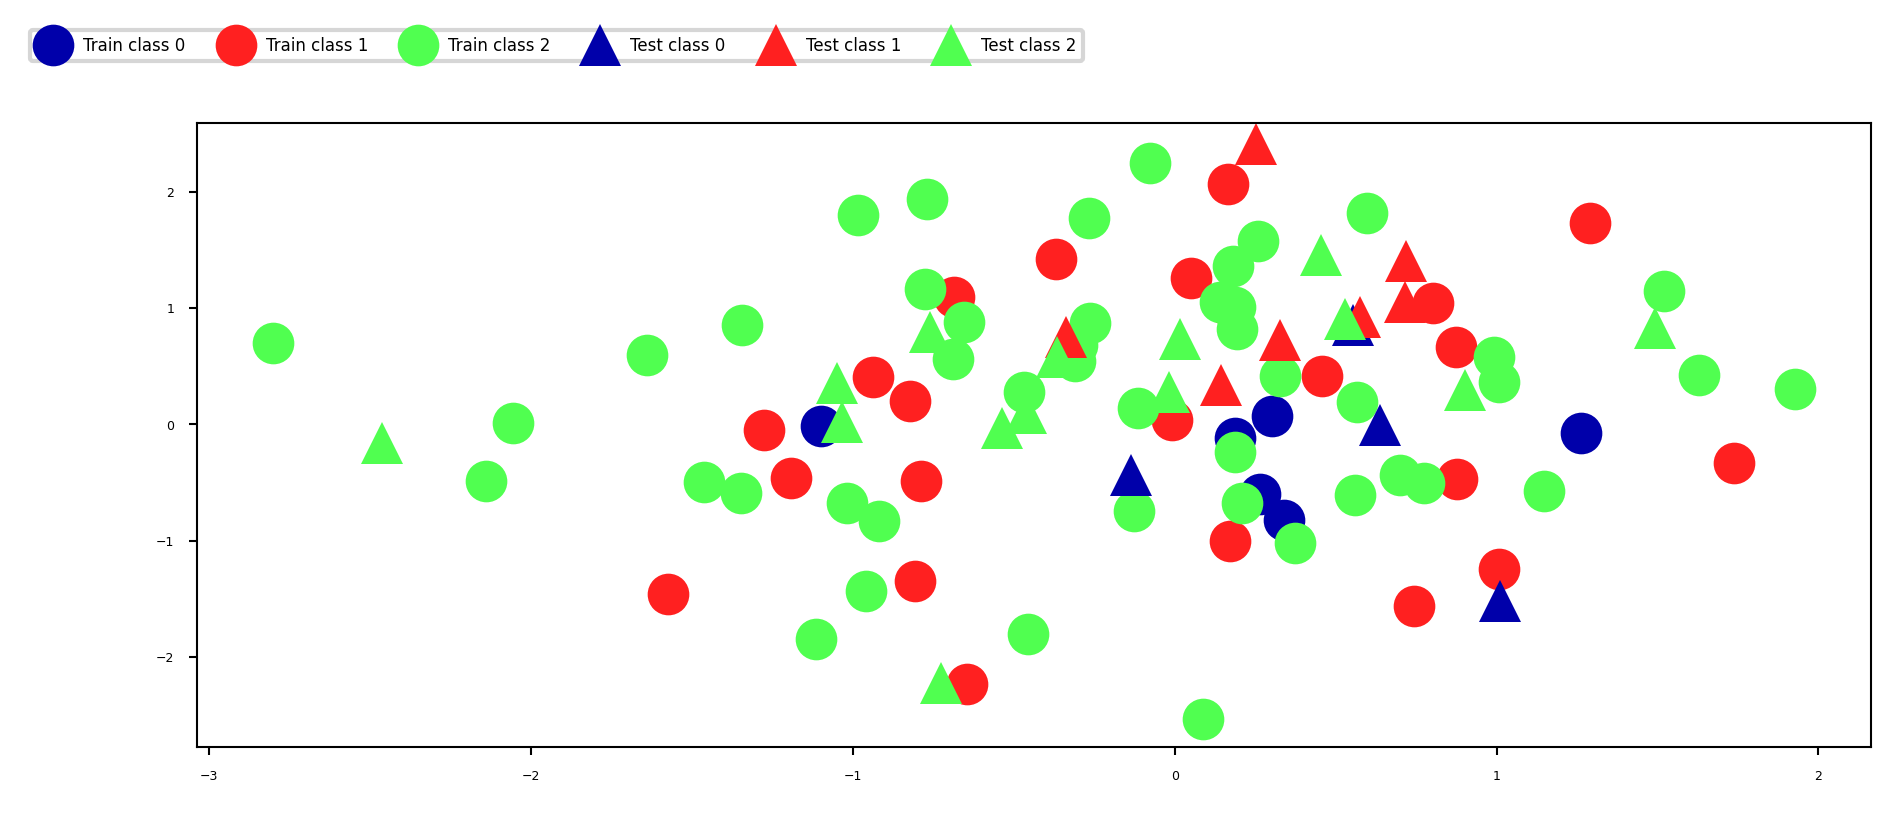

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
fig, ax = plt.subplots(figsize=(8*fig_scale, 3*fig_scale))
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train,
                         markers='o', ax=ax)
mglearn.discrete_scatter(X_test[:, 0], X_test[:, 1], y_test,
                         markers='^', ax=ax)
ax.legend(["Train class 0", "Train class 1", "Train class 2", "Test class 0",
                "Test class 1", "Test class 2"], ncol=6,  loc=(-0.1, 1.1));

### K-fold Cross-validation
- Each random split can yield very different models (and scores)
    - e.g. all easy (of hard) examples could end up in the test set
- Split data into _k_ equal-sized parts, called _folds_
    - Create _k_ splits, each time using a different fold as the test set
- Compute _k_ evaluation scores, aggregate afterwards (e.g. take the mean)
- Examine the score variance to see how _sensitive_ (unstable) models are
- Large _k_ gives better estimates (more training data), but is expensive

In [4]:
def plot_cv_indices(cv, X, y, group, ax, lw=2, show_groups=False, s=700, legend=True):
    """Create a sample plot for indices of a cross-validation object."""
    n_splits = cv.get_n_splits(X, y, group)

    # Generate the training/testing visualizations for each CV split
    for ii, (tr, tt) in enumerate(cv.split(X=X, y=y, groups=group)):
        # Fill in indices with the training/test groups
        indices = np.array([np.nan] * len(X))
        indices[tt] = 1
        indices[tr] = 0

        # Visualize the results
        ax.scatter([n_splits - ii - 1] * len(indices), range(len(indices)),
                   c=indices, marker='_', lw=lw, cmap=cmap_cv,
                   vmin=-.2, vmax=1.2, s=s)

    # Plot the data classes and groups at the end
    ax.scatter([-1] * len(X), range(len(X)), 
               c=y, marker='_', lw=lw, cmap=cmap_data, s=s)
    yticklabels = ['class'] + list(range(1, n_splits + 1))
    
    if show_groups:
        ax.scatter([-2] * len(X), range(len(X)), 
                   c=group, marker='_', lw=lw, cmap=cmap_group, s=s)
        yticklabels.insert(0, 'group')

    # Formatting
    ax.set(xticks=np.arange(-1 - show_groups, n_splits), xticklabels=yticklabels,
            ylabel='Sample index', xlabel="CV iteration",
            xlim=[-1.5 - show_groups, n_splits+.2], ylim=[-6, 100])
    ax.set_title('{}'.format(type(cv).__name__), fontsize=15)
    if legend:
        ax.legend([Patch(color=cmap_cv(.8)), Patch(color=cmap_cv(.2))],
                  ['Testing set', 'Training set'], loc=(1.02, .8))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.set_yticks(())
    return ax

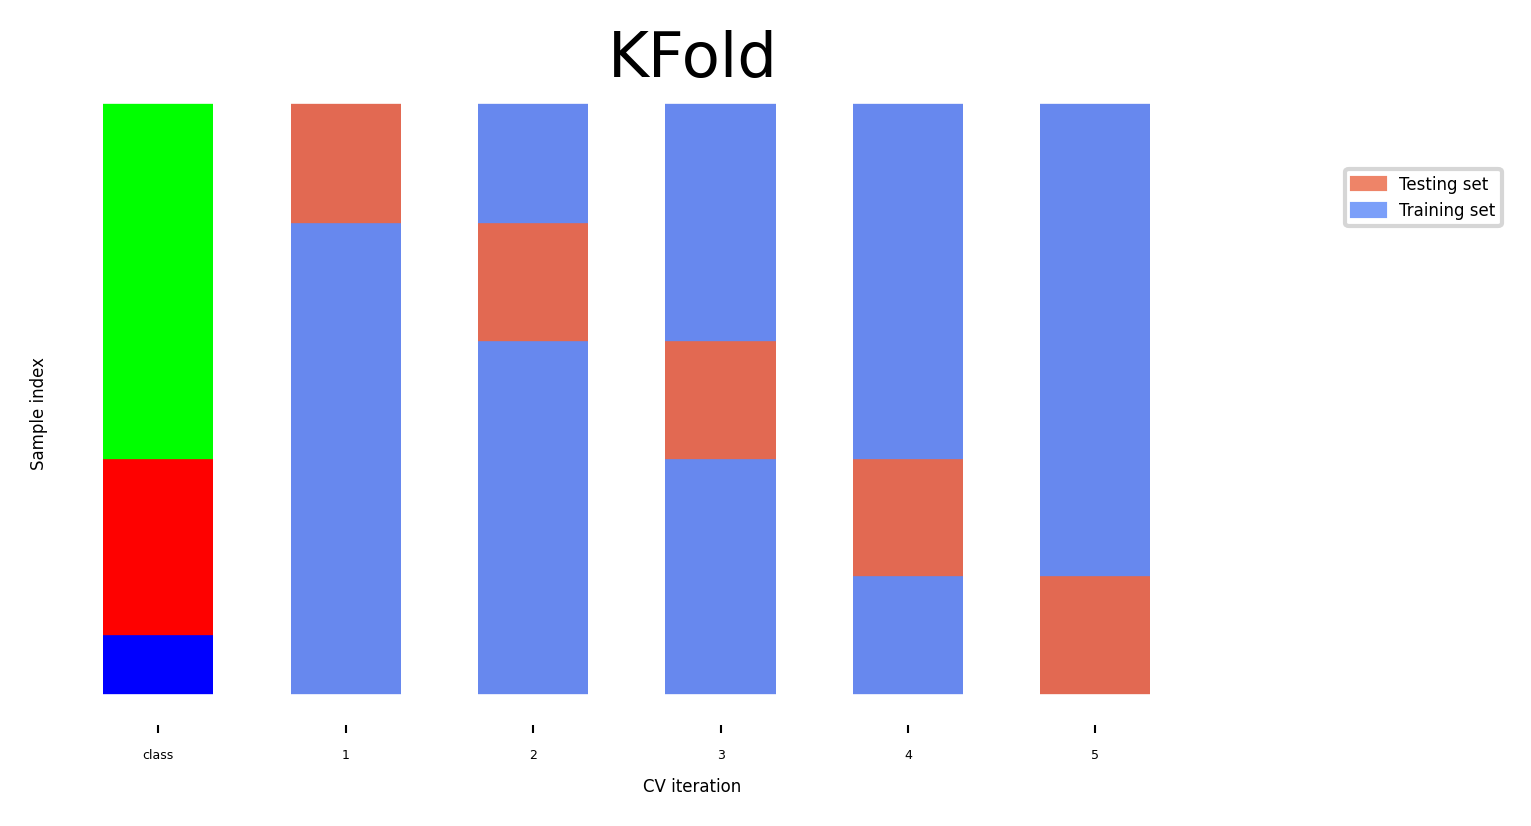

In [5]:
fig, ax = plt.subplots(figsize=(6*fig_scale, 3*fig_scale))
cv = KFold(5)
plot_cv_indices(cv, X, y, groups, ax, s=700);

Can you explain this result?

``` python
kfold = KFold(n_splits=3)
cross_val_score(logistic_regression, iris.data, iris.target, cv=kfold)
```

In [6]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

iris = load_iris()
logreg = LogisticRegression()
kfold = KFold(n_splits=3)
print("Cross-validation scores KFold(n_splits=3):\n{}".format(
      cross_val_score(logreg, iris.data, iris.target, cv=kfold)))

Cross-validation scores KFold(n_splits=3):
[0. 0. 0.]


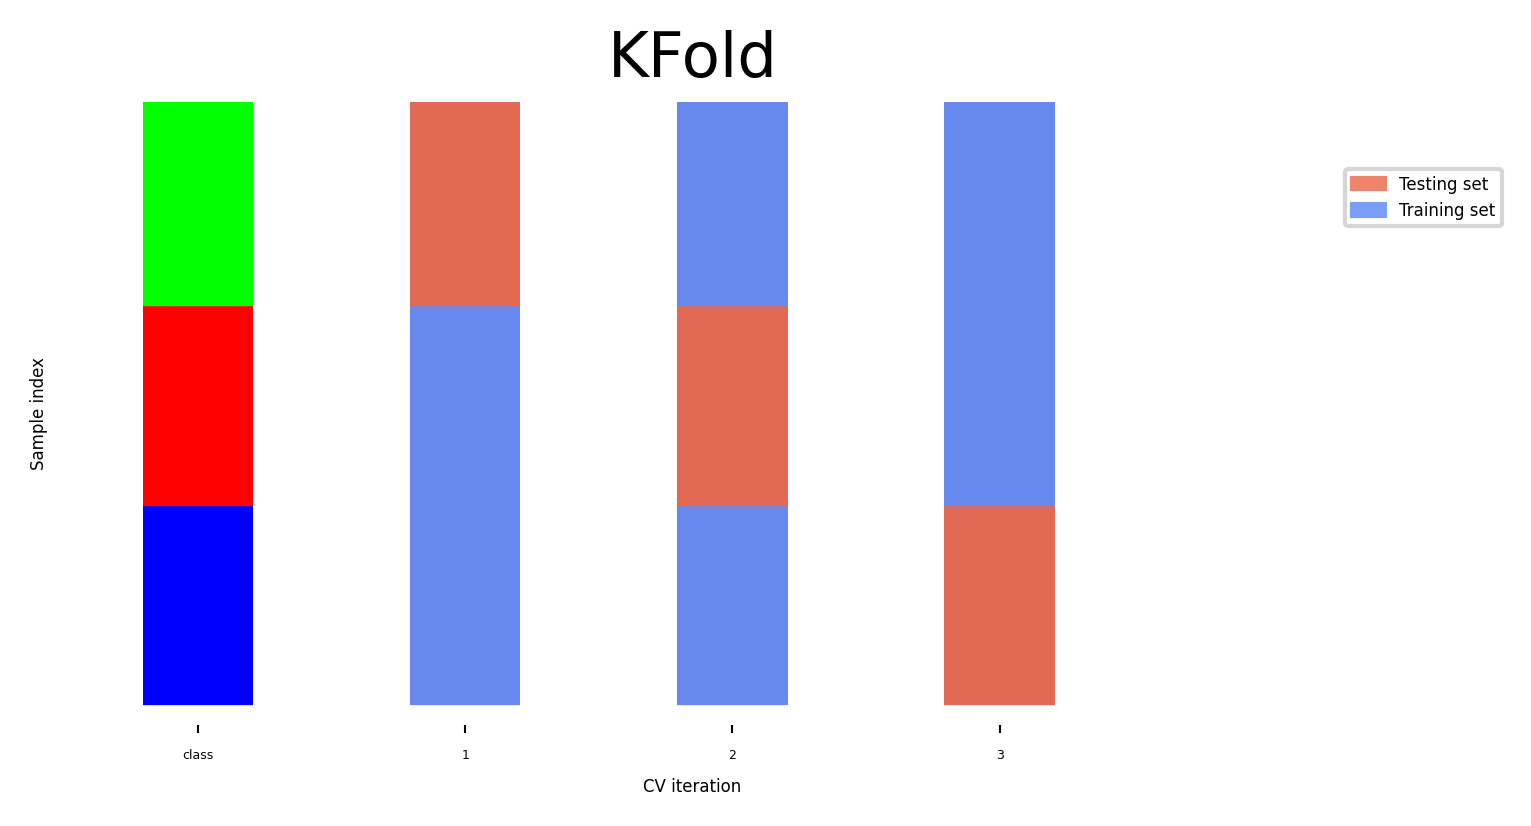

In [7]:
fig, ax = plt.subplots(figsize=(6*fig_scale, 3*fig_scale))
plot_cv_indices(kfold, iris.data, iris.target, iris.target, ax, s=700)
ax.set_ylim((-6, 150));

#### Stratified K-Fold cross-validation

- If the data is unbalanced, some classes have only few samples
- Likely that some classes are not present in the test set 
- Stratification: _proportions_ between classes are conserved in each fold
    - Order examples per class
    - Separate the samples of each class in _k_ sets (strata)
    - Combine corresponding strata into folds

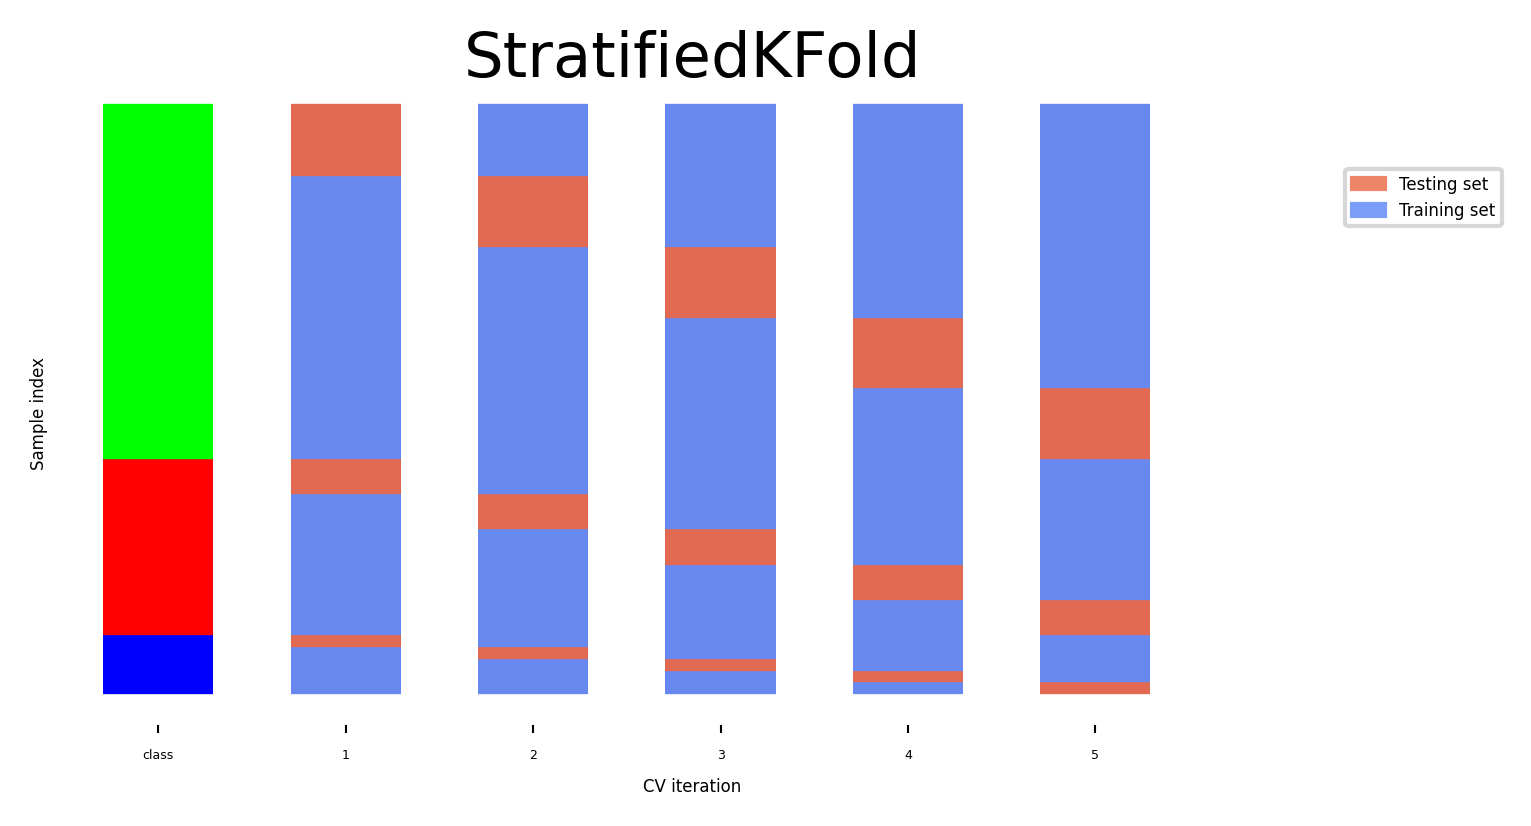

In [8]:
fig, ax = plt.subplots(figsize=(6*fig_scale, 3*fig_scale))
cv = StratifiedKFold(5)
plot_cv_indices(cv, X, y, groups, ax, s=700)
ax.set_ylim((-6, 100));


### Why do we need Stratified K-Fold?
Imagine a dataset containing 100 samples:

- 90 negative samples (90%)
- 10 positive samples (10%)

We want to perform 5-fold cross-validation.

Ordinary K-Fold divides the data into five groups without considering their class distribution.

Stratified K-Fold tries to preserve the original class proportions in every fold.

Let's compare the two approaches.


KFold (no shuffle)   positives per test fold: [10, 0, 0, 0, 0]
KFold (shuffled)     positives per test fold: [3, 2, 4, 0, 1]
StratifiedKFold      positives per test fold: [2, 2, 2, 2, 2]


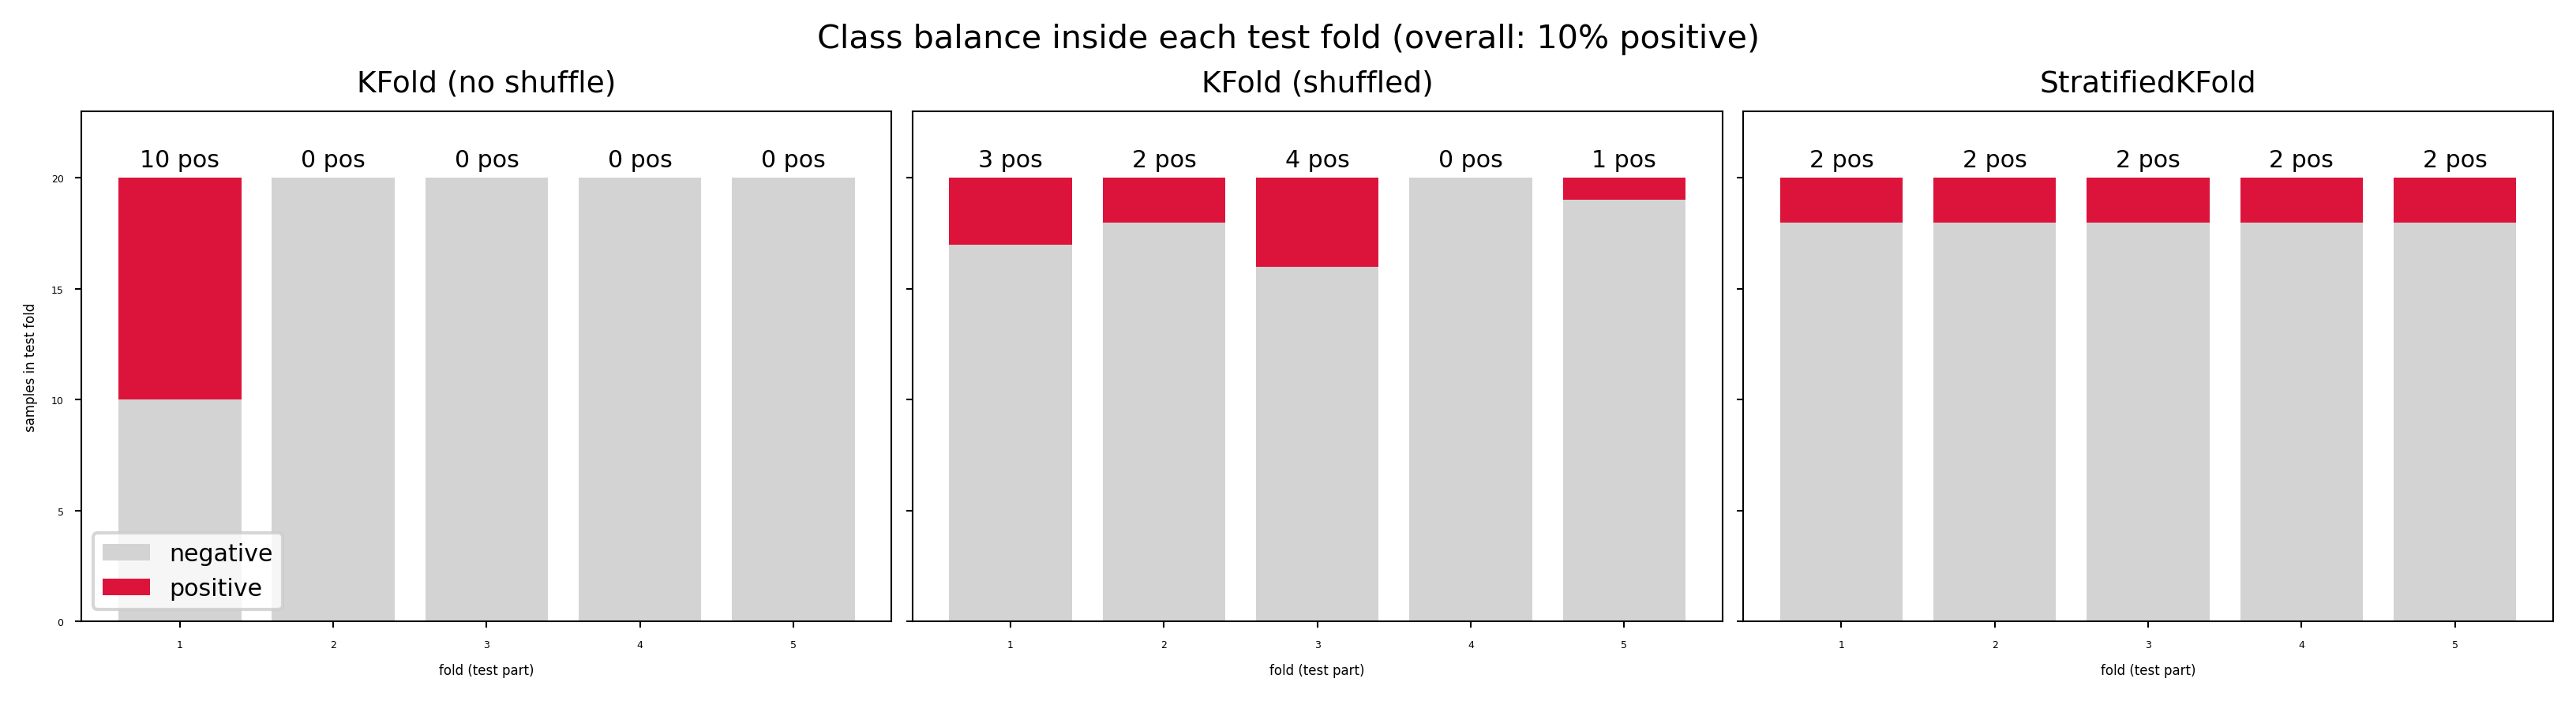

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, StratifiedKFold

fs = globals().get("fig_scale", 0.9)

# 100 samples: 10 positives (class 1) and 90 negatives (class 0)
y = np.array([1]*10 + [0]*90)
X = np.arange(100).reshape(-1, 1)          # features are irrelevant here

splitters = {
    "KFold (no shuffle)":  KFold(5),
    "KFold (shuffled)":    KFold(5, shuffle=True, random_state=0),
    "StratifiedKFold":     StratifiedKFold(5, shuffle=True, random_state=0),
}

fig, axes = plt.subplots(1, 3, figsize=(12*fs, 3.2*fs), sharey=True)
for ax, (name, cv) in zip(axes, splitters.items()):
    pos = [int(y[test].sum()) for _, test in cv.split(X, y)]
    neg = [len(test) - p for p, (_, test) in zip(pos, cv.split(X, y))]
    ax.bar(range(1, 6), neg, color="lightgray", label="negative")
    ax.bar(range(1, 6), pos, bottom=neg, color="crimson", label="positive")
    for k, p in enumerate(pos, 1):
        ax.text(k, 20.5, f"{p} pos", ha="center", fontsize=8*fs)
    ax.set_title(name, fontsize=10*fs); ax.set_xlabel("fold (test part)")
    ax.set_xticks(range(1, 6)); ax.set_ylim(0, 23)
    print(f"{name:20s} positives per test fold: {pos}")
axes[0].set_ylabel("samples in test fold"); axes[0].legend(fontsize=8*fs, loc="lower left")
plt.suptitle("Class balance inside each test fold (overall: 10% positive)", fontsize=11*fs)
plt.tight_layout(); plt.show()

#### Leave-One-Out cross-validation

- _k_ fold cross-validation with _k_ equal to the number of samples
- Completely unbiased (in terms of data splits), but computationally expensive
- Actually generalizes _less_ well towards unseen data
    - The training sets are correlated (overlap heavily)
    - Overfits on the data used for (the entire) evaluation
    - A different sample of the data can yield different results
- Recommended only for small datasets

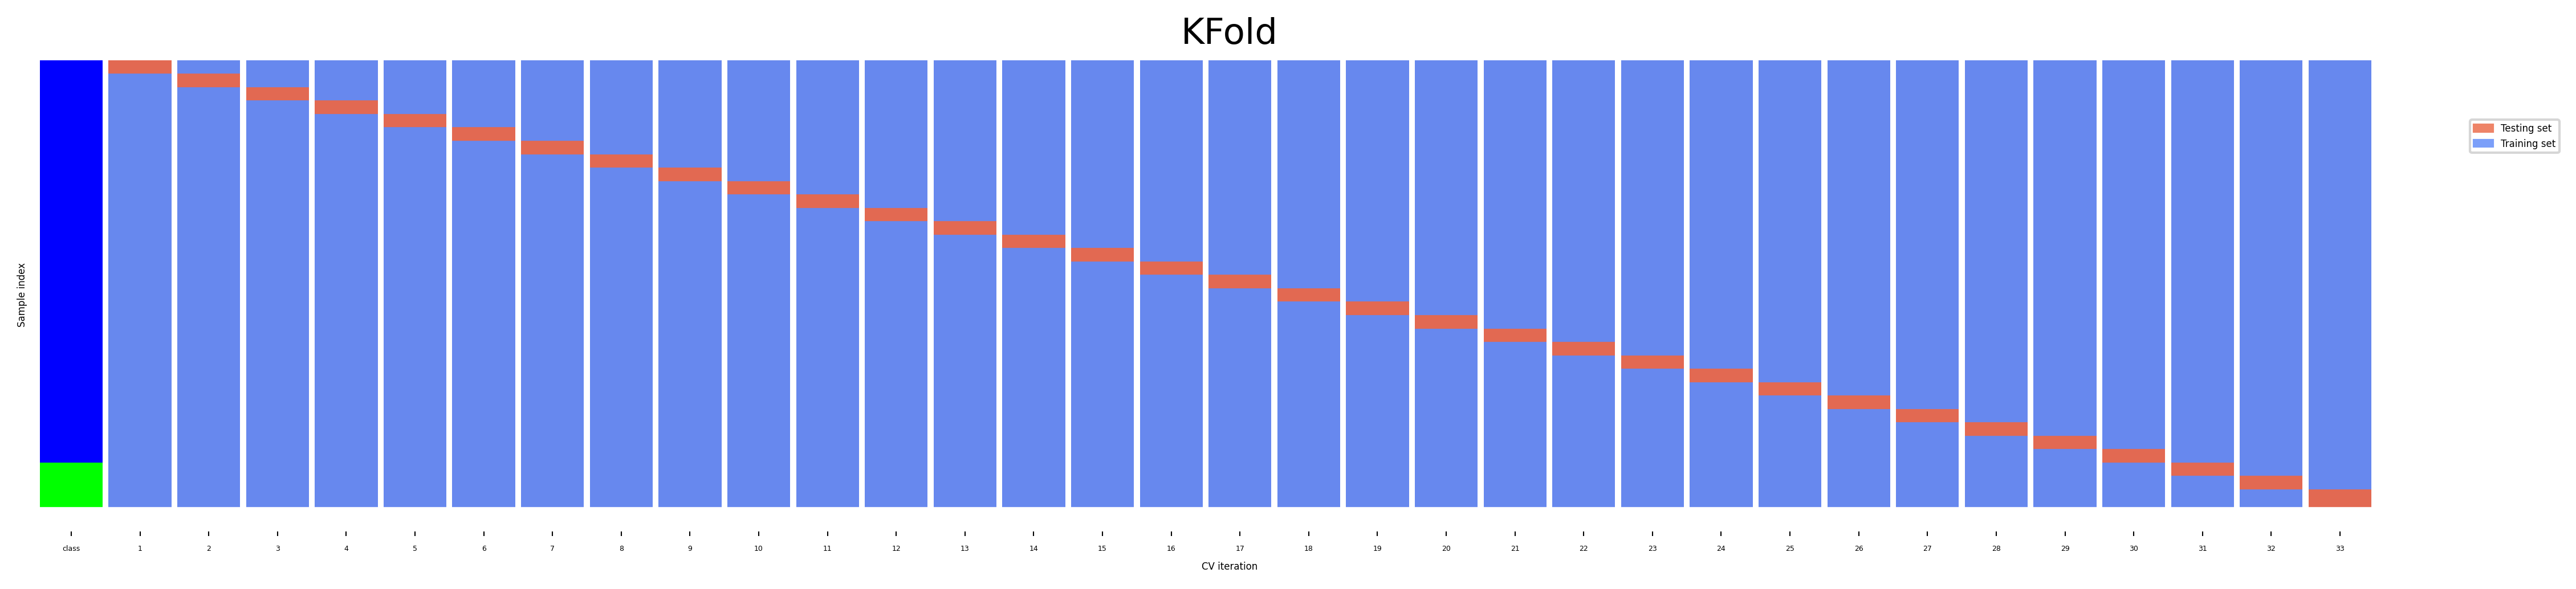

In [11]:
fig, ax = plt.subplots(figsize=(20*fig_scale, 4*fig_scale))
cv = KFold(33)
plot_cv_indices(cv, X, y, groups, ax, s=700)
ax.set_ylim((-6, 100));

#### Shuffle-Split cross-validation
- Shuffles the data, samples (`train_size`) points randomly as the training set
- Can also use a smaller (`test_size`), handy with very large datasets
- Never use if the data is ordered (e.g. time series)

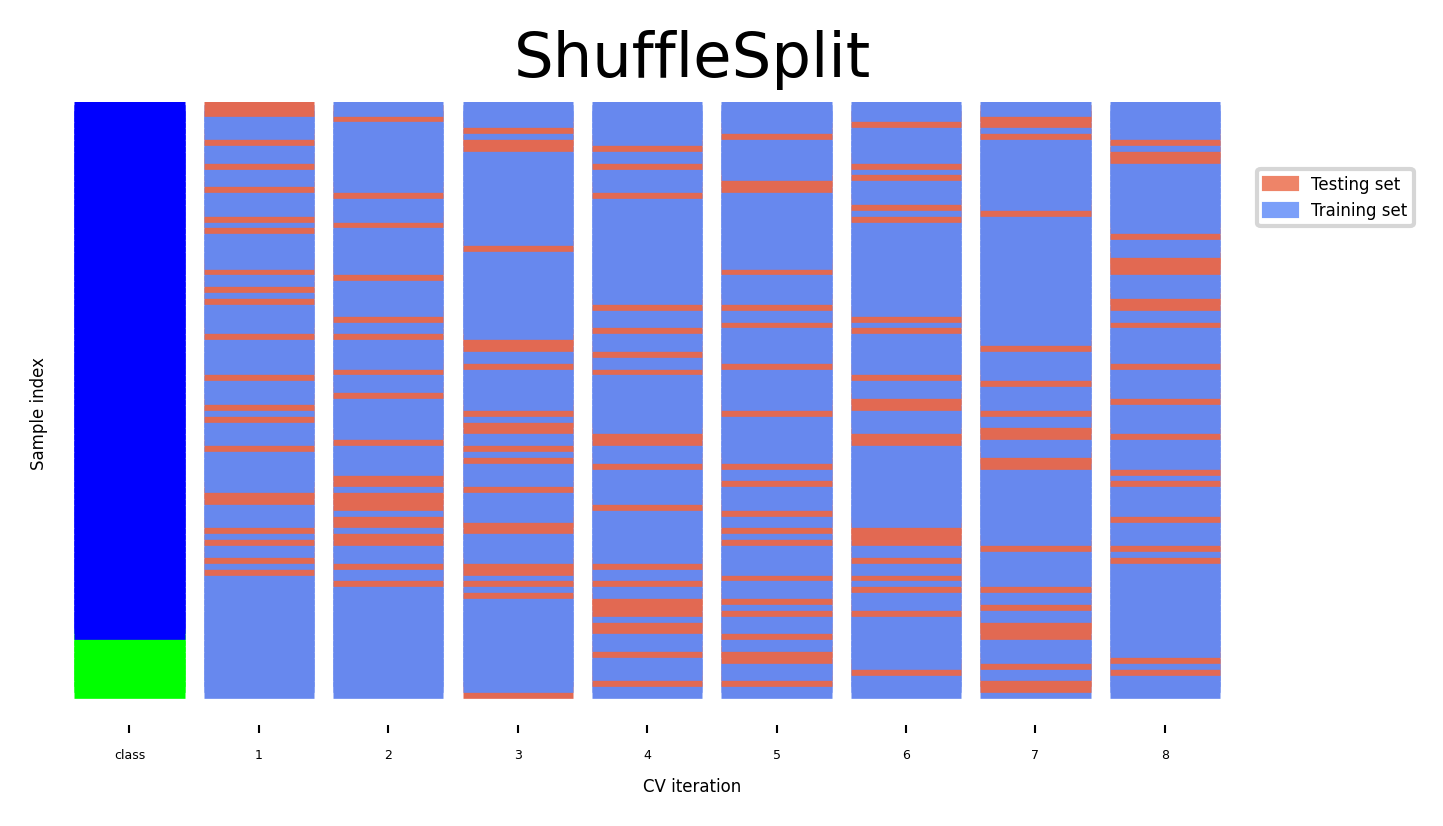

In [12]:
fig, ax = plt.subplots(figsize=(6*fig_scale, 3*fig_scale))
cv = ShuffleSplit(8, test_size=.2)
plot_cv_indices(cv, X, y, groups, ax, n_splits, s=700)
ax.set_ylim((-6, 100))
ax.legend([Patch(color=cmap_cv(.8)), Patch(color=cmap_cv(.2))],
          ['Testing set', 'Training set'], loc=(.95, .8));

### The Bootstrap
- Sample _n_ (dataset size) data points, with replacement, as training set (the bootstrap)
    - On average, bootstraps include 66% of all data points (some are duplicates)
- Use the unsampled (out-of-bootstrap) samples as the test set
- Repeat $k$ times to obtain $k$ scores
- Similar to Shuffle-Split with `train_size=0.66`, `test_size=0.34` but without duplicates
- an average bootstrap sample contains 63.2% of the original observations and omits 36.8%.This follows from the probability that an observation is never selected, which approaches $e^{-1}$ as $n$ increases [@Casalicchio2024Evaluation].


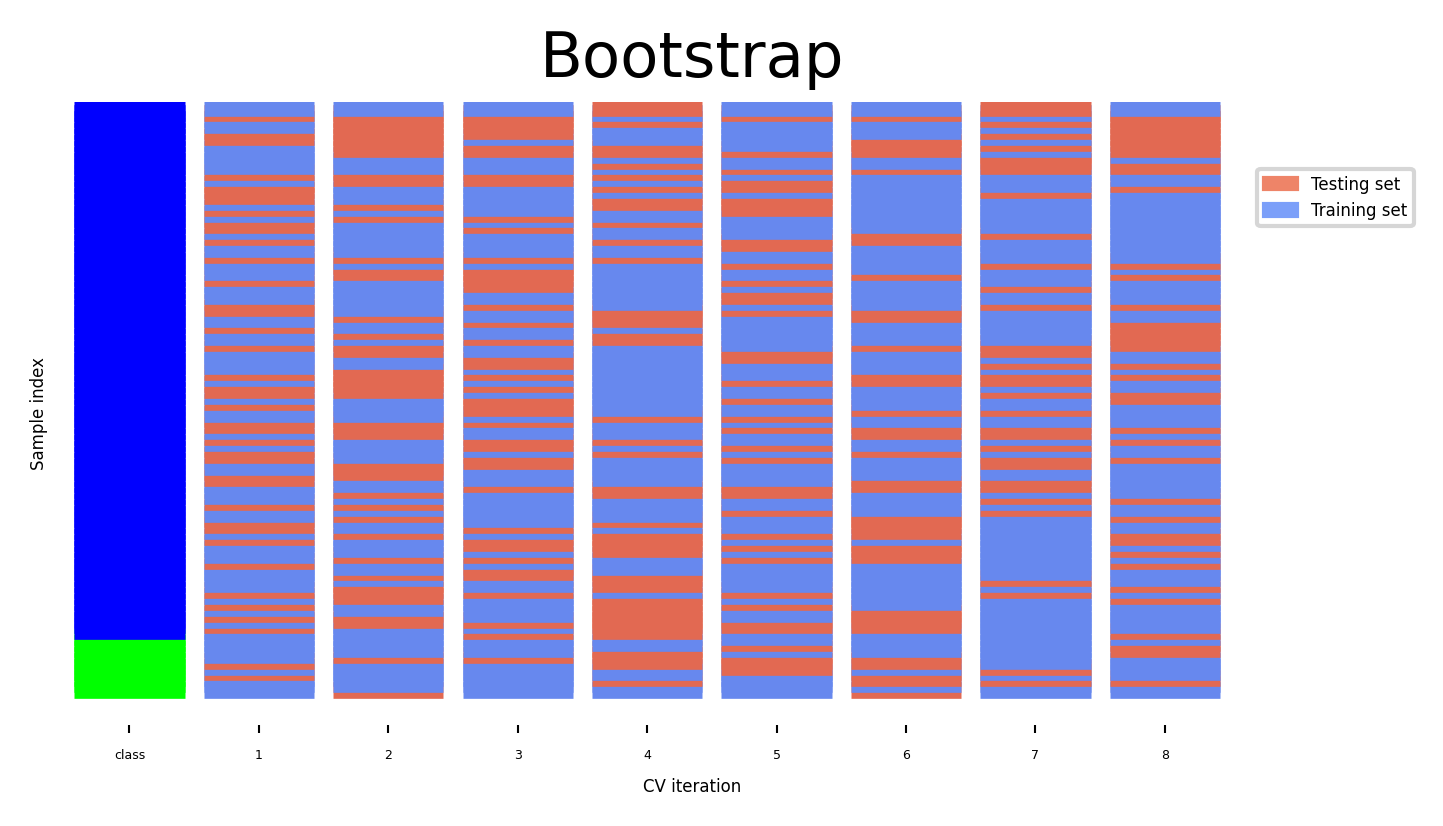

In [13]:
from sklearn.utils import resample

# Toy implementation of bootstrapping
class Bootstrap:
    def __init__(self, nr):
        self.nr = nr
    
    def get_n_splits(self, X, y, groups=None):
        return self.nr
    
    def split(self, X, y, groups=None):
        indices = range(len(X))
        splits = []
        for i in range(self.nr):
            train = resample(indices, replace=True, n_samples=len(X), random_state=i)
            test = list(set(indices) - set(train))
            splits.append((train, test))
        return splits
            
fig, ax = plt.subplots(figsize=(6*fig_scale, 3*fig_scale))
cv = Bootstrap(8)
plot_cv_indices(cv, X, y, groups, ax, n_splits, s=700)
ax.set_ylim((-6, 100))
ax.legend([Patch(color=cmap_cv(.8)), Patch(color=cmap_cv(.2))],
          ['Testing set', 'Training set'], loc=(.95, .8));

### Repeated cross-validation
- Cross-validation is still biased in that the initial split can be made in many ways
- Repeated, or n-times-k-fold cross-validation:
    - Shuffle data randomly, do k-fold cross-validation
    - Repeat n times, yields n times k scores
- Unbiased, very robust, but n times more expensive

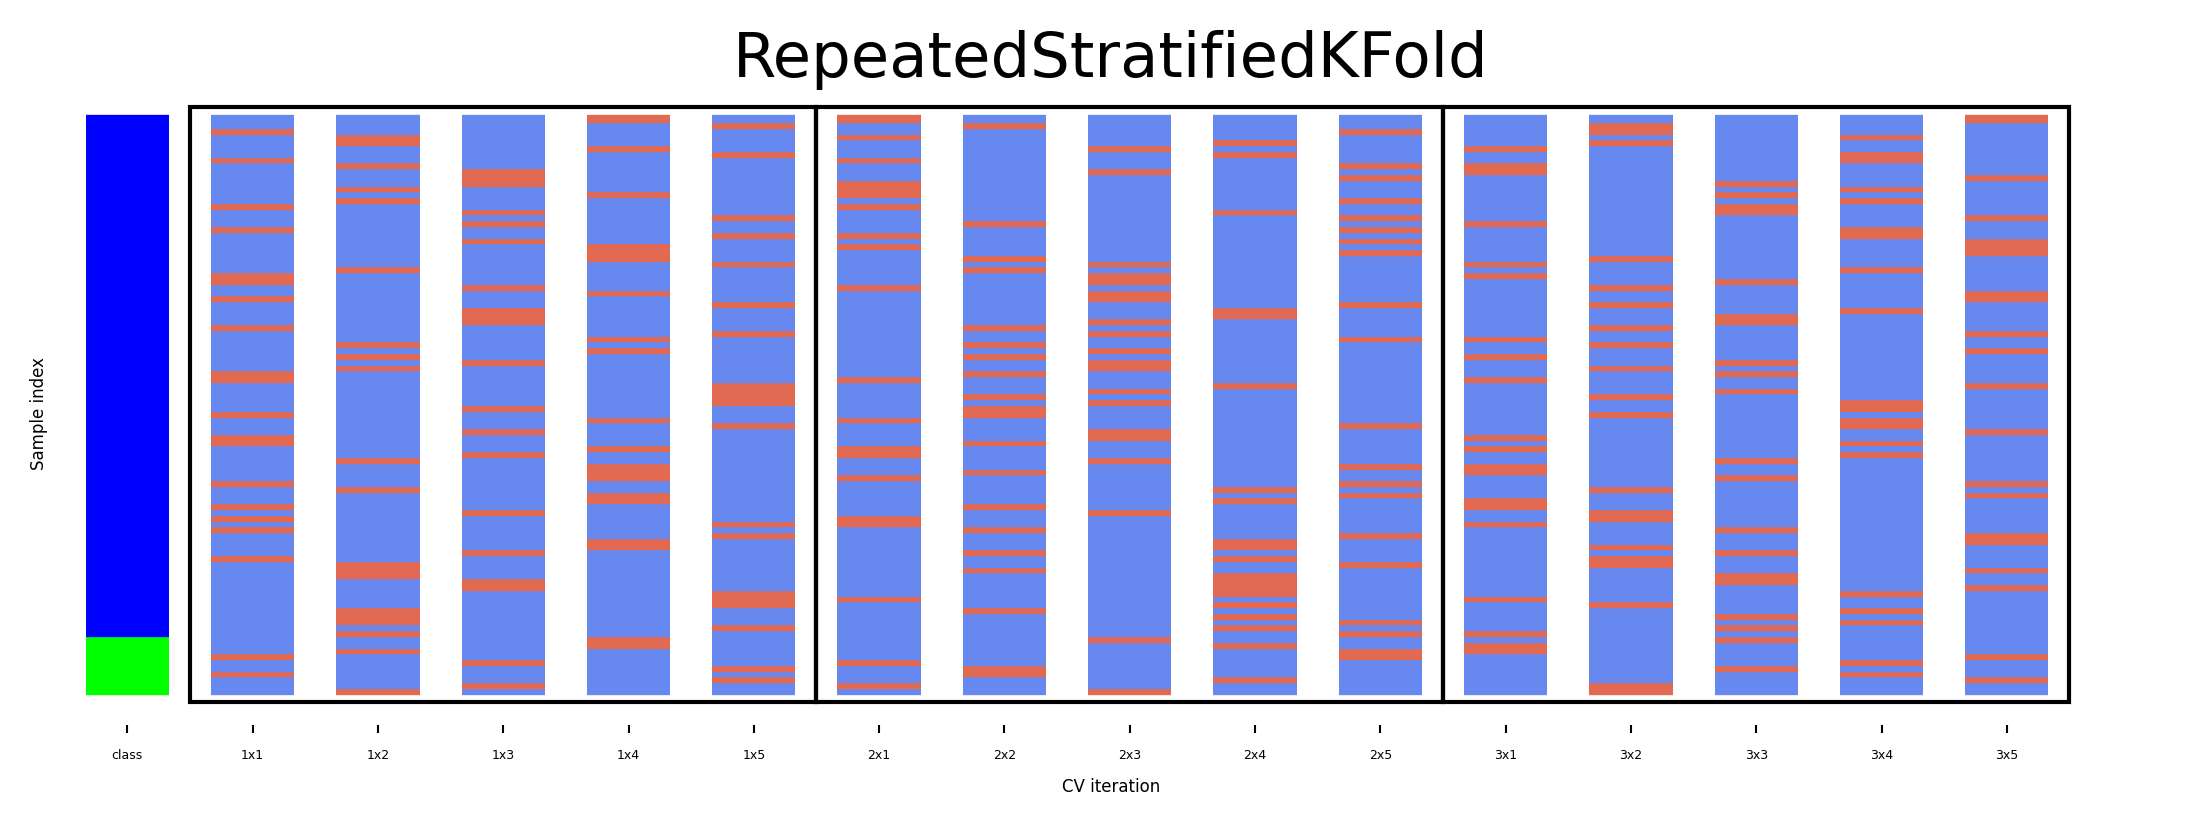

In [14]:
from sklearn.model_selection import RepeatedStratifiedKFold
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(10*fig_scale, 3*fig_scale))
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3)
plot_cv_indices(cv, X, y, groups, ax, lw=2, s=400, legend=False)
ax.set_ylim((-6, 102))
xticklabels = ["class"] + [f"{repeat}x{split}" for repeat in range(1, 4) for split in range(1, 6)]
ax.set_xticklabels(xticklabels)
for i in range(3):
    rect = Rectangle((-.5 + i * 5, -2.), 5, 103, edgecolor='k', facecolor='none')
    ax.add_artist(rect)

### Cross-validation with groups

- Sometimes the data contains inherent groups:
    - Multiple samples from same patient, images from same person,...
- Data from the same person may end up in the training _and_ test set
- We want to measure how well the model generalizes to _other_ people
- Make sure that data from one person are in _either_ the train or test set
    - This is called _grouping_ or _blocking_
    - Leave-one-subject-out cross-validation: test set for each subject/group

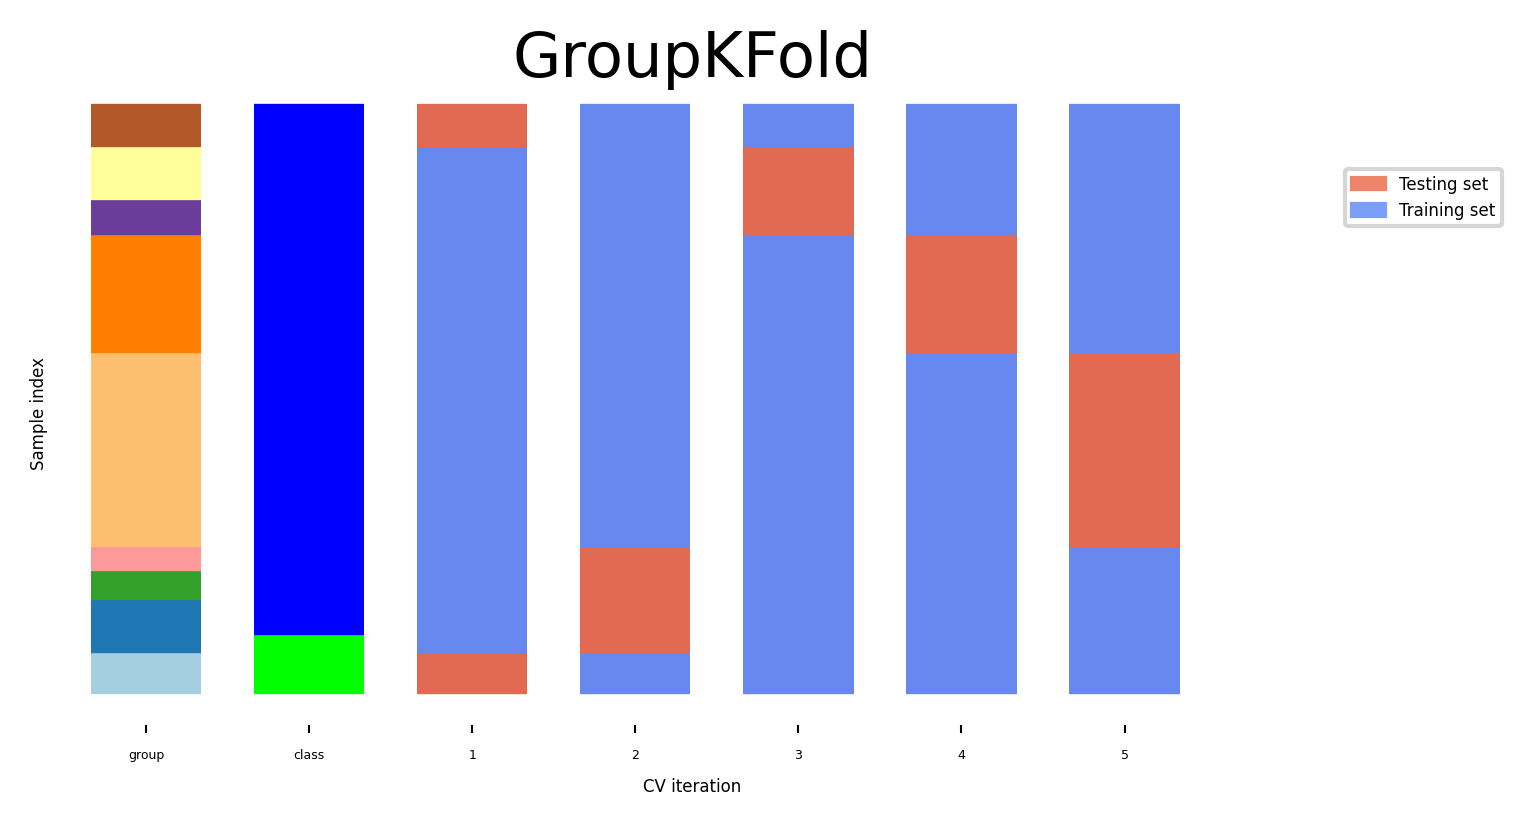

In [15]:
fig, ax = plt.subplots(figsize=(6*fig_scale, 3*fig_scale))
cv = GroupKFold(5)
plot_cv_indices(cv, X, y, groups, ax, s=700, show_groups=True)
ax.set_ylim((-6, 100));

### Time series
When the data is ordered, random test sets are not a good idea

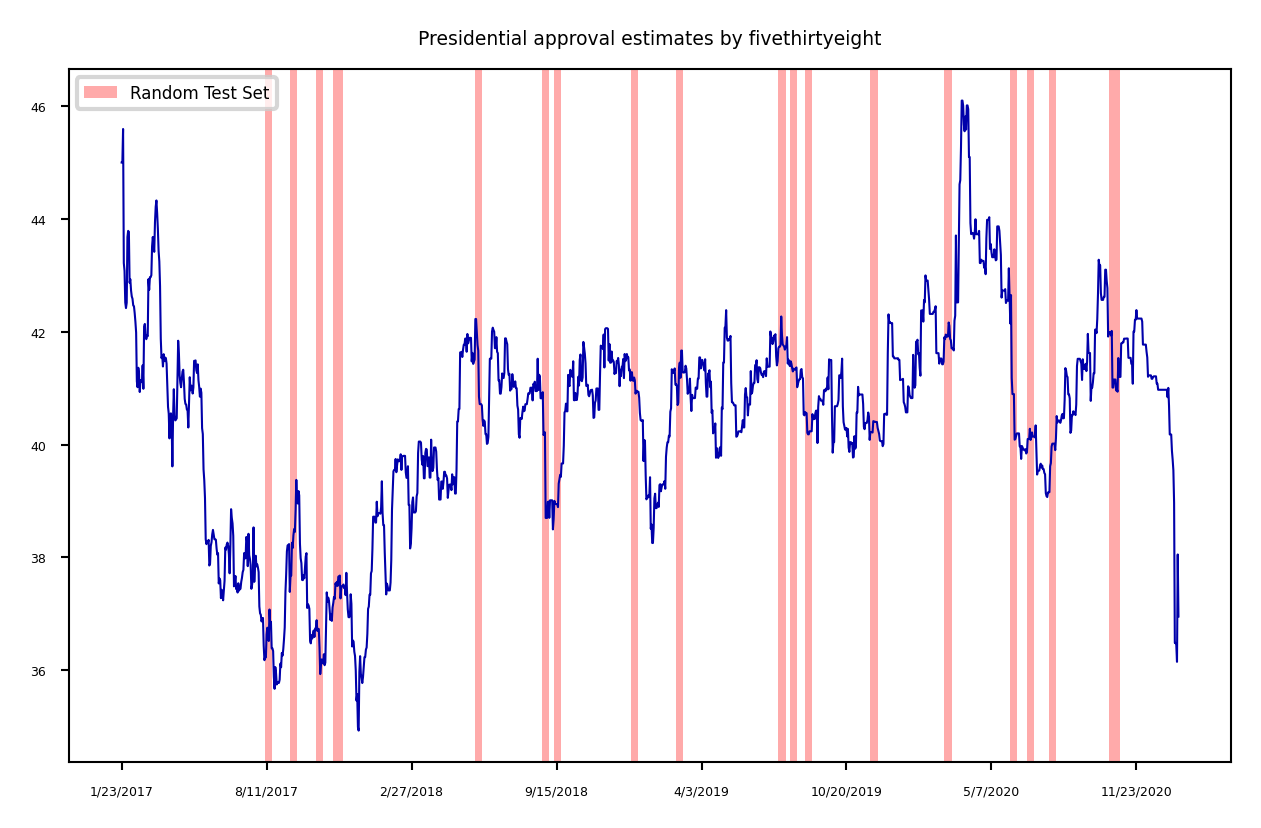

In [ ]:
import pandas as pd
approval = pd.read_csv("../data/approval_topline.csv")
adults = approval.groupby("subgroup").get_group('Adults')
adults = adults.set_index('modeldate')[::-1]
adults.approve_estimate.plot()
ax = plt.gca()
plt.rcParams["figure.figsize"] = (12*fig_scale,6*fig_scale)
ax.set_xlabel("")
xlim, ylim = ax.get_xlim(), ax.get_ylim()
for i in range(20):
    rect = Rectangle((np.random.randint(0, xlim[1]), ylim[0]), 10, ylim[1]-ylim[0], facecolor='#FFAAAA')
    ax.add_artist(rect)
plt.title("Presidential approval estimates by fivethirtyeight")
plt.legend([rect], ['Random Test Set'] );

#### Test-then-train (prequential evaluation)
* Every new sample is evaluated only once, then added to the training set
    * Can also be done in batches (of _n_ samples at a time) 
* `TimeSeriesSplit`
    * In the kth split, the first k folds are the train set and the (k+1)th fold as the test set
    * Often, a maximum training set size (or window) is used
        * more robust against concept drift (change in data over time)

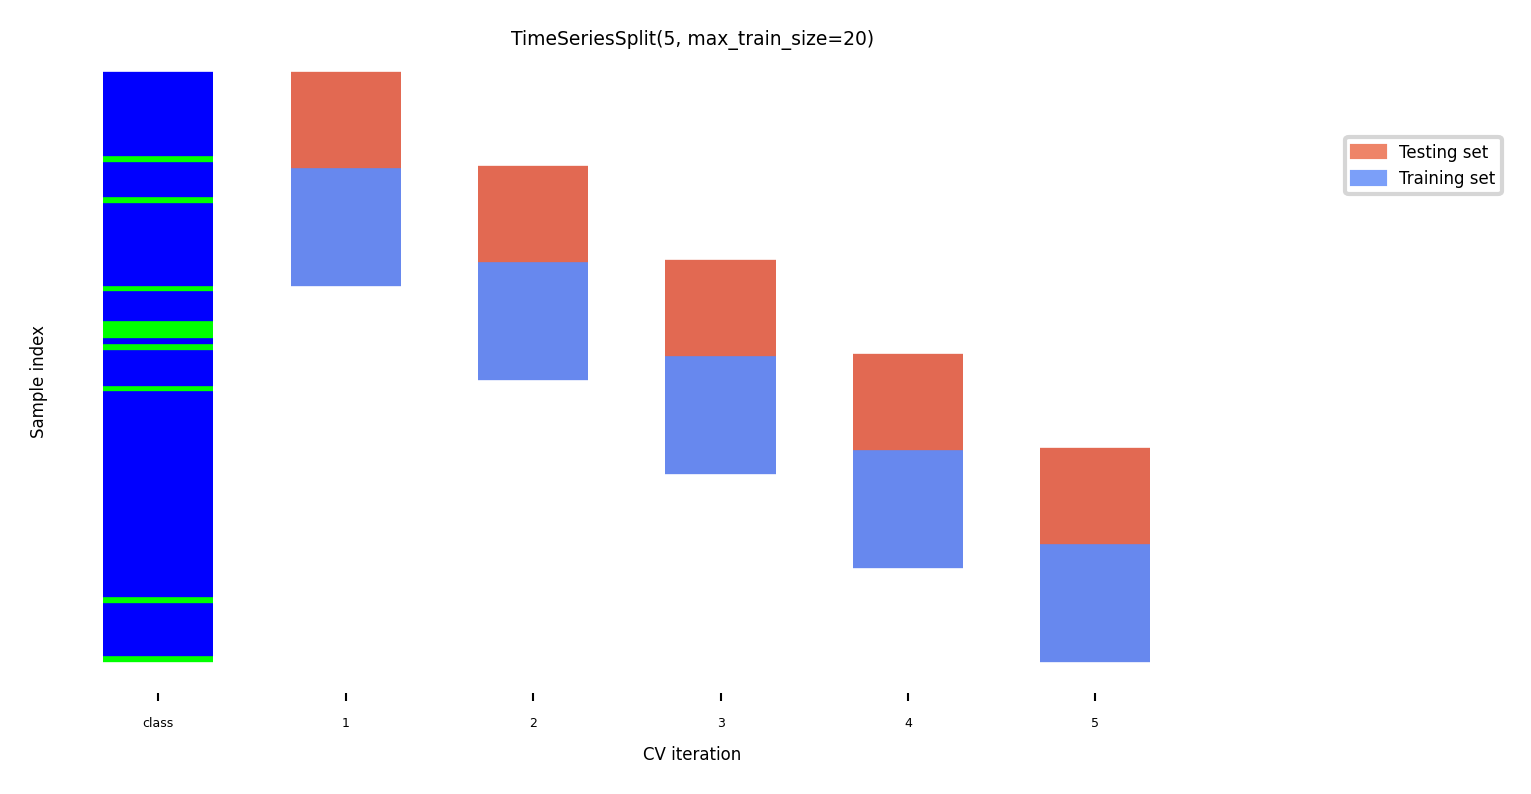

In [17]:
from sklearn.utils import shuffle
fig, ax = plt.subplots(figsize=(6*fig_scale, 3*fig_scale))
cv = TimeSeriesSplit(5, max_train_size=20)
plot_cv_indices(cv, X, shuffle(y), groups, ax, s=700, lw=2)
ax.set_ylim((-6, 100))
ax.set_title("TimeSeriesSplit(5, max_train_size=20)");

#### Scaffold-Based Validation

* It comes from cheminformatics, where each sample is a molecule.
Datasets contain many close analogs: the same core ring system (the scaffold) with different side chains.
* A random split puts analogs in both train and test, so the score is too optimistic.
* A Bemis-Murcko scaffold is what remains after removing the side chains. It keeps the ring systems and the linkers between them {cite}`bemis1996properties`.
* A scaffold split groups molecules by scaffold and puts each whole group in either train or test {cite}`wu2018moleculenet,yang2019analyzing`. It is the same idea as  `Cross-validation with groups` , with the scaffold as the group.
Scaffold groups are assigned as whole units to the train, validation, or test set. The assignment strategy depends on the implementation; common approaches use scaffold-group sizes to construct the partitions.
* Caveats:
    * Scaffold splits often produce lower performance scores than random splits because they evaluate generalization to unseen molecular scaffolds
    * Different scaffolds can still be chemically similar {cite}`guo2024scaffold`.
    * The test set holds the rare scaffolds in implementations  that assign smaller scaffold groups to the test set.
    * Molecules without rings all fall into one empty-scaffold group.

In [18]:
from collections import defaultdict
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
 
smiles = {
    "aspirin": "CC(=O)Oc1ccccc1C(=O)O", "ibuprofen": "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
    "paracetamol": "CC(=O)Nc1ccc(O)cc1", "toluene": "Cc1ccccc1", "aniline": "Nc1ccccc1",
    "naproxen": "COc1ccc2cc(C(C)C(=O)O)ccc2c1", "naphthol": "Oc1cccc2ccccc12",
    "nicotine": "CN1CCCC1c1cccnc1", "caffeine": "Cn1cnc2c1c(=O)n(C)c(=O)n2C",
    "indole": "c1ccc2[nH]ccc2c1", "skatole": "Cc1c[nH]c2ccccc12", "ethanol": "CCO",
}
names = list(smiles)
mols = [Chem.MolFromSmiles(s) for s in smiles.values()]

In [19]:
scaffolds = [MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols]   # '' for molecules without rings
groups_mol = defaultdict(list)
for i, sc in enumerate(scaffolds):
    groups_mol[sc].append(i)
 
# 2) Scaffold split: biggest scaffold sets -> train, the rest -> test
test_size = 0.25
n_train = int((1 - test_size) * len(mols))
train_idx, test_idx = [], []
for sc, idx in sorted(groups_mol.items(), key=lambda kv: (-len(kv[1]), kv[0])):
    (train_idx if len(train_idx) + len(idx) <= n_train else test_idx).extend(idx)

In [21]:
# Check: no scaffold is shared between train and test
assert not {scaffolds[i] for i in train_idx} & {scaffolds[i] for i in test_idx}
 

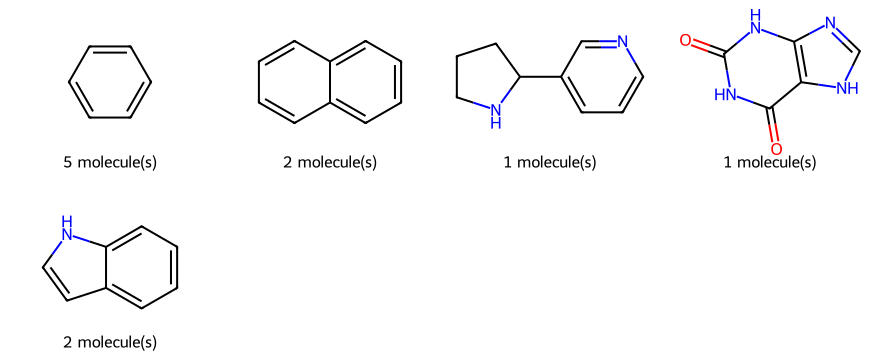

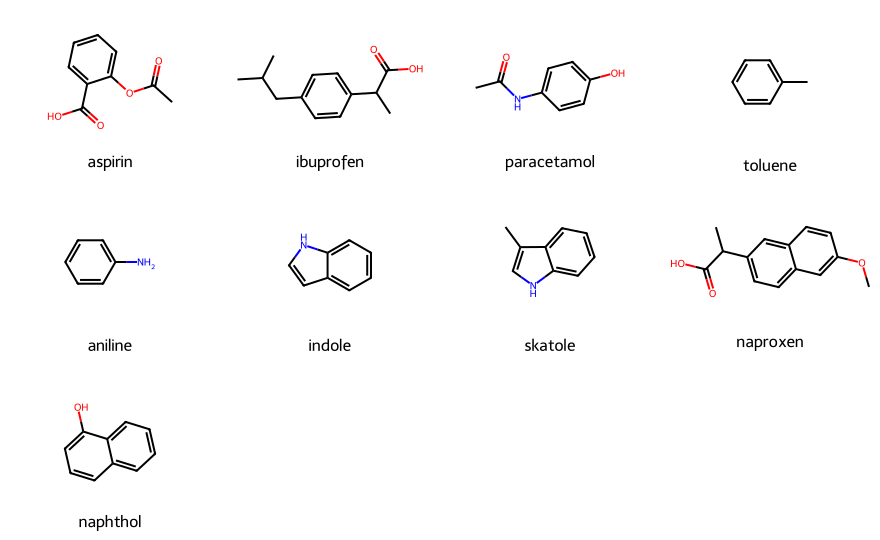

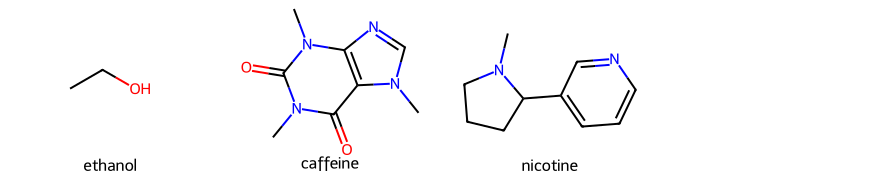

In [22]:
img_scaf = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in groups_mol if s],
                                legends=[f"{len(v)} molecule(s)" for s, v in groups_mol.items() if s],
                                molsPerRow=4, subImgSize=(220, 180))
img_train = Draw.MolsToGridImage([mols[i] for i in train_idx], legends=[names[i] for i in train_idx],
                                 molsPerRow=4, subImgSize=(220, 180))
img_test = Draw.MolsToGridImage([mols[i] for i in test_idx], legends=[names[i] for i in test_idx],
                                molsPerRow=4, subImgSize=(220, 180))
display(img_scaf, img_train, img_test)

### Choosing a performance estimation procedure
No strict rules, only guidelines:

- Always use stratification for classification (sklearn does this by default)
- Use holdout for very large datasets (e.g. >1.000.000 examples)
    - Or when learners don't always converge (e.g. deep learning)
- Choose _k_ depending on dataset size and resources
    - Use leave-one-out for very small datasets (e.g. <100 examples)
    - Use cross-validation otherwise
        - Most popular (and theoretically sound): 10-fold CV
        - Literature suggests 5x2-fold CV is better
- Use grouping or leave-one-subject-out for grouped data
- Use train-then-test for time series

## Evaluation Metrics for Classification

### Evaluation vs Optimization

- Each algorithm optimizes a given objective function (on the training data)
    - E.g. remember L2 loss in Ridge which is linear regression with a penalty that stops the weights from becoming too large.
$$\mathcal{L}_{Ridge} = \sum_{n=1}^{N} (y_n-(\mathbf{w}\mathbf{x_n} + w_0))^2 + \alpha \sum_{i=0}^{p} w_i^2$$

* Large weights make this term large, so the algorithm is pushed toward small weights.
α sets how much the penalty counts:
α = 0 gives ordinary least squares.
A very large α pushes all weights toward 0, and the model underfits.
An α in between is usually best.

- The choice of function is limited by what can be efficiently optimized
- However, we _evaluate_ the resulting model with a score that makes sense **in the real world**
    - Percentage of correct predictions (on a test set)
    - The actual cost of mistakes (e.g. in money, time, lives,...)
- We also tune the algorithm's hyperparameters to maximize that score

best alpha by test R2: 0.189  R2: 0.929  alpha~0 R2: 0.875


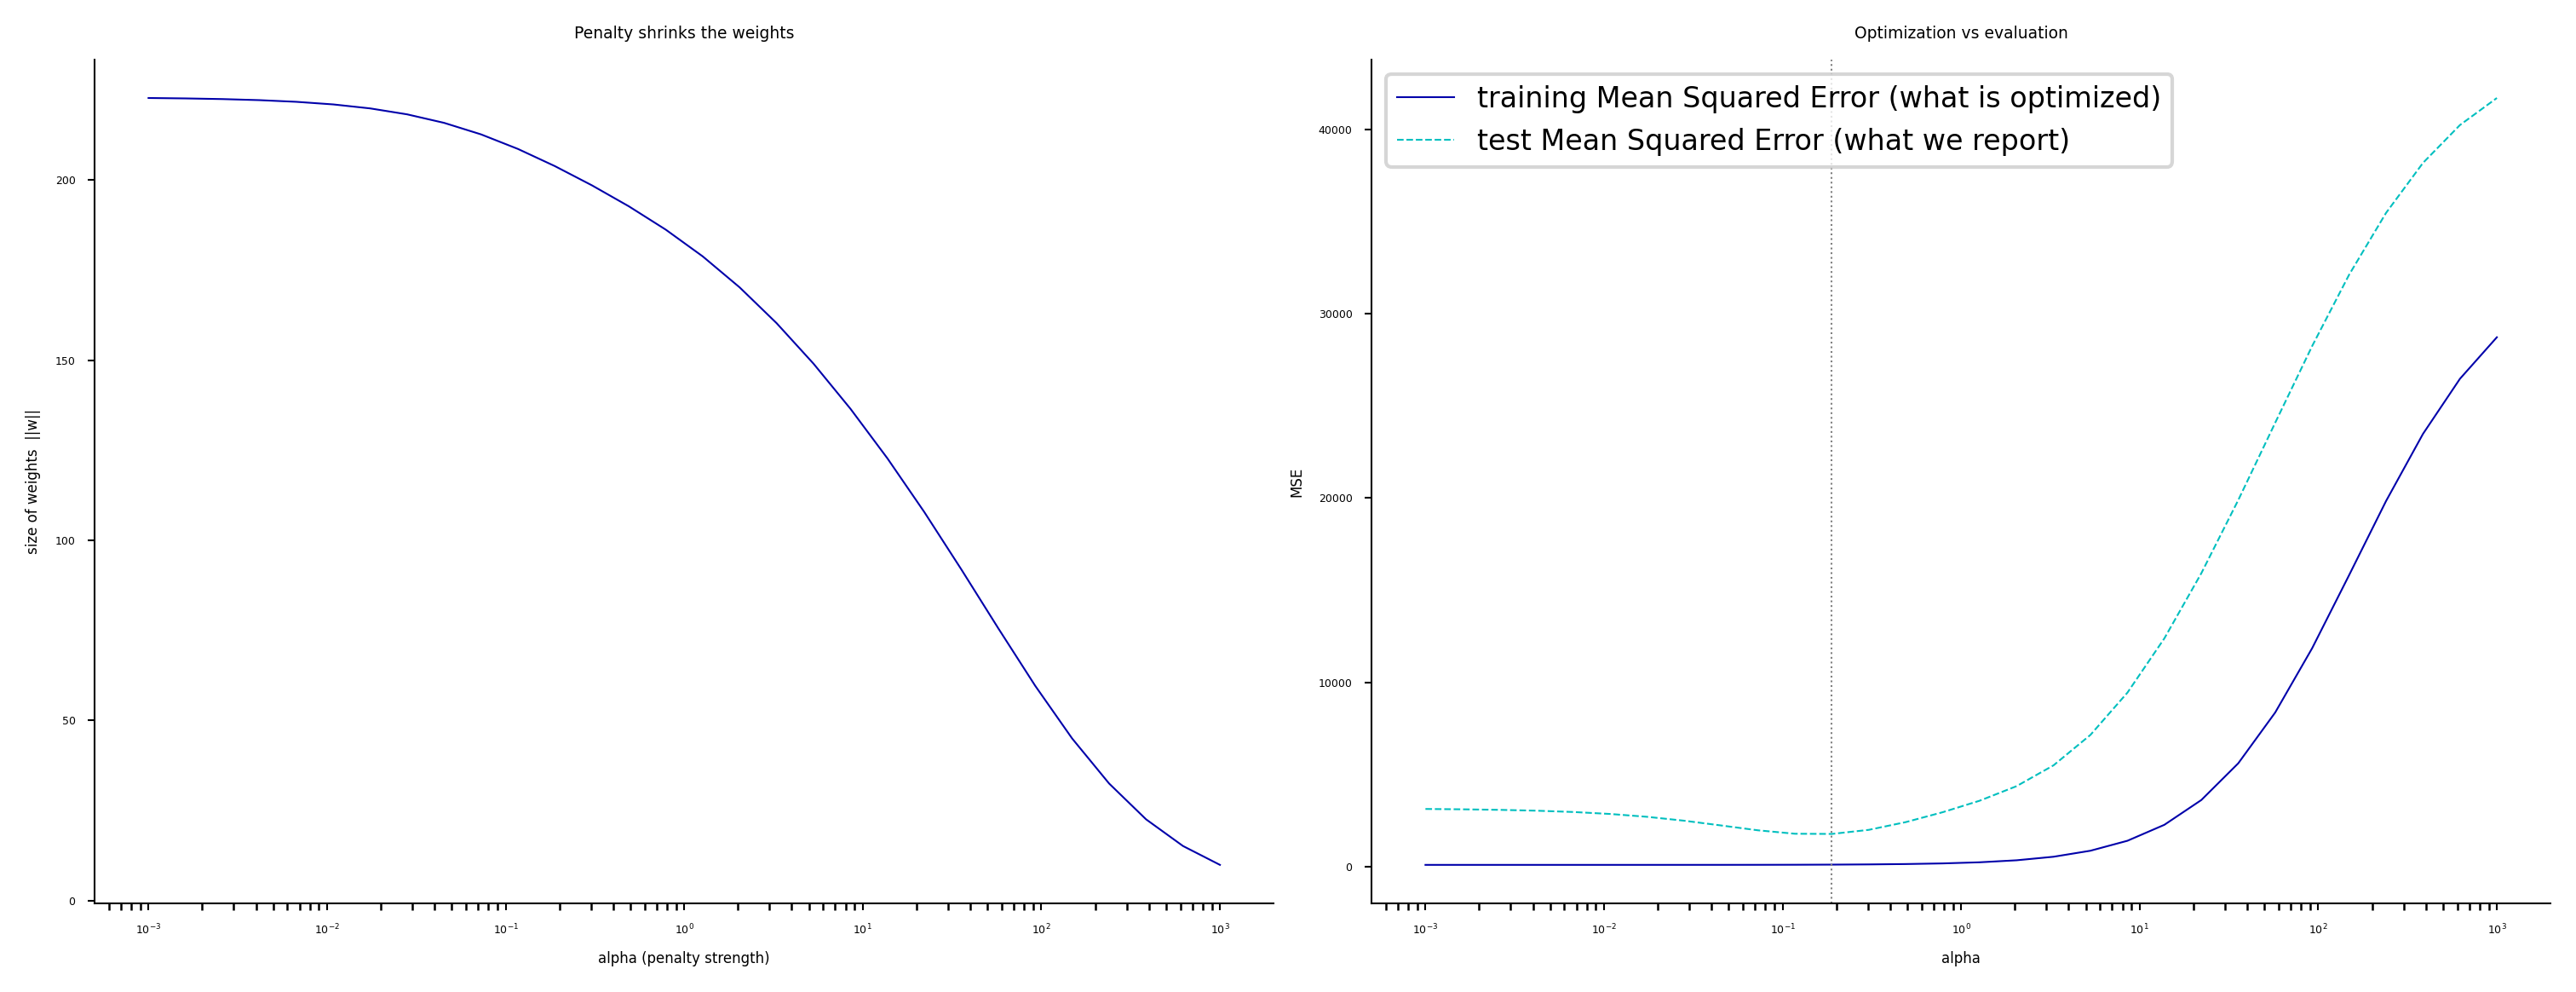

In [23]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Few samples, many features -> plain least squares overfits
X, y = make_regression(n_samples=60, n_features=40, n_informative=8, noise=25, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, random_state=0)

alphas = np.logspace(-3, 3, 30)
coef_norm, tr_mse, te_mse, te_mae, te_r2 = [], [], [], [], []
for a in alphas:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xtr, ytr)
    coef_norm.append(np.linalg.norm(m[-1].coef_))
    tr_mse.append(mean_squared_error(ytr, m.predict(Xtr)))
    te_mse.append(mean_squared_error(yte, m.predict(Xte)))
    te_mae.append(mean_absolute_error(yte, m.predict(Xte)))
    te_r2.append(r2_score(yte, m.predict(Xte)))
best = alphas[int(np.argmax(te_r2))]
print("best alpha by test R2:", round(best, 3), " R2:", round(max(te_r2), 3), " alpha~0 R2:", round(te_r2[0], 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].semilogx(alphas, coef_norm, color="C0"); ax[0].set(xlabel="alpha (penalty strength)", ylabel="size of weights  ||w||", title="Penalty shrinks the weights")
ax[1].semilogx(alphas, tr_mse, label="training Mean Squared Error (what is optimized)", color="C0")
ax[1].semilogx(alphas, te_mse, label="test Mean Squared Error (what we report)", color="C3")
ax[1].axvline(best, ls=":", color="gray"); ax[1].set(xlabel="alpha", ylabel="MSE", title="Optimization vs evaluation"); ax[1].legend(fontsize=8)
for a_ in ax: [a_.spines[s].set_visible(False) for s in ("top","right")]
fig.tight_layout()
plt.show()   

### Binary classification

- We have a positive and a negative class
- 2 different kind of errors:
    - False Positive (type I error): model predicts positive while true label is negative
    - False Negative (type II error): model predicts negative while true label is positive
- The two errors are rarely equally costly, so the question is: which one hurts more?

**Example: spam filtering** (positive = spam, negative = a legitimate email)

| | Predicted: legitimate | Predicted: spam |
|-|-|-|
| Actual: legitimate | TN | **FP** — an important email disappears into the spam folder |
| Actual: spam | **FN** — one junk message in the inbox | TP |

- A false **positive** is the worse mistake here: the user never sees the message and may miss something important (a deadline, an email from the supervisor)
- A false **negative** is only an annoyance: the user sees the spam and deletes it
- So this filter should mark a message as spam only when it is confident, i.e. we accept false negatives to avoid false positives

**Contrast: cancer screening** (positive = patient is ill). There a false *negative* — sending a sick patient home — is far more dangerous than a false *positive* (an unnecessary follow-up test), so the model is tuned the opposite way.


#### Confusion matrices
- We can represent all predictions (correct and incorrect) in a confusion matrix
    - n by n array (n is the number of classes)
    - Rows correspond to true classes, columns to predicted classes
    - Count how often samples belonging to a class C are classified as C or any other class.
    - For binary classification, we label these true negative (TN), true positive (TP), false negative (FN), false positive (FP)

| | Predicted Neg | Predicted Pos |
|-|-|-|
| Actual Neg | TN | FP |
| Actual Pos | FN | TP |

Accuracy: 0.937


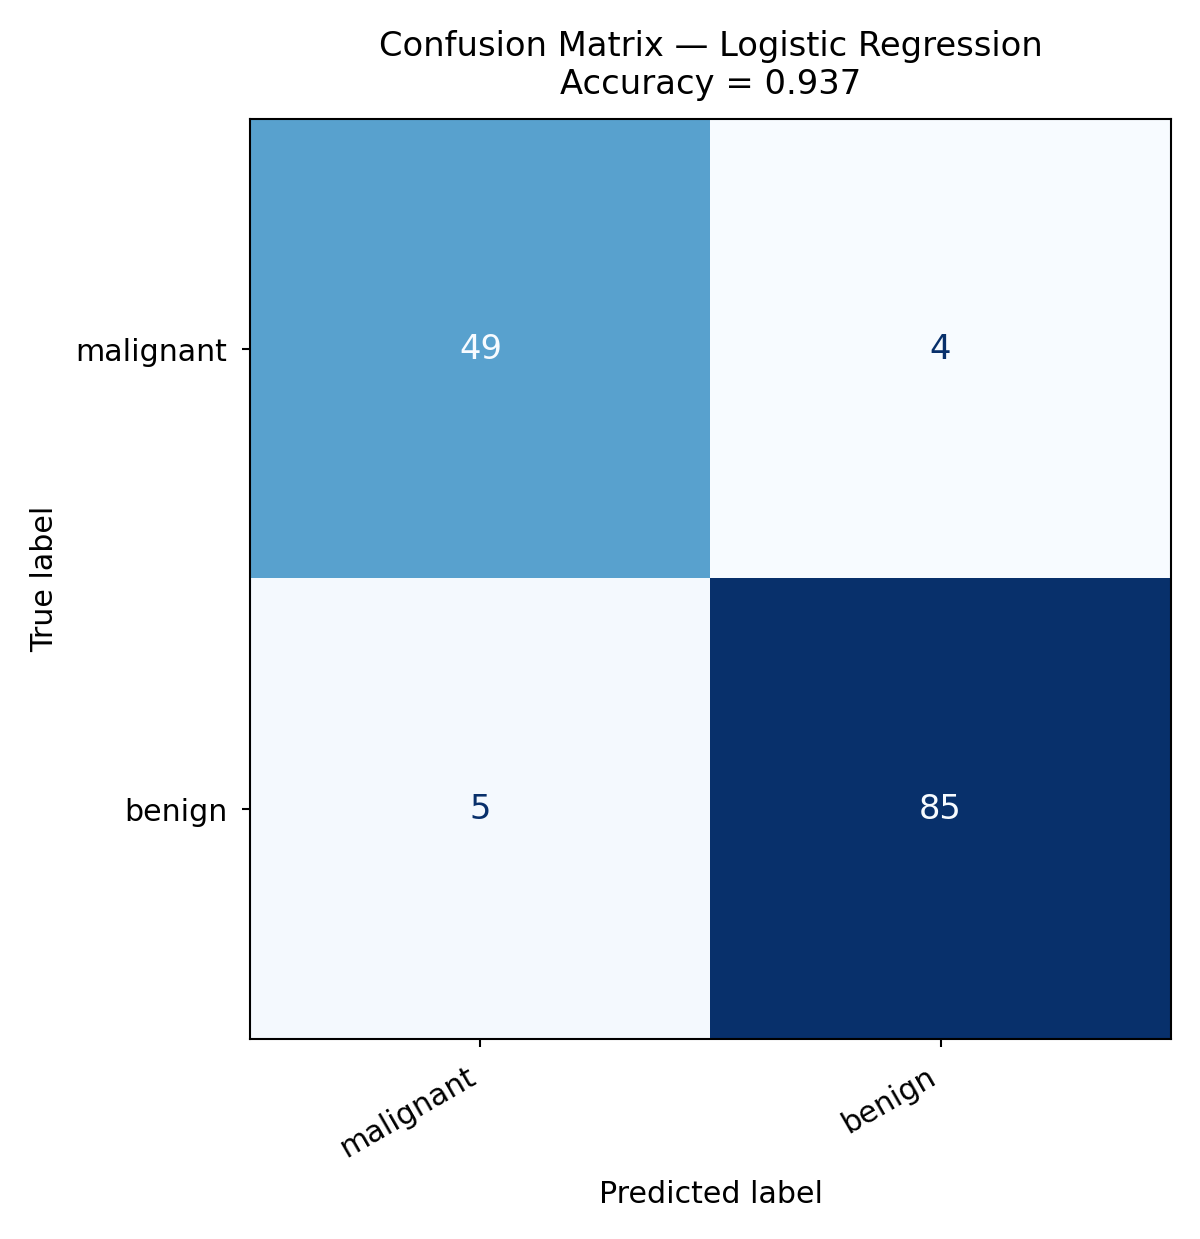

In [24]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, stratify=data.target, random_state=0)

lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)
y_pred = lr.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.3f}")

fig, ax = plt.subplots(figsize=(5 * fig_scale, 4.5 * fig_scale))

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=data.target_names,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title(
    f"Confusion Matrix — Logistic Regression\nAccuracy = {acc:.3f}",
    fontsize=9 * fig_scale,
)
ax.set_xlabel("Predicted label", fontsize=8 * fig_scale)
ax.set_ylabel("True label",      fontsize=8 * fig_scale)
ax.tick_params(axis="both", labelsize=8 * fig_scale)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

# Scale the numbers inside the cells — these are the artists most people forget
for text in disp.text_.ravel():
    text.set_fontsize(9 * fig_scale)

plt.tight_layout()
plt.show()

#### Predictive accuracy

- Accuracy can be computed based on the confusion matrix
- Not useful if the dataset is very imbalanced
    - E.g. credit card fraud: is 99.99% accuracy good enough? 

$$
\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}
$$

- 3 models: very different predictions, same accuracy:

In [25]:
def plot_confusion_matrix(values, xlabel="predicted labels", ylabel="true labels", xticklabels=None,
                          yticklabels=None, cmap=None, vmin=None, vmax=None, ax=None,
                          fmt="{:.2f}", xtickrotation=45, norm=None, fsize=8):
    
    if ax is None:
        ax = plt.gca()
    ax.figure.set_size_inches(6*fig_scale, 6*fig_scale)
    values = np.array(values)  # Ensure 'values' is a numpy array for consistent handling
    img = ax.pcolormesh(values, cmap=cmap, vmin=vmin, vmax=vmax, norm=norm)
    ax.set_xlabel(xlabel, fontsize=8)
    ax.set_ylabel(ylabel, fontsize=8)

    # Setting the tick labels
    ax.set_xticks(np.arange(values.shape[1]) + 0.5, minor=False)
    ax.set_yticks(np.arange(values.shape[0]) + 0.5, minor=False)
    ax.set_xticklabels(xticklabels or [], minor=False, rotation=xtickrotation, fontsize=8)
    ax.set_yticklabels(yticklabels or [], minor=False, fontsize=8)

    # Loop over data dimensions and create text annotations.
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j + 0.5, i + 0.5, fmt.format(values[i, j]),
                    ha="center", va="center", color="white" if values[i, j] > vmax/2 else "black", fontsize=8)

    ax.set_aspect('equal')  # Optional: set aspect ratio to be equal
    ax.invert_yaxis()
    return ax

In [26]:
# Artificial 90-10 imbalanced target
y_true = np.zeros(100, dtype=int)
y_true[:10] = 1
y_pred_1 = np.zeros(100, dtype=int)
y_pred_2 = y_true.copy()
y_pred_2[10:20] = 1
y_pred_3 = y_true.copy()
y_pred_3[5:15] = 1 - y_pred_3[5:15]

def plot_measure(measure):
    fig, axes = plt.subplots(1, 3)
    for i, (ax, y_pred) in enumerate(zip(axes, [y_pred_1, y_pred_2, y_pred_3])):
        plot_confusion_matrix(confusion_matrix(y_true, y_pred), cmap='gray_r', ax=ax,
                              xticklabels=["N", "P"], yticklabels=["N", "P"], xtickrotation=0, vmin=0, vmax=100)
        ax.set_title("{}: {:.2f}".format(measure.__name__,measure(y_true, y_pred)), fontsize=8*fig_scale)

    plt.tight_layout()

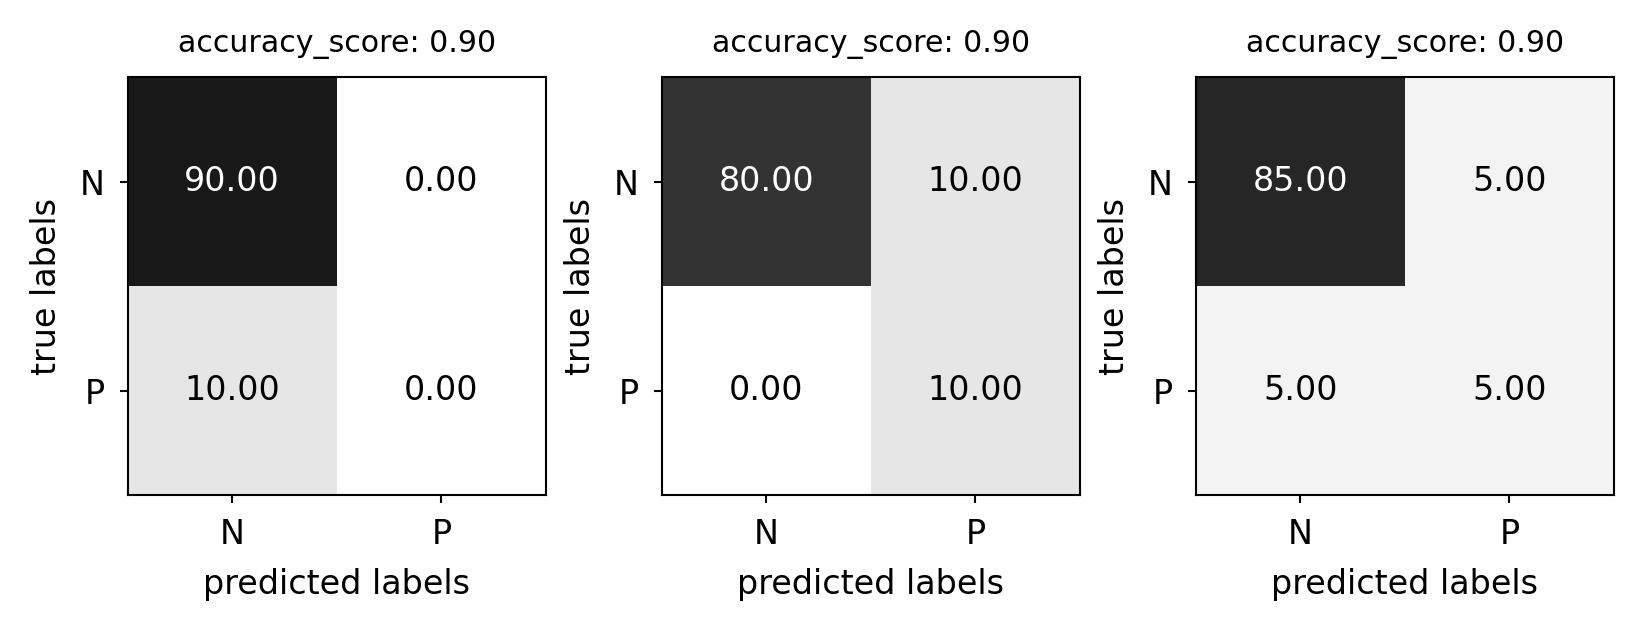

In [27]:
plot_measure(accuracy_score)

#### Precision
- Use when the goal is to limit FPs
    - Clinical trials: you only want to test drugs that really work
    - Search engines: you want to avoid bad search results

$$
\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}
$$

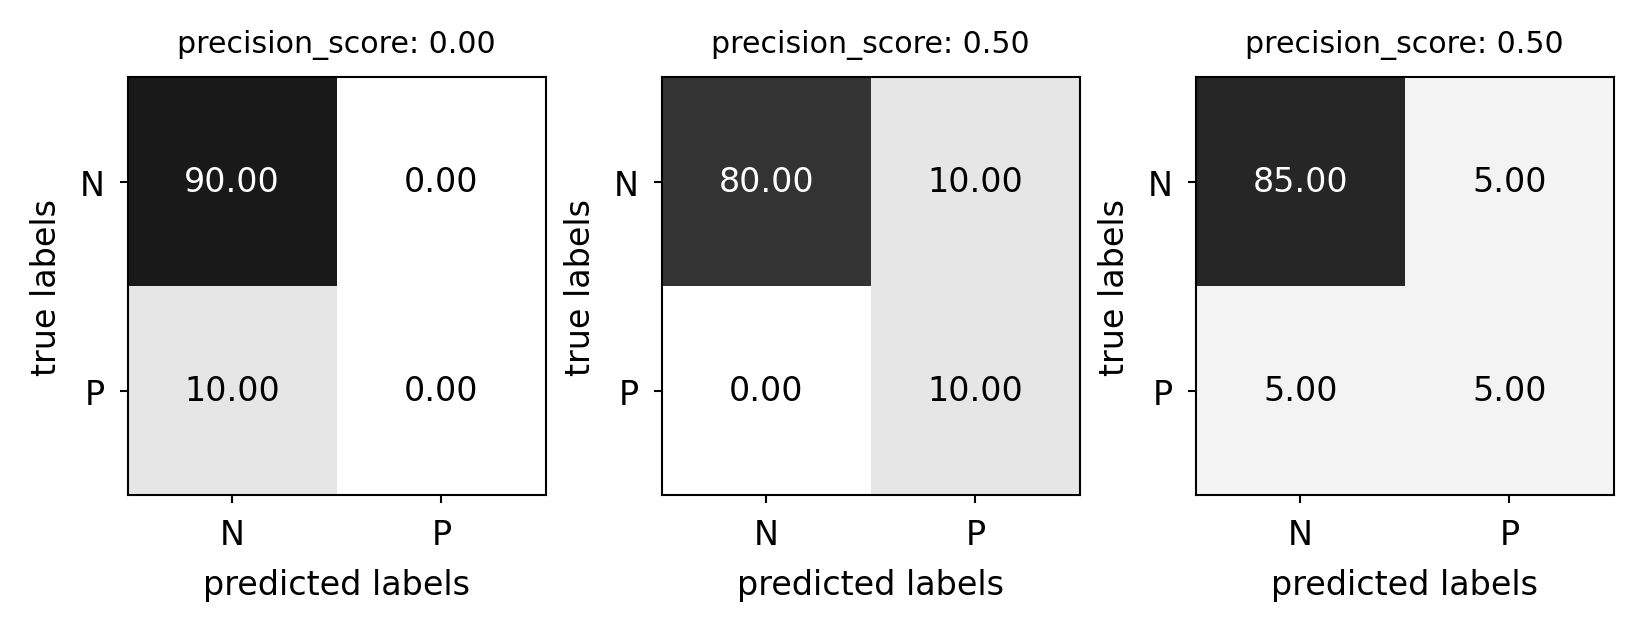

In [28]:
from sklearn.metrics import precision_score
plot_measure(precision_score)

#### Recall
- Use when the goal is to limit FNs
    - Cancer diagnosis: you don't want to miss a serious disease
    - Search engines: You don't want to omit important hits
- Also known as sensitivity, hit rate, true positive rate (TPR)

$$
\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}
$$

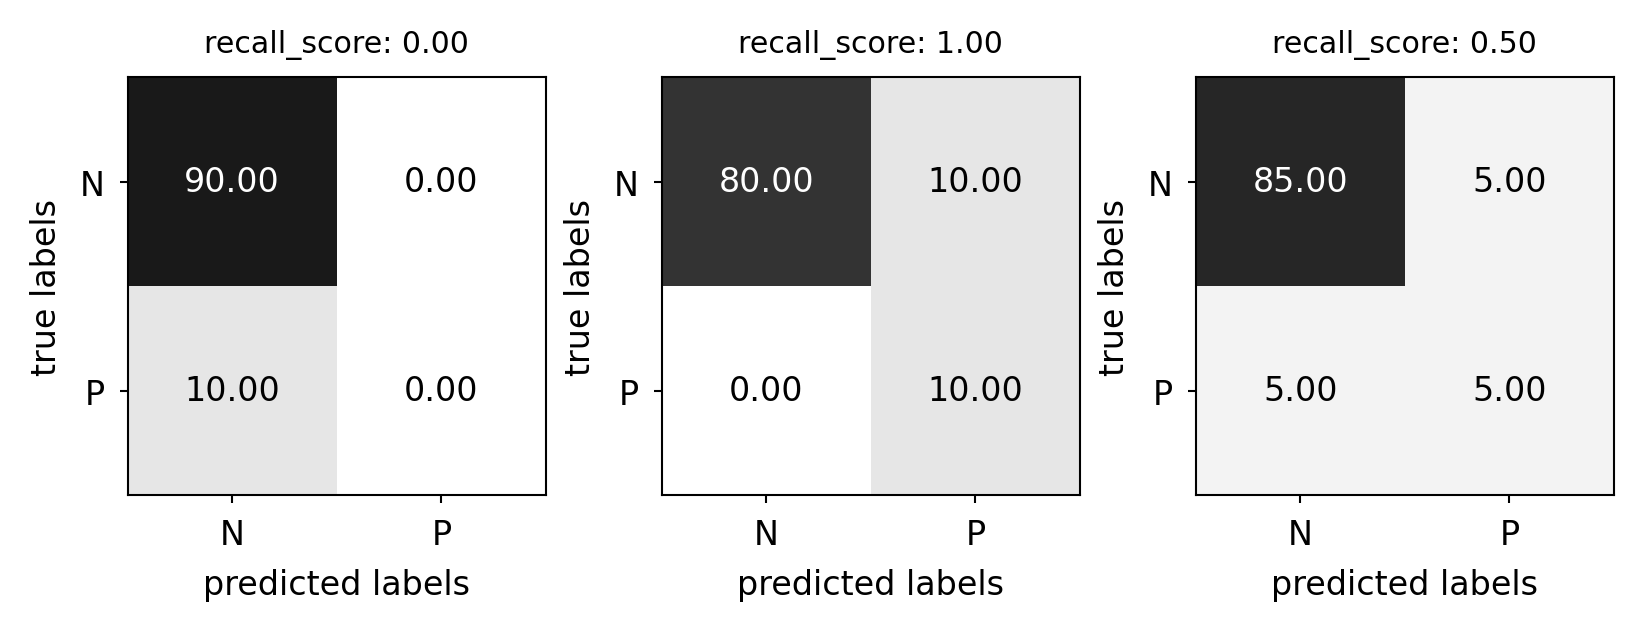

In [29]:
from sklearn.metrics import recall_score
plot_measure(recall_score)

__Comparison__   
<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/07_precision-recall.jpg" alt="ml" style="width: 50%"/>

#### F1-score
- Trades off precision and recall:

$$
\text{F1} = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}
$$

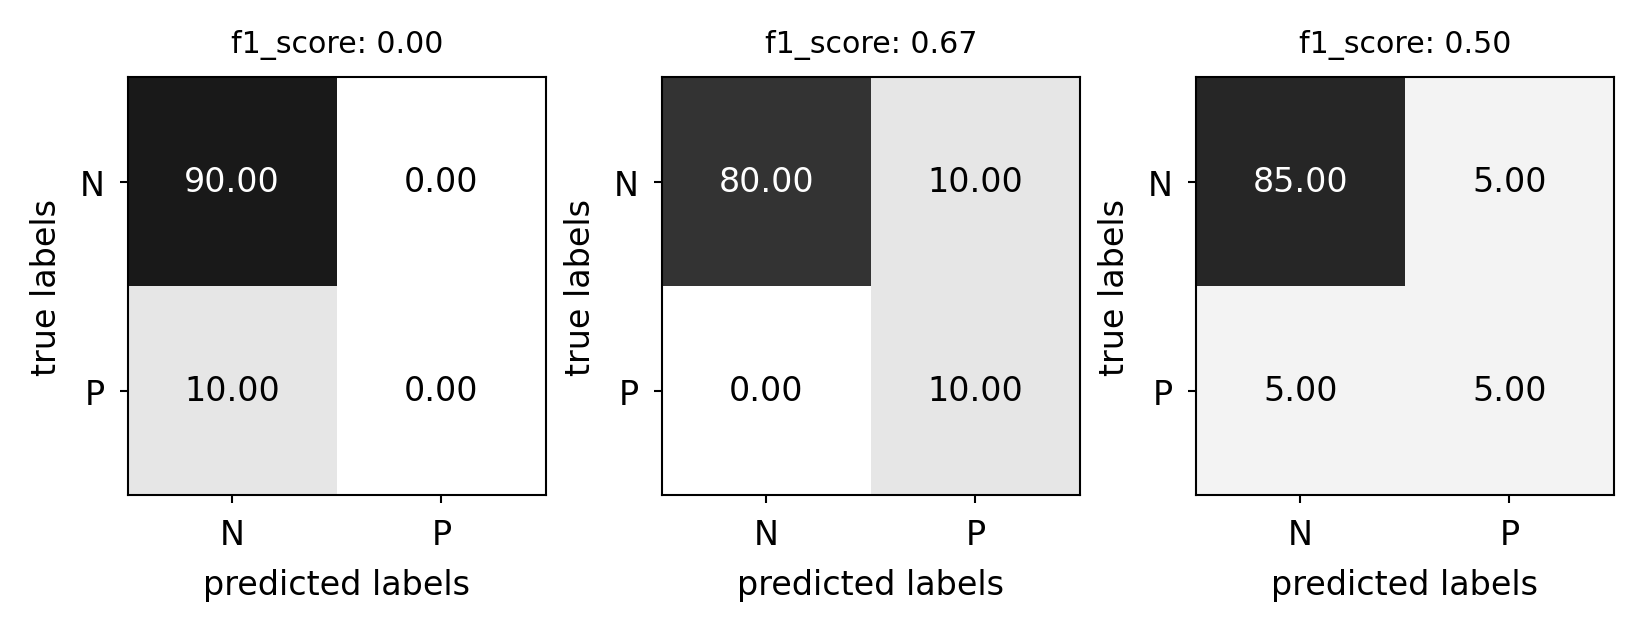

In [30]:
from sklearn.metrics import f1_score
plot_measure(f1_score)

__Classification measure Zoo__   
<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/07_zoo.png" alt="ml" style="width: 1500px;"/>

https://en.wikipedia.org/wiki/Precision_and_recall

### Multi-class classification
- Train models _per class_ : one class viewed as positive, other(s) also negative, then average
    - micro-averaging: count total TP, FP, TN, FN (every sample equally important)
        - micro-precision, micro-recall, micro-F1, accuracy are all the same
        $$\text{Precision:} \frac{\sum_{c=1}^C\text{TP}_c}{\sum_{c=1}^C\text{TP}_c + \sum_{c=1}^C\text{FP}_c} \xrightarrow{c=2} \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$
        
    - macro-averaging: average of scores $R(y_c,\hat{y_c})$ obtained on each class
        - Preferable for imbalanced classes (if all classes are equally important)
        - macro-averaged recall is also called _balanced accuracy_ 
         $$\frac{1}{C} \sum_{c=1}^C R(y_c,\hat{y_c})$$
    - weighted averaging ($w_c$: ratio of examples of class $c$, aka support): $\sum_{c=1}^C w_c R(y_c,\hat{y_c})$

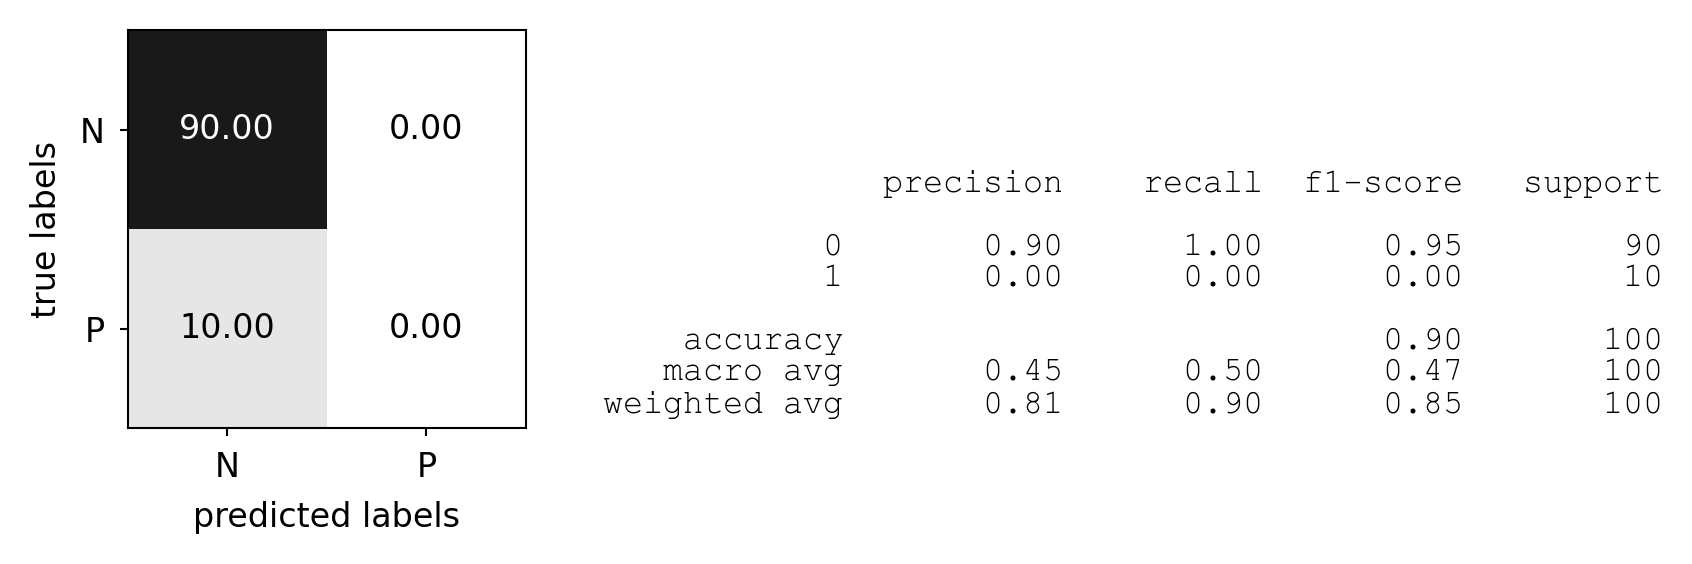

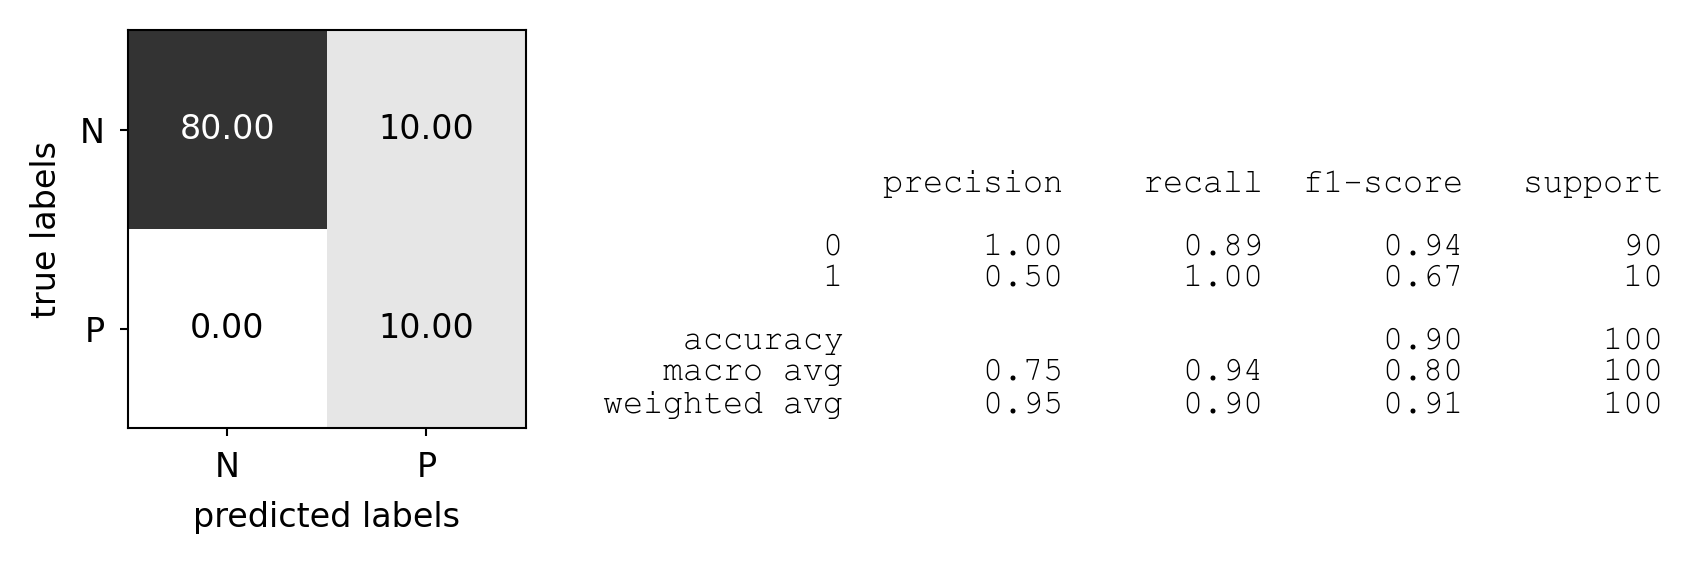

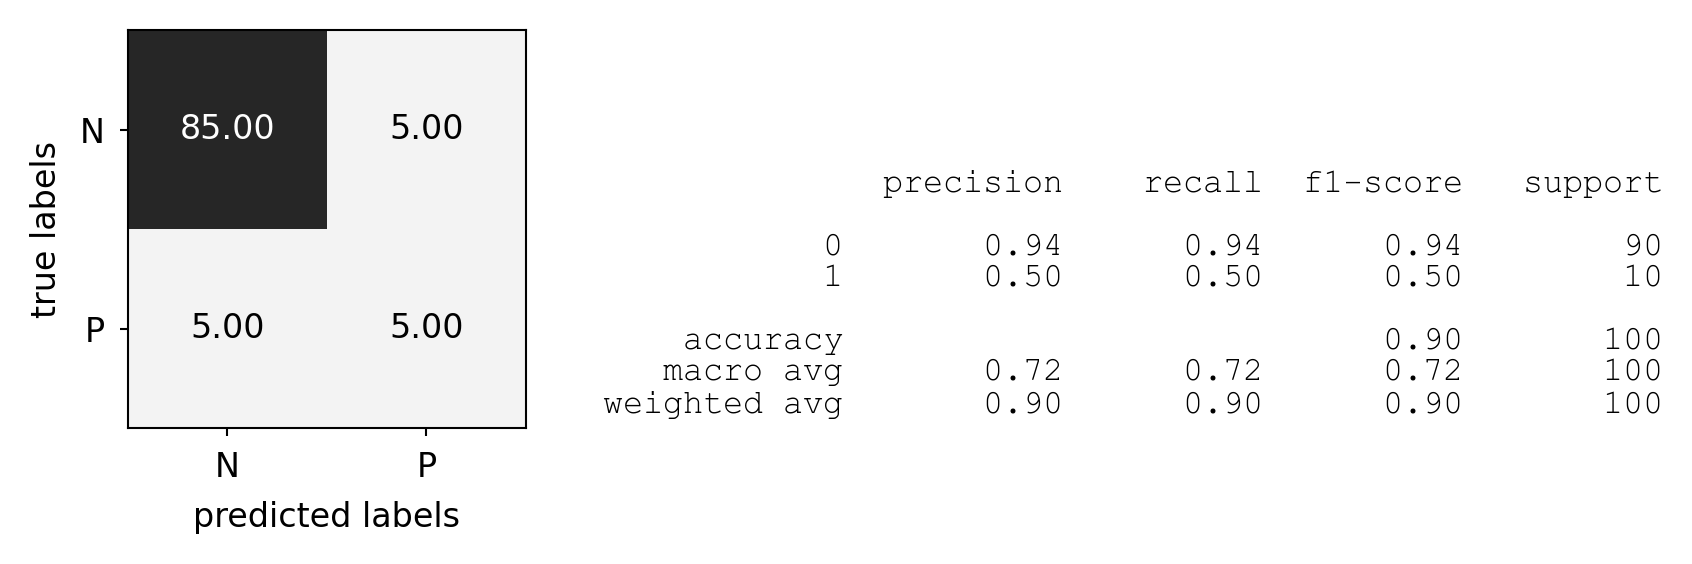

In [31]:
from sklearn.metrics import classification_report

def report(y_pred):
    fig = plt.figure()
    ax = plt.subplot(111)
    plot_confusion_matrix(confusion_matrix(y_true, y_pred), cmap='gray_r', ax=ax,
                          xticklabels=["N", "P"], yticklabels=["N", "P"], xtickrotation=0, vmin=0, vmax=100, fsize=2.5)
    ax.figure.set_size_inches(2*fig_scale, 2*fig_scale)
    plt.gcf().text(1.1, 0.2, classification_report(y_true, y_pred), fontsize=8, fontname="Courier New")

    plt.tight_layout()
report(y_pred_1)
report(y_pred_2)
report(y_pred_3)

### Other useful classification metrics
- Cohen's Kappa
    - Measures 'agreement' between different models (aka inter-rater agreement)
    - To evaluate a single model, compare it against a model that does random guessing
        - Similar to accuracy, but taking into account the possibility of predicting the right class by chance
    - Can be weighted: different misclassifications given different weights
    - 1: perfect prediction, 0: random prediction, negative: worse than random
    - With $p_0$ = accuracy, and $p_e$ = accuracy of random classifier:
        $$\kappa = \frac{p_o - p_e}{1 - p_e}$$
     to read more visit:https://pmc.ncbi.nlm.nih.gov/articles/PMC3900052/
- Matthews correlation coefficient
    - Corrects for imbalanced data, alternative for balanced accuracy or AUROC
    - 1: perfect prediction, 0: random prediction, -1: inverse prediction
        $$MCC = \frac{tp \times tn - fp \times fn}{\sqrt{(tp + fp)(tp + fn)(tn + fp)(tn + fn)}}$$
    - visit https://pmc.ncbi.nlm.nih.gov/articles/PMC6941312/ to compare MCC with f1 score

387 patients, 30 malignant (7.8%)
not malignant        TP= 0 FN=30 FP= 0 TN=357 | acc=0.92 F1=0.00 kappa=0.00 MCC=0.00
Random guess         TP= 5 FN=25 FP=35 TN=322 | acc=0.84 F1=0.14 kappa=0.06 MCC=0.06
Logistic regression  TP=28 FN= 2 FP= 0 TN=357 | acc=0.99 F1=0.97 kappa=0.96 MCC=0.96


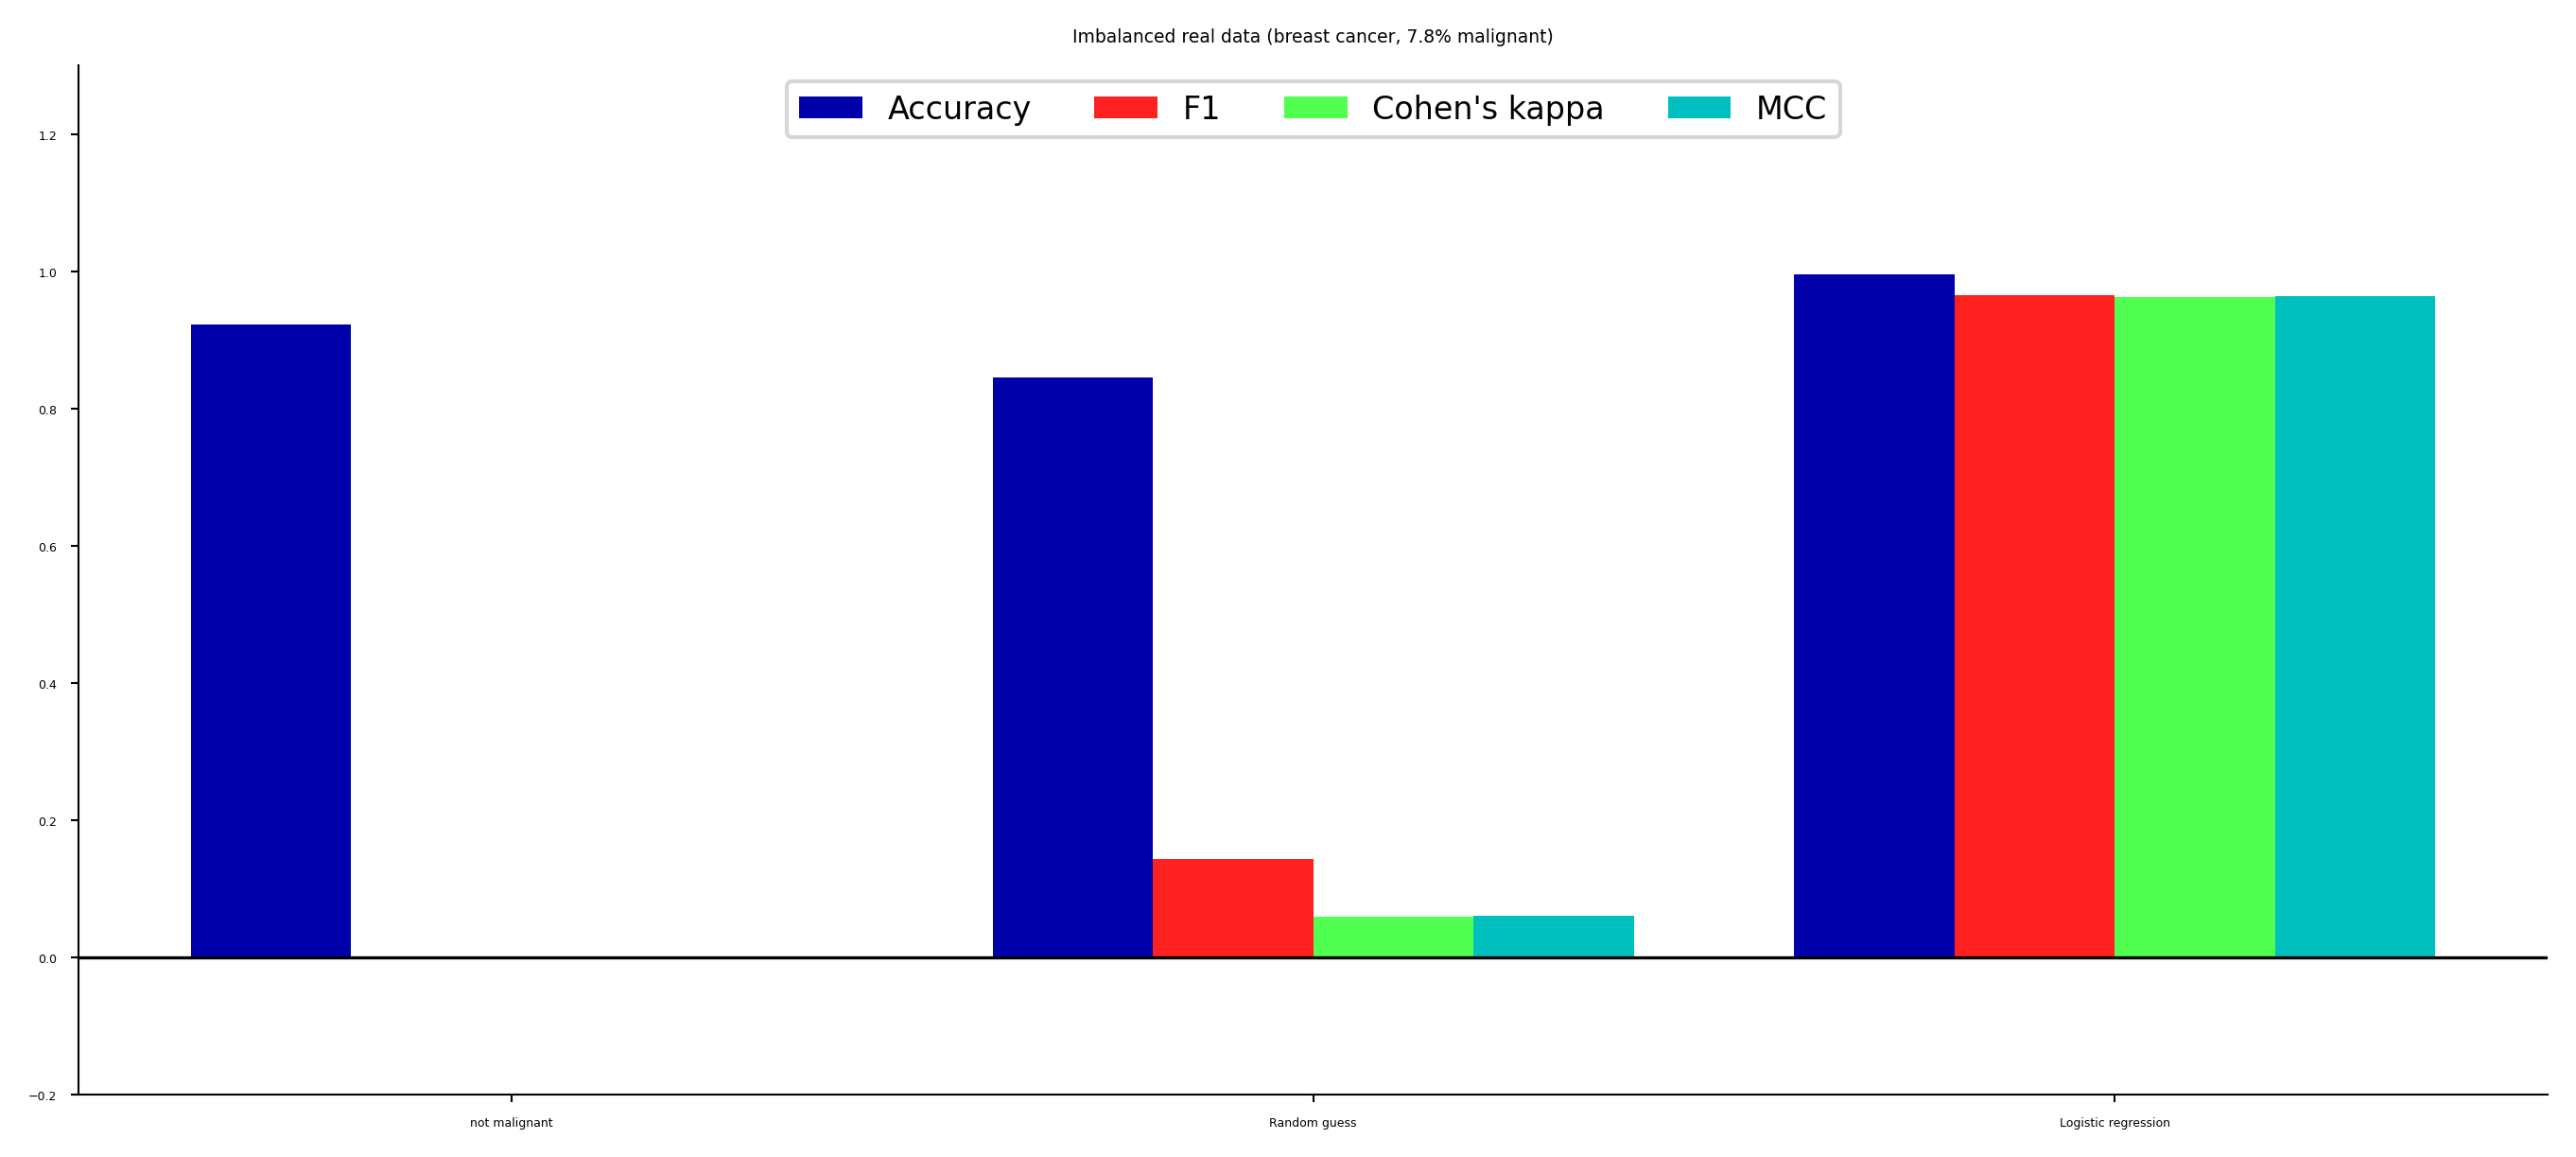

In [32]:
# switch the backend so plt.show() really draws under the cell
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             matthews_corrcoef, confusion_matrix)

data = load_breast_cancer()
rng = np.random.RandomState(0)
malignant = np.where(data.target == 0)[0]
benign = np.where(data.target == 1)[0]
keep = np.concatenate([benign, rng.choice(malignant, 30, replace=False)]) #made imbalanced by keeping only 30 malignant cases
X, y = data.data[keep], (data.target[keep] == 0).astype(int)      # y=1: malignant
print(f"{len(y)} patients, {y.sum()} malignant ({y.mean():.1%})")

models = {
    "not malignant":     DummyClassifier(strategy="most_frequent"),
    "Random guess":        DummyClassifier(strategy="stratified", random_state=0),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    # "Random forest":       RandomForestClassifier(random_state=0),
}

# Every model predicts every patient through 5-fold stratified cross-validation (no training on the patient being predicted)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for name, model in models.items():
    y_pred = cross_val_predict(model, X, y, cv=cv)
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    rows.append((name, accuracy_score(y, y_pred), f1_score(y, y_pred, zero_division=0),
                 cohen_kappa_score(y, y_pred), matthews_corrcoef(y, y_pred)))
    print(f"{name:20s} TP={tp:2d} FN={fn:2d} FP={fp:2d} TN={tn:3d} | acc={rows[-1][1]:.2f} "
          f"F1={rows[-1][2]:.2f} kappa={rows[-1][3]:.2f} MCC={rows[-1][4]:.2f}")

metrics = ["Accuracy", "F1", "Cohen's kappa", "MCC"]
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.2
for j, m in enumerate(metrics):
    ax.bar(np.arange(len(rows)) + (j - 1.5) * w, [r[j + 1] for r in rows], w, label=m)
ax.set_xticks(range(len(rows))); ax.set_xticklabels([r[0] for r in rows])
ax.axhline(0, color="k", lw=.8); ax.set_ylim(-0.2, 1.3); ax.legend(ncol=4, fontsize=8, loc="upper center")
ax.set_title("Imbalanced real data (breast cancer, 7.8% malignant)")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## Probabilistic evaluation
* Classifiers can often provide uncertainty estimates of predictions.
* Remember that linear models actually return a numeric value:

$$\hat{y} = w_0 x_0 + w_1 x_1 + \dots + w_p x_p + b$$

* When $\hat{y}<0$, predict class -1, otherwise predict class +1.
* In practice, you are often interested in how certain a classifier is about each class prediction (e.g. cancer treatments).
* Most learning methods can return at least one measure of _confidence_ in their predictions.
    - Decision function: floating point value for each sample (higher: more confident)
    - Probability: estimated probability for each class

### The decision function
In the binary classification case, the return value of the decision function encodes how strongly the model believes a data point 
belongs to the “positive” class.  
- Positive values indicate preference for the positive class. 
- The range can be arbitrary, and can be affected by hyperparameters. Hard to interpret.

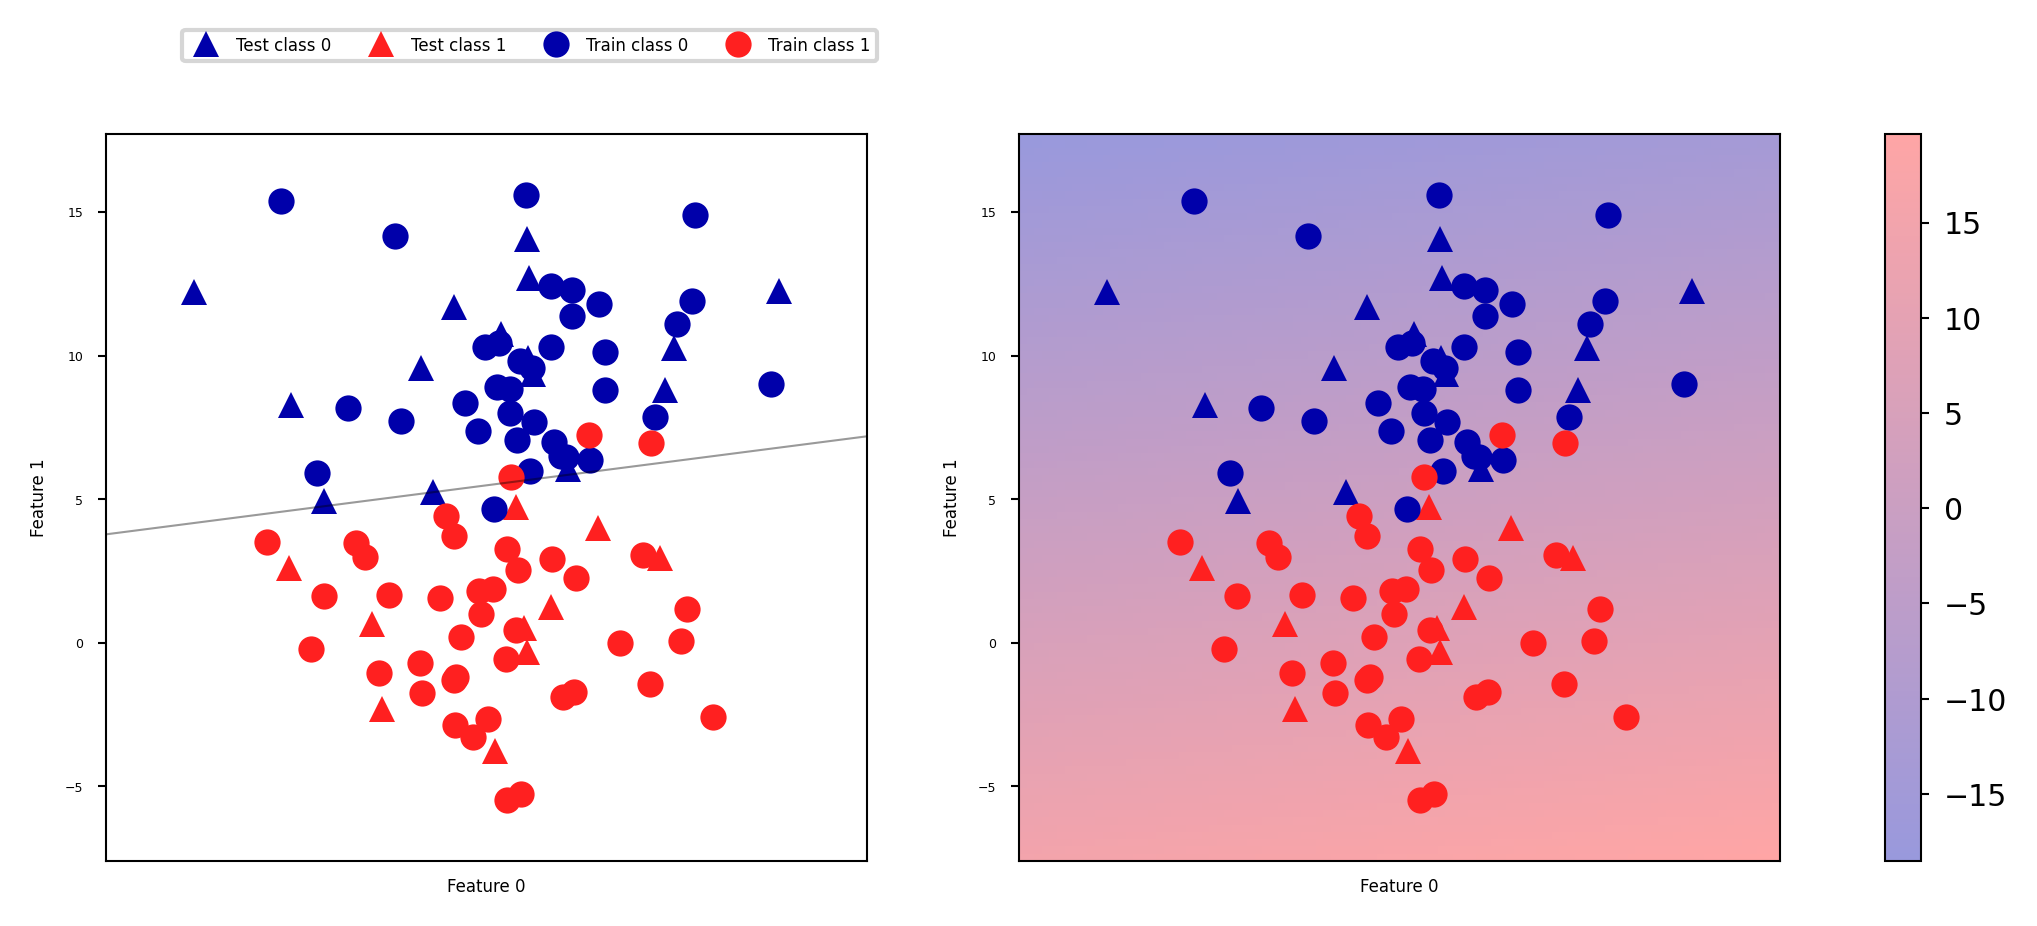

In [33]:
# create and split a synthetic dataset
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_blobs
Xs, ys = make_blobs(centers=2, cluster_std=2.5, random_state=8)

# we rename the classes "blue" and "red"
ys_named = np.array(["blue", "red"])[ys]

# we can call train test split with arbitrary many arrays
# all will be split in a consistent manner
Xs_train, Xs_test, ys_train_named, ys_test_named, ys_train, ys_test = \
    train_test_split(Xs, ys_named, ys, random_state=0)

# build the logistic regression model
lr = LogisticRegression()
lr.fit(Xs_train, ys_train_named)

fig, axes = plt.subplots(1, 2, figsize=(10*fig_scale, 3.5*fig_scale))
    
mglearn.tools.plot_2d_separator(lr, Xs, ax=axes[0], alpha=.4,
                                fill=False, cm=mglearn.cm2)
scores_image = mglearn.tools.plot_2d_scores(lr, Xs, ax=axes[1],
                                            alpha=.4, cm=mglearn.ReBl)

for ax in axes:
    # plot training and test points
    mglearn.discrete_scatter(Xs_test[:, 0], Xs_test[:, 1], ys_test,
                             markers='^', ax=ax, s=7*fig_scale)
    mglearn.discrete_scatter(Xs_train[:, 0], Xs_train[:, 1], ys_train,
                             markers='o', ax=ax, s=7*fig_scale)
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")
cbar = plt.colorbar(scores_image, ax=axes.tolist())
cbar.set_alpha(1)
cbar.ax.tick_params(labelsize=8*fig_scale)
axes[0].legend(["Test class 0", "Test class 1", "Train class 0",
                "Train class 1"], ncol=4, loc=(.1, 1.1));  

### Predicting probabilities
Some models can also return a _probability_ for each class with every prediction. These sum up to 1.
We can visualize them again. Note that the gradient looks different now.

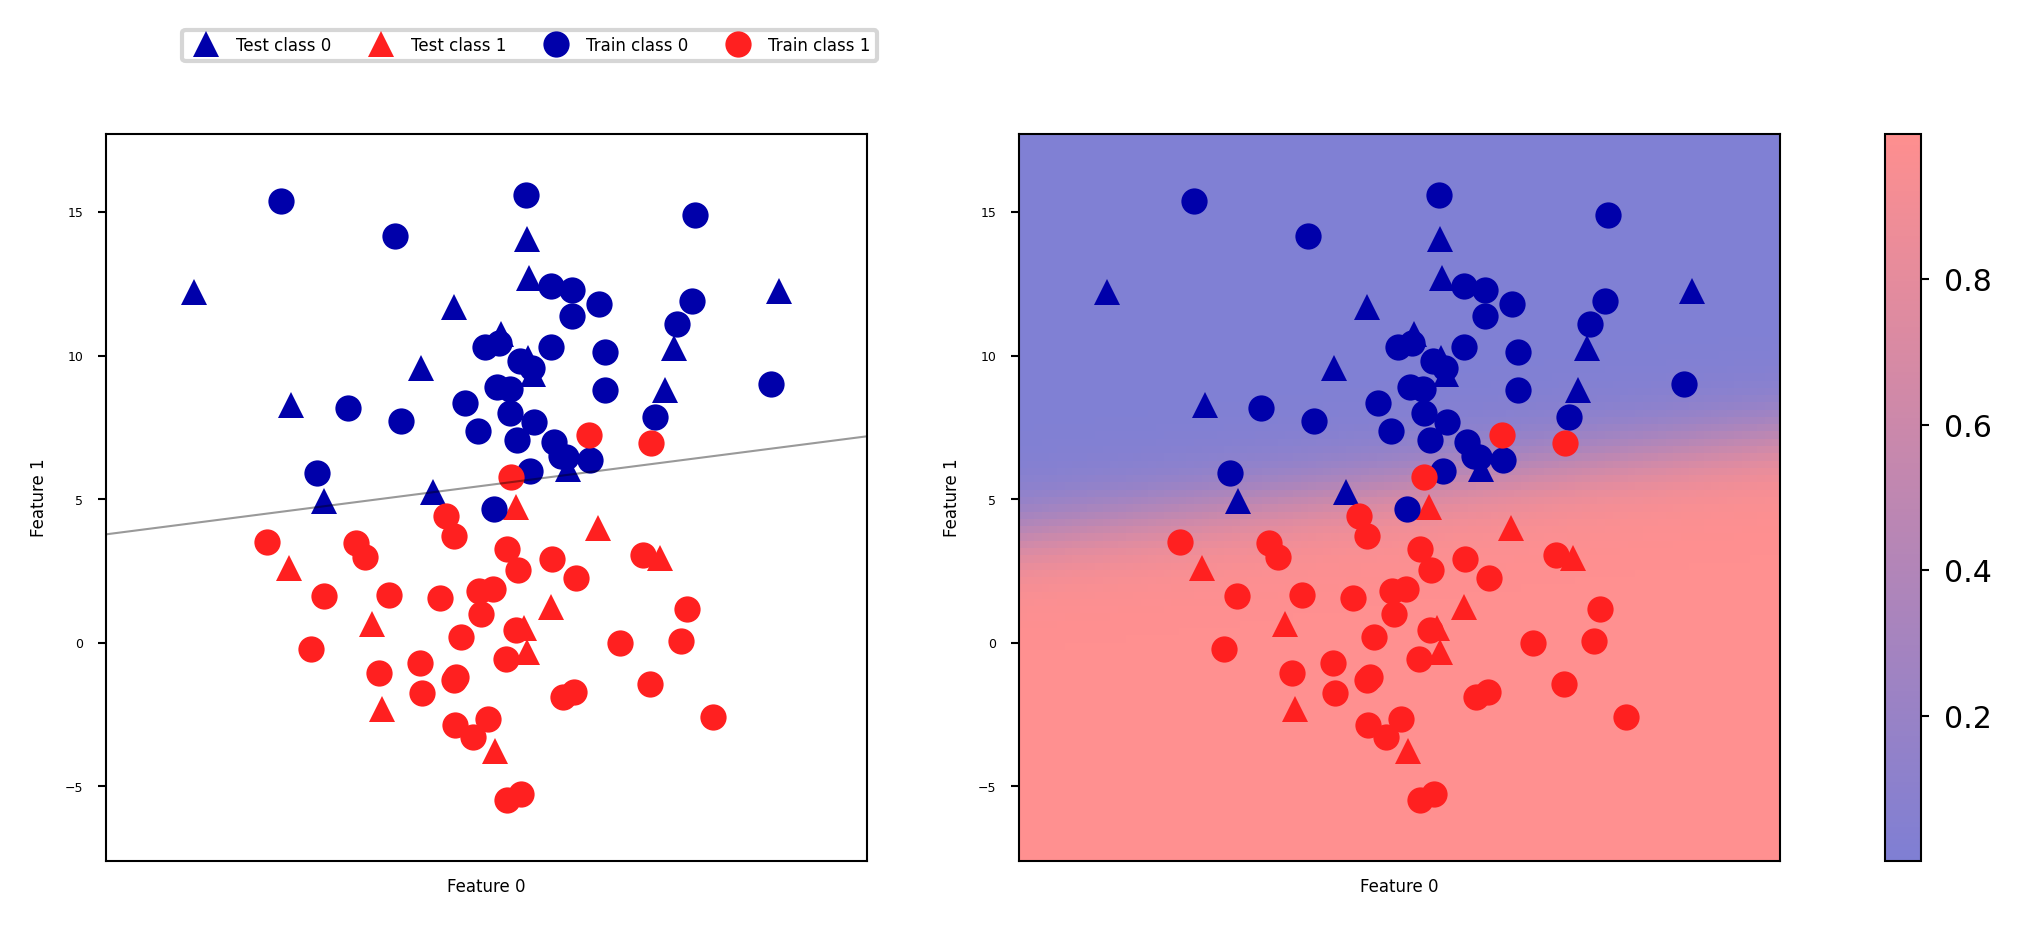

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10*fig_scale, 3.5*fig_scale))
    
mglearn.tools.plot_2d_separator(
    lr, Xs, ax=axes[0], alpha=.4, fill=False, cm=mglearn.cm2)
scores_image = mglearn.tools.plot_2d_scores(
    lr, Xs, ax=axes[1], alpha=.5, cm=mglearn.ReBl, function='predict_proba')

for ax in axes:
    # plot training and test points
    mglearn.discrete_scatter(Xs_test[:, 0], Xs_test[:, 1], ys_test,
                             markers='^', ax=ax, s=7*fig_scale)
    mglearn.discrete_scatter(Xs_train[:, 0], Xs_train[:, 1], ys_train,
                             markers='o', ax=ax, s=7*fig_scale)
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")
# don't want a transparent colorbar
cbar = plt.colorbar(scores_image, ax=axes.tolist())
cbar.set_alpha(1)
cbar.ax.tick_params(labelsize=8*fig_scale)
axes[0].legend(["Test class 0", "Test class 1", "Train class 0",
                "Train class 1"], ncol=4, loc=(.1, 1.1));

### Threshold calibration

- By default, we threshold at 0 for  `decision_function` and 0.5 for `predict_proba`
- Depending on the application, you may want to threshold differently
    - Lower threshold yields fewer FN (better recall), more FP (worse precision), and vice-versa

interactive(children=(FloatSlider(value=2.220446049250313e-16, description='threshold', max=1.3, min=-1.2), Ou…

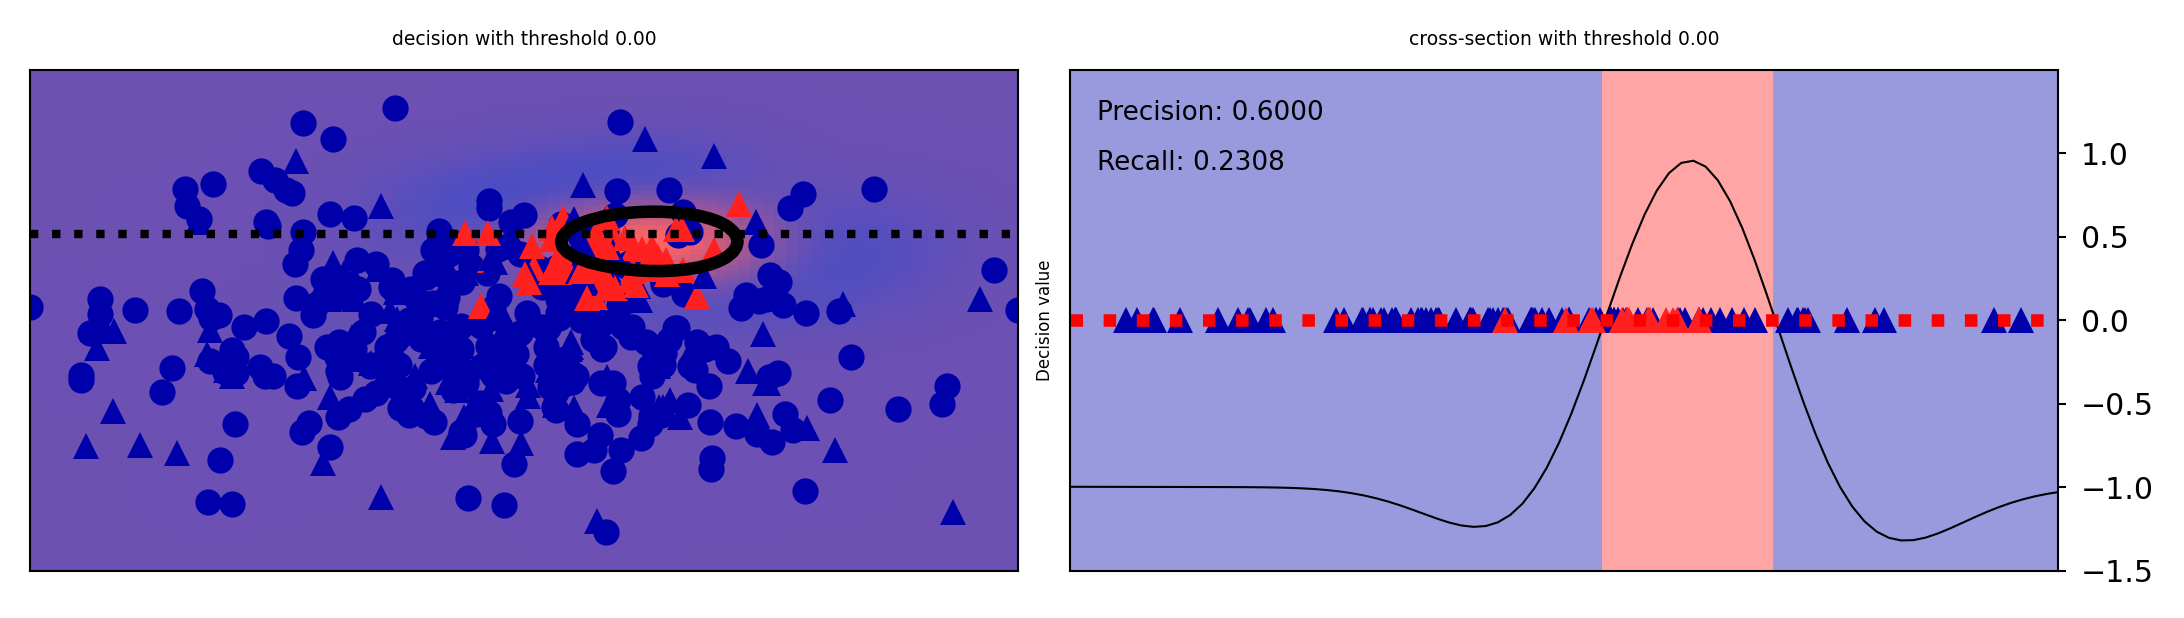

In [8]:
from mglearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from mglearn.tools import plot_2d_separator, plot_2d_scores, cm, discrete_scatter
import ipywidgets as widgets
from ipywidgets import interact, interact_manual

Xs, ys = make_blobs(n_samples=(400, 50), centers=2, cluster_std=[7.0, 2],
                    random_state=22)
Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, stratify=ys, random_state=0)
svc1 = SVC(gamma=.04).fit(Xs_train, ys_train)
    
    
@interact
def plot_decision_threshold(threshold=(-1.2,1.3,0.1)):
    fig, axes = plt.subplots(1, 2, figsize=(8*fig_scale, 2.2*fig_scale), subplot_kw={'xticks': (), 'yticks': ()})    
    line = np.linspace(Xs_train.min(), Xs_train.max(), 100)

    axes[0].set_title("decision with threshold {:.2f}".format(threshold))
    discrete_scatter(Xs_train[:, 0], Xs_train[:, 1], ys_train, ax=axes[0], s=7*fig_scale)
    discrete_scatter(Xs_test[:, 0], Xs_test[:, 1], ys_test, ax=axes[0], markers='^', s=7*fig_scale)

    plot_2d_scores(svc1, Xs_train, function="decision_function", alpha=.7,
                   ax=axes[0], cm=mglearn.ReBl)
    plot_2d_separator(svc1, Xs_train, linewidth=3, ax=axes[0], threshold=threshold)
    axes[0].set_xlim(Xs_train[:, 0].min(), Xs_train[:, 0].max())
    axes[0].plot(line, np.array([10 for i in range(len(line))]), 'k:', linewidth=2)

    axes[1].set_title("cross-section with threshold {:.2f}".format(threshold))
    axes[1].plot(line, svc1.decision_function(np.c_[line, 10 * np.ones(100)]), c='k')
    dec = svc1.decision_function(np.c_[line, 10 * np.ones(100)])
    contour = (dec > threshold).reshape(1, -1).repeat(10, axis=0)
    axes[1].contourf(line, np.linspace(-1.5, 1.5, 10), contour, linewidth=2, alpha=0.4, cmap=cm)
    discrete_scatter(Xs_test[:, 0], Xs_test[:, 1]*0, ys_test, ax=axes[1], markers='^', s=7*fig_scale)

    axes[1].plot(line, np.array([threshold for i in range(len(line))]), 'r:', linewidth=3)
    axes[1].tick_params(labelsize=8*fig_scale)
    
    axes[0].set_xlim(Xs_train[:, 0].min(), Xs_train[:, 0].max())
    axes[1].set_xlim(Xs_train[:, 0].min(), Xs_train[:, 0].max())
    axes[1].set_ylim(-1.5, 1.5)
    axes[1].set_xticks(())
    axes[1].set_yticks(np.arange(-1.5, 1.5, 0.5))
    axes[1].yaxis.tick_right()
    axes[1].set_ylabel("Decision value")
    
    y_pred = svc1.decision_function(Xs_test)
    y_pred = y_pred > threshold
    axes[1].text(Xs_train.min()+1,1.2,"Precision: {:.4f}".format(precision_score(ys_test,y_pred)), size=7*fig_scale)
    axes[1].text(Xs_train.min()+1,0.9,"Recall: {:.4f}".format(recall_score(ys_test,y_pred)), size=7*fig_scale)
    plt.tight_layout();

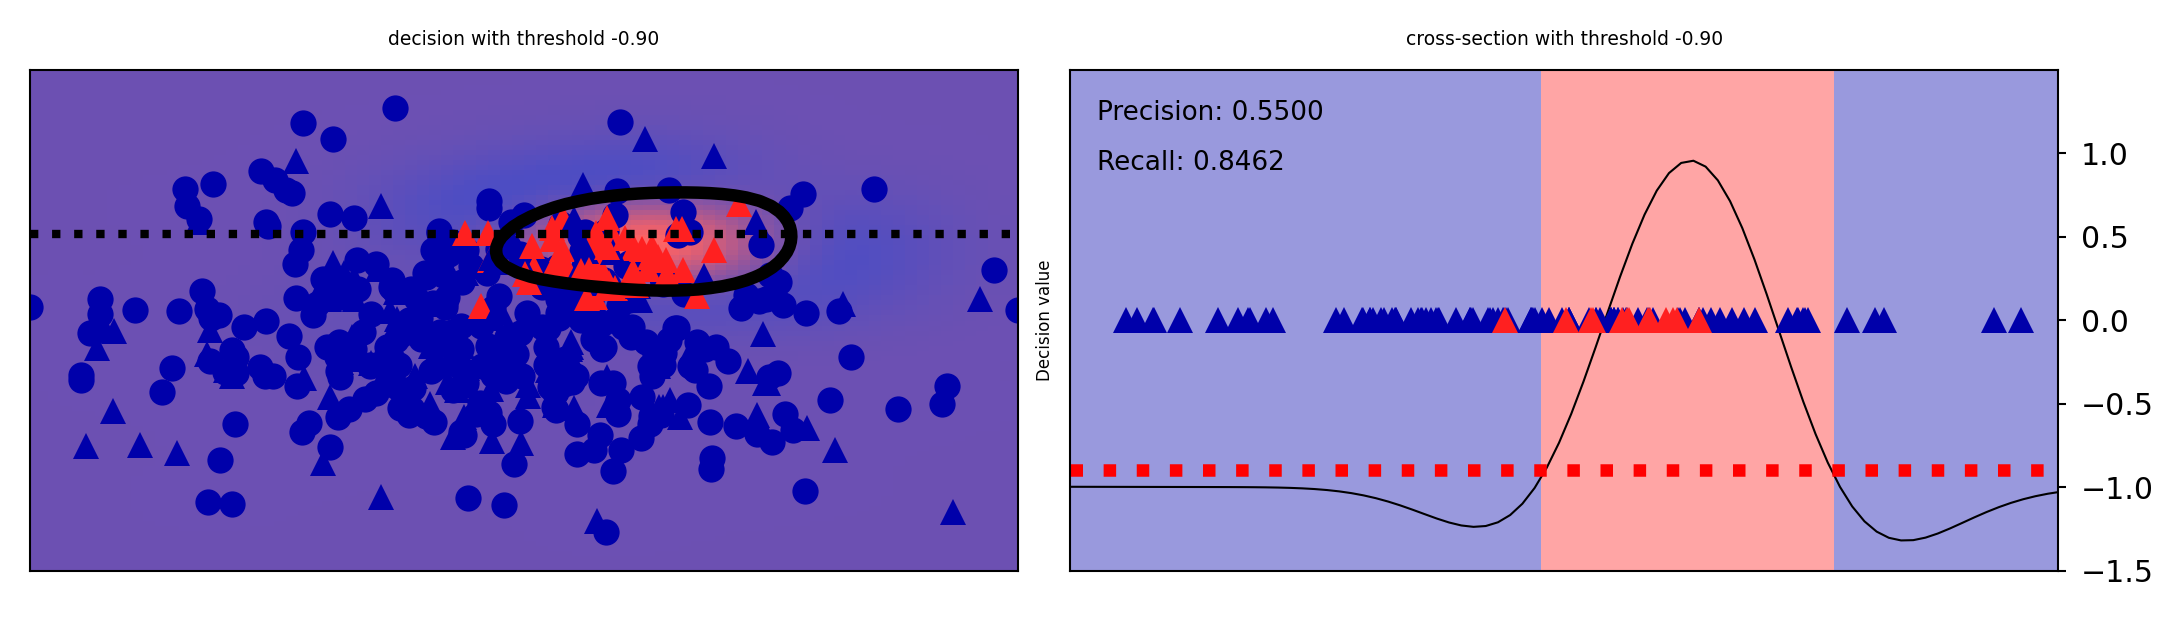

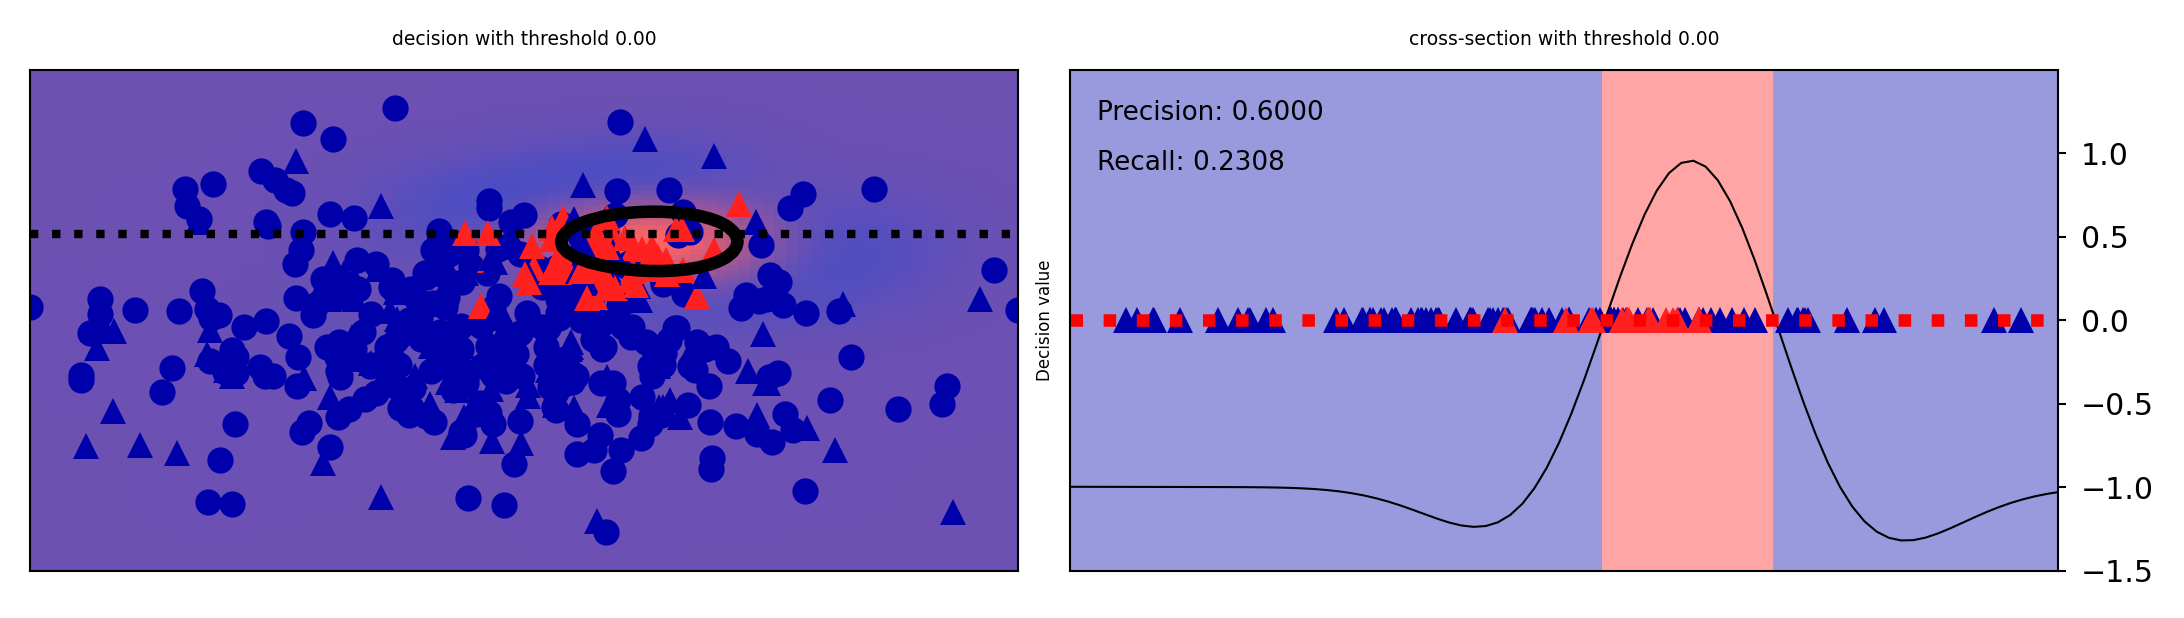

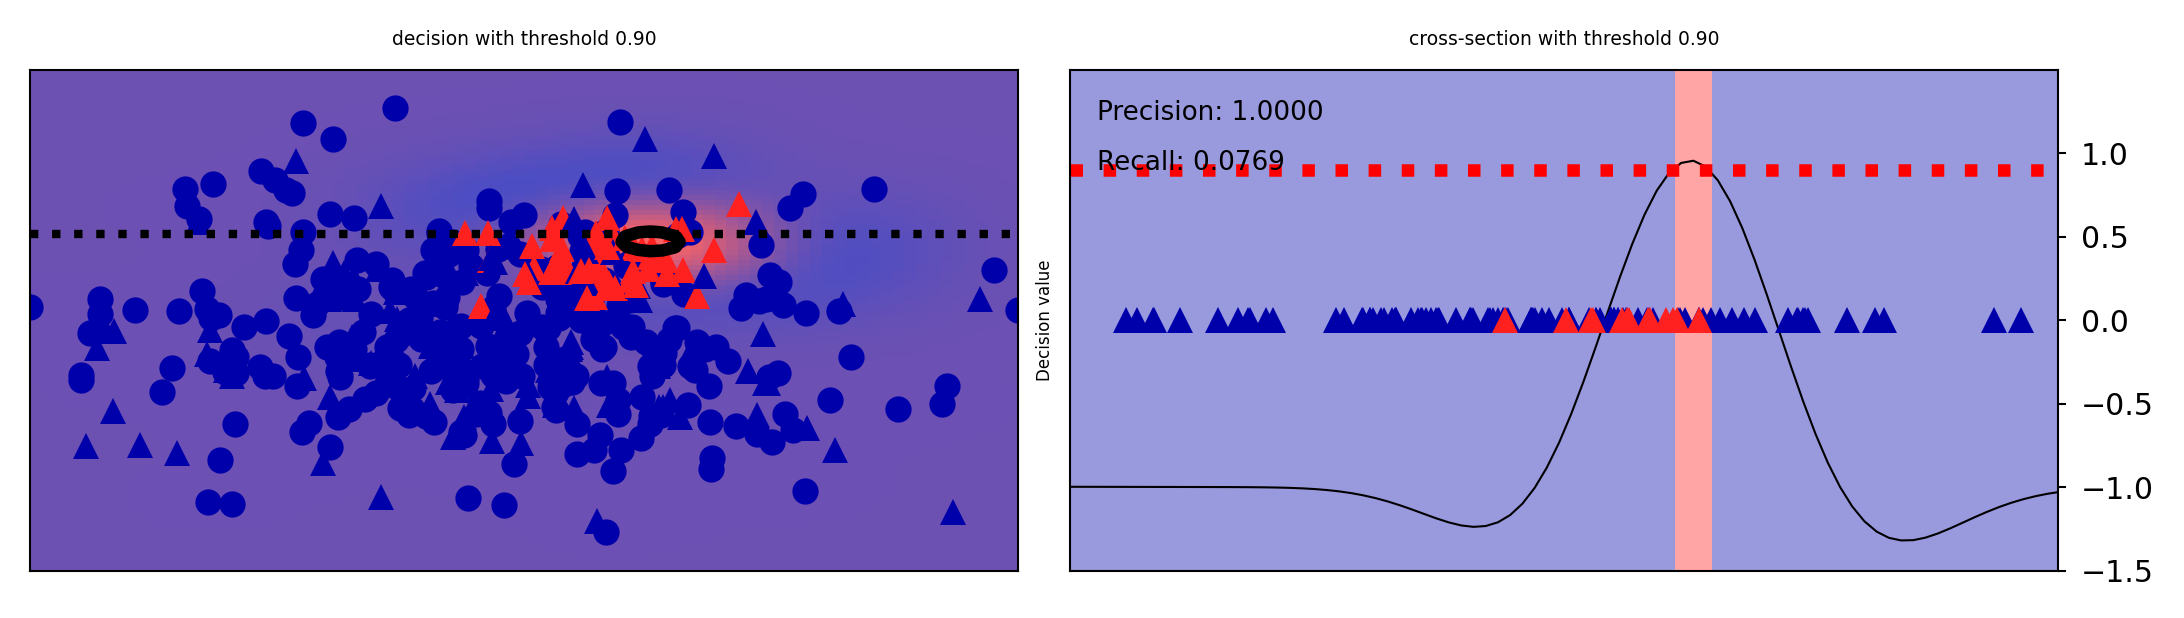

In [11]:
interactive = False
if not interactive:
    plot_decision_threshold(-0.9)
    plot_decision_threshold(0)
    plot_decision_threshold(0.9)
interactive = True


### What happens when we change the decision threshold?

Suppose a medical classification model produces the following probabilities.

Instead of always using the default threshold of 0.5, we can choose a different threshold depending on the application.

Let's compare thresholds of 0.5 and 0.3.

Remember:

- Lower threshold → more positive predictions.
- More positive predictions → usually higher recall and lower precision.
- Higher threshold → fewer positive predictions.
- Fewer positive predictions → usually higher precision and lower recall.


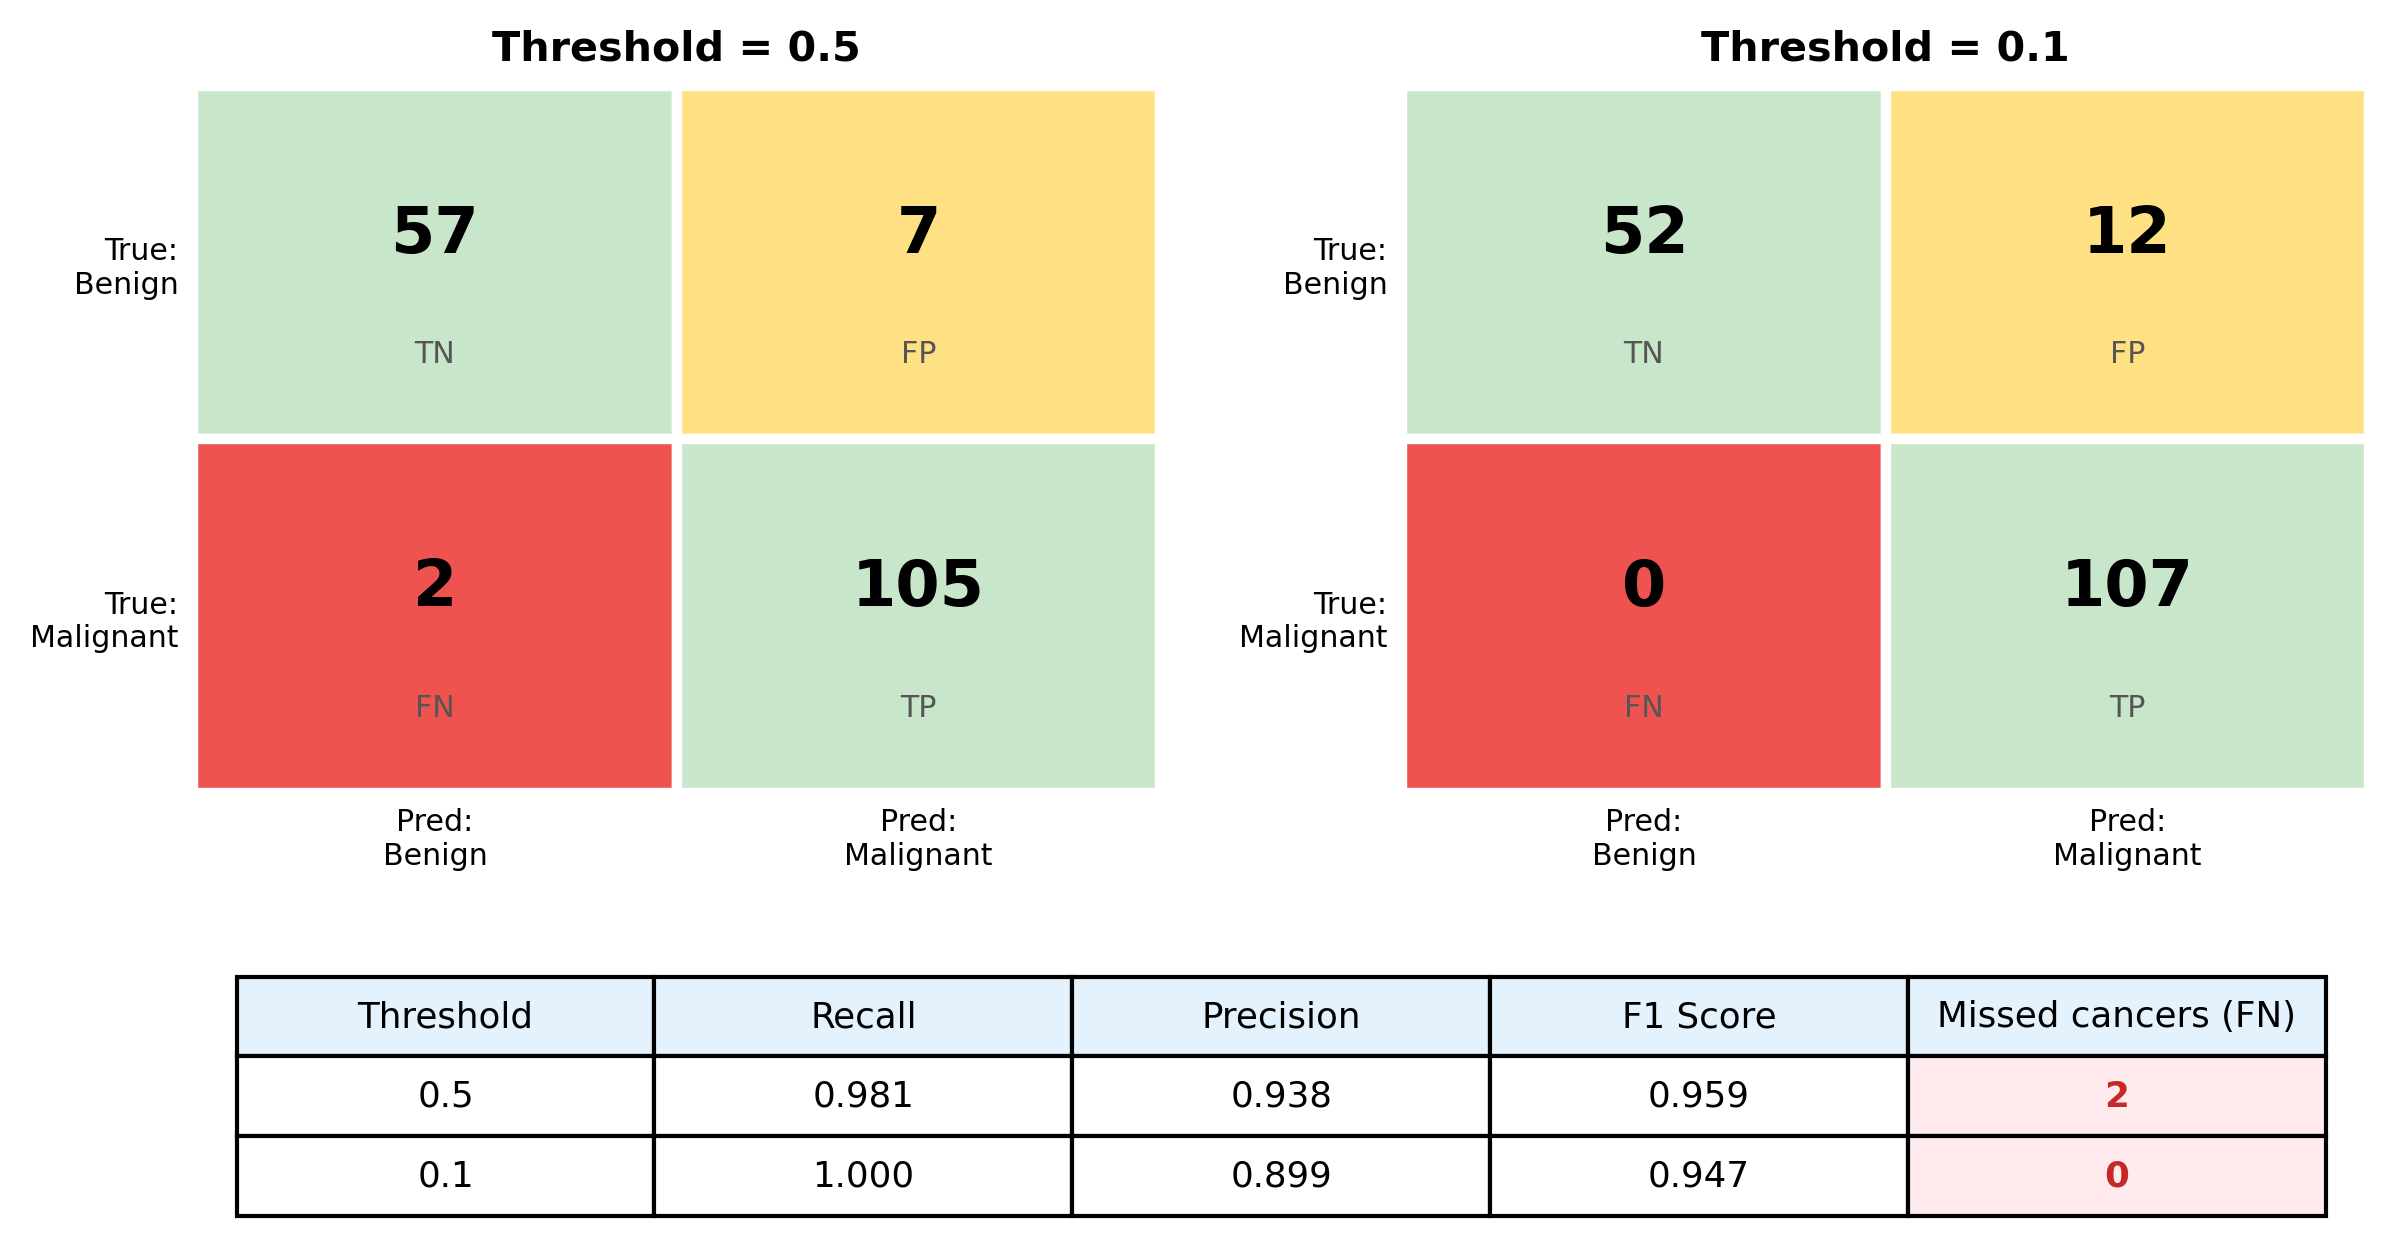

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix


data = load_breast_cancer()
# The dataset encodes 0=malignant (positive class), 1=benign (negative class)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

model = LogisticRegression(max_iter=5000, random_state=42)
model.fit(X_train, y_train)


y_probs = model.predict_proba(X_test)[:, 1]


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.metrics import (
    confusion_matrix, recall_score, precision_score, f1_score
)

def plot_threshold_comparison(y_true, y_probs, thresholds=(0.5, 0.3)):
    n = len(thresholds)

    fig = plt.figure(figsize=(5.2 * n * fig_scale, 5.5 * fig_scale))
    gs = fig.add_gridspec(2, n, height_ratios=[3.2, 1.2],
                          hspace=0.35, wspace=0.25)

    cell_colors = {(0, 0): '#c8e6c9',   # TN  
                   (0, 1): '#ffe082',   # FP  
                   (1, 0): '#ef5350',   # FN  
                   (1, 1): '#c8e6c9'}   # TP  
    cell_tags   = {(0, 0): 'TN', (0, 1): 'FP',
                   (1, 0): 'FN', (1, 1): 'TP'}

    all_metrics = []

    #  one confusion matrix per threshold 
    for k, t in enumerate(thresholds):
        y_pred = (y_probs >= t).astype(int)
        cm = confusion_matrix(y_true, y_pred)
        tn, fp, fn, tp = cm.ravel()

        all_metrics.append(dict(
            threshold=t,
            recall=recall_score(y_true, y_pred),
            precision=precision_score(y_true, y_pred),
            f1=f1_score(y_true, y_pred),
            fn=fn,
        ))

        ax = fig.add_subplot(gs[0, k])
        for (i, j), color in cell_colors.items():
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1,
                                   facecolor=color, edgecolor='white', lw=2.5))
            ax.text(j, i - 0.08, str(cm[i, j]),
                    ha='center', va='center',
                    fontsize=17 * fig_scale, fontweight='bold')
            ax.text(j, i + 0.26, cell_tags[(i, j)],
                    ha='center', va='center',
                    fontsize=8 * fig_scale, color='#555')

        ax.set(xlim=(-0.5, 1.5), ylim=(1.5, -0.5))
        ax.set_xticks([0, 1]);  ax.set_yticks([0, 1])
        ax.set_xticklabels(['Pred:\nBenign', 'Pred:\nMalignant'],
                           fontsize=8 * fig_scale)
        ax.set_yticklabels(['True:\nBenign', 'True:\nMalignant'],
                           fontsize=8 * fig_scale, rotation=0)
        ax.tick_params(length=0)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title(f'Threshold = {t}',
                     fontsize=11 * fig_scale, fontweight='bold')

    # comparison table
    ax_t = fig.add_subplot(gs[1, :])
    ax_t.axis('off')

    headers = ['Threshold', 'Recall', 'Precision', 'F1 Score', 'Missed cancers (FN)']
    rows = [[f'{m["threshold"]}',
             f'{m["recall"]:.3f}',
             f'{m["precision"]:.3f}',
             f'{m["f1"]:.3f}',
             f'{m["fn"]}'] for m in all_metrics]

    table = ax_t.table(cellText=rows, colLabels=headers,
                       loc='center', cellLoc='center',
                       colColours=['#e3f2fd'] * len(headers),
                       bbox=[0.02, 0.05, 0.96, 0.9])
    table.auto_set_font_size(False)
    table.set_fontsize(9.5 * fig_scale)

    # Highlight the FN column : clinically critical number
    for r in range(1, len(rows) + 1):
        cell = table[(r, 4)]
        cell.set_facecolor('#ffebee')
        cell.set_text_props(color='#c62828', fontweight='bold')

    plt.show()
    return fig

# Compare the two thresholds
plot_threshold_comparison(y_test, y_probs, [0.5, 0.1], );

### Precision-Recall curve
- The best trade-off between precision and recall depends on your application
    - You can have arbitrary high recall, but you often want reasonable precision, too.
- Plotting precision against recall _for all possible thresholds_ yields a __precision-recall curve__
    - Change the threshold until you find a sweet spot in the precision-recall trade-off
    - Often jagged at high thresholds, when there are few positive examples left

interactive(children=(FloatSlider(value=-0.9899999999999998, description='threshold', max=1.4, min=-3.19), Dro…

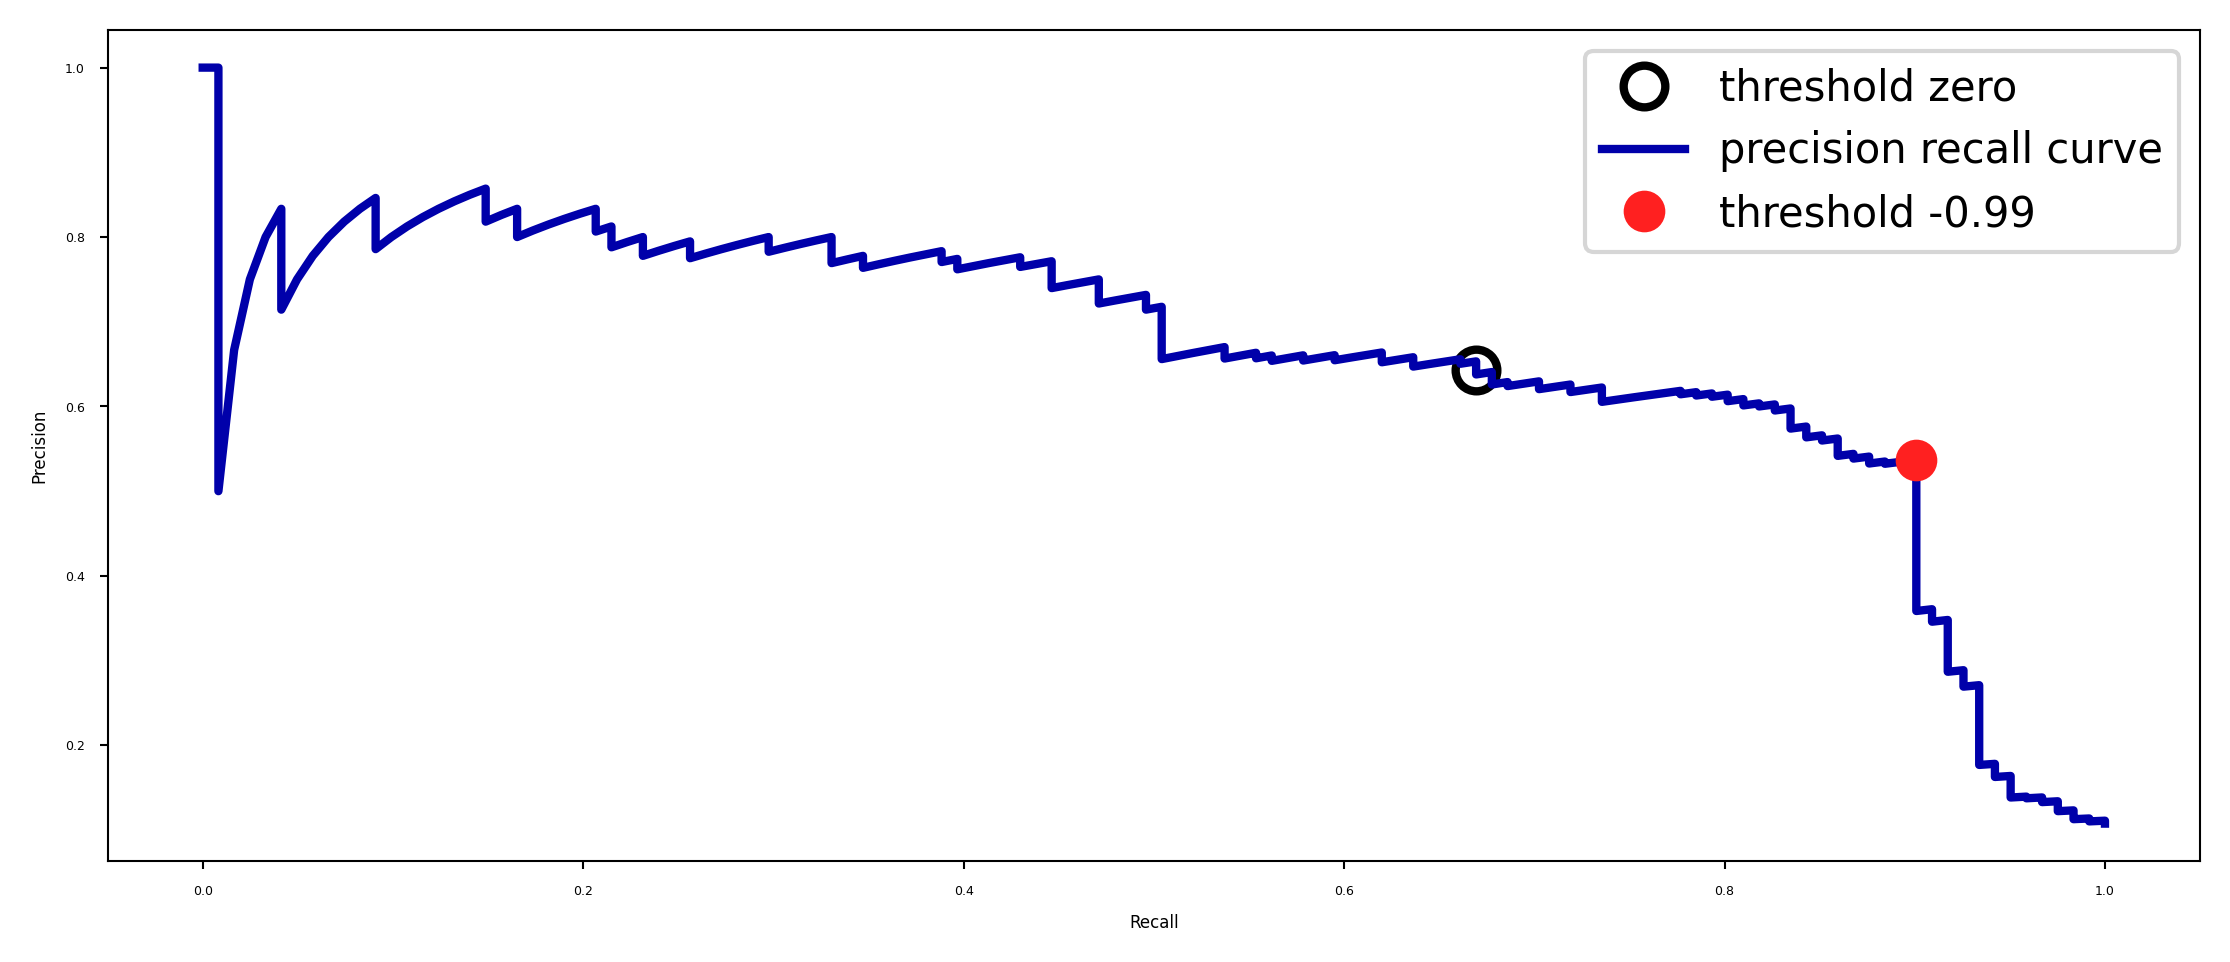

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve
from sklearn.svm import SVC

# create a similar dataset as before, but with more samples
# to get a smoother curve
rng = np.random.RandomState(22)
centers = rng.uniform(-10, 10, size=(2, 2))
Xp, yp = make_blobs(n_samples=(4000, 500), centers=centers,
                    cluster_std=[7.0, 2], random_state=rng)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, yp, random_state=0)
svc2 = SVC(gamma=.05).fit(Xp_train, yp_train)
rf2 = RandomForestClassifier(n_estimators=100 ,random_state=0).fit(Xp_train, yp_train)

@interact
def plot_PR_curve(threshold=(-3.19,1.4,0.1), model=[svc2, rf2]):
    if hasattr(model, "predict_proba"):
        precision, recall, thresholds = precision_recall_curve(
            yp_test, model.predict_proba(Xp_test)[:, 1])
    else:
        precision, recall, thresholds = precision_recall_curve(
            yp_test, model.decision_function(Xp_test))
    # find existing threshold closest to zero
    close_zero = np.argmin(np.abs(thresholds))
    plt.figure(figsize=(10*fig_scale,4*fig_scale))
    plt.plot(recall[close_zero], precision[close_zero], 'o', markersize=10,
             label="threshold zero", fillstyle="none", c='k', mew=2)
    plt.plot(recall, precision, lw=2, label="precision recall curve")

    if hasattr(model, "predict_proba"):
        yp_pred = model.predict_proba(Xp_test)[:, 1] > threshold
    else:
        yp_pred = model.decision_function(Xp_test) > threshold
    plt.plot(recall_score(yp_test,yp_pred), precision_score(yp_test,yp_pred), 'o', markersize=10, label="threshold {:.2f}".format(threshold))

    plt.ylabel("Precision")
    plt.xlabel("Recall")
    plt.legend(loc="best", prop={"size":10});

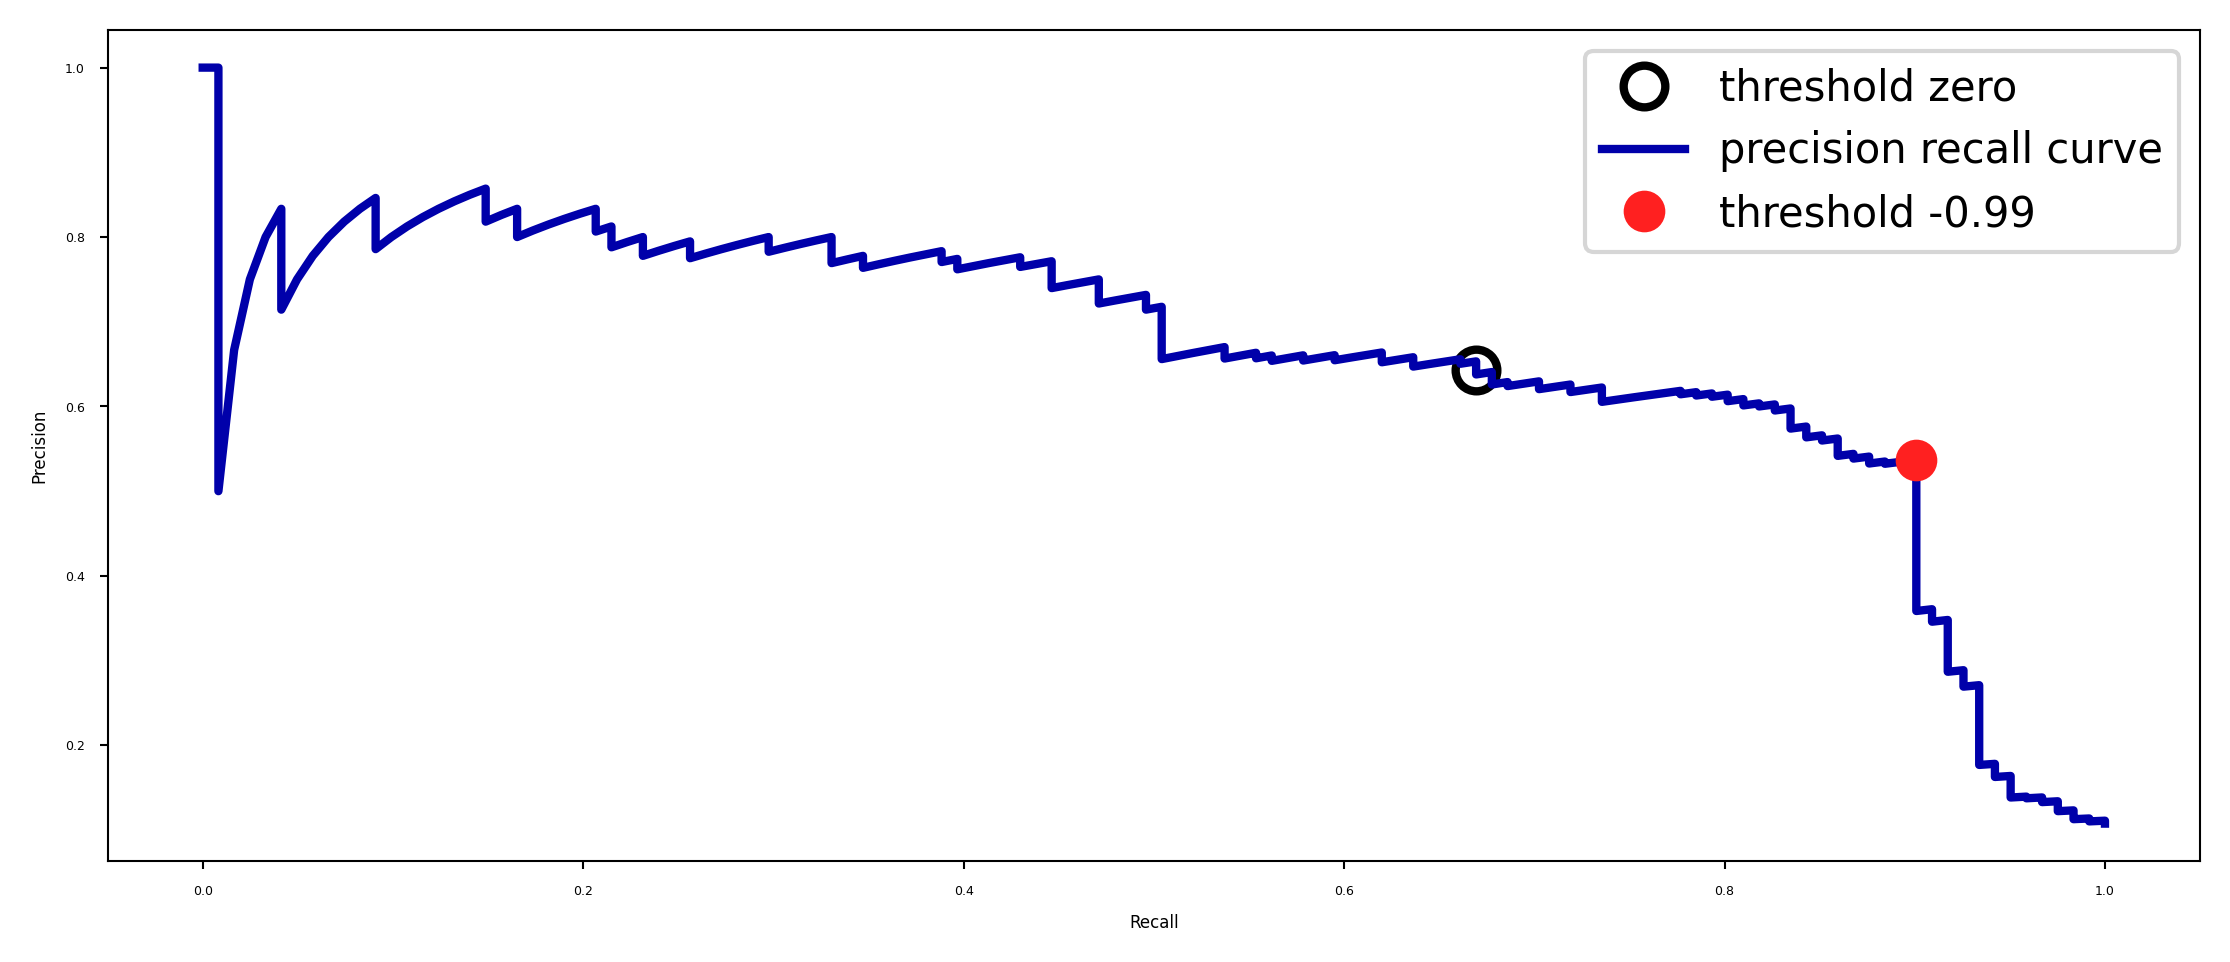

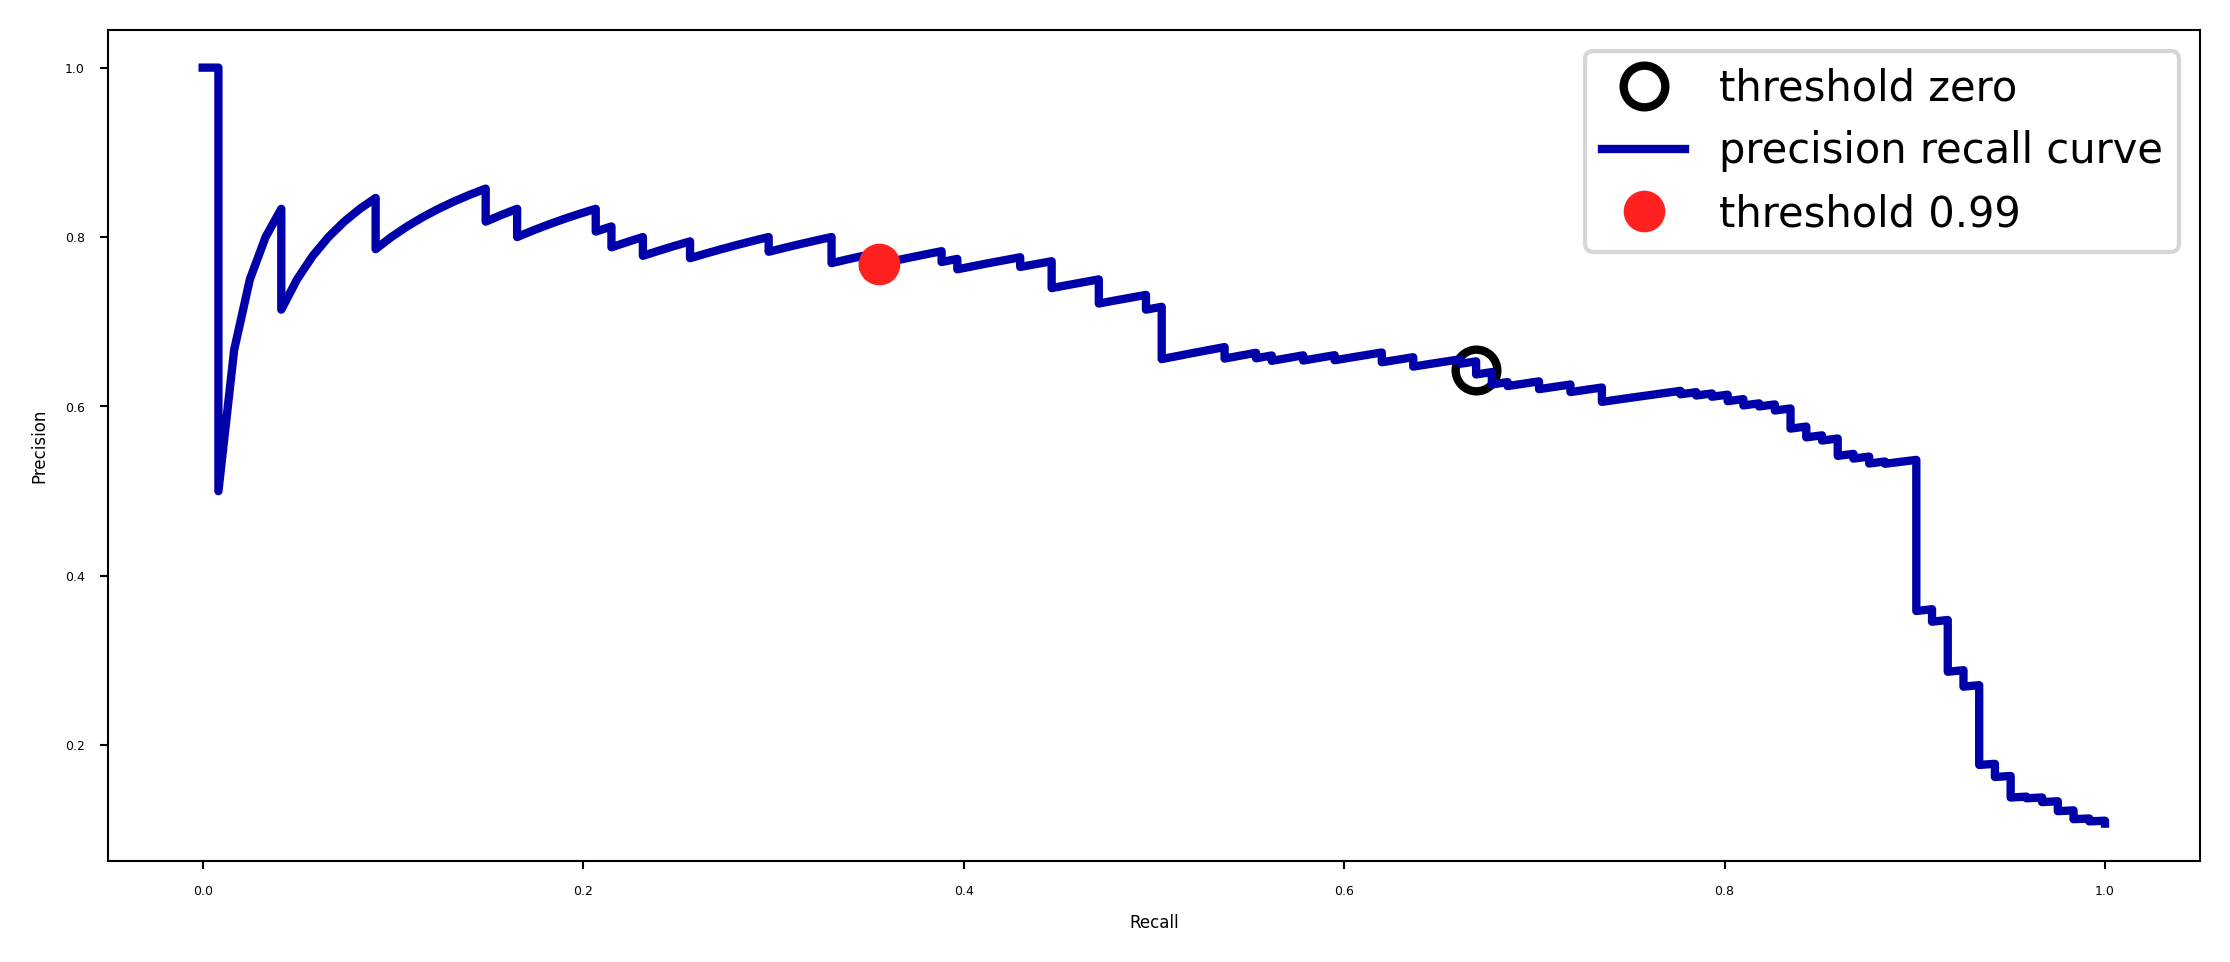

In [14]:
interactive = False
if not interactive:
    plot_PR_curve(threshold=-0.99,model=svc2)
    plot_PR_curve(threshold=0.99,model=svc2)
interactive = True

#### Model selection
- Some models can achieve trade-offs that others can't
- Your application may require very high recall (or very high precision)
    - Choose the model that offers the best trade-off, given your application
- The area under the PR curve (AUPRC) gives the _best overall_ model

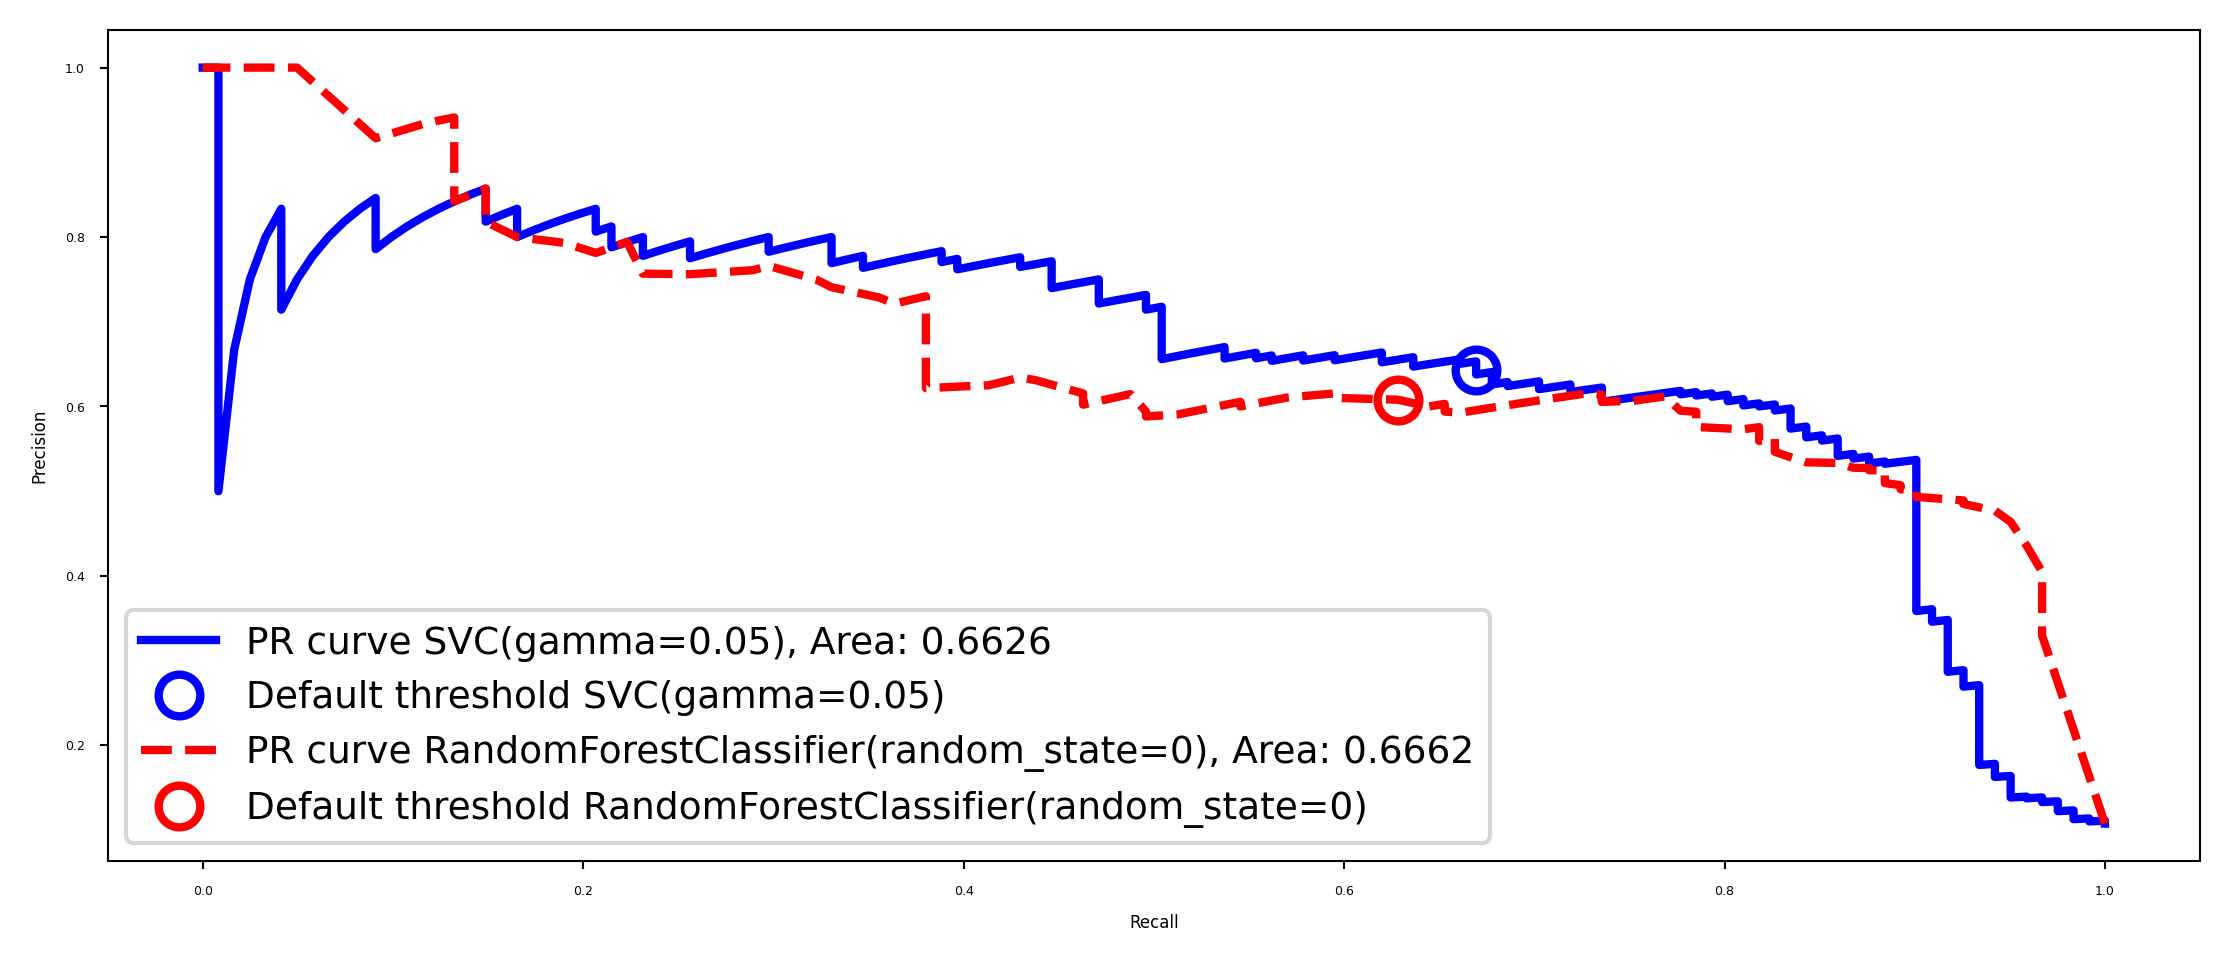

In [36]:
from sklearn.metrics import auc
colors=['b','r','g','y']

def plot_PR_curves(models):
    
    plt.figure(figsize=(10*fig_scale,4*fig_scale))
    for i, model in enumerate(models):
        if hasattr(model, "predict_proba"):
            precision, recall, thresholds = precision_recall_curve(
                yp_test, model.predict_proba(Xp_test)[:, 1])
            close_zero = np.argmin(np.abs(thresholds-0.5))
        else:
            precision, recall, thresholds = precision_recall_curve(
                yp_test, model.decision_function(Xp_test))
            close_zero = np.argmin(np.abs(thresholds))
          
        plt.plot(recall, precision, lw=2, c=colors[i], label="PR curve {}, Area: {:.4f}".format(model, auc(recall, precision))) 
        plt.plot(recall[close_zero], precision[close_zero], 'o', markersize=10,
                 fillstyle="none", c=colors[i], mew=2, label="Default threshold {}".format(model))
        plt.ylabel("Precision")
        plt.xlabel("Recall")
        plt.legend(loc="lower left", prop={"size":9});
        
#svc2 = SVC(gamma=0.01).fit(X_train, y_train)
plot_PR_curves([svc2, rf2])

#### Hyperparameter effects
Of course, hyperparameters affect predictions and hence also the shape of the curve

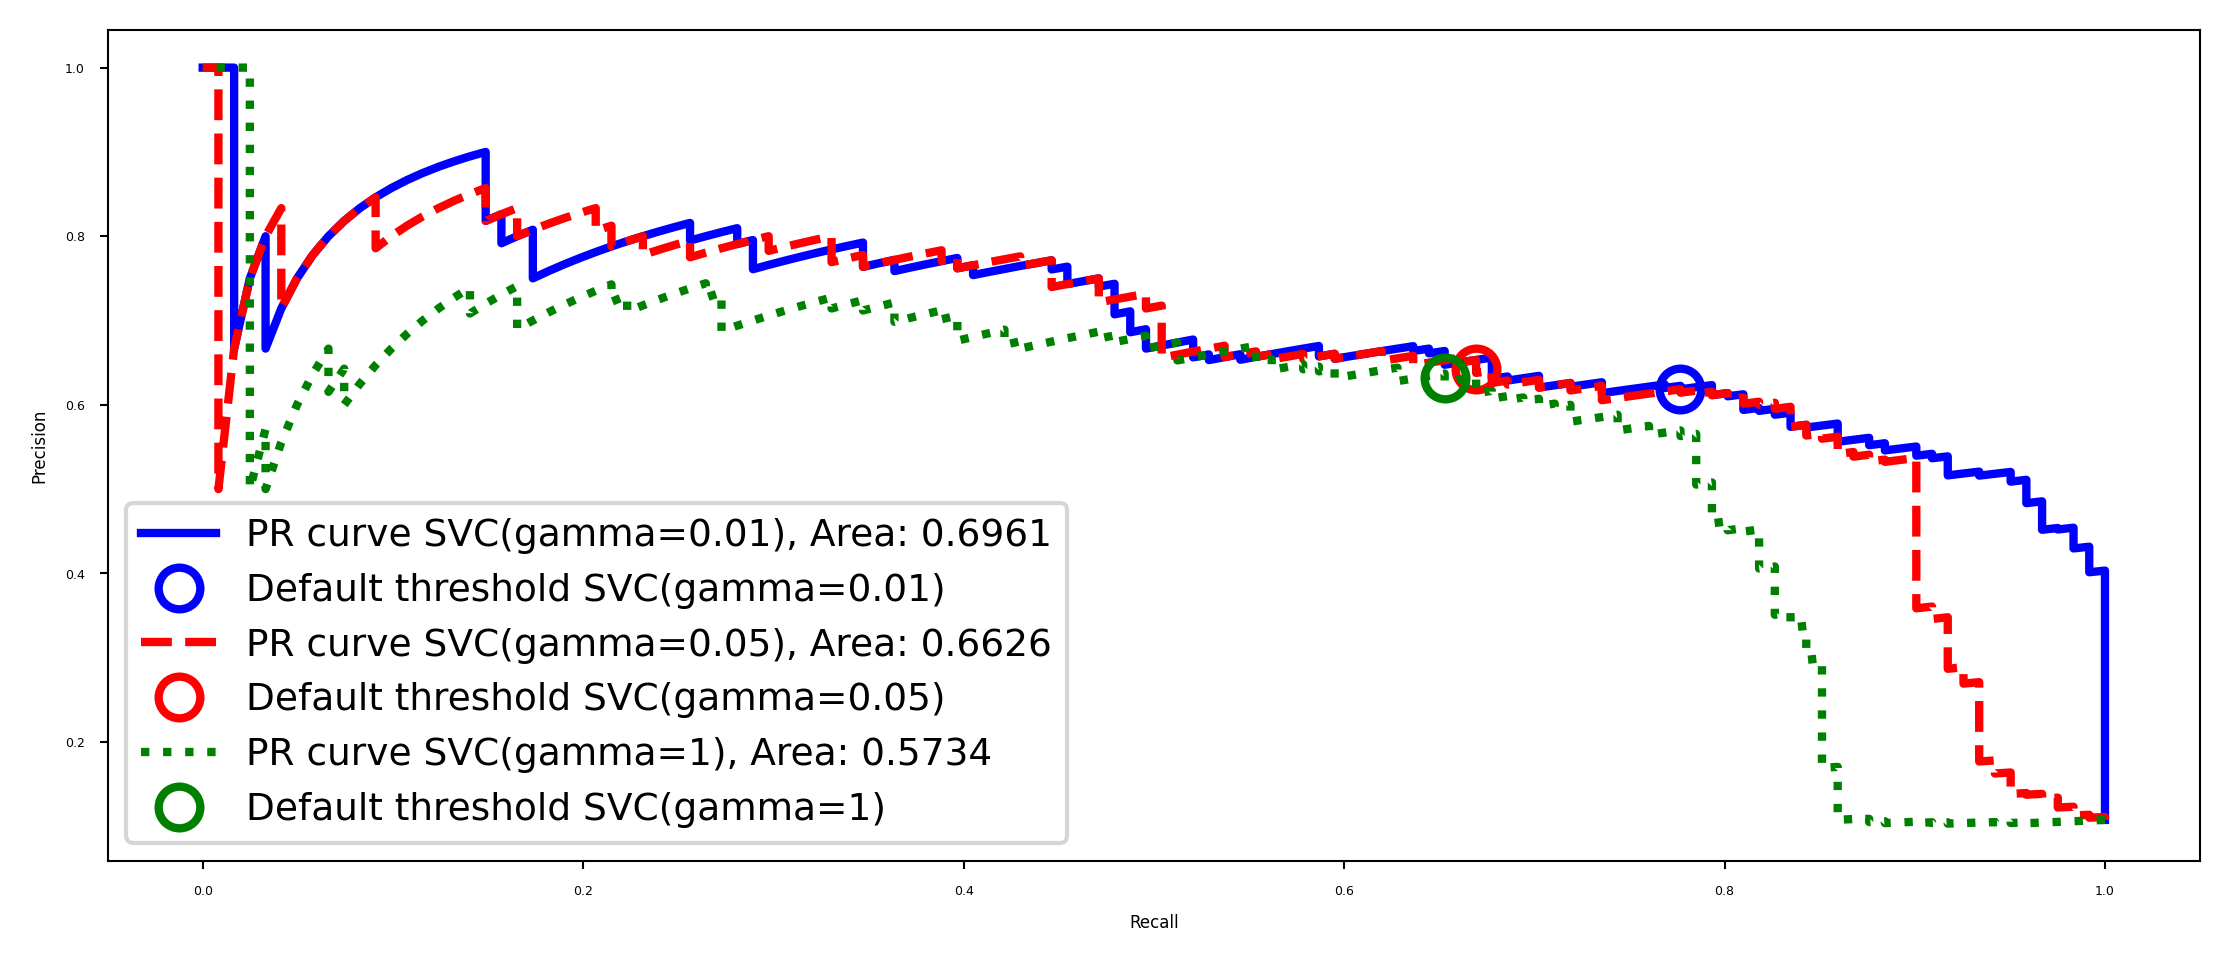

In [42]:
svc3 = SVC(gamma=0.01).fit(Xp_train, yp_train)
svc4 = SVC(gamma=1).fit(Xp_train, yp_train)
plot_PR_curves([svc3, svc2, svc4])

### Receiver Operating Characteristics (ROC)

- Trade off _true positive rate_ $\textit{TPR}= \frac{TP}{TP + FN}$ with _false positive rate_ $\textit{FPR} = \frac{FP}{FP + TN}$
- Plotting TPR against FPR _for all possible thresholds_ yields a _Receiver Operating Characteristics curve_
    - Change the threshold until you find a sweet spot in the TPR-FPR trade-off
    - Lower thresholds yield higher TPR (recall), higher FPR, and vice versa

interactive(children=(FloatSlider(value=-0.9899999999999998, description='threshold', max=1.4, min=-3.19), Dro…

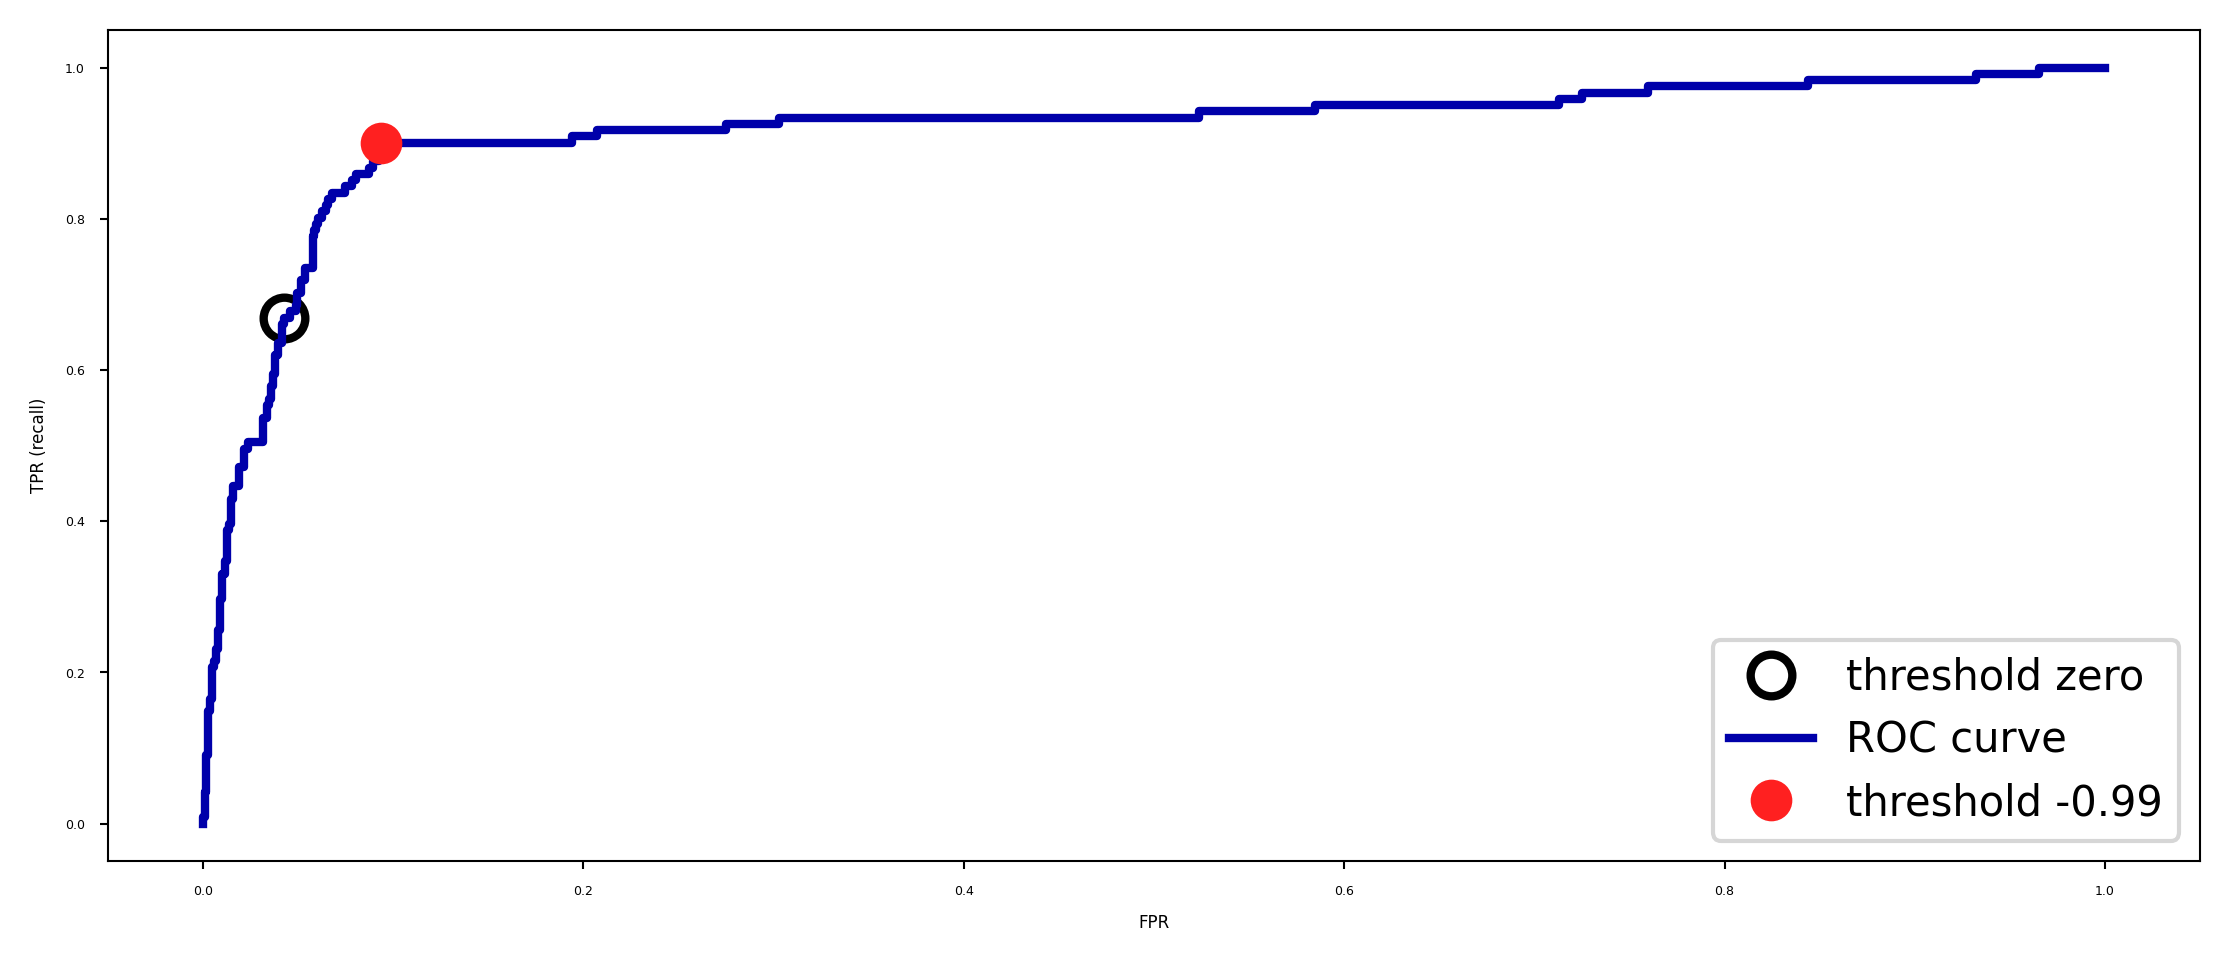

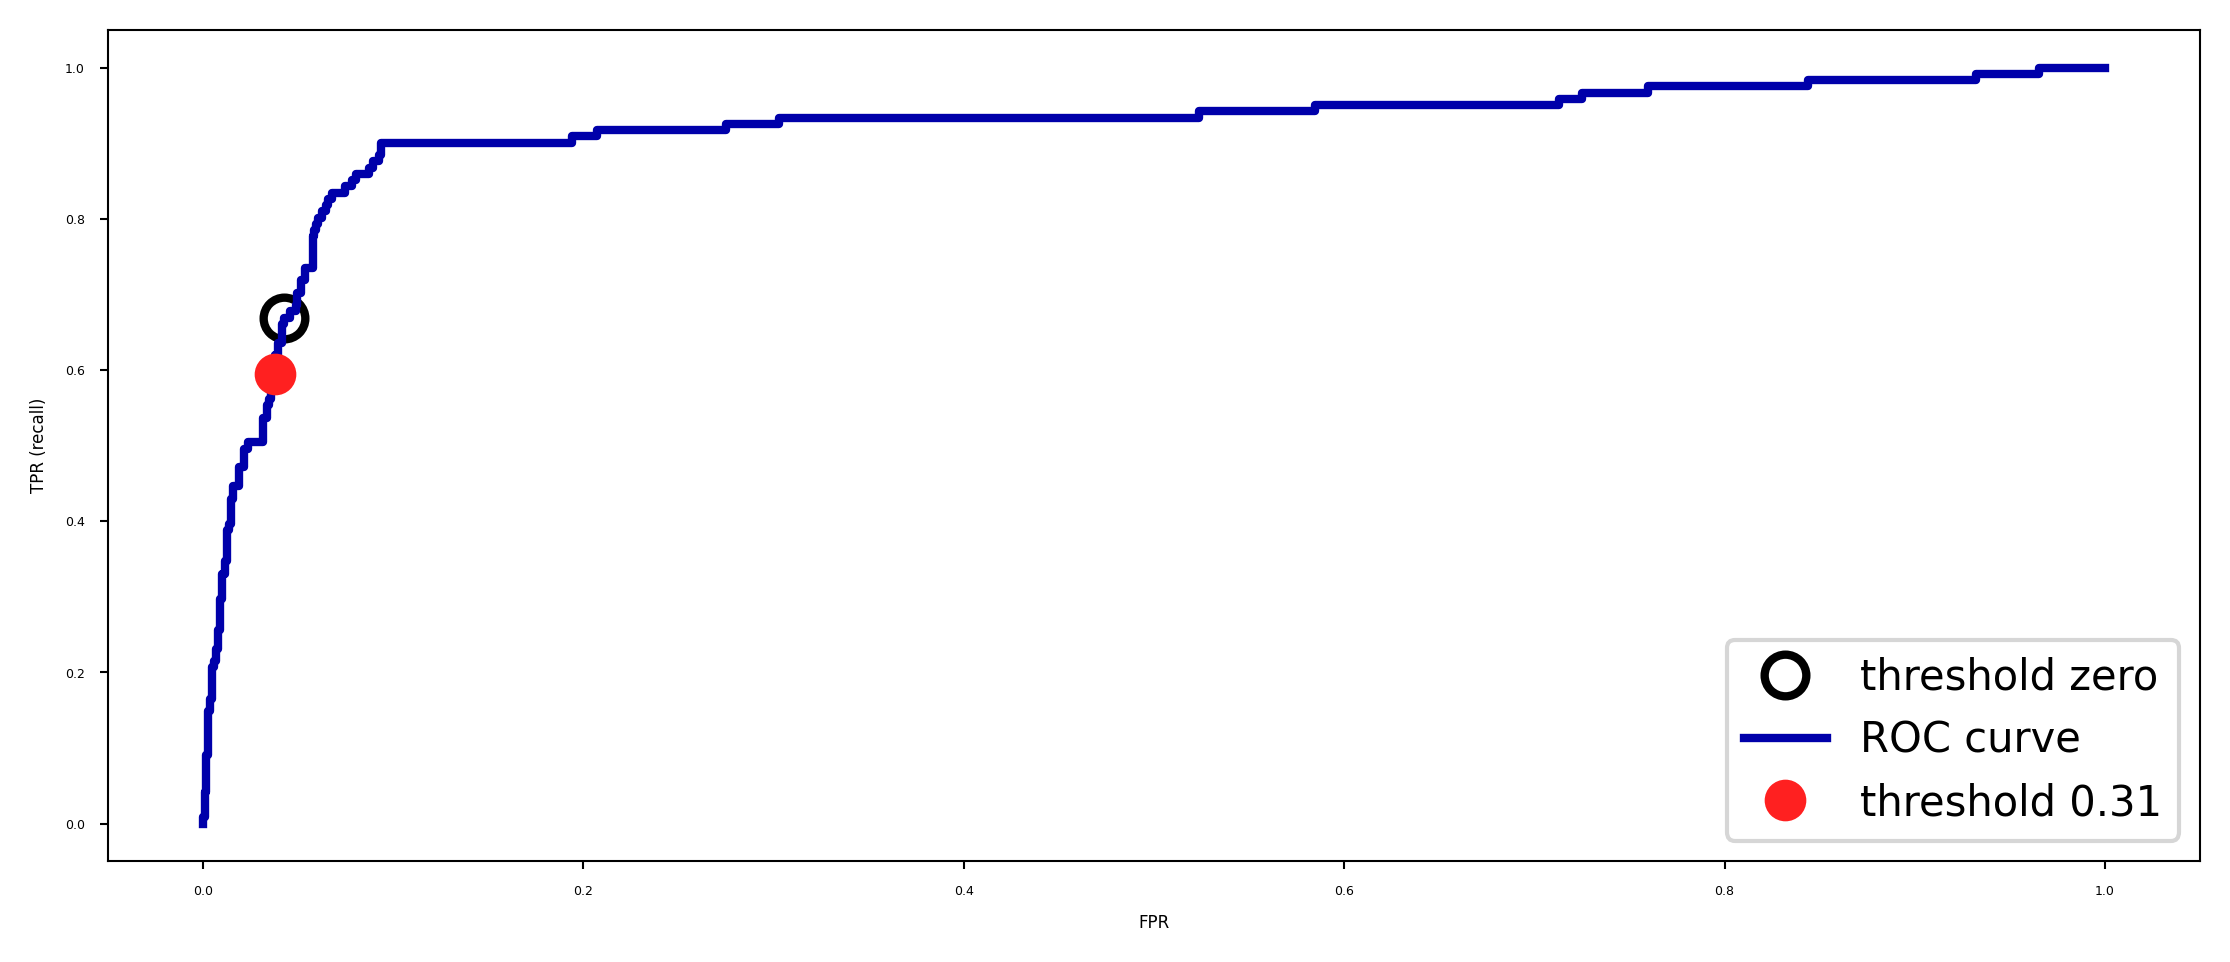

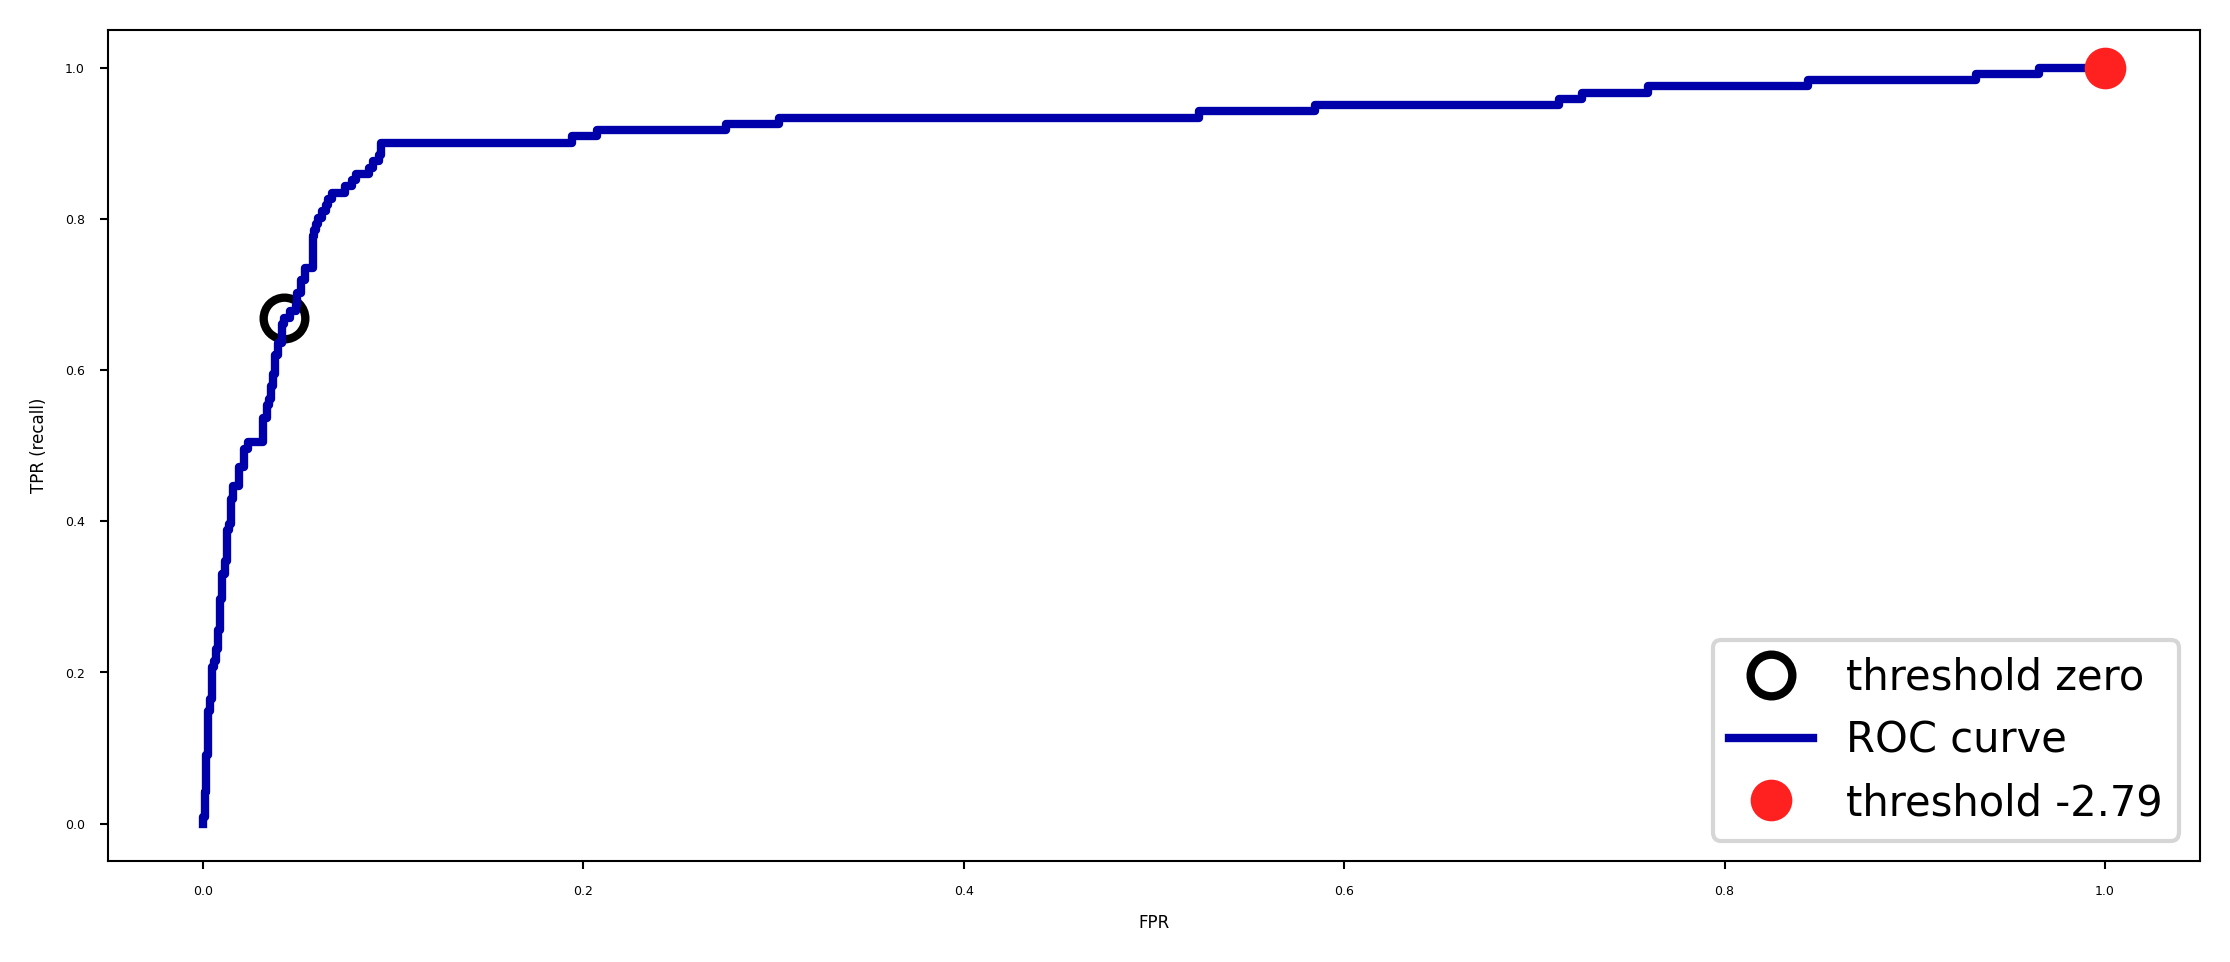

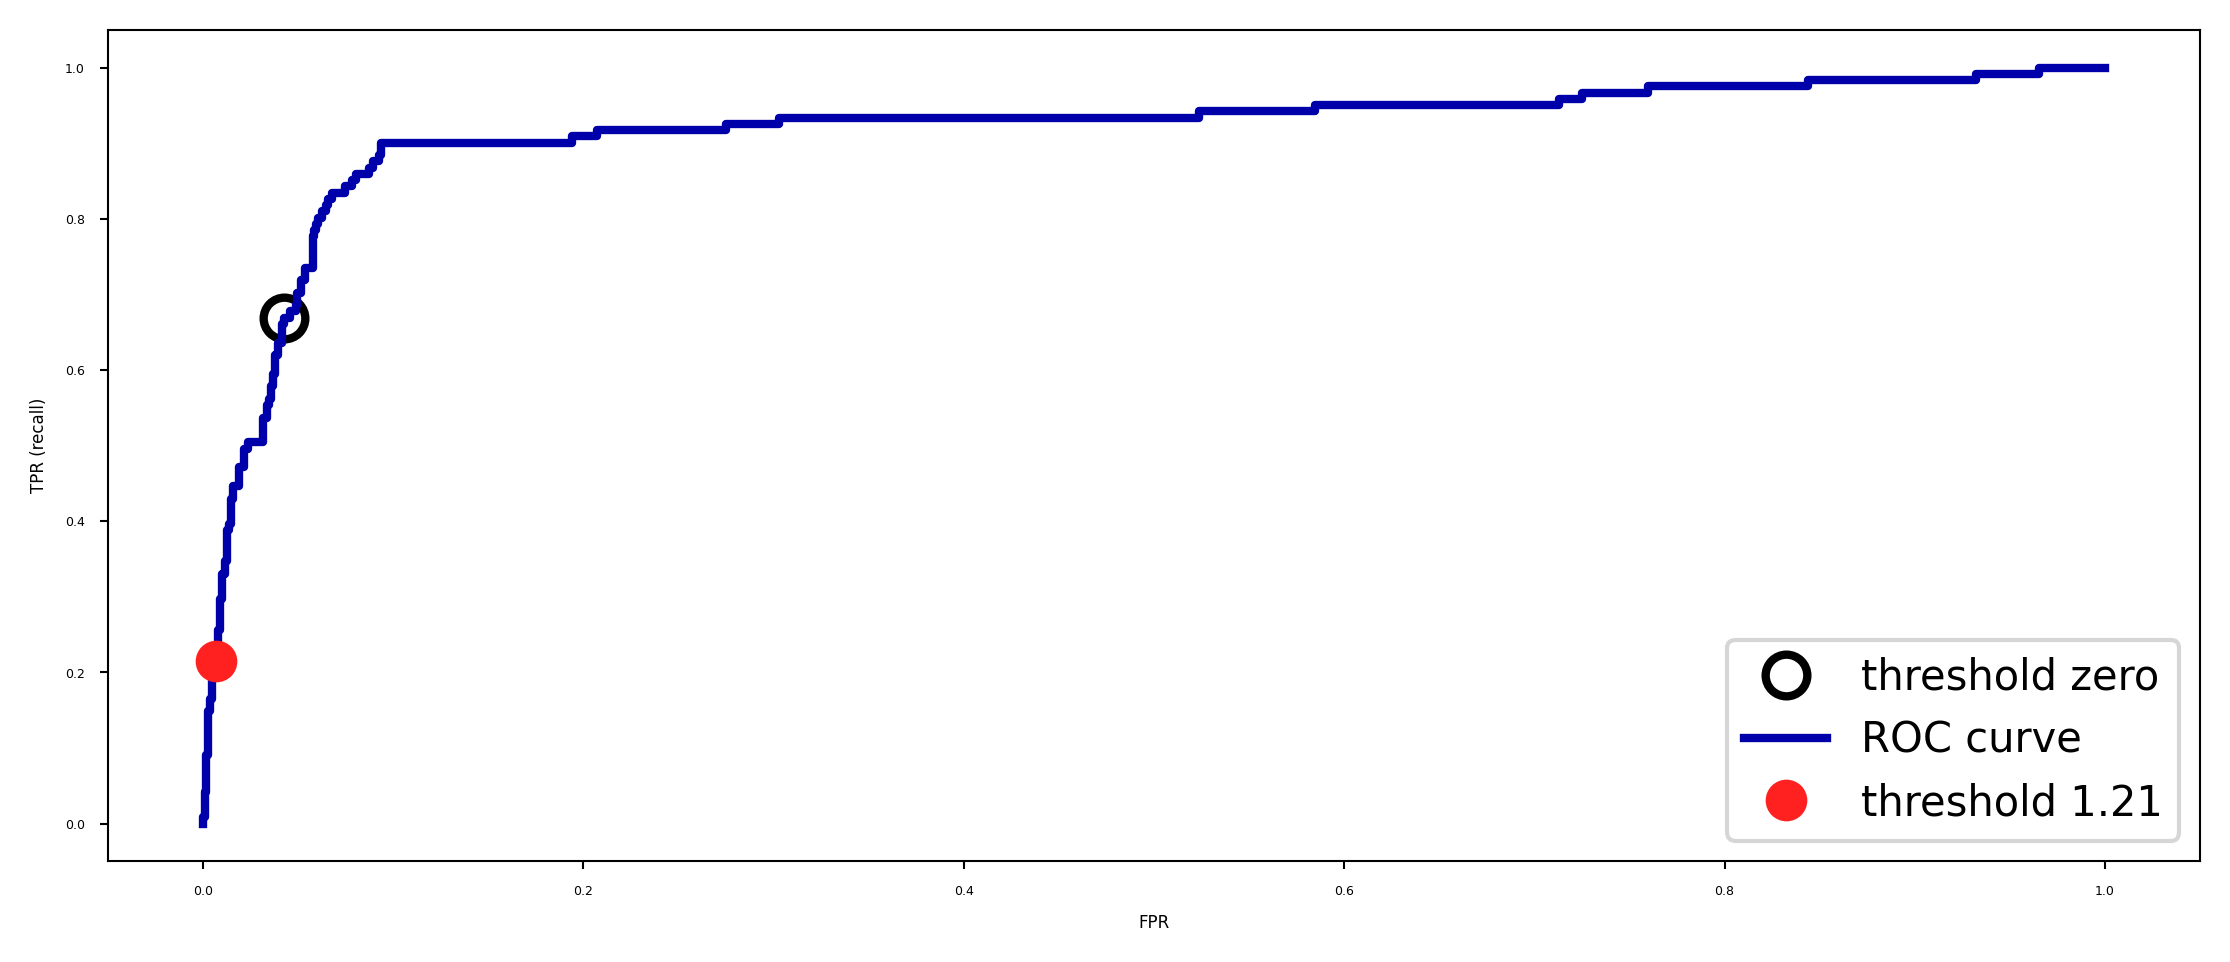

In [15]:
from sklearn.metrics import roc_curve

@interact
def plot_ROC_curve(threshold=(-3.19,1.4,0.1), model=[svc2, rf2]):
    if hasattr(model, "predict_proba"):
        fpr, tpr, thresholds = roc_curve(yp_test, model.predict_proba(Xp_test)[:, 1])
    else:
        fpr, tpr, thresholds = roc_curve(yp_test, model.decision_function(Xp_test))
    # find existing threshold closest to zero
    close_zero = np.argmin(np.abs(thresholds))
    plt.figure(figsize=(10*fig_scale,4*fig_scale))
    plt.plot(fpr[close_zero], tpr[close_zero], 'o', markersize=10, label="threshold zero", fillstyle="none", c='k', mew=2)
    plt.plot(fpr, tpr, lw=2, label="ROC curve")
    
    closest = np.argmin(np.abs(thresholds-threshold))
    plt.plot(fpr[closest], tpr[closest], 'o', markersize=10, label="threshold {:.2f}".format(threshold))
    
    plt.ylabel("TPR (recall)")
    plt.xlabel("FPR")
    plt.legend(loc="best", prop={"size":10});

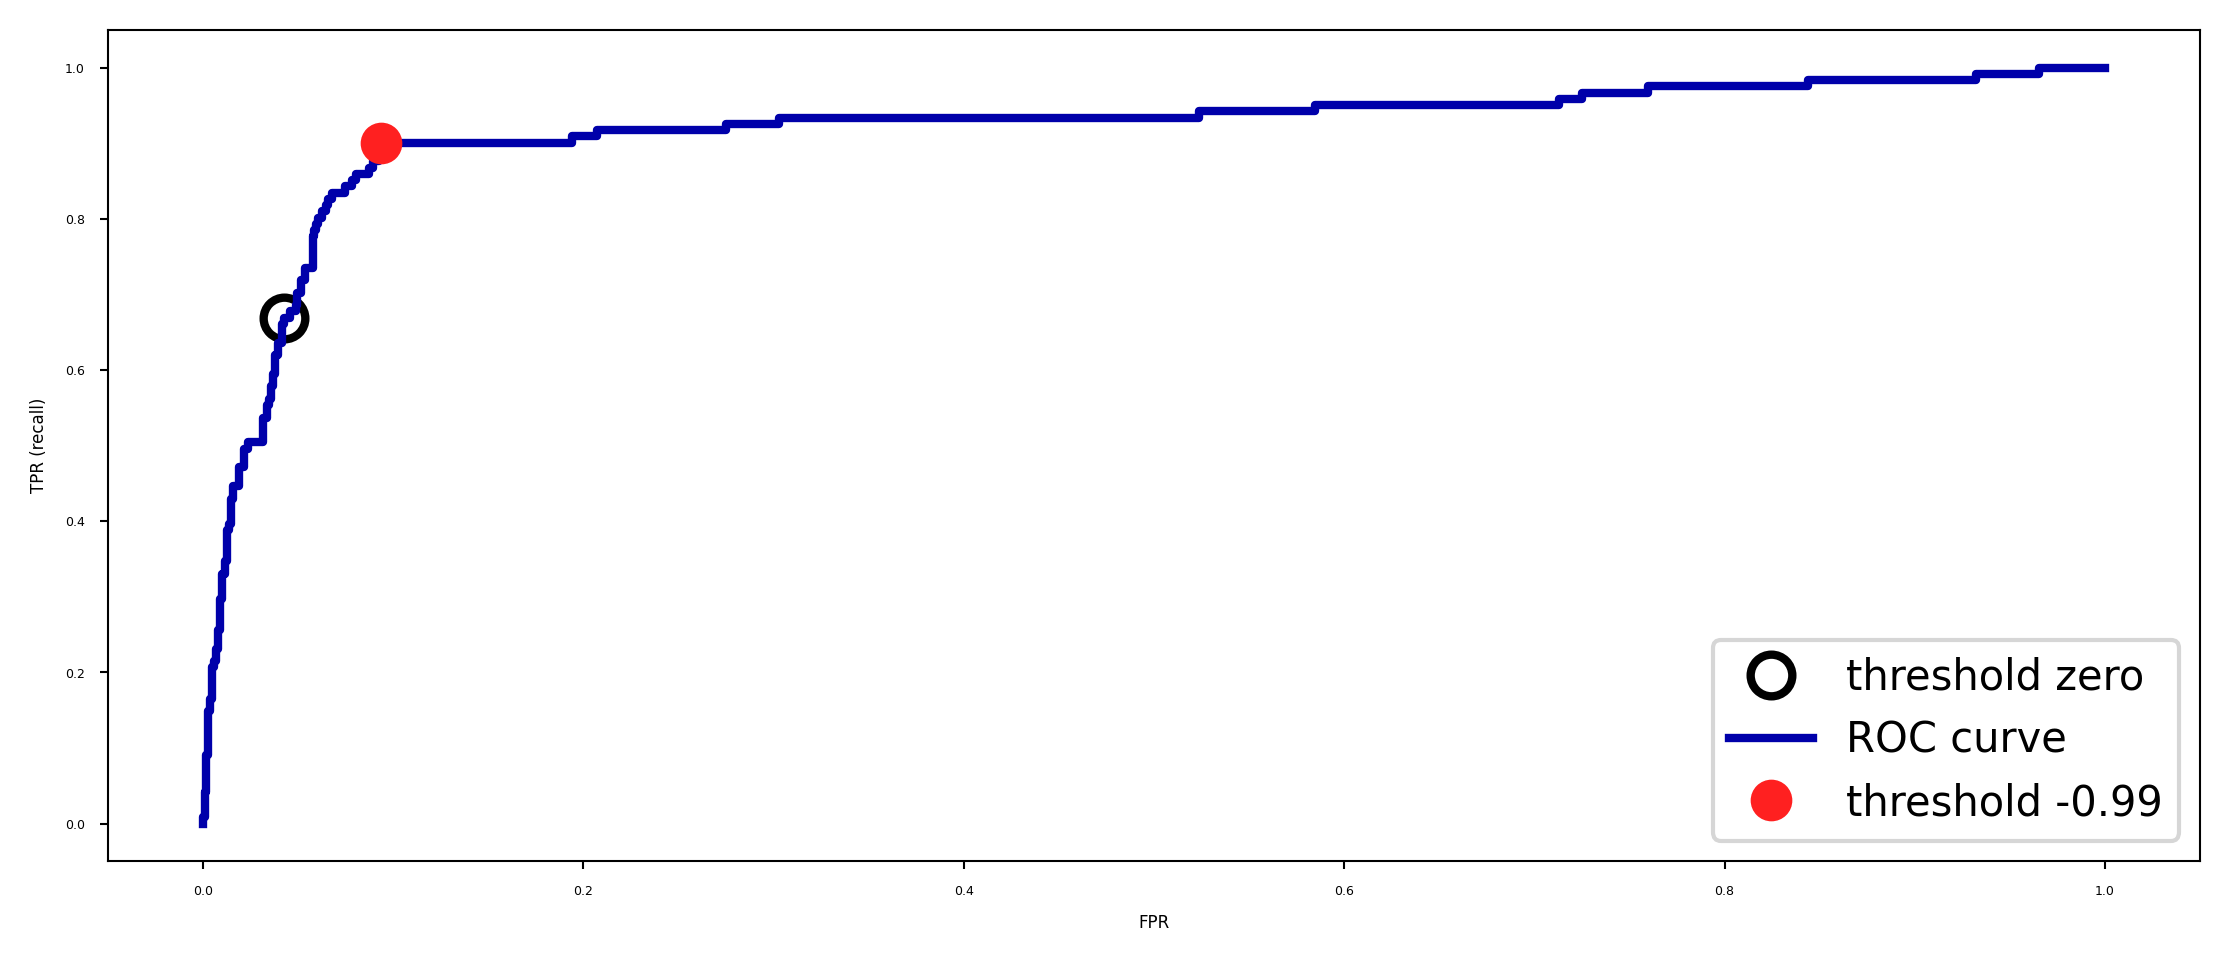

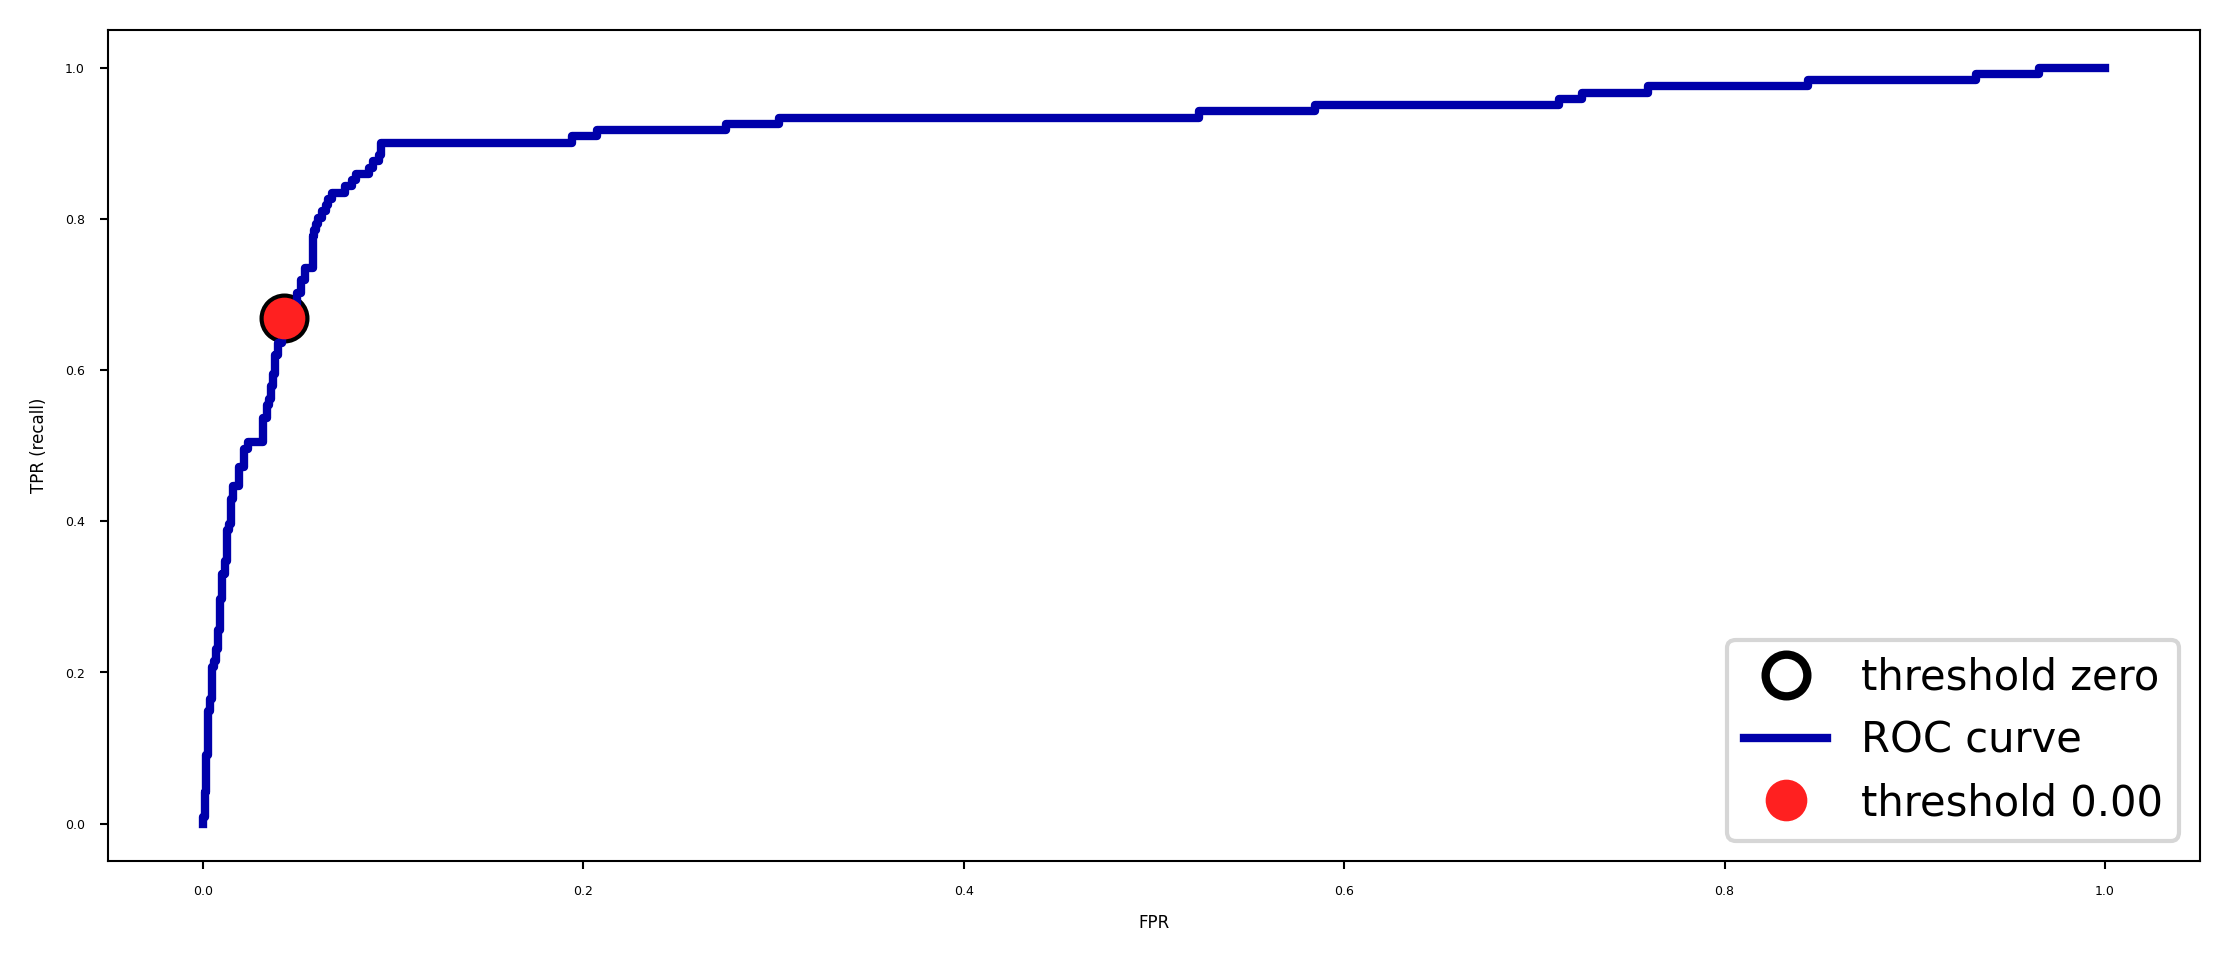

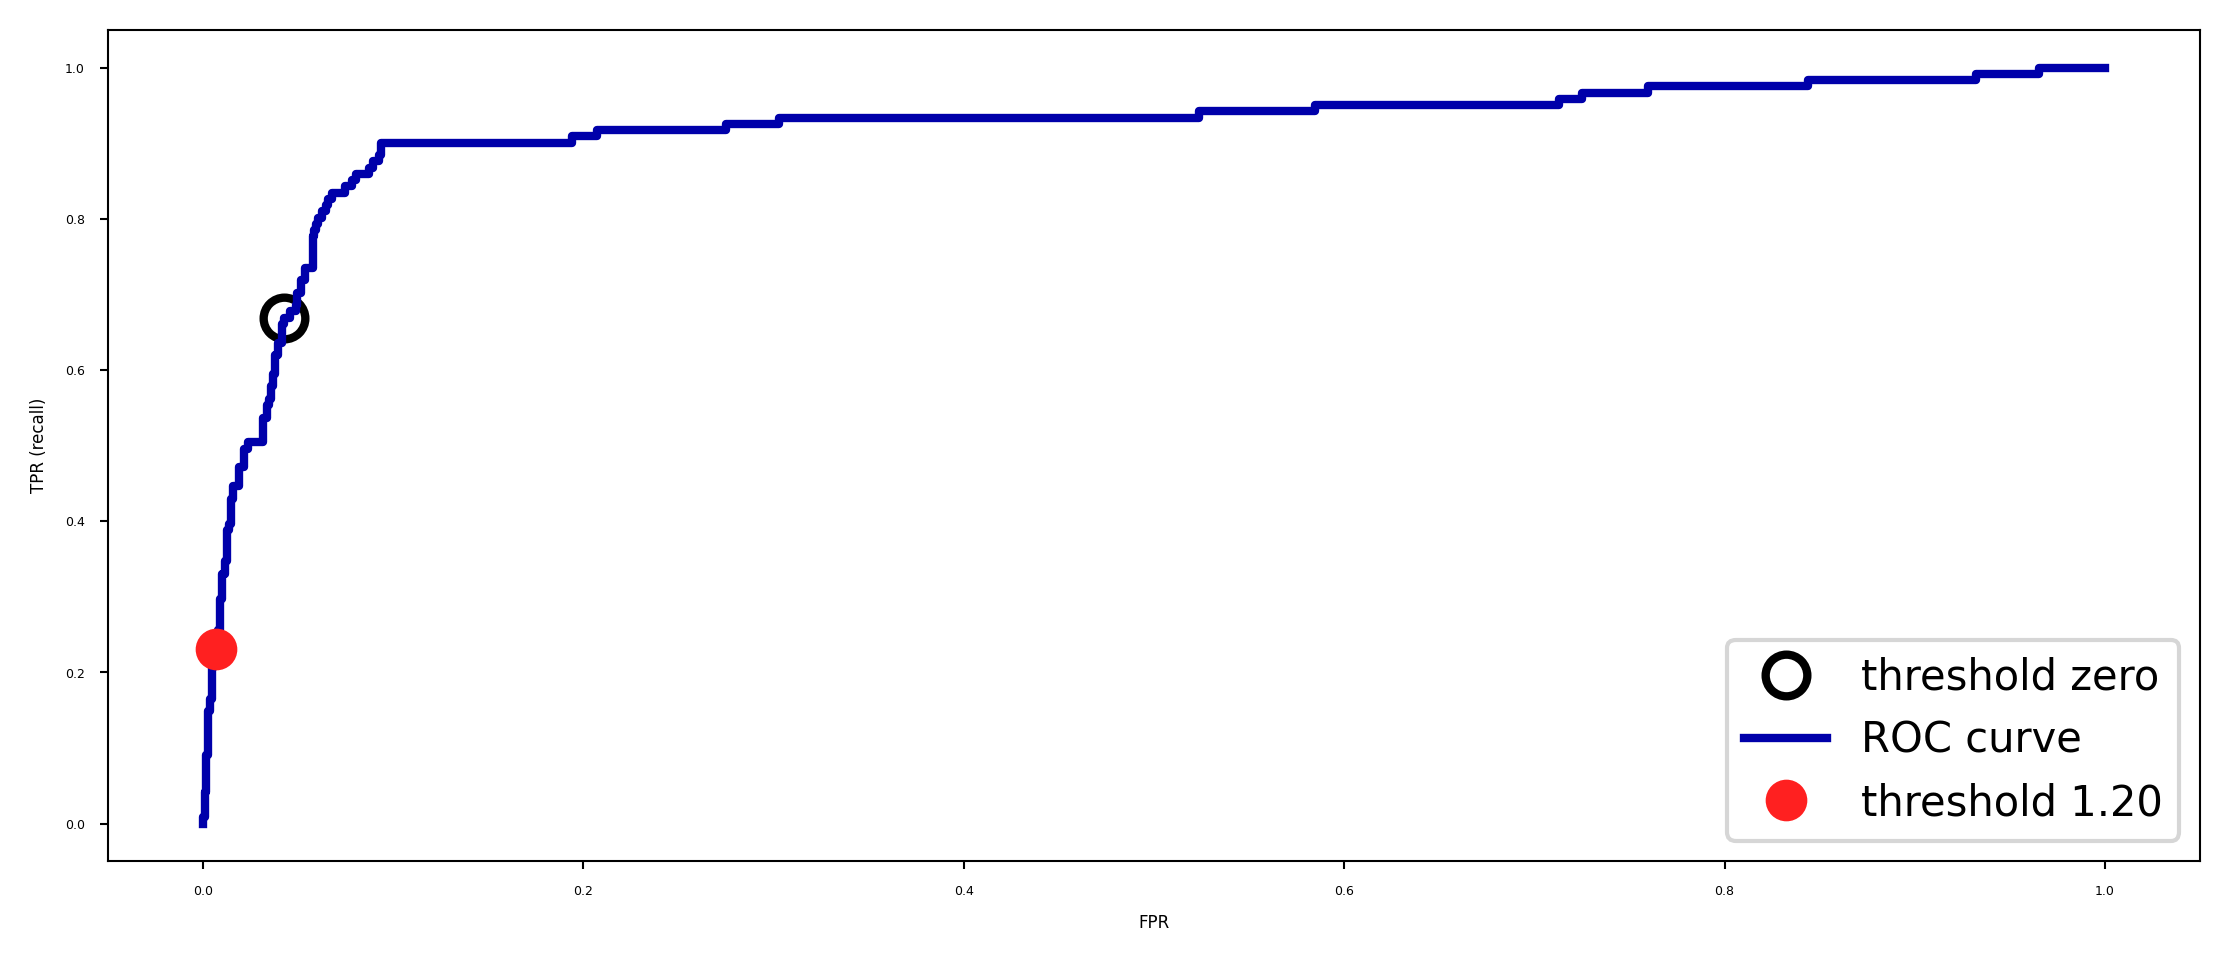

In [17]:
interactive = False 
if not interactive:
    plot_ROC_curve(threshold=-0.99,model=svc2)
    plot_ROC_curve(threshold=0,model=svc2)
    plot_ROC_curve(threshold=1.2,model=svc2)
interactive = True

#### Visualization
* Histograms show the amount of points with a certain decision value (for each class)
* $\textit{TPR}= \frac{\color{red}{TP}}{\color{red}{TP} + \color{magenta}{FN}}$ can be seen from the positive predictions (top histogram)
* $\textit{FPR} = \frac{\color{cyan}{FP}}{\color{cyan}{FP} + \color{blue}{TN}}$  can be seen from the negative predictions (bottom histogram)

interactive(children=(FloatSlider(value=0.0, description='threshold', max=2.0, min=-2.0), Output()), _dom_clas…

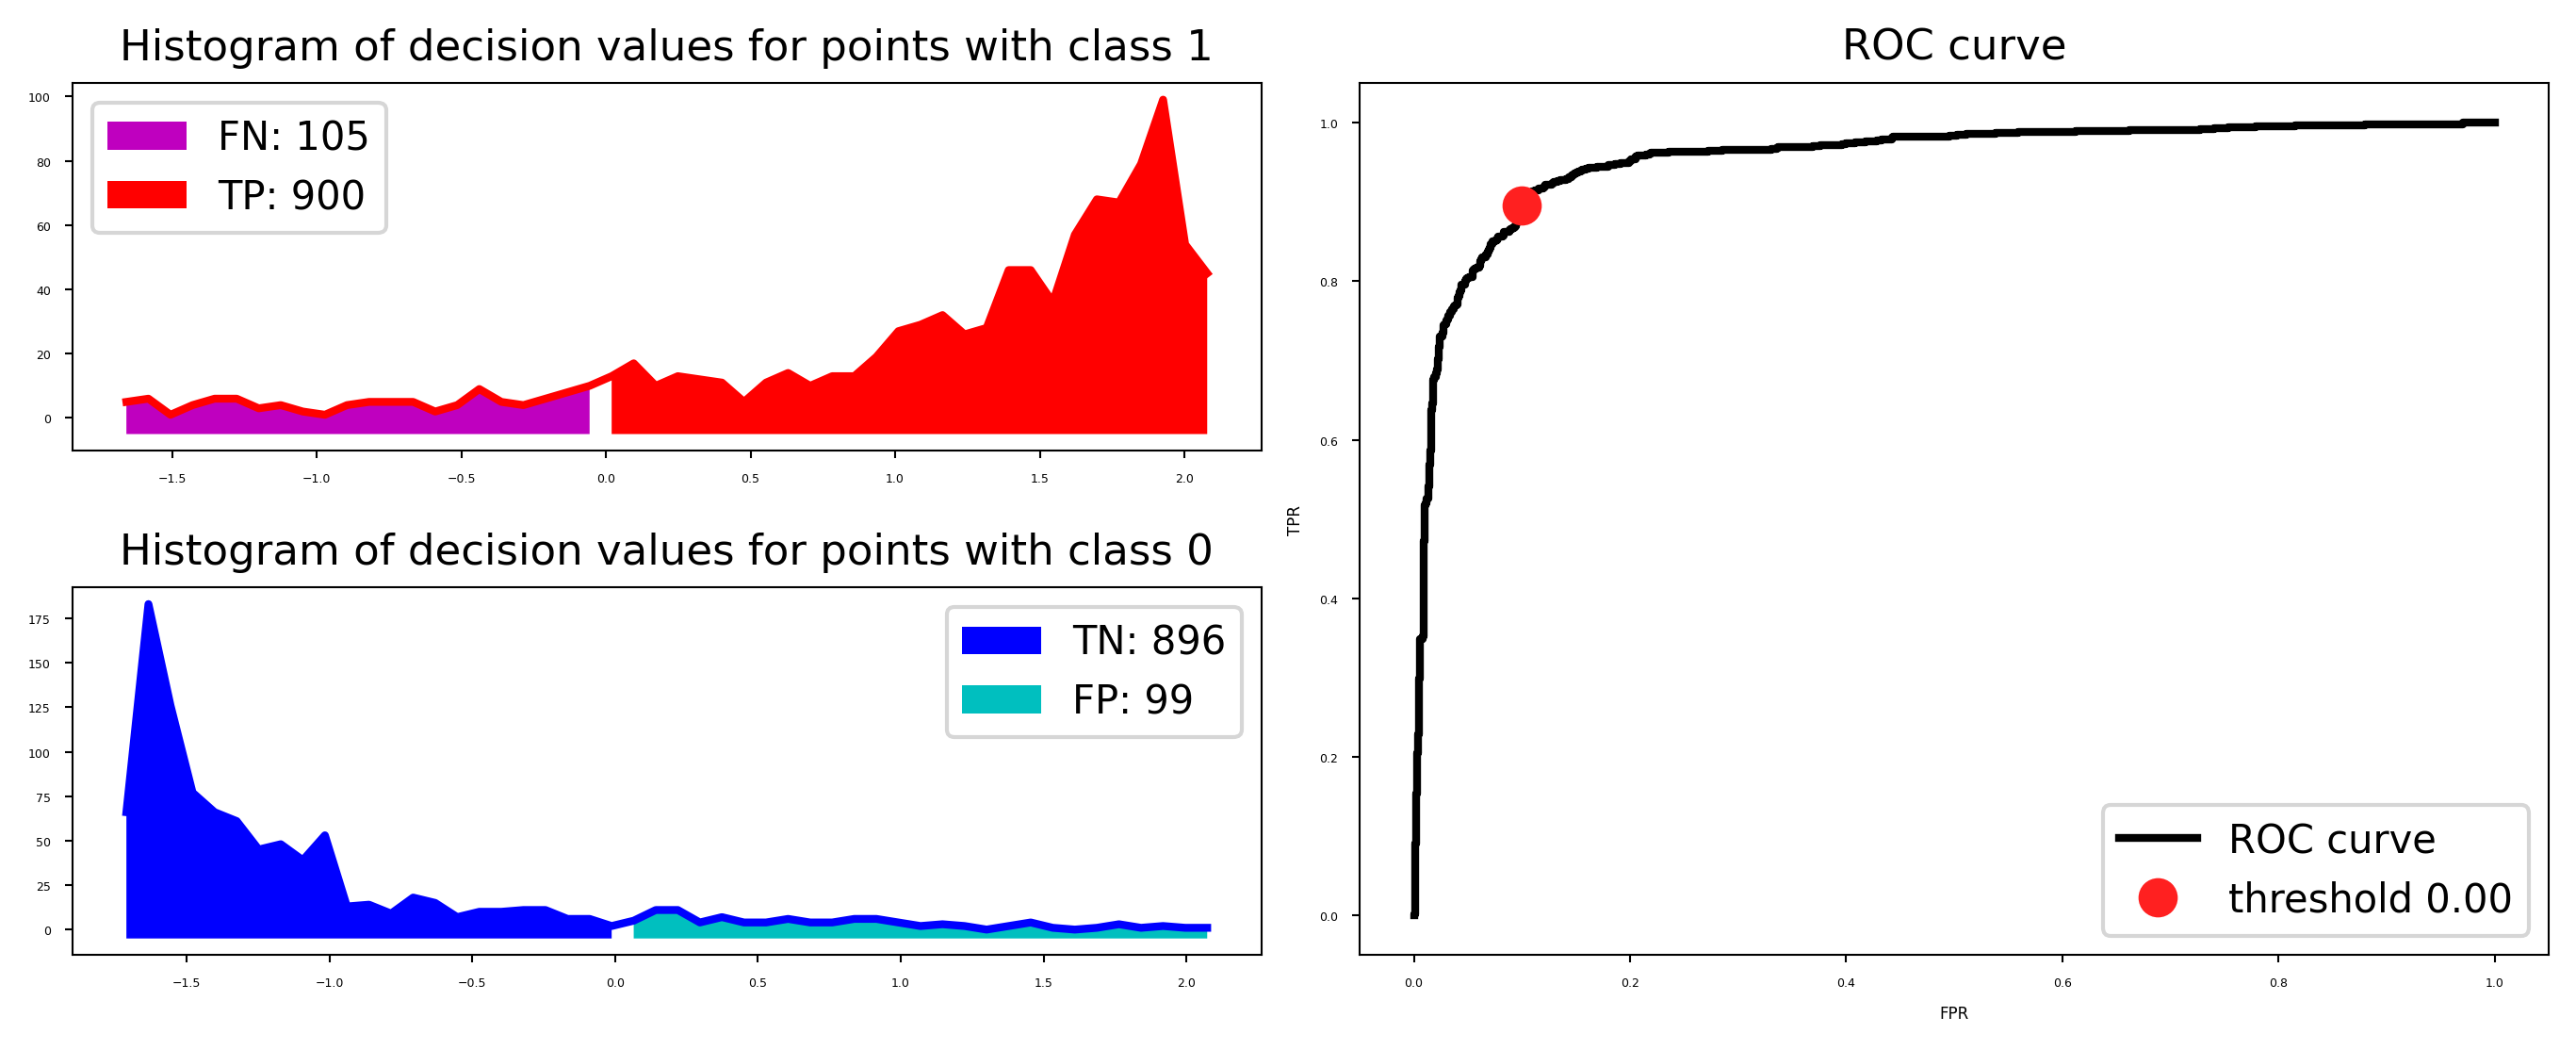

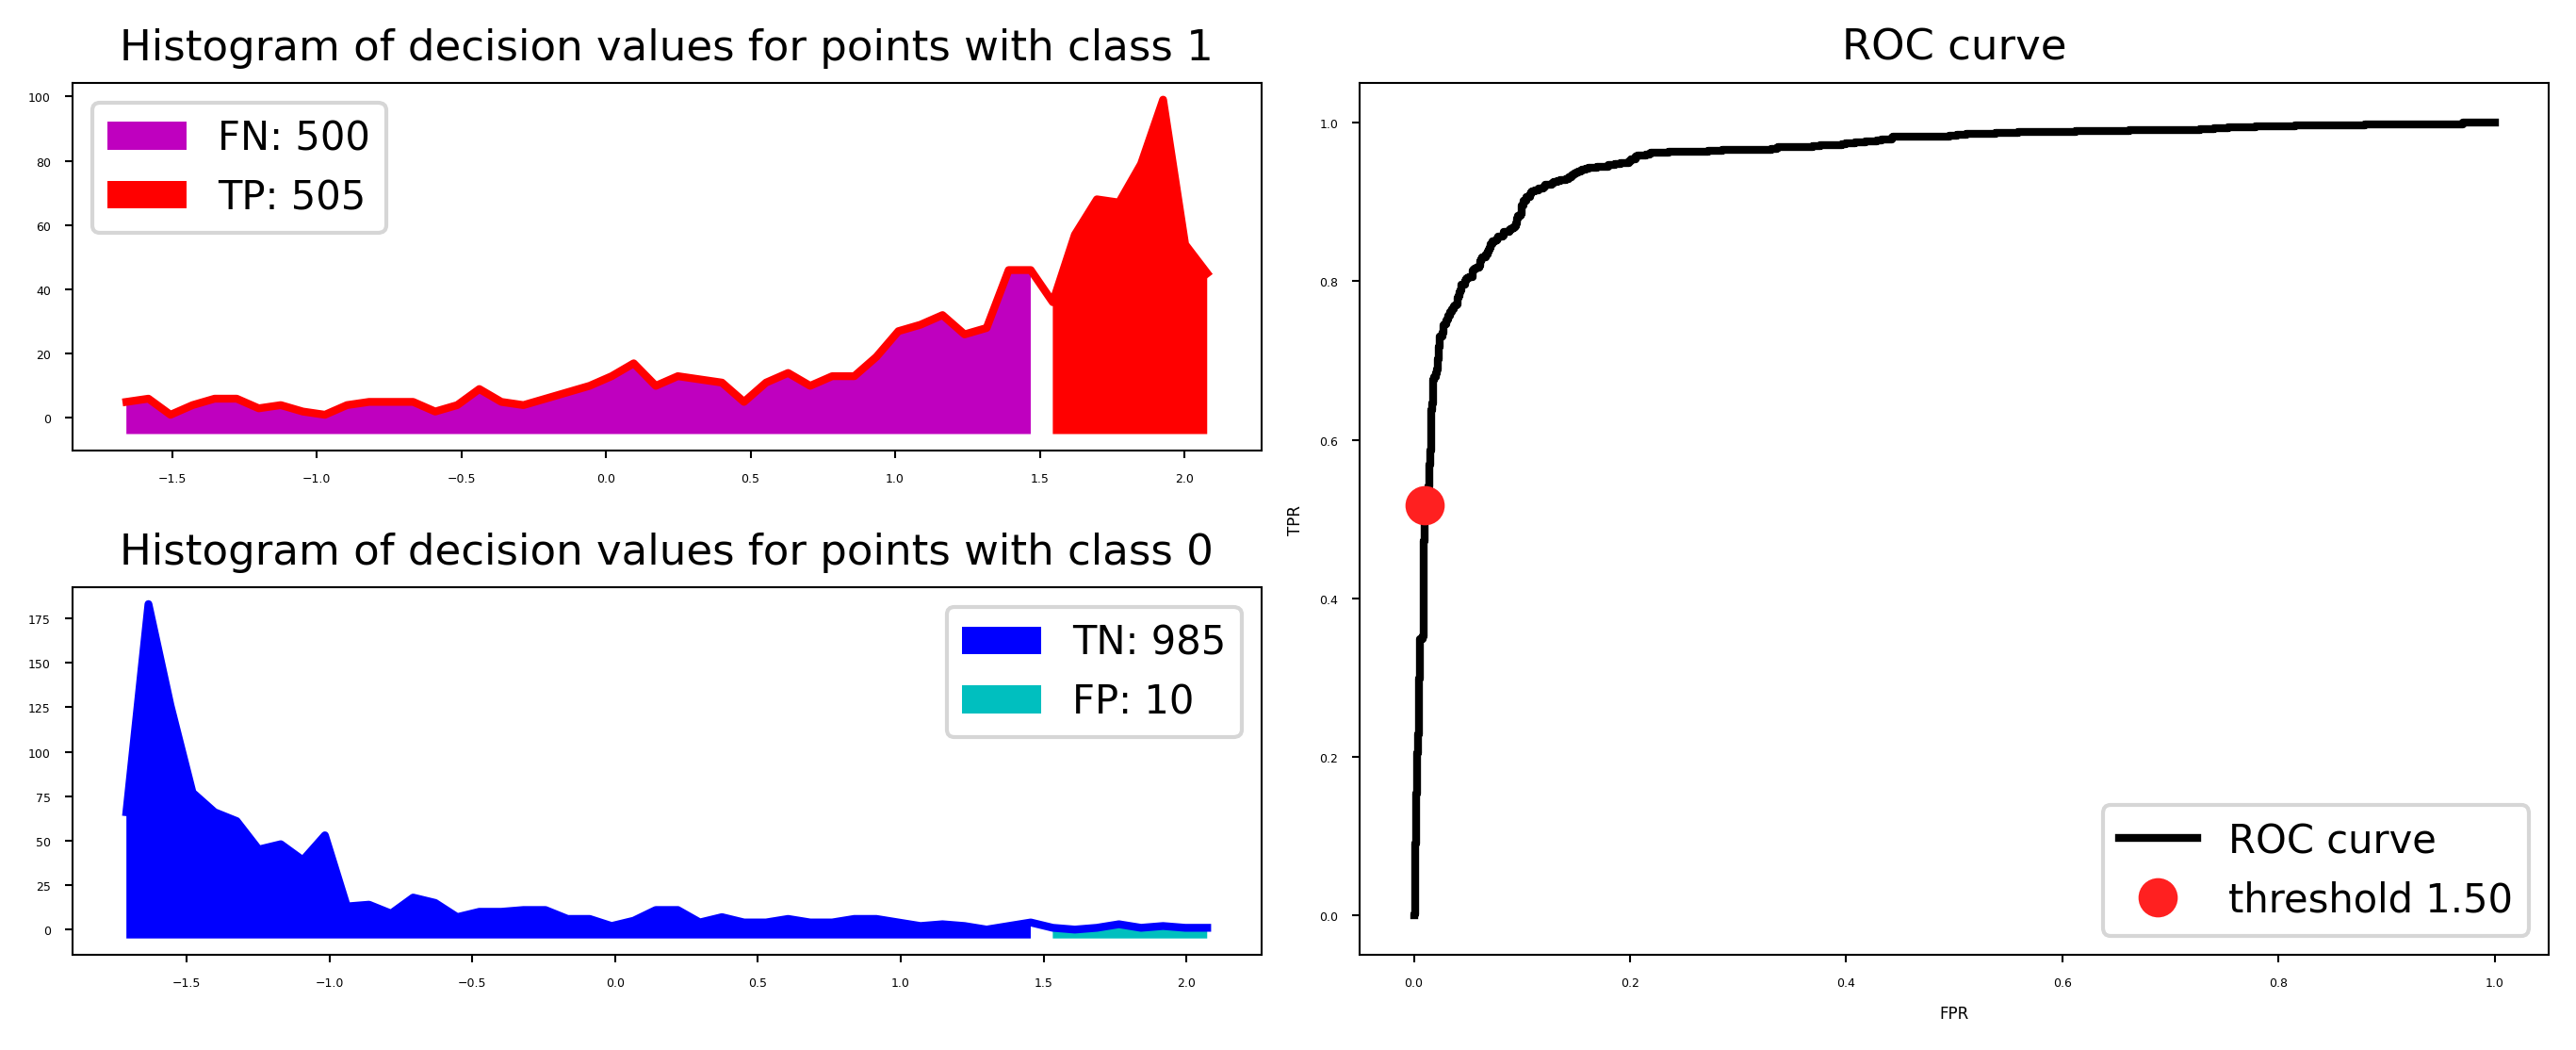

In [28]:
# More data for a smoother curve
Xb, yb = make_blobs(n_samples=(4000, 4000), centers=None, cluster_std=[3, 3], random_state=7)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, random_state=0)
svc_roc = SVC(C=2).fit(Xb_train, yb_train)
probs_roc = svc_roc.decision_function(Xb_test)

@interact
def plot_roc_threshold(threshold=(-2,2,0.1)):
    fig = plt.figure(constrained_layout=True, figsize=(10*fig_scale,4*fig_scale))
    axes = []
    gs = fig.add_gridspec(2, 2)
    axes.append(fig.add_subplot(gs[0, :-1]))
    axes.append(fig.add_subplot(gs[1, :-1]))
    axes.append(fig.add_subplot(gs[:, 1]))
    
    n=50 # number of histogram bins
    color=['b','r']
    color_fill=['b','c','m','r']
    labels=['TN','FP','FN','TP']
    
    # Histograms
    for label in range(2):
        ps = probs_roc[yb_test == label] # get prediction for given label
        p, x = np.histogram(ps, bins=n) # bin it into n bins
        x = x[:-1] + (x[1] - x[0])/2 # convert bin edges to center
        axes[1-label].plot(x, p, c=color[label], lw=2)
        axes[1-label].fill_between(x[x<threshold], p[x<threshold], -5, facecolor=color_fill[2*label], label='{}: {}'.format(labels[2*label],np.sum(p[x<threshold])))
        axes[1-label].fill_between(x[x>=threshold], p[x>threshold], -5, facecolor=color_fill[2*label+1], label='{}: {}'.format(labels[2*label+1],np.sum(p[x>=threshold])))
        axes[1-label].set_title('Histogram of decision values for points with class {}'.format(label), fontsize=12*fig_scale)
        axes[1-label].legend(prop={"size":10})
        
    #ROC curve
    fpr, tpr, thresholds = roc_curve(yb_test, svc_roc.decision_function(Xb_test))
    axes[2].plot(fpr, tpr, lw=2, label="ROC curve", c='k')
    closest = np.argmin(np.abs(thresholds-threshold))
    axes[2].plot(fpr[closest], tpr[closest], 'o', markersize=10, label="threshold {:.2f}".format(threshold))
    
    axes[2].set_title('ROC curve', fontsize=12*fig_scale)
    axes[2].set_xlabel("FPR")
    axes[2].set_ylabel("TPR")
    axes[2].legend(prop={"size":10})

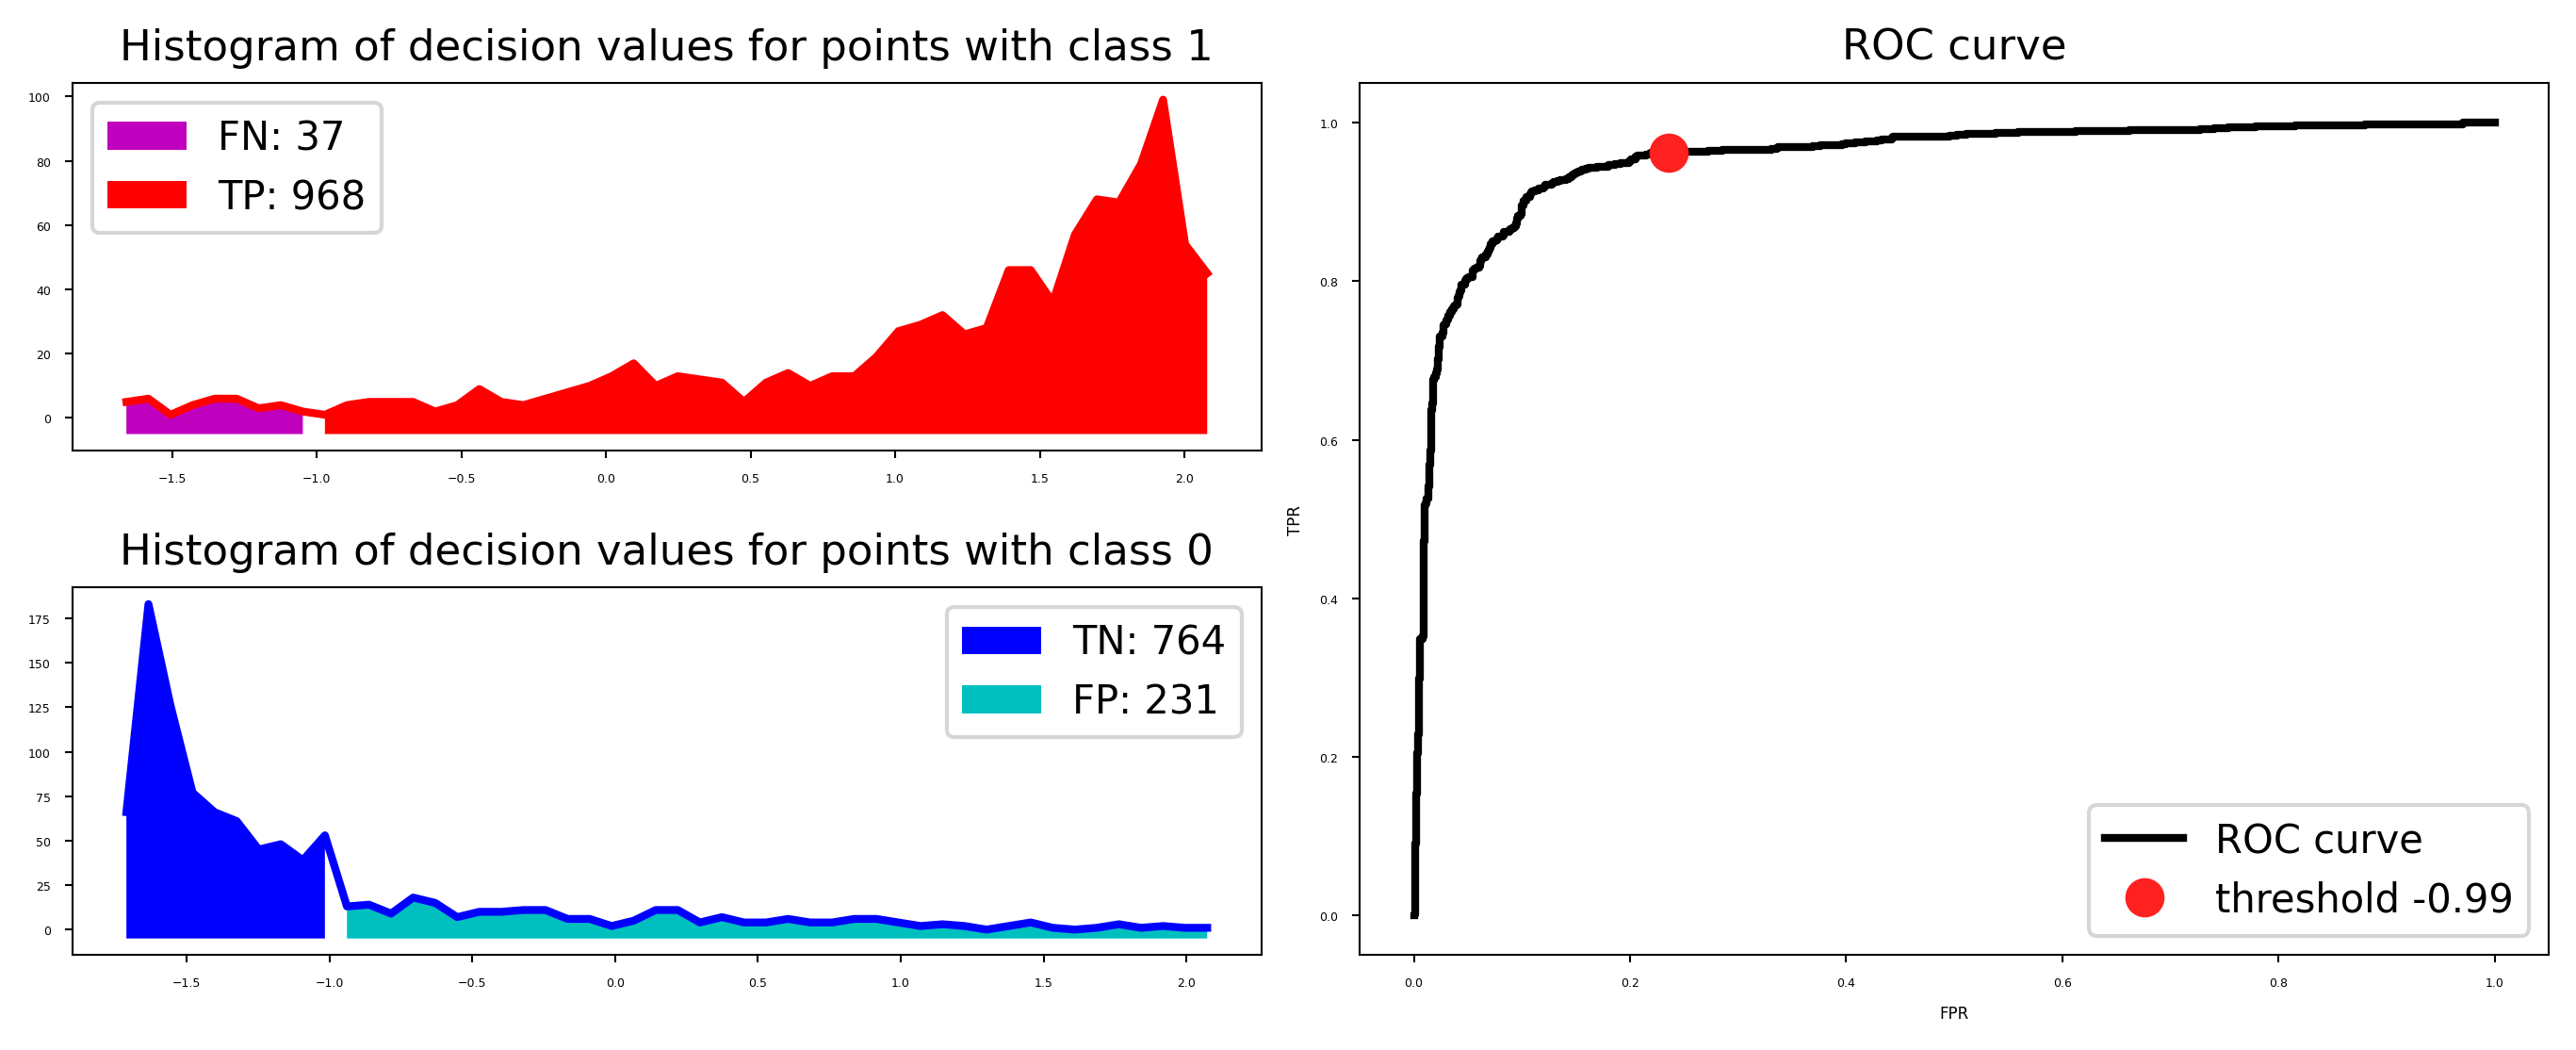

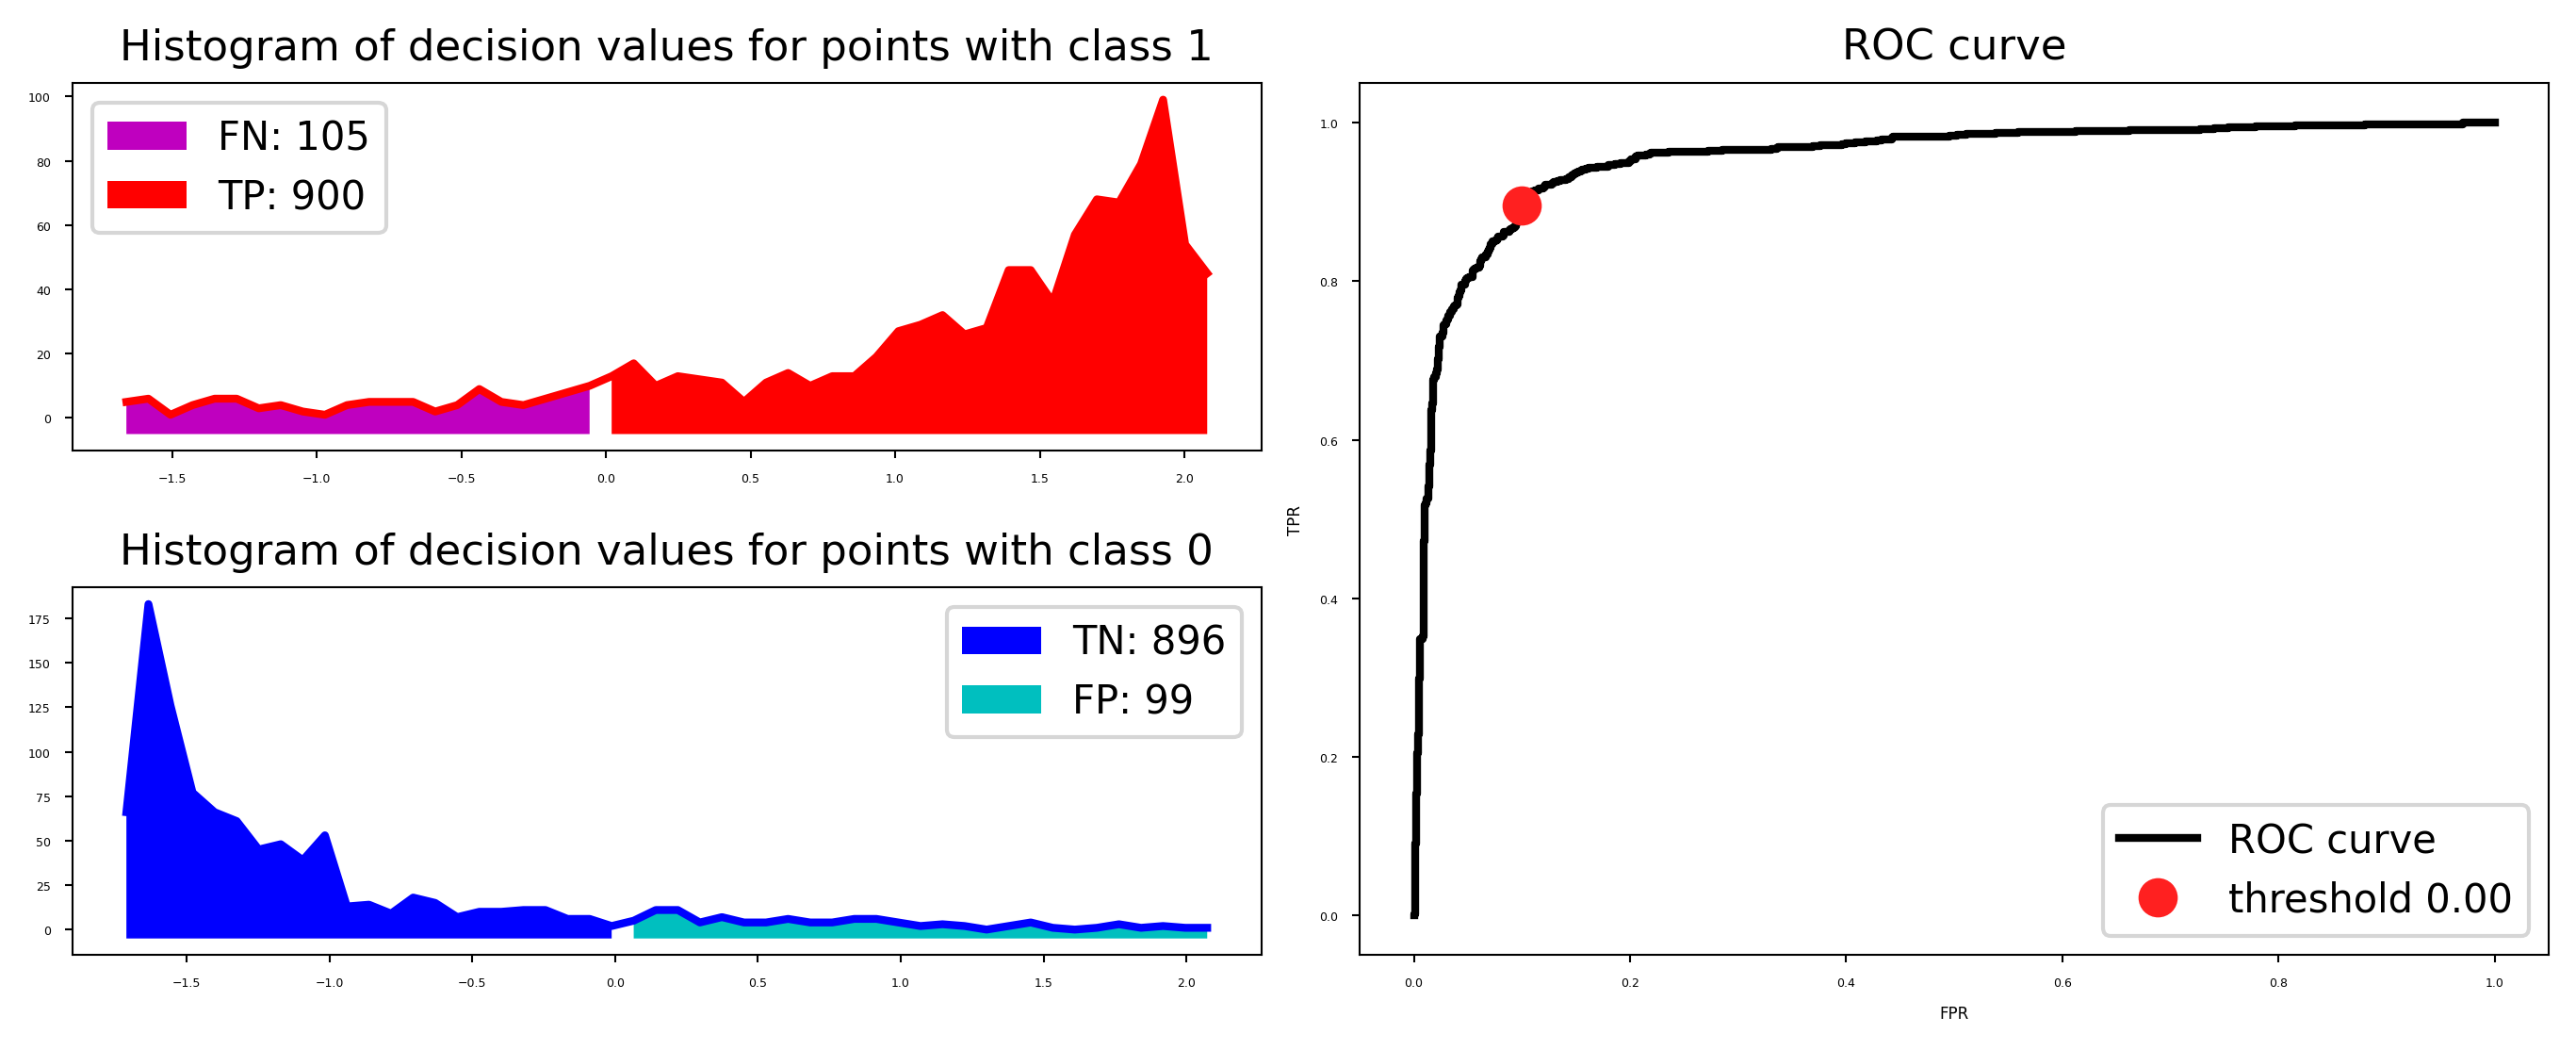

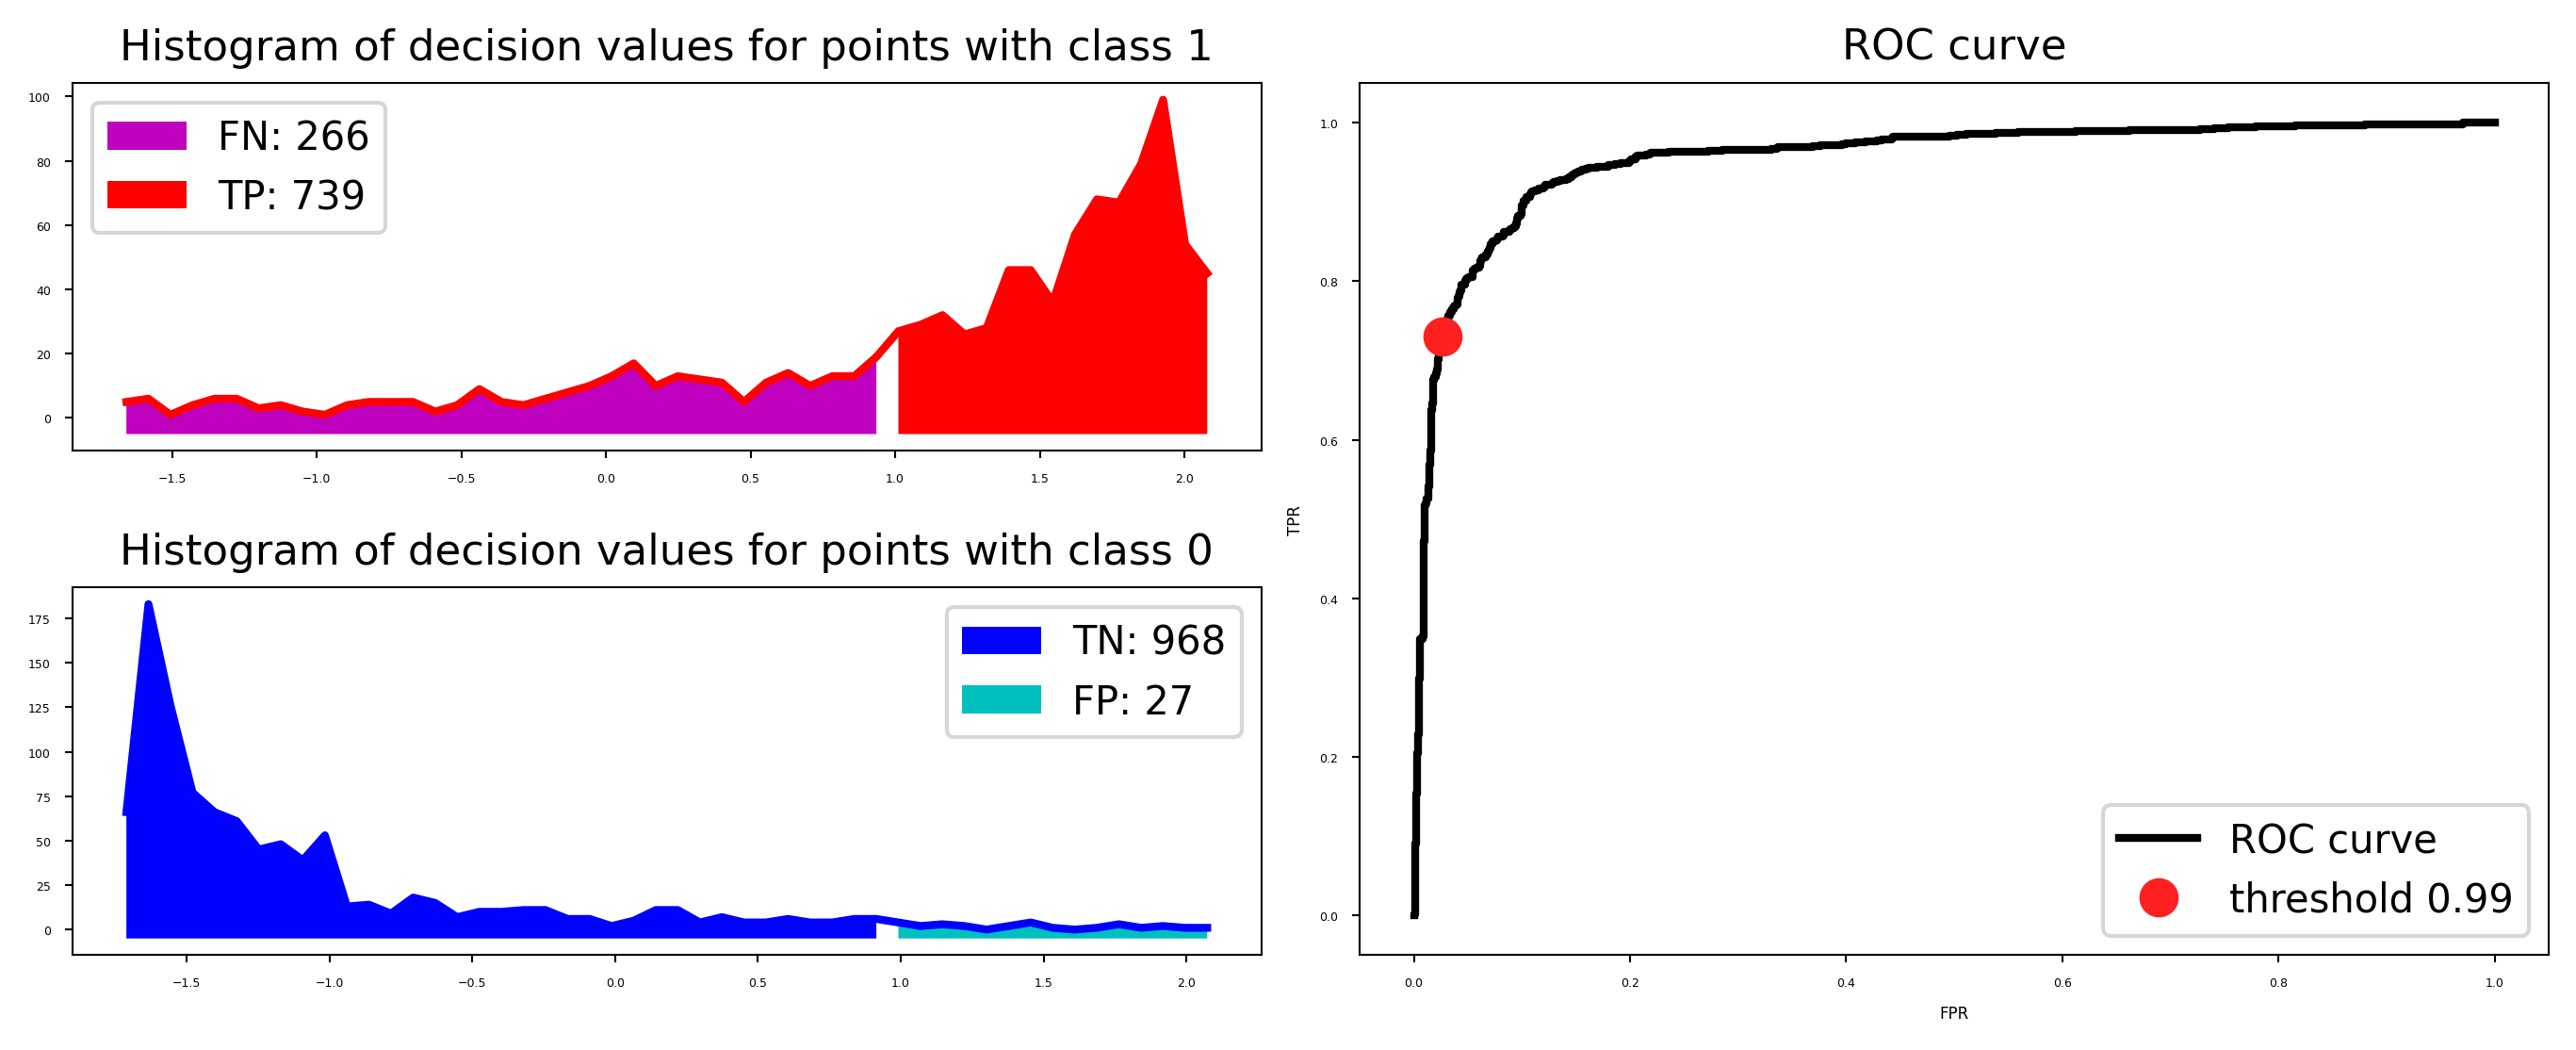

In [32]:
interactive = False
if not interactive:
    plot_roc_threshold(threshold=-0.99)
    plot_roc_threshold(threshold=0)
    plot_roc_threshold(threshold=0.99)

interactive = True

#### Model selection
- Again, some models can achieve trade-offs that others can't
- Your application may require minimizing FPR (low FP), or maximizing TPR (low FN)
- The area under the ROC curve (AUROC or AUC) gives the _best overall_ model
    - Frequently used for evaluating models on imbalanced data
    - Random guessing (TPR=FPR) or predicting majority class (TPR=FPR=1): 0.5 AUC

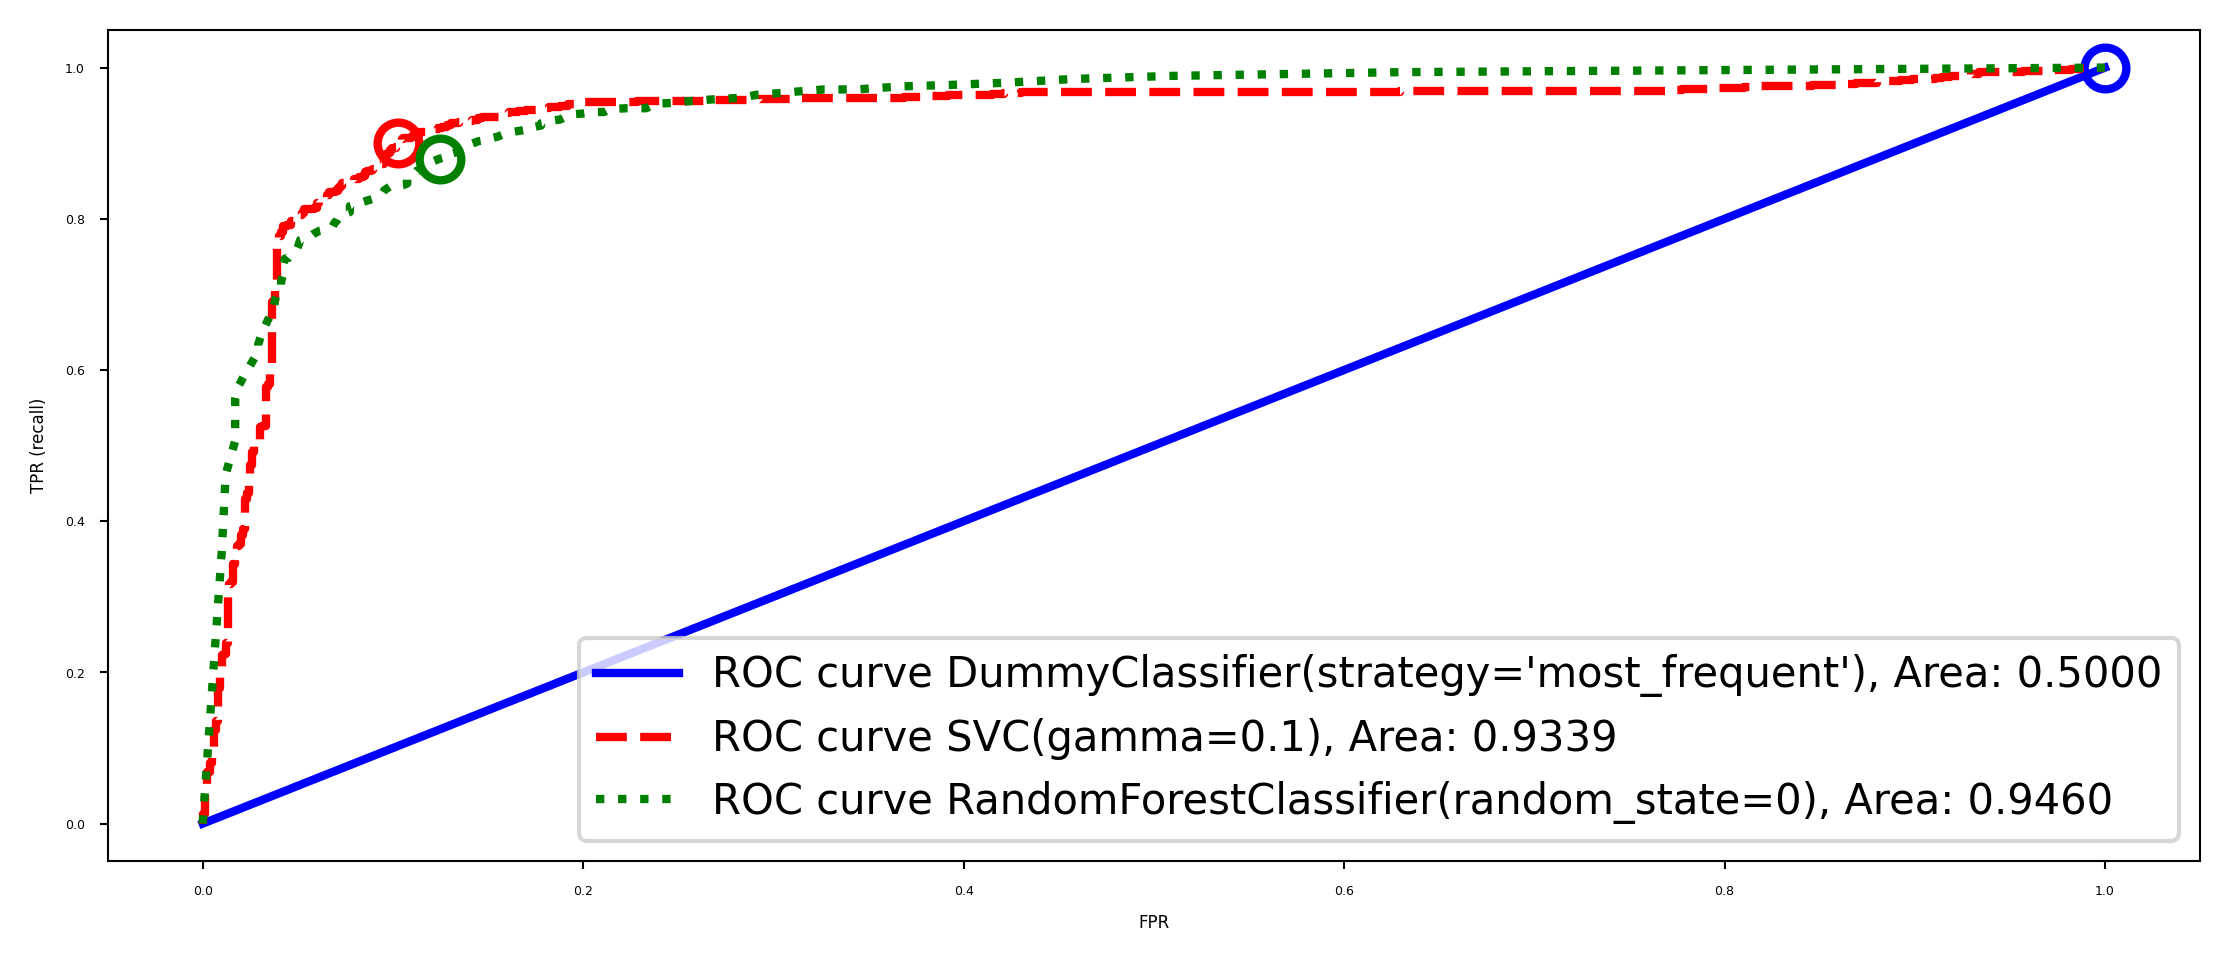

In [39]:
from sklearn.metrics import auc
from sklearn.dummy import DummyClassifier

def plot_ROC_curves(models):
    fig = plt.figure(figsize=(10*fig_scale,4*fig_scale))
    for i, model in enumerate(models):
        if hasattr(model, "predict_proba"):
            fpr, tpr, thresholds = roc_curve(
                yb_test, model.predict_proba(Xb_test)[:, 1])
            close_zero = np.argmin(np.abs(thresholds-0.5))
        else:
            fpr, tpr, thresholds = roc_curve(
                yb_test, model.decision_function(Xb_test))
            close_zero = np.argmin(np.abs(thresholds))
        plt.plot(fpr, tpr, lw=2, c=colors[i], label="ROC curve {}, Area: {:.4f}".format(model, auc(fpr, tpr))) 
        plt.plot(fpr[close_zero], tpr[close_zero], 'o', markersize=10,
                 fillstyle="none", c=colors[i], mew=2) #label="Default threshold {}".format(model)
        plt.ylabel("TPR (recall)")
        plt.xlabel("FPR")
        plt.legend(loc="lower right",prop={"size":10});
        
svc = SVC(gamma=.1).fit(Xb_train, yb_train)
rf = RandomForestClassifier(n_estimators=100, random_state=0).fit(Xb_train, yb_train)
dc = DummyClassifier(strategy='most_frequent').fit(Xb_train, yb_train)
plot_ROC_curves([dc, svc, rf])

#### Multi-class AUROC (or AUPRC) 
* We again need to choose between micro- or macro averaging TPR and FPR.
    * Micro-average if every sample is equally important (irrespective of class)
    * Macro-average if every class is equally important, especially for imbalanced data

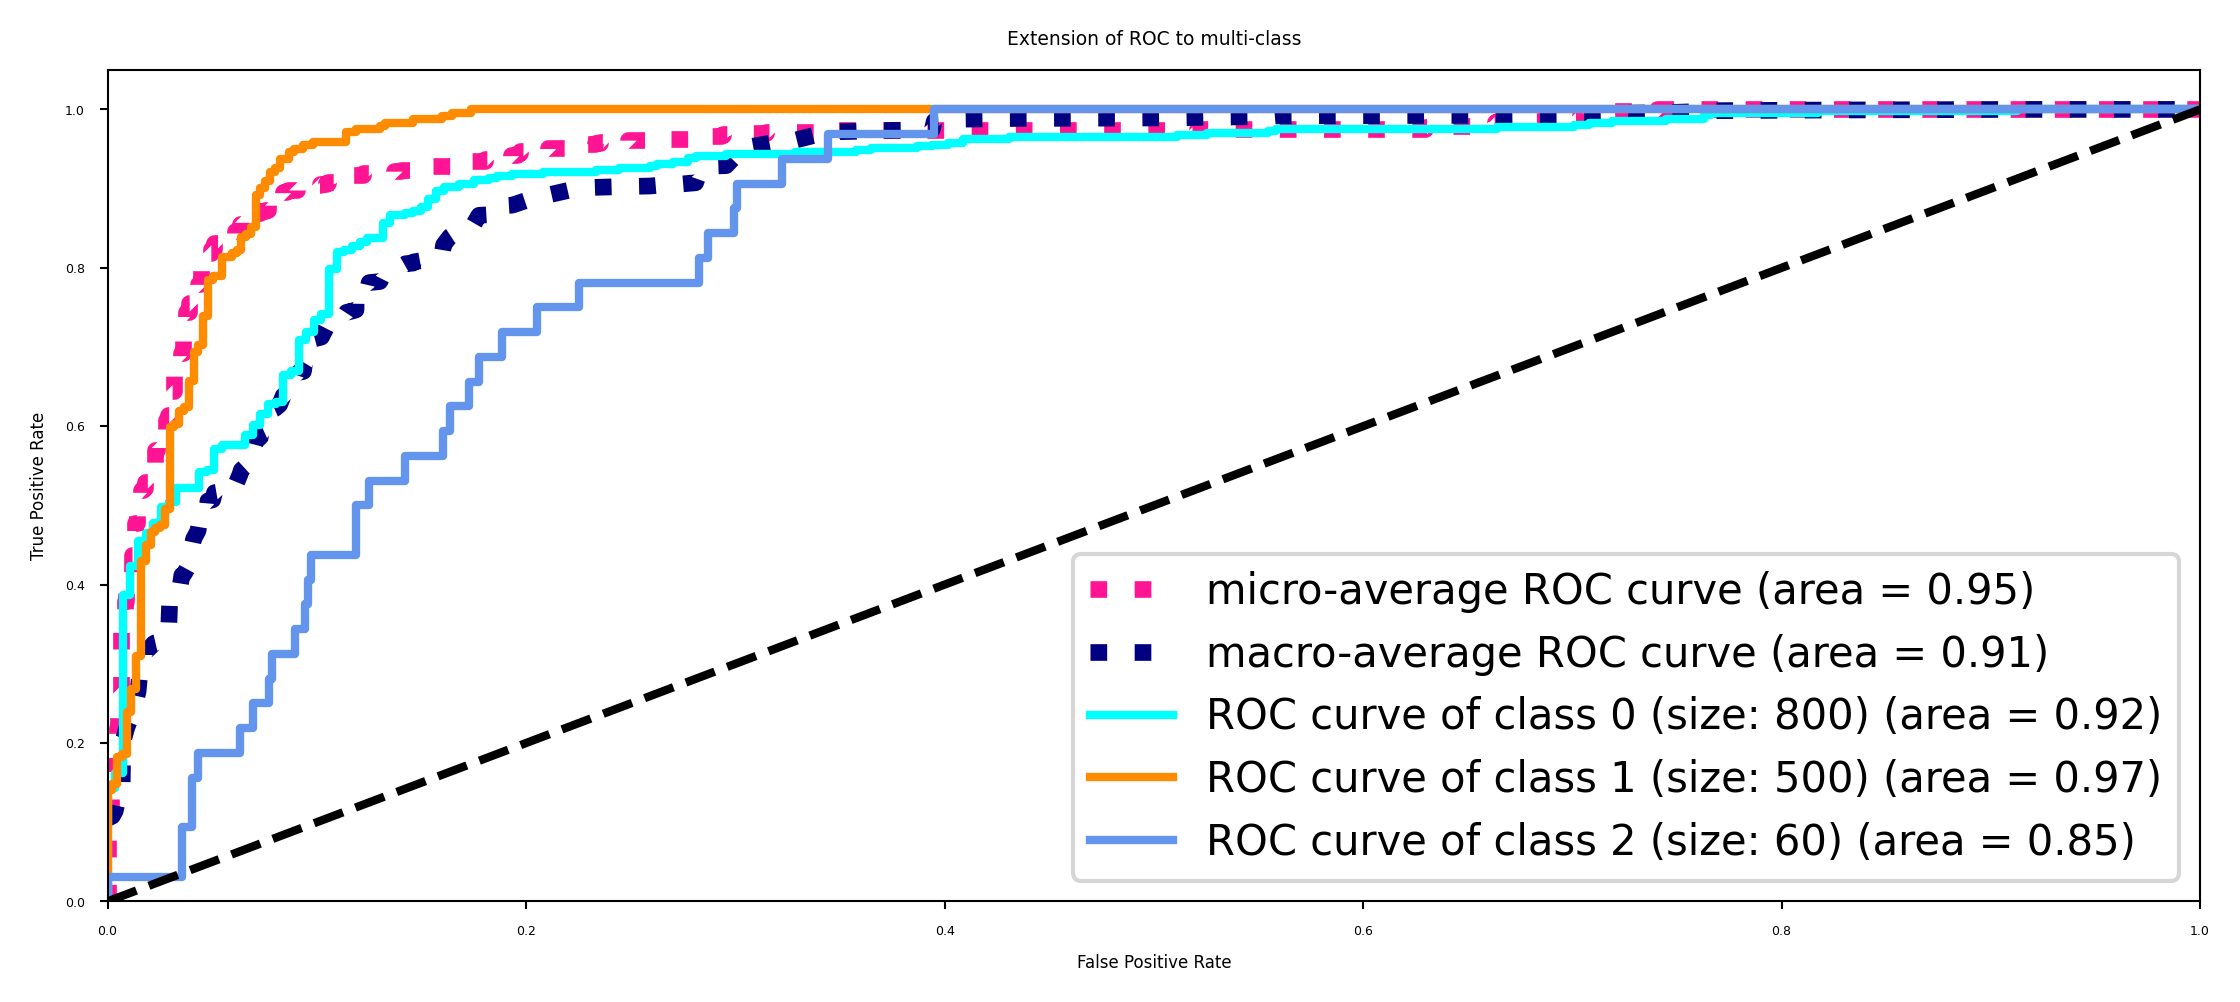

In [48]:
from itertools import cycle

from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from numpy import interp
from sklearn.metrics import roc_auc_score

# 3 class imbalanced data
Xi, yi = make_blobs(n_samples=(800, 500, 60), centers=None, cluster_std=[7.0, 2, 3.0], random_state=22)
sizes = [800, 500, 60]

# Binarize the output
yi = label_binarize(yi, classes=[0, 1, 2])
n_classes = yi.shape[1]
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=.5, random_state=0)

# Learn to predict each class against the other
classifier = OneVsRestClassifier(SVC(probability=True))
y_score = classifier.fit(Xi_train, yi_train).decision_function(Xi_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(yi_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(yi_test.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# First aggregate all false positive rates
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))

# Then interpolate all ROC curves at this points
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += interp(all_fpr, fpr[i], tpr[i])

# Finally average it and compute AUC
mean_tpr /= n_classes

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot all ROC curves
plt.figure(figsize=(10*fig_scale,4*fig_scale))

plt.plot(fpr["micro"], tpr["micro"],
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

plt.plot(fpr["macro"], tpr["macro"],
         label='macro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc["macro"]),
         color='navy', linestyle=':', linewidth=4)

colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, linestyle='-',
             label='ROC curve of class {} (size: {}) (area = {:0.2f})'
             ''.format(i, sizes[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Extension of ROC to multi-class')
plt.legend(loc="lower right", prop={"size":10})
plt.show()

### Bayesian Information Criterion (BIC)
**The problem:** a more complex model *always* fits the data it was trained on at least as well as a simpler one {cite}`hastie2009elements`. So "best fit" alone can't tell us which model to trust.

**The idea:** reward goodness of fit, but **penalize complexity**.

$$\text{BIC} = k \ln(n) - 2\ln(\hat L)$$

$$\text{AIC} = 2k - 2\ln(\hat L)$$

- $\hat L$ — maximized likelihood of the model (how well it fits)
- $k$ — number of estimated parameters (how complex it is)
- $n$ — number of data points

BIC was proposed by Schwarz {cite}`schwarz1978estimating` and AIC by Akaike {cite}`akaike1974new`; both are discussed in depth in {cite}`burnham2002model`.

**Lower is better** for both. The only difference is the penalty per parameter: AIC charges a flat **2**, BIC charges **ln(n)**, which is larger than 2 once $n \ge 8$. So BIC prefers simpler models than AIC, especially with lots of data.


#### 1. Data: a cubic function plus noise

The "truth" is a degree-3 polynomial. We will pretend we don't know that and try polynomials of different degrees. We also generate a separate **test set** to see how well each model generalizes to new data.

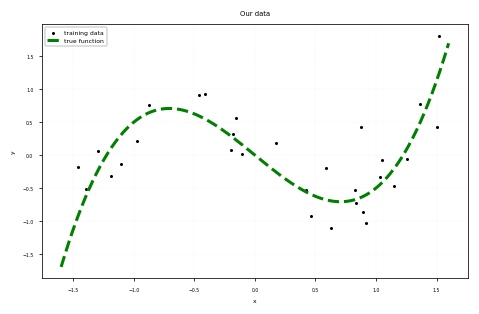

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from numpy.polynomial import Polynomial

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

def true_f(x):
    return x**3 - 1.5 * x      # the hidden "truth"

SIGMA = 0.5                    # noise level
N_TRAIN, N_TEST = 30, 200

def make_data(n, rng):
    x = rng.uniform(-1.6, 1.6, n)
    y = true_f(x) + rng.normal(0, SIGMA, n)
    return x, y

x_train, y_train = make_data(N_TRAIN, rng)
x_test,  y_test  = make_data(N_TEST, rng)

xx = np.linspace(-1.6, 1.6, 400)
plt.scatter(x_train, y_train, c="k", label="training data")
plt.plot(xx, true_f(xx), "g--", lw=2, label="true function")
plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Our data")
plt.show()

#### 2. Computing the log-likelihood, AIC and BIC

For a regression with Gaussian noise, the maximized log-likelihood has a closed form in terms of the residual sum of squares (RSS) {cite}`hastie2009elements`:

$$\ln \hat L = -\frac{n}{2}\left[\ln(2\pi) + \ln\!\left(\frac{\text{RSS}}{n}\right) + 1\right]$$

The parameter count is $k = (\text{degree} + 1)$ polynomial coefficients $+ 1$ for the noise variance.

In [43]:
def fit_poly(x, y, degree):
    # Polynomial.fit rescales x internally, which keeps high degrees numerically stable
    return Polynomial.fit(x, y, degree)

def gaussian_loglik(y, y_pred):
    n = len(y)
    rss = np.sum((y - y_pred) ** 2)
    return -n / 2 * (np.log(2 * np.pi) + np.log(rss / n) + 1)

def evaluate(degree, x_tr, y_tr, x_te=None, y_te=None):
    model = fit_poly(x_tr, y_tr, degree)
    n = len(y_tr)
    k = degree + 2                              # coefficients + variance
    ll = gaussian_loglik(y_tr, model(x_tr))
    out = {
        "degree": degree,
        "k": k,
        "train MSE": np.mean((y_tr - model(x_tr)) ** 2),
        "log-lik": ll,
        "fit term (-2 lnL)": -2 * ll,
        "AIC penalty (2k)": 2 * k,
        "BIC penalty (k ln n)": k * np.log(n),
        "AIC": 2 * k - 2 * ll,
        "BIC": k * np.log(n) - 2 * ll,
    }
    if x_te is not None:
        out["test MSE"] = np.mean((y_te - model(x_te)) ** 2)
    return out, model

## 3. Three models: too simple, too complex, balanced

- **Degree 1** (a straight line): too simple → *underfits*
- **Degree 12**: very flexible → fits the training points closely but *overfits* the noise
- **Degree 3**: matches the true structure → *balanced*

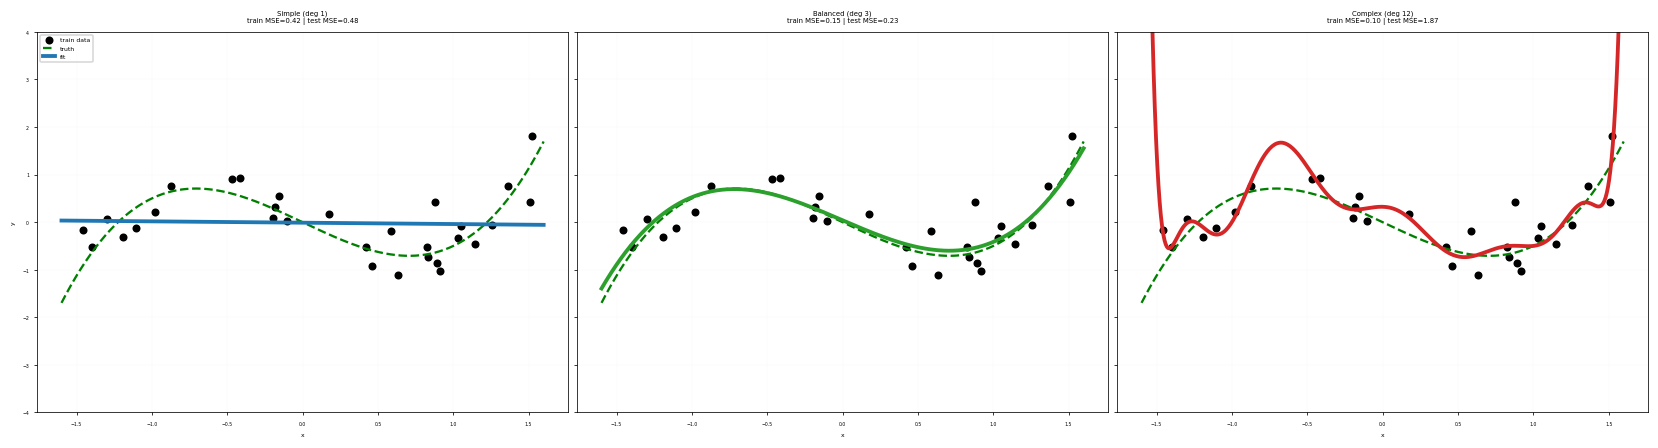

In [44]:
candidates = {"Simple (deg 1)": 1, "Balanced (deg 3)": 3, "Complex (deg 12)": 12}
colors     = {"Simple (deg 1)": "tab:blue", "Balanced (deg 3)": "tab:green", "Complex (deg 12)": "tab:red"}

rows, models = [], {}
for name, d in candidates.items():
    r, m = evaluate(d, x_train, y_train, x_test, y_test)
    r["model"] = name
    rows.append(r); models[name] = m

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, d), r in zip(axes, candidates.items(), rows):
    ax.scatter(x_train, y_train, c="k", s=18, label="train data")
    ax.plot(xx, true_f(xx), "g--", lw=1.5, label="truth")
    ax.plot(xx, models[name](xx), color=colors[name], lw=2.5, label="fit")
    ax.set_title(f"{name}\ntrain MSE={r['train MSE']:.2f} | test MSE={r['test MSE']:.2f}")
    ax.set_ylim(-4, 4); ax.set_xlabel("x")
axes[0].legend(loc="upper left"); axes[0].set_ylabel("y")
plt.tight_layout(); plt.show()

In [45]:
df = pd.DataFrame(rows).set_index("model")
cols = ["degree", "k", "train MSE", "test MSE", "log-lik", "AIC", "BIC"]
display(df[cols].round(2))

print("Best by train MSE:", df["train MSE"].idxmin())
print("Best by AIC      :", df["AIC"].idxmin())
print("Best by BIC      :", df["BIC"].idxmin())
print("Best by test MSE :", df["test MSE"].idxmin(), " (what we really care about)")

,degree,k,train MSE,test MSE,log-lik,AIC,BIC
model,,,,,,,
Simple (deg 1),1,3,0.42,0.48,-29.67,65.34,69.54
Balanced (deg 3),3,5,0.15,0.23,-14.33,38.66,45.66
Complex (deg 12),12,14,0.10,1.87,-8.15,44.30,63.92


Best by train MSE: Complex (deg 12)
Best by AIC      : Balanced (deg 3)
Best by BIC      : Balanced (deg 3)
Best by test MSE : Balanced (deg 3)  (what we really care about)


### Visualizing the trade-off

Both criteria are a sum of two pieces:

- **Fit term** $-2\ln\hat L$ — gets *smaller* as the model fits better
- **Penalty term** — gets *larger* as the model gets more complex

The winner is the model where the total is lowest.

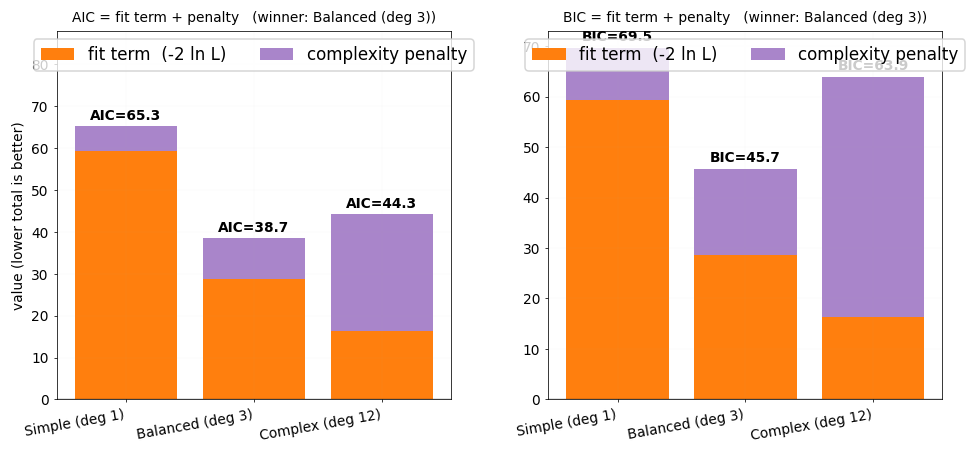

In [65]:
names = list(df.index)
x_pos = np.arange(len(names))
w = 0.38

fig, axes = plt.subplots(1, 2, figsize=(10*fig_scale, 4.5*fig_scale), sharey=False)

for ax, crit, pen_col in zip(axes, ["AIC", "BIC"], ["AIC penalty (2k)", "BIC penalty (k ln n)"]):
    fit_term = df["fit term (-2 lnL)"].values
    pen = df[pen_col].values

    ax.bar(x_pos, fit_term, color="tab:orange", label="fit term  (-2 ln L)")
    ax.bar(x_pos, pen,
           bottom=np.where(fit_term > 0, fit_term, 0),
           color="tab:purple", alpha=0.8, label="complexity penalty")

    for i, total in enumerate(df[crit].values):
        ax.text(i, max(fit_term[i], 0) + pen[i] + 1.5,
                f"{crit}={total:.1f}",
                ha="center", fontweight="bold", fontsize=9)

    best = int(np.argmin(df[crit].values))
    ax.set_xticks(x_pos)
    ax.set_xticklabels(names, rotation=10, ha="right", fontsize=9)
    ax.tick_params(axis="y", labelsize=9)
    ax.set_title(f"{crit} = fit term + penalty   (winner: {names[best]})", fontsize=9)
    ax.axhline(0, color="k", lw=0.8)
    ax.legend(loc="upper center", ncol=2, fontsize=11)

axes[0].set_ylim(0, 88)
axes[0].set_ylabel("value (lower total is better)", fontsize=9)
plt.tight_layout()
plt.show()

The complex model has a slightly better fit term, but pays a much larger complexity penalty. The simple model has a tiny penalty but a terrible fit term. The balanced model sits at the sweet spot.

## 4. Sweeping model complexity

Instead of three hand-picked models, let's fit polynomials of **every degree from 0 to 14** and watch how each metric behaves.

Degree chosen by AIC: 5 | BIC: 3 | lowest test MSE: 3 | truth: 3


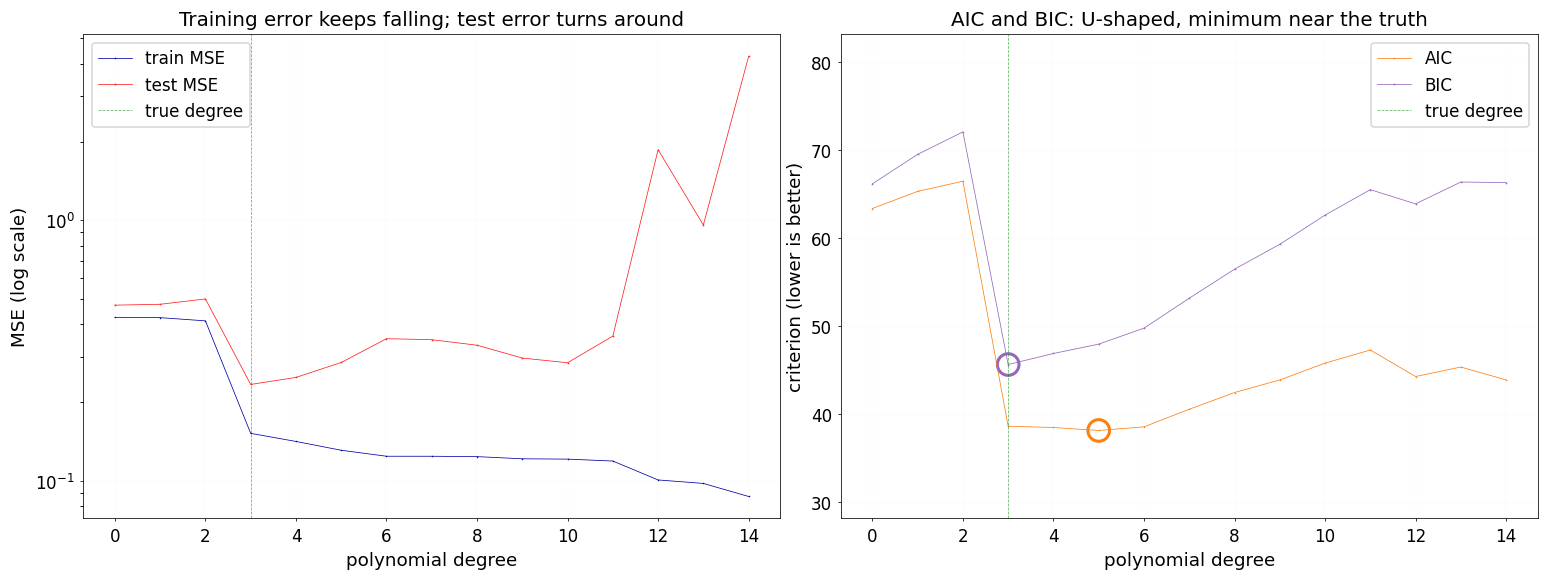

In [67]:
degrees = range(0, 15)
sweep = pd.DataFrame([evaluate(d, x_train, y_train, x_test, y_test)[0] for d in degrees]).set_index("degree")

best_aic, best_bic, best_test = sweep["AIC"].idxmin(), sweep["BIC"].idxmin(), sweep["test MSE"].idxmin()
print(f"Degree chosen by AIC: {best_aic} | BIC: {best_bic} | lowest test MSE: {best_test} | truth: 3")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

ax = axes[0]
ax.plot(sweep.index, sweep["train MSE"], "o-", label="train MSE")
ax.plot(sweep.index, sweep["test MSE"], "s-", label="test MSE")
ax.set_yscale("log")
ax.axvline(3, color="g", ls="--", alpha=0.6, label="true degree")
ax.set_xlabel("polynomial degree", fontsize=12)
ax.set_ylabel("MSE (log scale)", fontsize=12)
ax.set_title("Training error keeps falling; test error turns around", fontsize=13)
ax.tick_params(axis="both", labelsize=11)
ax.legend(fontsize=11)

ax = axes[1]
ax.plot(sweep.index, sweep["AIC"], "o-", color="tab:orange", label="AIC")
ax.plot(sweep.index, sweep["BIC"], "s-", color="tab:purple", label="BIC")
ax.axvline(3, color="g", ls="--", alpha=0.6, label="true degree")
ax.scatter([best_aic], [sweep.loc[best_aic, "AIC"]], s=200, facecolors="none", edgecolors="tab:orange", lw=2)
ax.scatter([best_bic], [sweep.loc[best_bic, "BIC"]], s=200, facecolors="none", edgecolors="tab:purple", lw=2)
ax.set_ylim(sweep[["AIC", "BIC"]].min().min() - 10, sweep[["AIC", "BIC"]].min().min() + 45)
ax.set_xlabel("polynomial degree", fontsize=12)
ax.set_ylabel("criterion (lower is better)", fontsize=12)
ax.set_title("AIC and BIC: U-shaped, minimum near the truth", fontsize=13)
ax.tick_params(axis="both", labelsize=11)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

**Why?** Intuitively, with more data, small improvements in fit become easier to obtain by chance from extra parameters, so BIC raises the bar. Theoretically:

- **BIC** is derived as an approximation to the Bayesian *marginal likelihood* (model evidence) {cite}`schwarz1978estimating,kass1995bayes`. It is **consistent**: if the true model is among the candidates, BIC picks it with probability → 1 as $n \to \infty$ {cite}`nishii1984asymptotic`.
- **AIC** is derived from minimizing expected prediction error, measured by the Kullback–Leibler divergence {cite}`akaike1974new,kullback1951information`. It's **efficient** for prediction but tends to pick slightly *over-complex* models, and is not consistent {cite}`burnham2002model,nishii1984asymptotic`.

## 6. Repeating the experiment 500 times

One dataset can be lucky or unlucky. Let's regenerate the data many times and count how often each criterion picks each degree (candidate degrees 0–10).

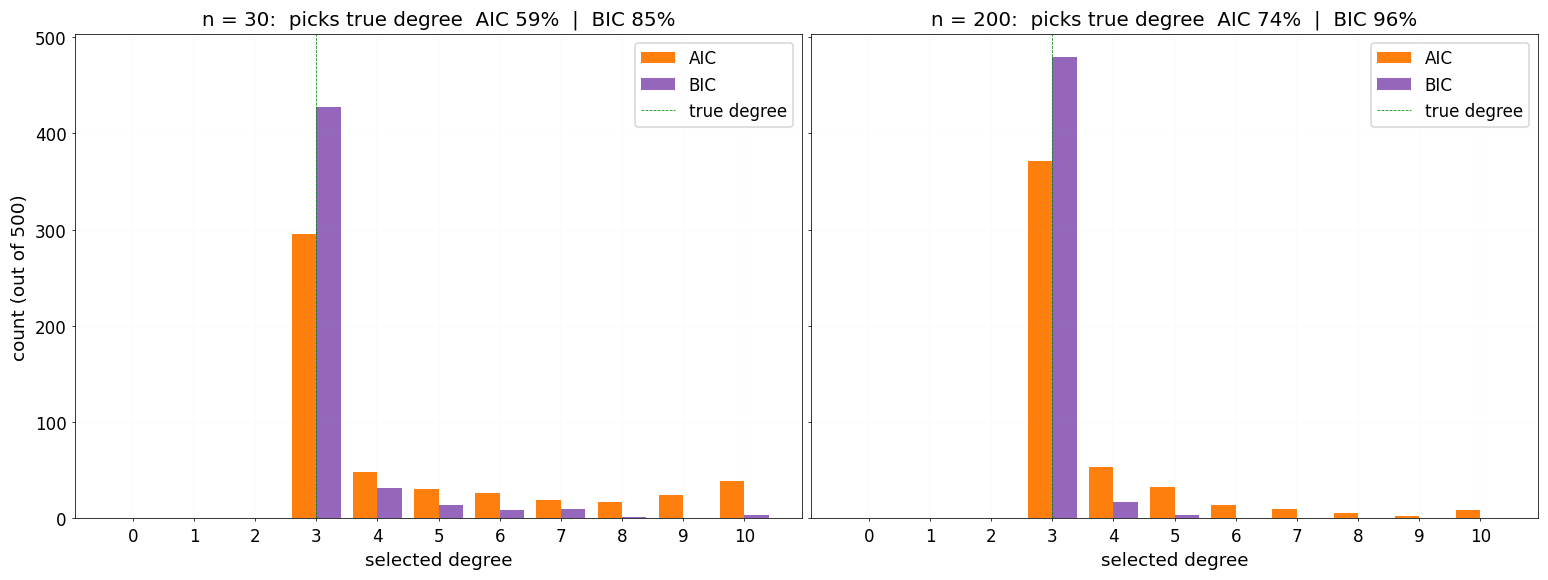

In [77]:
def select_degrees(n, n_rep=500, max_deg=10, seed=0):
    rng = np.random.default_rng(seed)
    picks = {"AIC": [], "BIC": []}
    for _ in range(n_rep):
        x, y = make_data(n, rng)
        aic, bic = [], []
        for d in range(max_deg + 1):
            r, _ = evaluate(d, x, y)
            aic.append(r["AIC"]); bic.append(r["BIC"])
        picks["AIC"].append(int(np.argmin(aic)))
        picks["BIC"].append(int(np.argmin(bic)))
    return picks

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)

for ax, n in zip(axes, [30, 200]):
    picks = select_degrees(n)
    bins = np.arange(-0.5, 11.5, 1)
    ax.hist([picks["AIC"], picks["BIC"]], bins=bins,
            color=["tab:orange", "tab:purple"], label=["AIC", "BIC"])
    ax.axvline(3, color="g", ls="--", label="true degree")
    p_aic = np.mean(np.array(picks["AIC"]) == 3)
    p_bic = np.mean(np.array(picks["BIC"]) == 3)
    ax.set_title(f"n = {n}:  picks true degree  AIC {p_aic:.0%}  |  BIC {p_bic:.0%}",
                 fontsize=13)
    ax.set_xlabel("selected degree", fontsize=12)
    ax.set_xticks(range(0, 11))
    ax.tick_params(axis="both", labelsize=11)
    ax.legend(fontsize=11)

axes[0].set_ylabel("count (out of 500)", fontsize=12)
plt.tight_layout()
plt.show()

AIC often over-selects (degree 4, 5, or even 10), because its penalty is small and never grows. BIC picks the true degree far more often, and its success rate climbs toward 100% as $n$ increases (consistency). AIC's over-selection rate shrinks with more data too, but it does not vanish: AIC is not consistent {cite}`nishii1984asymptotic`.

## Takeaways

| | **AIC** | **BIC** |
|---|---|---|
| Penalty per parameter | $2$ | $\ln(n)$ |
| Goal | Best *predictions* | Find the *true* model (if it's among candidates) |
| Tendency | Slightly favors complex models | Favors simpler models, more so as $n$ grows |
| Rule of thumb | Use when prediction is the aim | Use when interpretability / "true structure" is the aim |

**Practical notes**
- Lower is better; only **differences** between models matter, not absolute values. For AIC/BIC, differences of ~2 are weak evidence, and >10 is strong {cite}`burnham2002model,kass1995bayes`.
- All models must be fit to the **same data** and use the **same likelihood family**.
- Both assume the likelihood is correctly specified and $n$ is reasonably larger than $k$. For small $n$, consider AICc {cite}`hurvich1989regression`: $\text{AICc} = \text{AIC} + \frac{2k(k+1)}{n-k-1}$.
- Neither replaces cross-validation or domain knowledge — they're fast, principled shortcuts {cite}`hastie2009elements`.



### Model calibration

* For some models, the _predicted_ uncertainty does not reflect the _actual_ uncertainty
    * If a model is 90% sure that samples are positive, is it also 90% accurate on these?
* A model is called _calibrated_ if the reported uncertainty actually matches how correct it is  
    * Overfitted models also tend to be over-confident
    * LogisticRegression models are well calibrated since they learn probabilities
    * SVMs are not well calibrated. _Biased_ towards points close to the decision boundary.

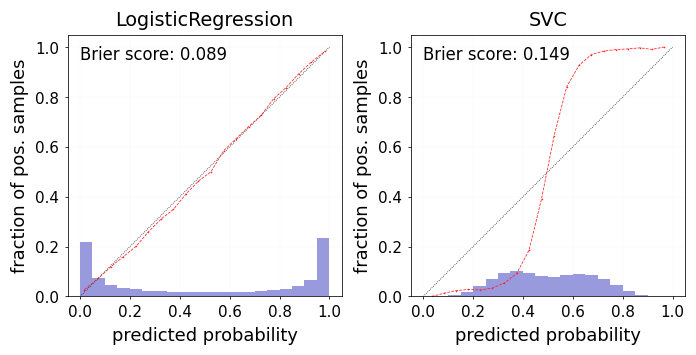

In [78]:
from sklearn.svm import SVC
from sklearn.datasets import make_classification
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, accuracy_score

def load_data():
    X, y = make_classification(n_samples=100000, n_features=20, random_state=0)
    train_samples = 2000
    X_train = X[:train_samples]
    X_test = X[train_samples:]
    y_train = y[:train_samples]
    y_test = y[train_samples:]
    return X_train, X_test, y_train, y_test

Xc_train, Xc_test, yc_train, yc_test = load_data()

def plot_calibration_curve(y_true, y_prob, n_bins=5, ax=None, hist=True, normalize=False):
    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=n_bins)
    if ax is None:
        ax = plt.gca()
    if hist:
        ax.hist(y_prob, weights=np.ones_like(y_prob) / len(y_prob), alpha=.4,
               bins=np.maximum(10, n_bins))
    ax.plot([0, 1], [0, 1], ':', c='k')
    curve = ax.plot(prob_pred, prob_true, marker="o")

    ax.set_xlabel("predicted probability", fontsize=13*fig_scale)
    ax.set_ylabel("fraction of pos. samples", fontsize=13*fig_scale)
    ax.tick_params(axis="both", labelsize=11*fig_scale)
    ax.set(aspect='equal')
    return curve

def plot_calibration_comparison(models, calibrator=None, calibratee=None):
    def get_probabilities(clf, X):
        if hasattr(clf, "predict_proba"):
            prob_pos = clf.predict_proba(X)[:, 1]
        else:
            prob_pos = clf.decision_function(X)
            prob_pos = (prob_pos - prob_pos.min()) / (prob_pos.max() - prob_pos.min())
        return prob_pos

    nr_plots = len(models)
    if calibrator:
        nr_plots += 1
    fig, axes = plt.subplots(1, nr_plots,
                             figsize=(3.5*nr_plots*fig_scale, 4.5*nr_plots*fig_scale))

    for ax, clf in zip(axes[:len(models)], models):
        clf.fit(Xc_train, yc_train)
        prob_pos = get_probabilities(clf, Xc_test)
        bs = brier_score_loss(yc_test, prob_pos)
        plot_calibration_curve(yc_test, prob_pos, n_bins=20, ax=ax)
        ax.set_title(clf.__class__.__name__, fontsize=14*fig_scale)
        ax.text(0, 0.95, "Brier score: {:.3f}".format(bs), size=12*fig_scale)

    if calibrator:
        calibratee.fit(Xc_train, yc_train)
        prob_pos = get_probabilities(calibratee, Xc_train)
        y_sort = [x for _, x in sorted(zip(prob_pos, yc_train))]
        prob_pos.sort()
        cal_prob = calibrator.fit(prob_pos, y_sort).predict(prob_pos)
        axes[-1].scatter(prob_pos, y_sort, s=2)
        axes[-1].scatter(prob_pos, cal_prob, s=2)
        axes[-1].plot(prob_pos, cal_prob)
        axes[-1].set_title("Calibrator: {}".format(calibrator.__class__.__name__),
                           fontsize=14*fig_scale)
        axes[-1].set_xlabel("predicted probability", fontsize=13*fig_scale)
        axes[-1].set_ylabel("outcome", fontsize=13*fig_scale)
        axes[-1].tick_params(axis="both", labelsize=11*fig_scale)
        axes[-1].set(aspect='equal')

    plt.tight_layout()

plot_calibration_comparison([LogisticRegression(), SVC()])

#### Brier score
* You may want to select models based on how accurate the class confidences are.
* The **Brier score loss**: squared loss between predicted probability $\hat{p}$ and actual outcome $y$
    * Lower is better
$$\mathcal{L}_{Brier} =  \frac{1}{n}\sum_{i=1}^n (\hat{p}_i - y_i)^2$$

In [50]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import brier_score_loss
cancer = load_breast_cancer()
XC_train, XC_test, yC_train, yC_test = train_test_split(cancer.data, cancer.target, test_size=.5, random_state=0)

# LogReg
logreg = LogisticRegression().fit(XC_train, yC_train)
probs = logreg.predict_proba(XC_test)[:,1]
print("Logistic Regression Brier score loss: {:.4f}".format(brier_score_loss(yC_test,probs)))

# SVM: scale decision functions
svc = SVC().fit(XC_train, yC_train)
prob_pos = svc.decision_function(XC_test)
prob_pos = (prob_pos - prob_pos.min()) / (prob_pos.max() - prob_pos.min())
print("SVM Brier score loss: {:.4f}".format(brier_score_loss(yC_test,prob_pos)))

Logistic Regression Brier score loss: 0.0322
SVM Brier score loss: 0.0795


#### Model calibration techniques

* We can post-process trained models to make them more calibrated.
* Fit a regression model (a calibrator) to map the model's outcomes $f(x)$ to a calibrated probability in [0,1]
    * $f(x)$ returns the decision values or probability estimates
    * $f_{calib}$ is fitted on the training data to map these to the correct outcome
        * Often an internal cross-validation with few folds is used
    * Multi-class models require one calibrator per class

$$f_{calib}(f(x))≈p(y)$$

Raw scores range: -2.32 to 1.09
Brier score raw (min-max) : 0.2029
Brier score sigmoid       : 0.1012
Brier score isotonic      : 0.1008


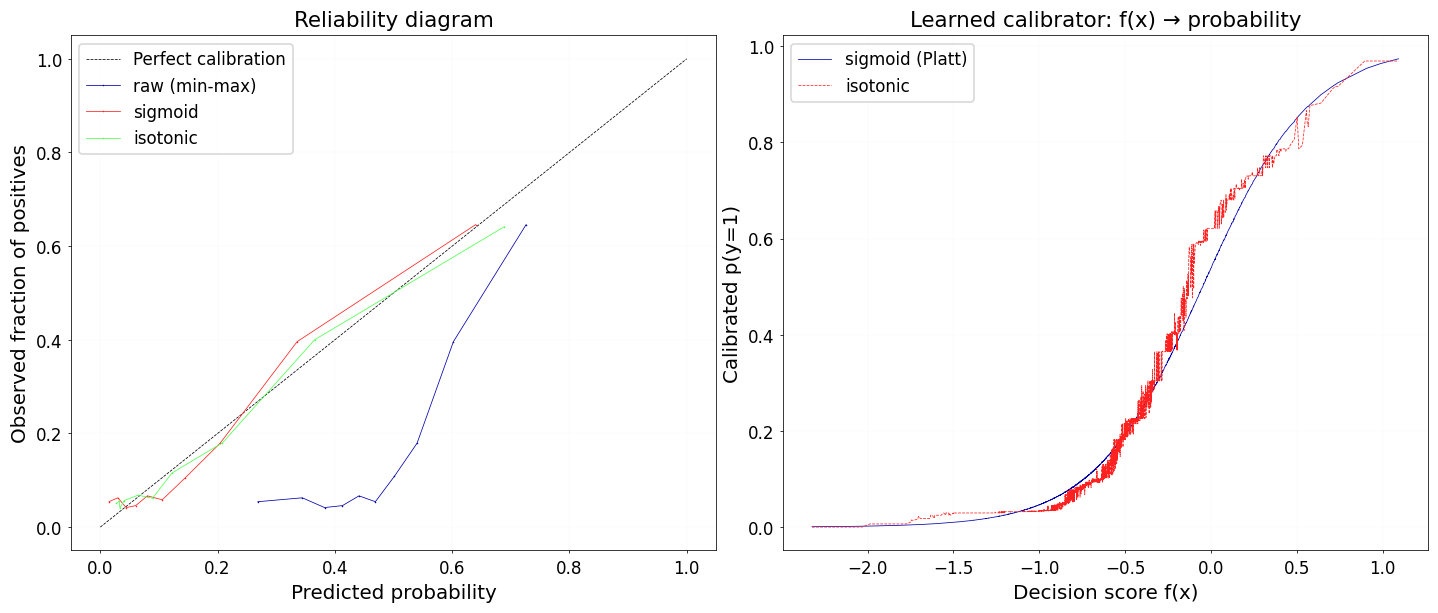

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss


X, y = make_classification(n_samples=6000, n_features=20, n_informative=5,
                           weights=[0.85, 0.15], flip_y=0.05, class_sep=0.8,
                           random_state=0)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.4, stratify=y, random_state=0)

# gives decision scores f(x), NOT probabilities
svm = LinearSVC(random_state=0).fit(X_tr, y_tr)
scores = svm.decision_function(X_te)
print("Raw scores range:", scores.min().round(2), "to", scores.max().round(2))

# regression model mapping f(x) -> p(y=1)
calib_sig = CalibratedClassifierCV(LinearSVC(random_state=0), method="sigmoid",  cv=5).fit(X_tr, y_tr)
calib_iso = CalibratedClassifierCV(LinearSVC(random_state=0), method="isotonic", cv=5).fit(X_tr, y_tr)
p_sig = calib_sig.predict_proba(X_te)[:, 1]
p_iso = calib_iso.predict_proba(X_te)[:, 1]

# rescale the raw scores to [0, 1]
p_raw = (scores - scores.min()) / (scores.max() - scores.min())

for name, p in [("raw (min-max)", p_raw), ("sigmoid", p_sig), ("isotonic", p_iso)]:
    print(f"Brier score {name:14s}: {brier_score_loss(y_te, p):.4f}")


fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))

ax[0].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for name, p in [("raw (min-max)", p_raw), ("sigmoid", p_sig), ("isotonic", p_iso)]:
    frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax[0].plot(mean_pred, frac_pos, "o-", label=name)
ax[0].set_xlabel("Predicted probability", fontsize=13)
ax[0].set_ylabel("Observed fraction of positives", fontsize=13)
ax[0].set_title("Reliability diagram", fontsize=14)
ax[0].tick_params(axis="both", labelsize=11)
ax[0].legend(fontsize=11)

order = np.argsort(scores)
ax[1].plot(scores[order], p_sig[order], label="sigmoid (Platt)")
ax[1].plot(scores[order], p_iso[order], label="isotonic")
ax[1].set_xlabel("Decision score f(x)", fontsize=13)
ax[1].set_ylabel("Calibrated p(y=1)", fontsize=13)
ax[1].set_title("Learned calibrator: f(x) → probability", fontsize=14)
ax[1].tick_params(axis="both", labelsize=11)
ax[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

##### Platt Scaling
* Calibrator is a logistic (sigmoid) function:
    * Learn the weight $w_1$ and bias $w_0$ from data
$$f_{platt}=\frac{1}{1+\exp(−w_1 f(x)− w_0)}$$

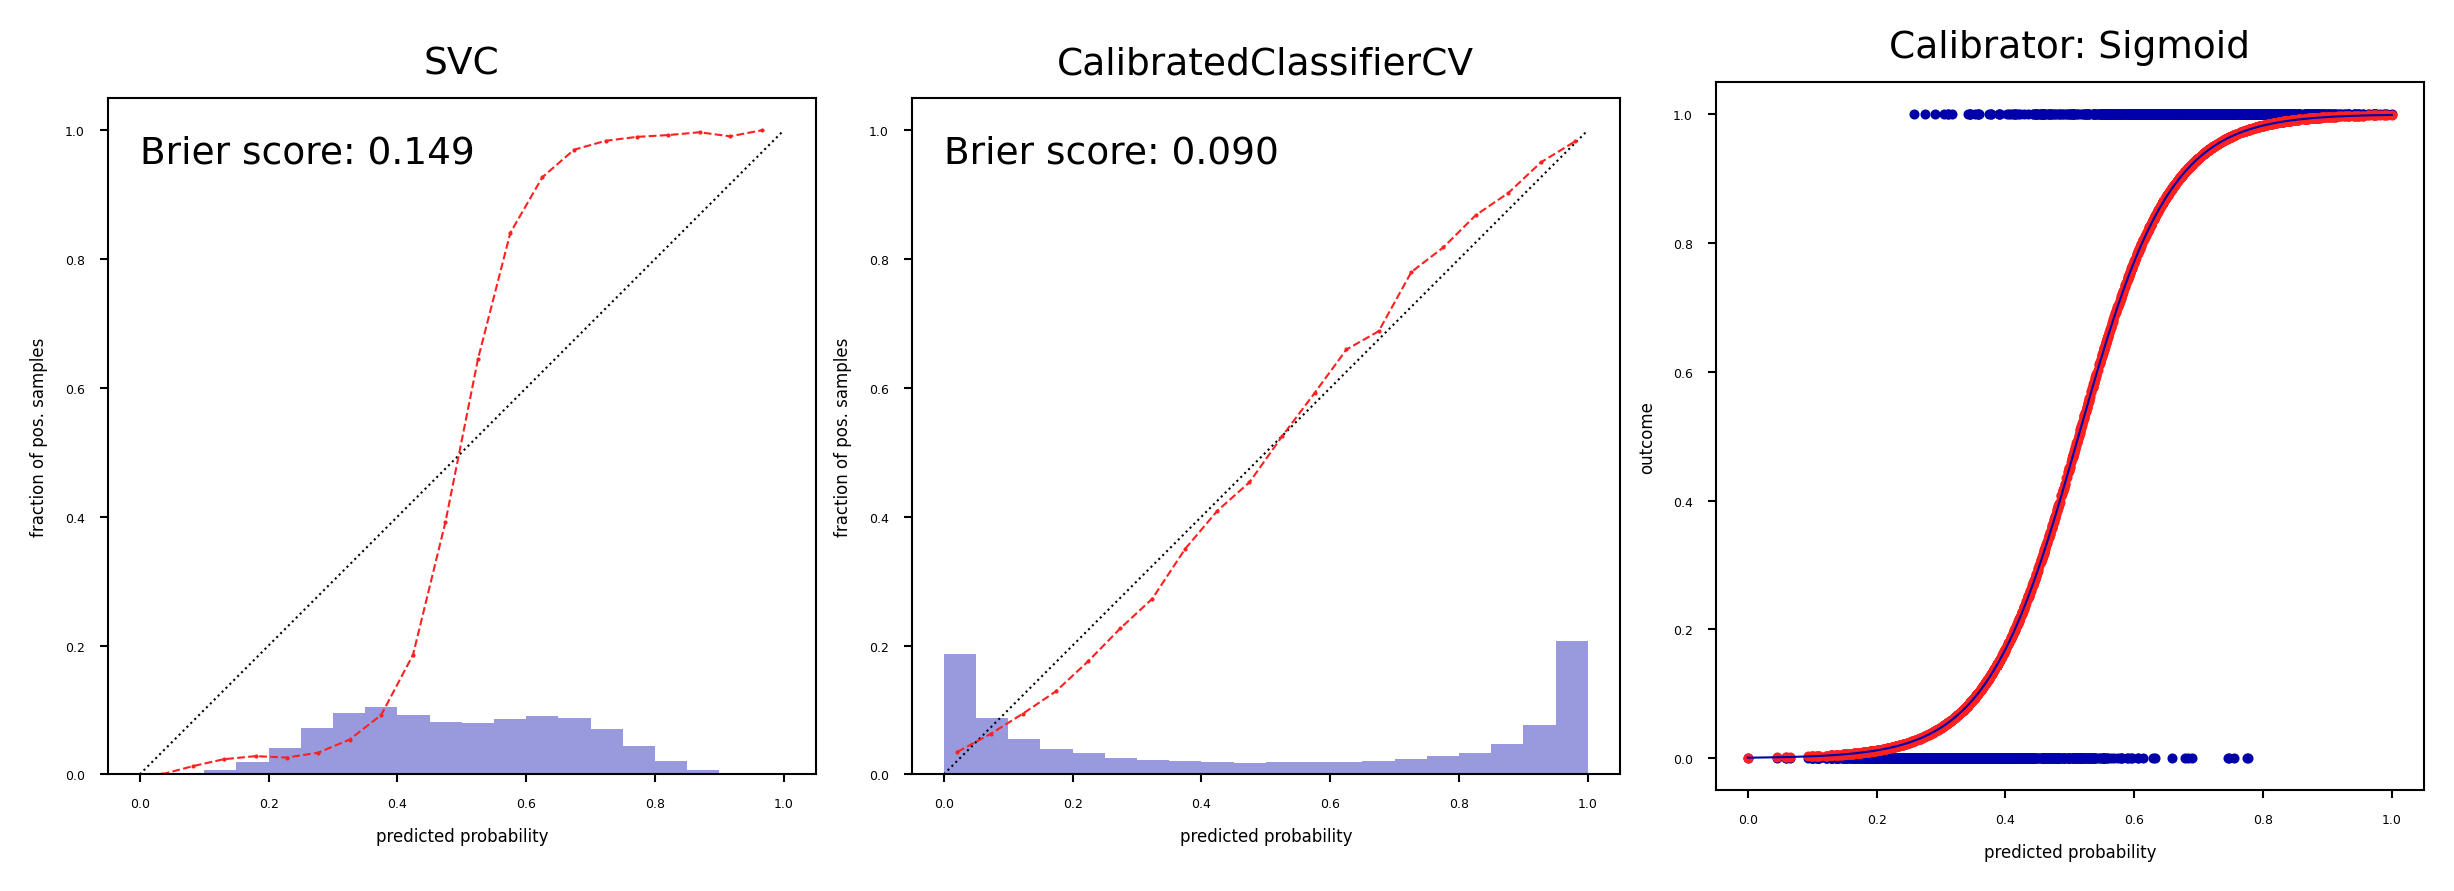

In [52]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression

# Wrapped LogisticRegression to get sigmoid predictions
class Sigmoid():
    model = LogisticRegression()
    
    def fit(self, X, y):
        self.model.fit(X.reshape(-1, 1),y)
        return self

    def predict(self, X):
        return self.model.predict_proba(X.reshape(-1, 1))[:, 1]
        
svm = SVC()
svm_platt = CalibratedClassifierCV(svm, cv=2, method='sigmoid')
plot_calibration_comparison([svm, svm_platt],Sigmoid(),svm)

##### Isotonic regression
* Maps input $x_i$ to an output $\hat{y}_i$ so that $\hat{y}_i$ increases monotonically with $x_i$ and minimizes loss $\sum_i^n ((y_i-\hat{y}_i))^2$
    * Predictions are made by interpolating the predicted $\hat{y}_i$
* Fit to minimize the loss between the uncalibrated predictions $f(x)$ and the actual labels 
* Corrects any monotonic distortion, but tends to overfit on small samples

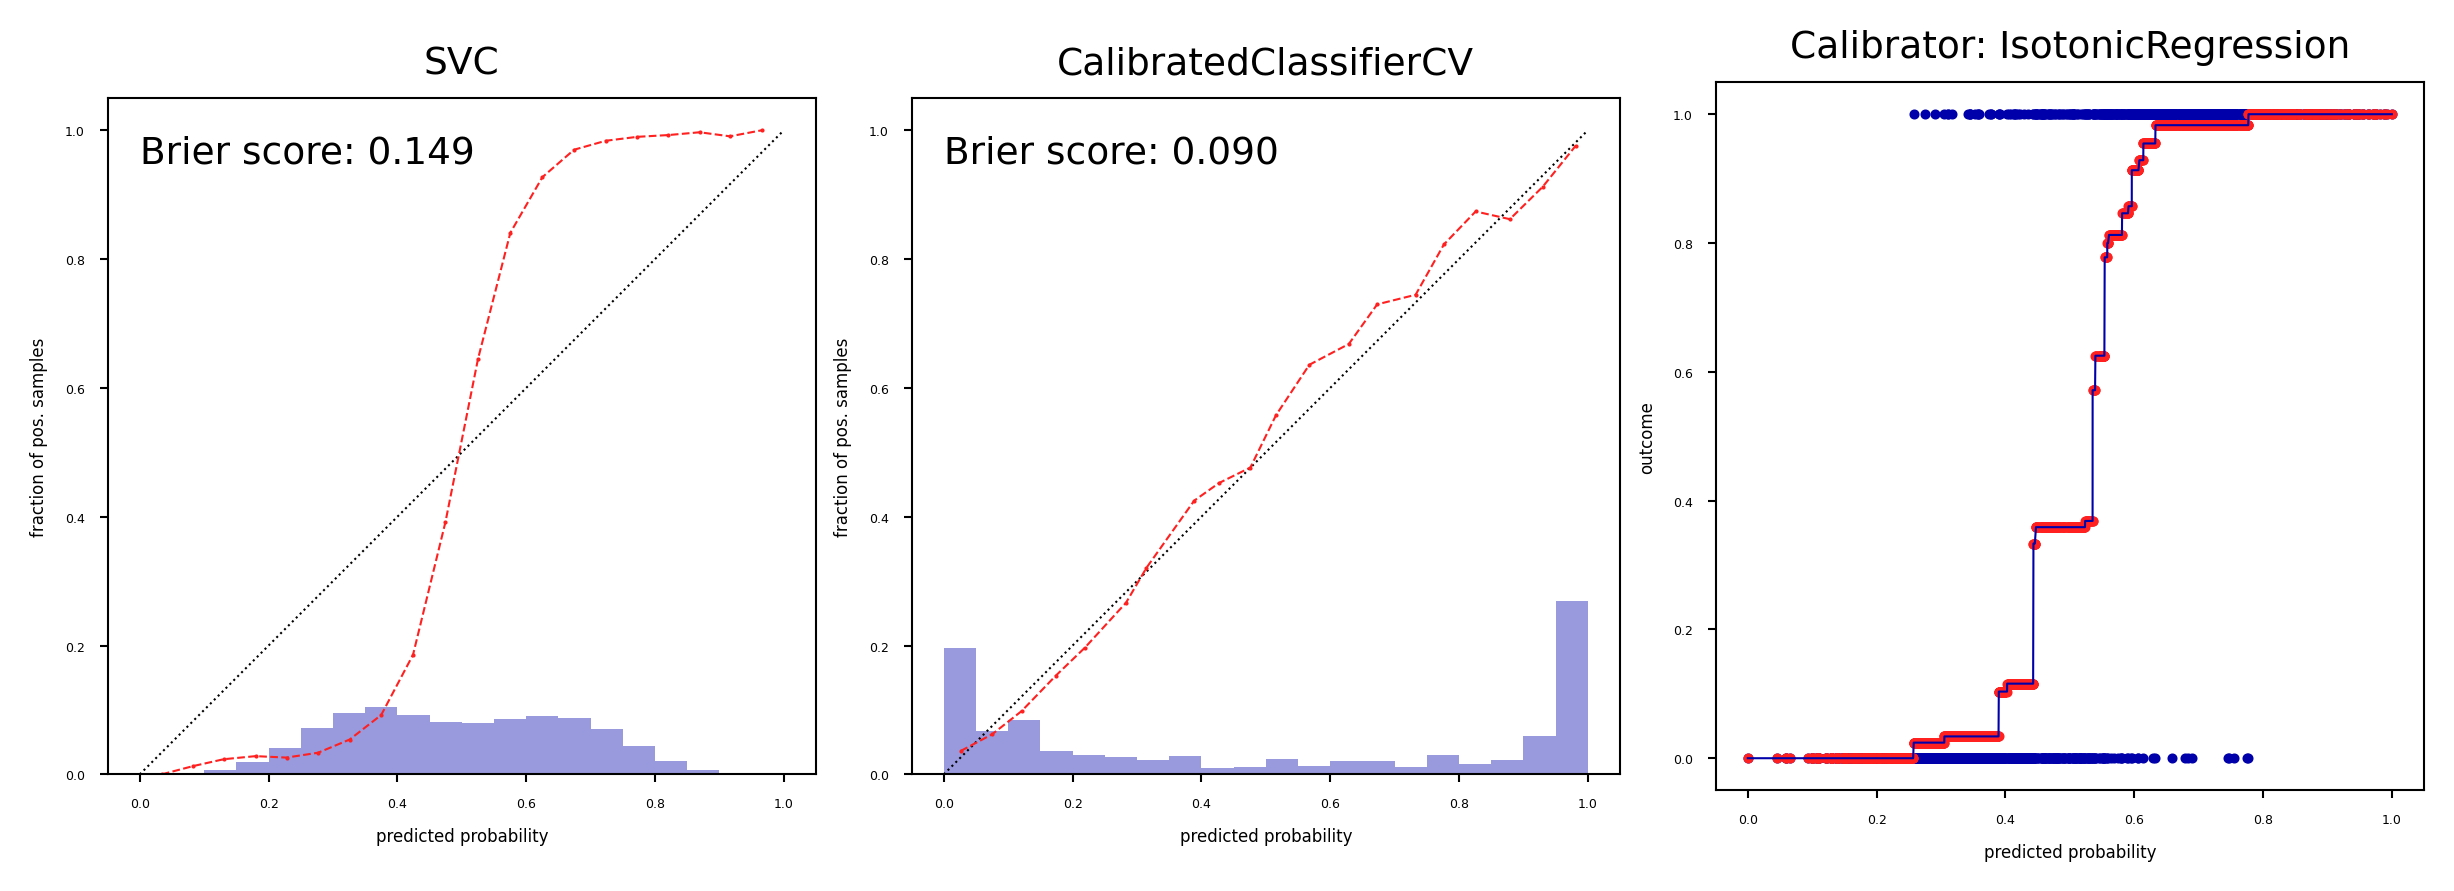

In [53]:
from sklearn.isotonic import IsotonicRegression

model = SVC()
iso = CalibratedClassifierCV(model, cv=2, method='isotonic')
plot_calibration_comparison([model, iso],IsotonicRegression(),model)

## Cost-sensitive classification (dealing with imbalance)
* In the real world, different kinds of misclassification can have different costs 
    - Misclassifying certain classes can be more costly than others 
    - Misclassifying certain samples can be more costly than others 
* Cost-sensitive resampling: resample (or reweight) the data to represent real-world expectations
    - oversample minority classes (or undersample majority) to 'correct' imbalance
    - increase weight of misclassified samples (e.g. in boosting)
    - decrease weight of misclassified (noisy) samples (e.g. in model compression)

### Class weighting
* If some classes are more important than others, we can give them more weight
    * E.g. for imbalanced data, we can give more weight to minority classes
* Most classification models can include it in their loss function and optimize for it
    * E.g. Logistic regression: add a class weight $w_c$ in the log loss function
$$\mathcal{L_{log}}(\mathbf{w}) = - \sum_{c=1}^{C} \color{red}{w_c} \sum_{n=1}^{N} p_{n,c} log(q_{n,c}) $$

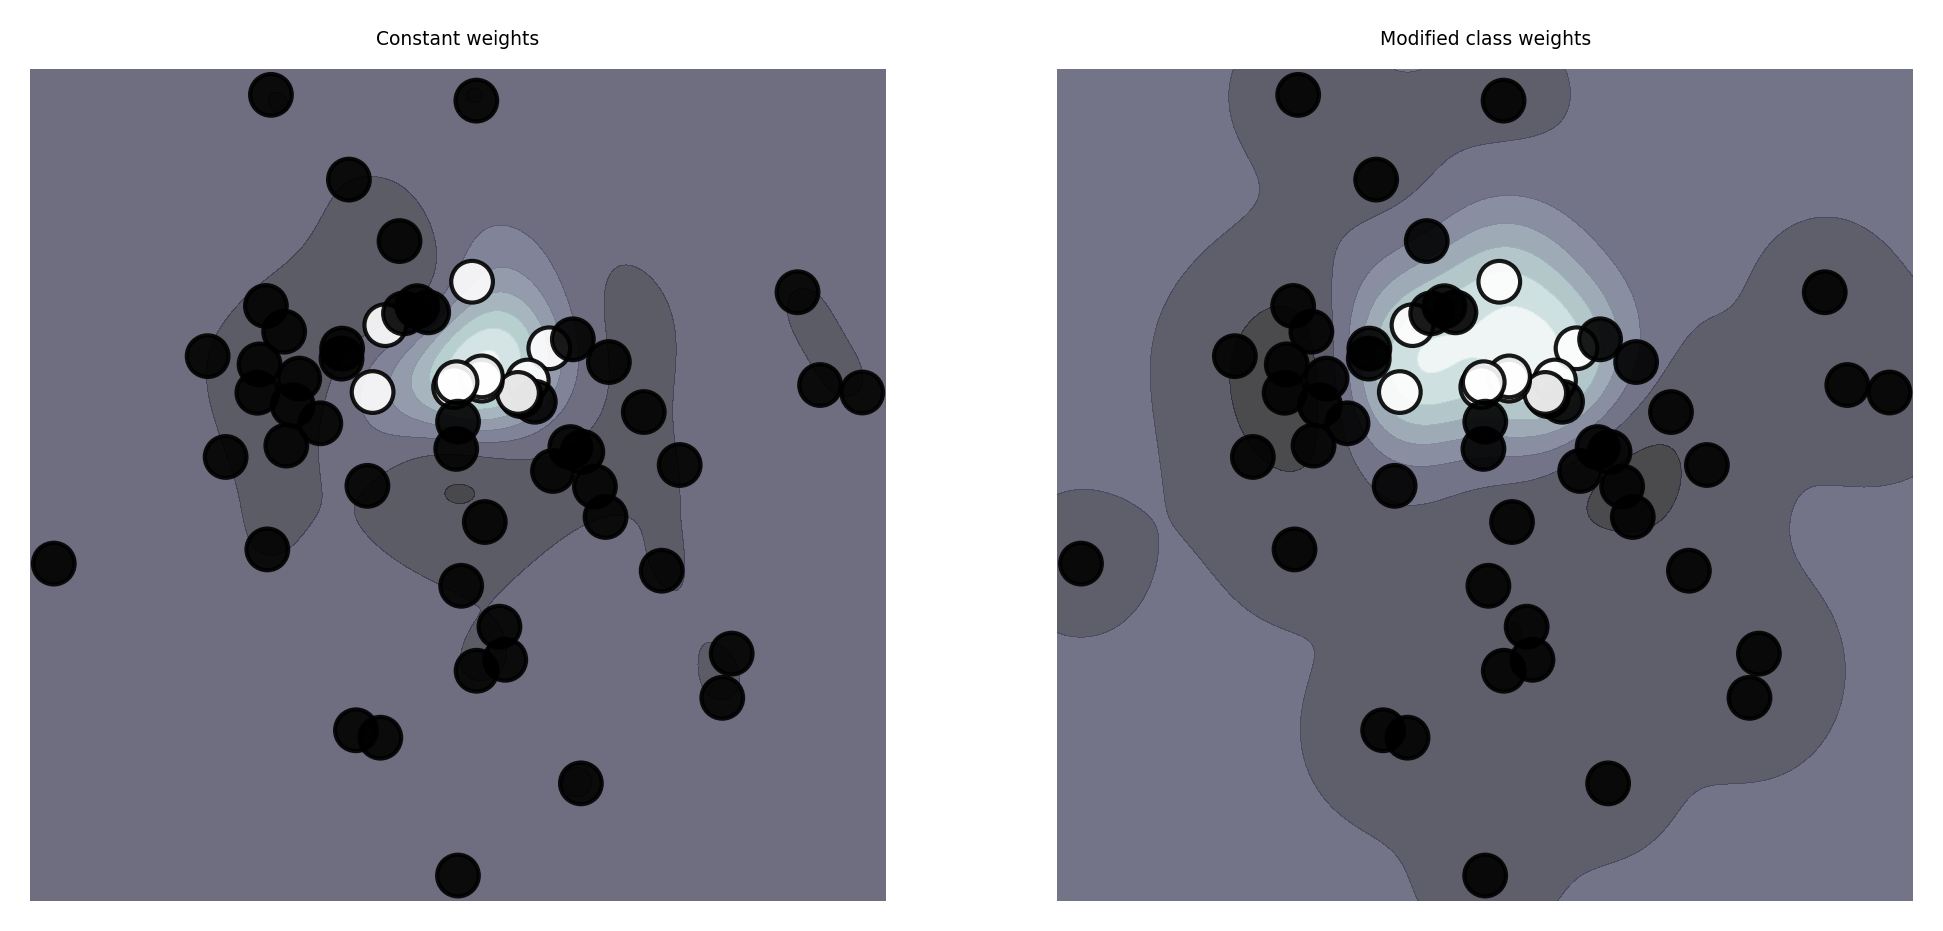

In [54]:
from sklearn.datasets import make_blobs
def plot_decision_function(classifier, X, y, sample_weight, axis, title):
    # plot the decision function
    xx, yy = np.meshgrid(np.linspace(np.min(X[:,0])-1, np.max(X[:,0])+1, 500), np.linspace(np.min(X[:,1])-1, np.max(X[:,1])+1, 500))
    Z = classifier.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # plot the line, the points, and the nearest vectors to the plane
    axis.contourf(xx, yy, Z, alpha=0.75, cmap=plt.cm.bone)
    axis.scatter(X[:, 0], X[:, 1], c=y, s=100 * sample_weight, alpha=0.9,
                 cmap=plt.cm.bone, edgecolors='black')

    axis.axis('off')
    axis.set_title(title)
    
def plot_class_weights():
    X, y = make_blobs(n_samples=(50, 10), centers=None, cluster_std=[7.0, 2], random_state=4)
    
    # fit the models
    clf_weights = SVC(gamma=0.1, C=0.1, class_weight={1: 10}).fit(X, y)
    clf_no_weights = SVC(gamma=0.1, C=0.1).fit(X, y)

    fig, axes = plt.subplots(1, 2, figsize=(9*fig_scale, 4*fig_scale))
    plot_decision_function(clf_no_weights, X, y, 1, axes[0],
                           "Constant weights")
    plot_decision_function(clf_weights, X, y, 1, axes[1],
                           "Modified class weights")
plot_class_weights()

### Instance weighting
* If some _training instances_ are important to get right, we can give them more weight
    * E.g. when some examples are from groups underrepresented in the data
* These are passed during training (fit), and included in the loss function
    * E.g. Logistic regression: add a instance weight $w_n$ in the log loss function
$$\mathcal{L_{log}}(\mathbf{w}) = - \sum_{c=1}^{C} \sum_{n=1}^{N} \color{red}{w_n} p_{n,c} log(q_{n,c}) $$

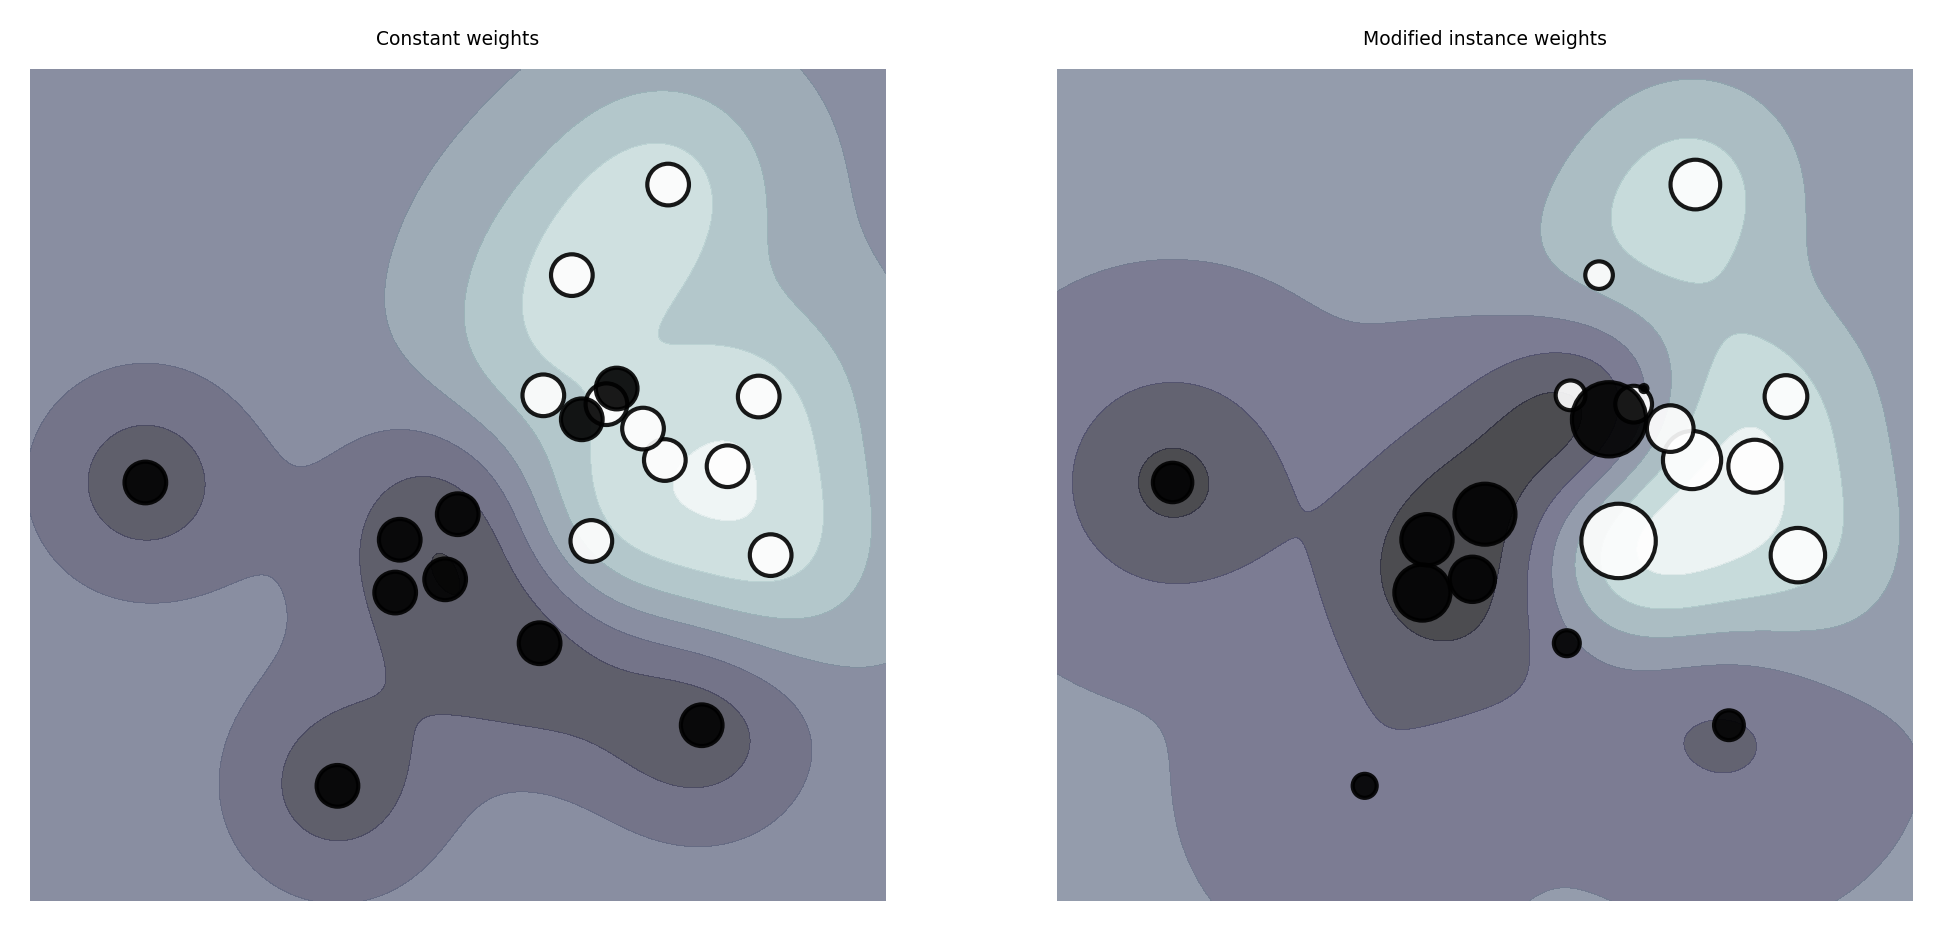

In [55]:
# Example from https://scikit-learn.org/stable/auto_examples/svm/plot_weighted_samples.html
def plot_instance_weights():
    np.random.seed(0)
    X = np.r_[np.random.randn(10, 2) + [1, 1], np.random.randn(10, 2)]
    y = [1] * 10 + [-1] * 10
    sample_weight_last_ten = abs(np.random.randn(len(X)))
    sample_weight_constant = np.ones(len(X))
    # and bigger weights to some outliers
    sample_weight_last_ten[15:] *= 5
    sample_weight_last_ten[9] *= 15

    # for reference, first fit without sample weights

    # fit the model
    clf_weights = SVC(gamma=1)
    clf_weights.fit(X, y, sample_weight=sample_weight_last_ten)

    clf_no_weights = SVC(gamma=1)
    clf_no_weights.fit(X, y)

    fig, axes = plt.subplots(1, 2, figsize=(9*fig_scale, 4*fig_scale))
    plot_decision_function(clf_no_weights, X, y, sample_weight_constant, axes[0],
                           "Constant weights")
    plot_decision_function(clf_weights, X, y, sample_weight_last_ten, axes[1],
                           "Modified instance weights")
plot_instance_weights()   

### Cost-sensitive algorithms
* Cost-sensitive algorithms
    - If misclassification cost of some classes is higher, we can give them higher weights
    - Some support _cost matrix_ $C$: costs $c_{i,j}$ for every possible type of error
* Cost-sensitive ensembles: convert cost-insensitive classifiers into cost-sensitive ones
    - MetaCost: Build a model (ensemble) to learn the class probabilities $P(j|x)$
        - Relabel training data to minimize expected cost: $\underset{i}{\operatorname{argmin}} \sum_j P_j(x) c_{i,j}$
        - Accuracy may decrease but cost decreases as well.
    - AdaCost: Boosting with reweighting instances to reduce costs

### Tuning the decision threshold
- If every FP or FN has a certain cost, we can compute the total cost for a given model:
$$\text{total cost} = \text{FPR} * cost_{FP} * ratio_{pos} + (1-\text{TPR}) *  cost_{FN} * (1-ratio_{pos})$$
- This yields different _isometrics_ (lines of equal cost) in ROC space
- Optimal threshold is the point on the ROC curve where cost is minimal (line search)

In [81]:
import ipywidgets as widgets
from ipywidgets import interact, interact_manual

# Cost function
def cost(fpr, tpr, cost_FN, cost_FP, ratio_P):
    return fpr * cost_FP * ratio_P + (1 - tpr) * (1-ratio_P) * cost_FN;

@interact
def plot_isometrics(cost_FN=(1,10.0,1.0), cost_FP=(1,10.0,1.0)):
    from sklearn.metrics import roc_curve
    fpr, tpr, thresholds = roc_curve(yb_test, svc_roc.decision_function(Xb_test))

    # get minimum
    ratio_P = len(yb_test[yb_test==1]) / len(yb_test)
    costs = [cost(fpr[x],tpr[x],cost_FN,cost_FP, ratio_P) for x in range(len(thresholds))]
    min_cost = np.min(costs)
    min_thres = np.argmin(costs)

    # plot contours
    x = np.arange(0.0, 1.1, 0.1)
    y = np.arange(0.0, 1.1, 0.1)
    XX, YY = np.meshgrid(x, y)
    costs = [cost(f, t, cost_FN, cost_FP, ratio_P) for f, t in zip(XX,YY)]

    if interactive:
        fig, axes = plt.subplots(1, 1, figsize=(9*fig_scale, 3*fig_scale))
    else:
        fig, axes = plt.subplots(1, 1, figsize=(6*fig_scale, 1.8*fig_scale))
    plt.plot(fpr, tpr, label="ROC Curve", lw=2)
    levels = np.linspace(np.array(costs).min(), np.array(costs).max(), 10)
    levels = np.sort(np.append(levels, min_cost))
    CS = plt.contour(XX, YY, costs, levels)
    plt.clabel(CS, inline=1, fontsize=10)

    plt.xlabel("FPR")
    plt.ylabel("TPR (recall)")
    # find threshold closest to zero:
    plt.plot(fpr[min_thres], tpr[min_thres], 'o', markersize=4,
             label="optimal", fillstyle="none", c='k', mew=2)
    plt.legend(loc=4, prop={"size":10});
    plt.title("Isometrics, cost_FN: {}, cost_FP: {}".format(cost_FN, cost_FP), fontsize=10*fig_scale)
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=5.0, description='cost_FN', max=10.0, min=1.0, step=1.0), FloatSlider(…

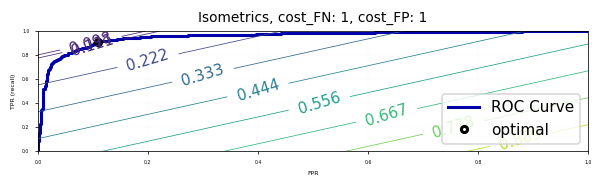

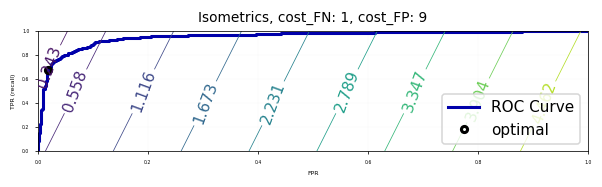

In [82]:
interactive = False
if not interactive:
    plot_isometrics(1,1)
    plot_isometrics(1,9)
interactive = True

## Regression metrics

Most commonly used are
- mean squared error: $\frac{\sum_{i}(y_{pred_i}-y_{actual_i})^2}{n}$
    - root mean squared error (RMSE) often used as well
- mean absolute error: $\frac{\sum_{i}|y_{pred_i}-y_{actual_i}|}{n}$
    - Less sensitive to outliers and large errors

### R squared
- $R^2 = 1 - \frac{\color{blue}{\sum_{i}(y_{pred_i}-y_{actual_i})^2}}{\color{red}{\sum_{i}(y_{mean}-y_{actual_i})^2}}$
    - Ratio of variation explained by the model / total variation
    - Between 0 and 1, but _negative_ if the model is worse than just predicting the mean
    - Easier to interpret (higher is better).
    
<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/07_r2.png" alt="ml" style="width: 600px;"/>

### Visualizing regression errors
* Prediction plot (left): predicted vs actual target values
* Residual plot (right): residuals vs actual target values
    * Over- and underpredictions can be given different costs 

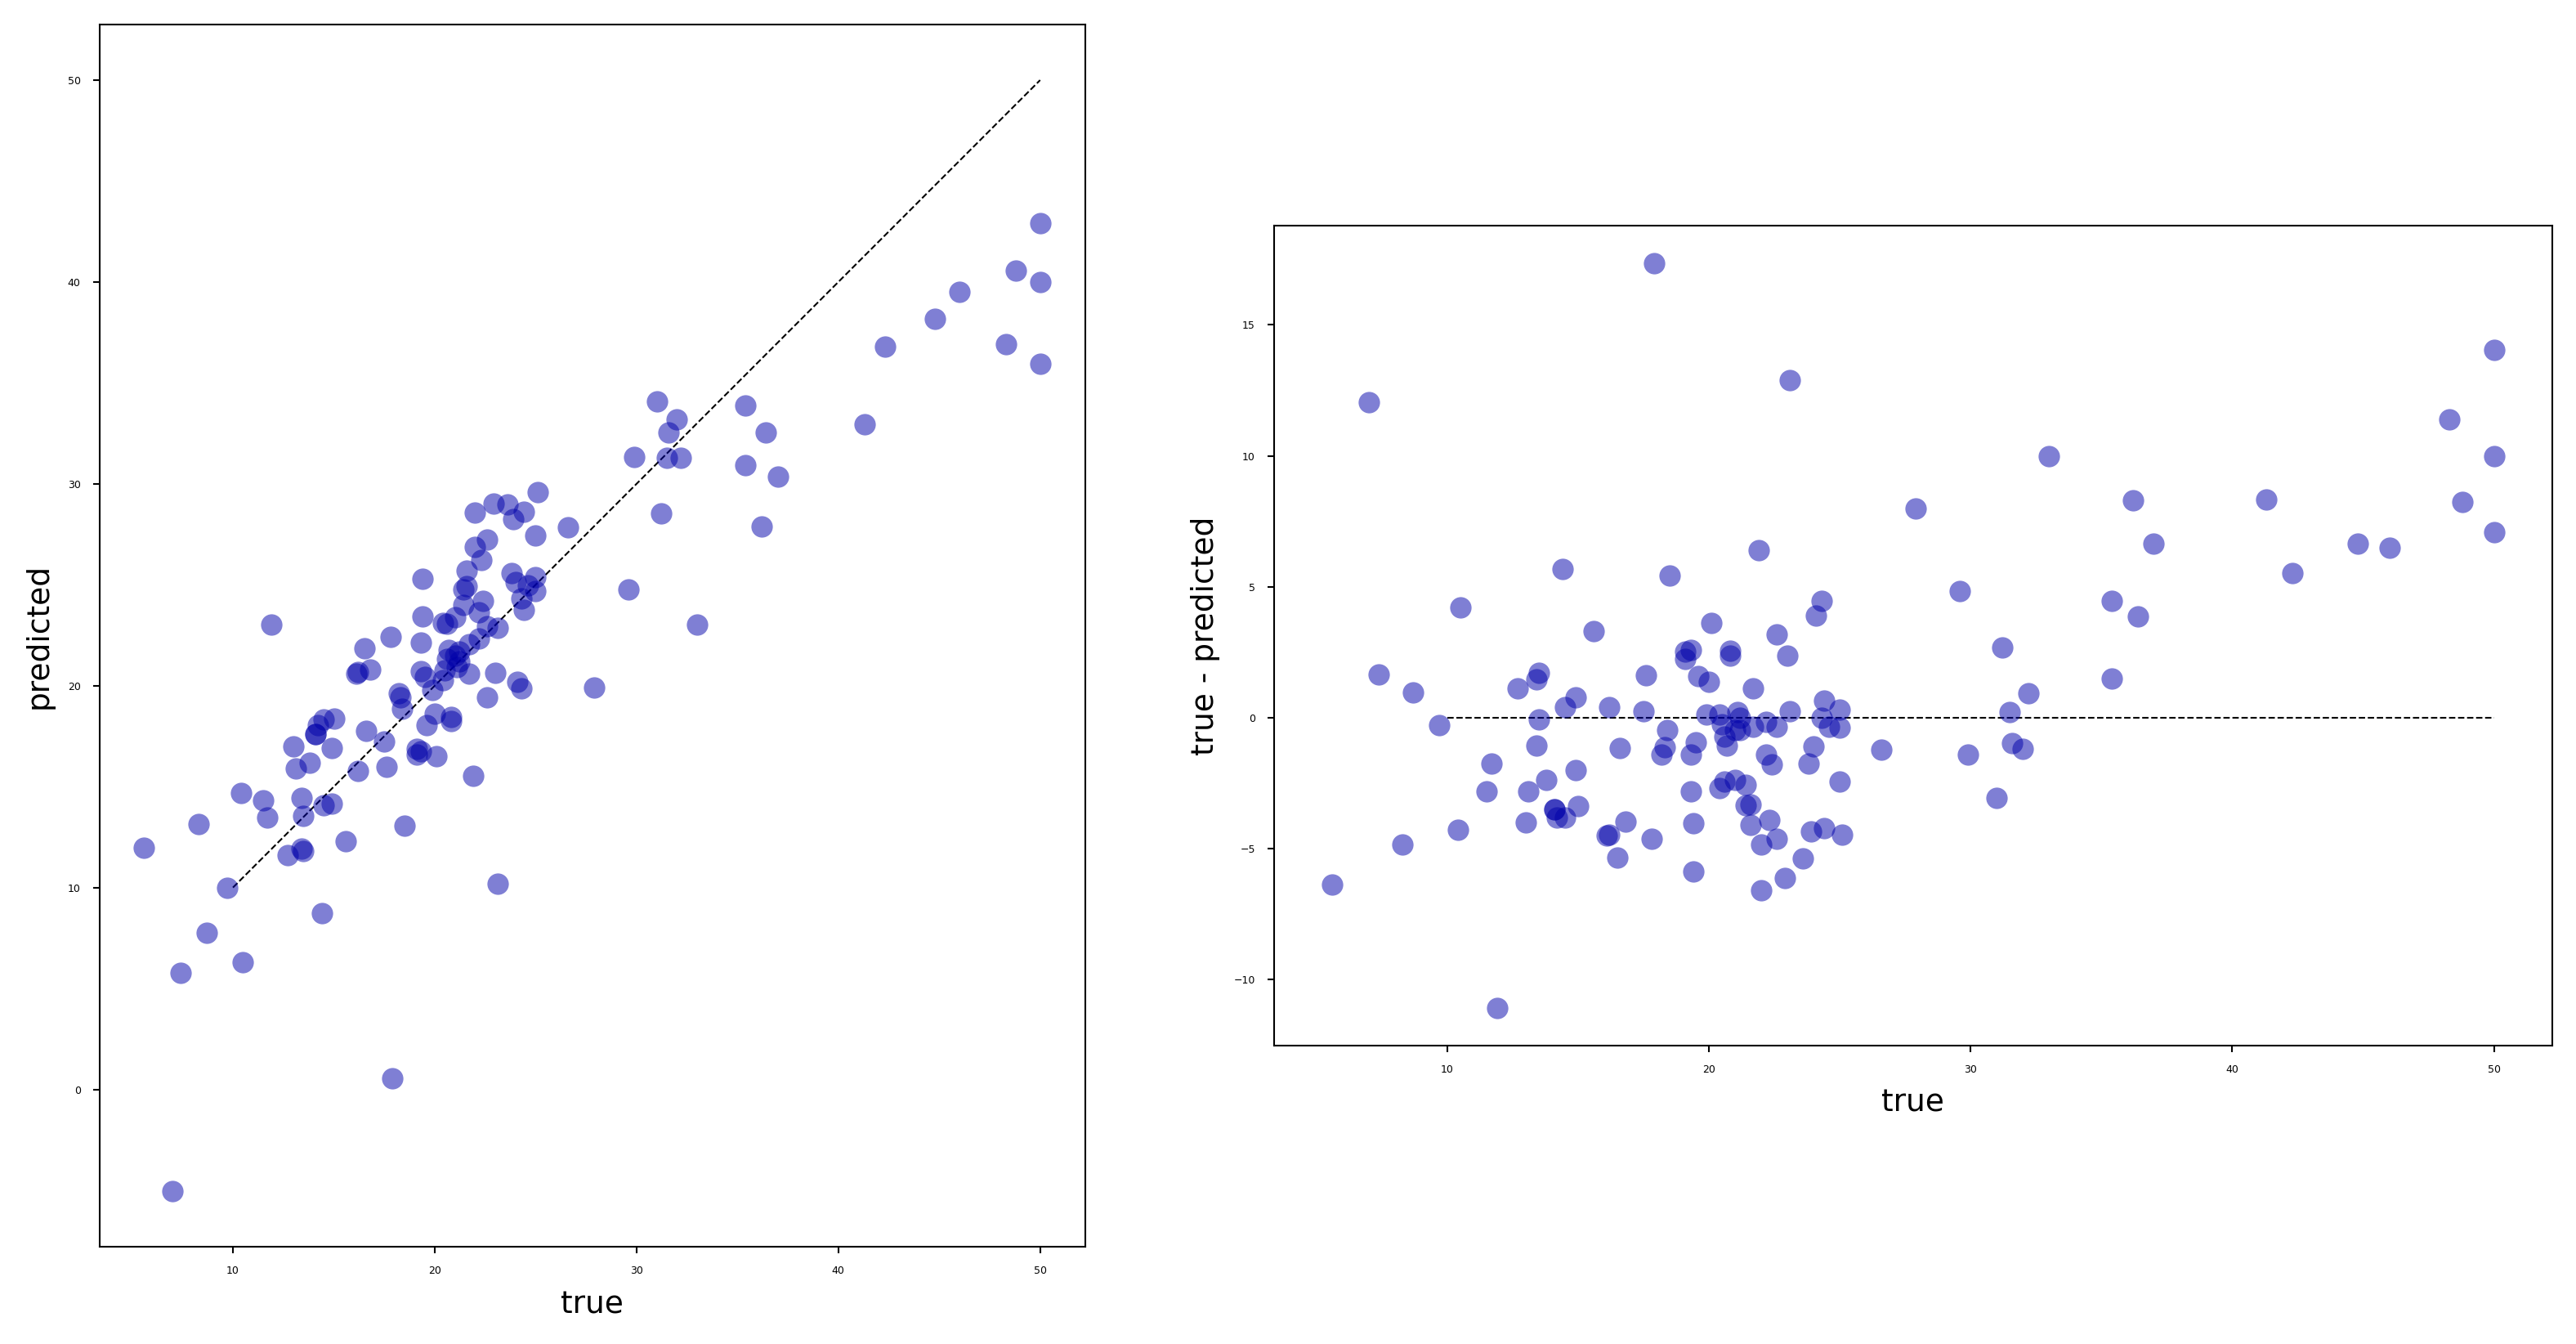

In [58]:
from sklearn.linear_model import Ridge
from sklearn.datasets import fetch_openml
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
boston = fetch_openml(name="boston", as_frame=True)

X_train, X_test, y_train, y_test = train_test_split(boston.data, boston.target)
ridge_pipe = make_pipeline(StandardScaler(),Ridge())

pred = ridge_pipe.fit(X_train, y_train).predict(X_test)

plt.subplot(1, 2, 1)
plt.gca().set_aspect("equal")
plt.plot([10, 50], [10, 50], '--', c='k')
plt.plot(y_test, pred, 'o', alpha=.5, markersize=7*fig_scale)
plt.ylabel("predicted", fontsize=10*fig_scale)
plt.xlabel("true", fontsize=10*fig_scale);

plt.subplot(1, 2, 2)
plt.gca().set_aspect("equal")
plt.plot([10, 50], [0,0], '--', c='k')
plt.plot(y_test, y_test - pred, 'o', alpha=.5, markersize=7*fig_scale)
plt.xlabel("true", fontsize=10*fig_scale)
plt.ylabel("true - predicted", fontsize=10*fig_scale)
plt.tight_layout();

## Bias-Variance decomposition

- Evaluate the same algorithm multiple times on different random samples of the data
- Two types of errors can be observed:
    - Bias error: systematic error, independent of the training sample
        - These points are predicted (equally) wrong every time
    - Variance error: error due to variability of the model w.r.t. the training sample
        - These points are sometimes predicted accurately, sometimes inaccurately

<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/03_bias_variance.png" alt="ml" style="width: 40%"/>

### Computing bias and variance error
- Take 100 or more bootstraps (or shuffle-splits)
- Regression: for each data point x:
    - $bias(x)^2 = (x_{true} - mean(x_{predicted}))^2$
    - $variance(x) = var(x_{predicted})$
- Classification: for each data point x:
    - $bias(x)$ = misclassification ratio
    - $variance(x) = (1 - (P(class_1)^2 + P(class_2)^2))/2$
        - $P(class_i)$ is ratio of class $i$ predictions
- Total bias: $\sum_{x} bias(x)^2 * w_x$
    $w_x$: the percentage of times $x$ occurs in the test sets
- Total variance: $\sum_{x} variance(x) * w_x$

In [80]:
from sklearn.model_selection import ShuffleSplit, train_test_split, GridSearchCV

# Bias-Variance Computation 
def compute_bias_variance(clf, X, y):
    # Bootstraps
    n_repeat = 40 # 40 is on the low side to get a good estimate. 100 is better.
    shuffle_split = ShuffleSplit(test_size=0.33, n_splits=n_repeat, random_state=0)

    # Store sample predictions
    y_all_pred = [[] for _ in range(len(y))]

    # Train classifier on each bootstrap and score predictions
    for i, (train_index, test_index) in enumerate(shuffle_split.split(X)):
        # Train and predict
        clf.fit(X[train_index], y[train_index])
        y_pred = clf.predict(X[test_index])

        # Store predictions
        for j,index in enumerate(test_index):
            y_all_pred[index].append(y_pred[j])

    # Compute bias, variance, error
    bias_sq = sum([ (1 - x.count(y[i])/len(x))**2 * len(x)/n_repeat 
                for i,x in enumerate(y_all_pred)])
    var = sum([((1 - ((x.count(0)/len(x))**2 + (x.count(1)/len(x))**2))/2) * len(x)/n_repeat
               for i,x in enumerate(y_all_pred)])
    error = sum([ (1 - x.count(y[i])/len(x)) * len(x)/n_repeat 
            for i,x in enumerate(y_all_pred)])

    return np.sqrt(bias_sq), var, error

### Bias and variance, underfitting and overfitting
- High variance means that you are likely overfitting
    - Use more regularization or use a simpler model
- High bias means that you are likely underfitting
    - Do less regularization or use a more flexible/complex model
- Ensembling techniques (see later) reduce bias or variance directly
    - Bagging (e.g. RandomForests) reduces variance, Boosting reduces bias

<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/03_Bias-Variance-Tradeoff.png" alt="ml" style="width: 40%"/>

### Understanding under- and overfitting
- Regularization reduces variance error (increases stability of predictions)
    - But too much increases bias error (inability to learn 'harder' points)
- High regularization (left side): Underfitting, high bias error, low variance error
    - High training error and high test error
- Low regularization (right side): Overfitting, low bias error, high variance error
    - Low training error and higher test error

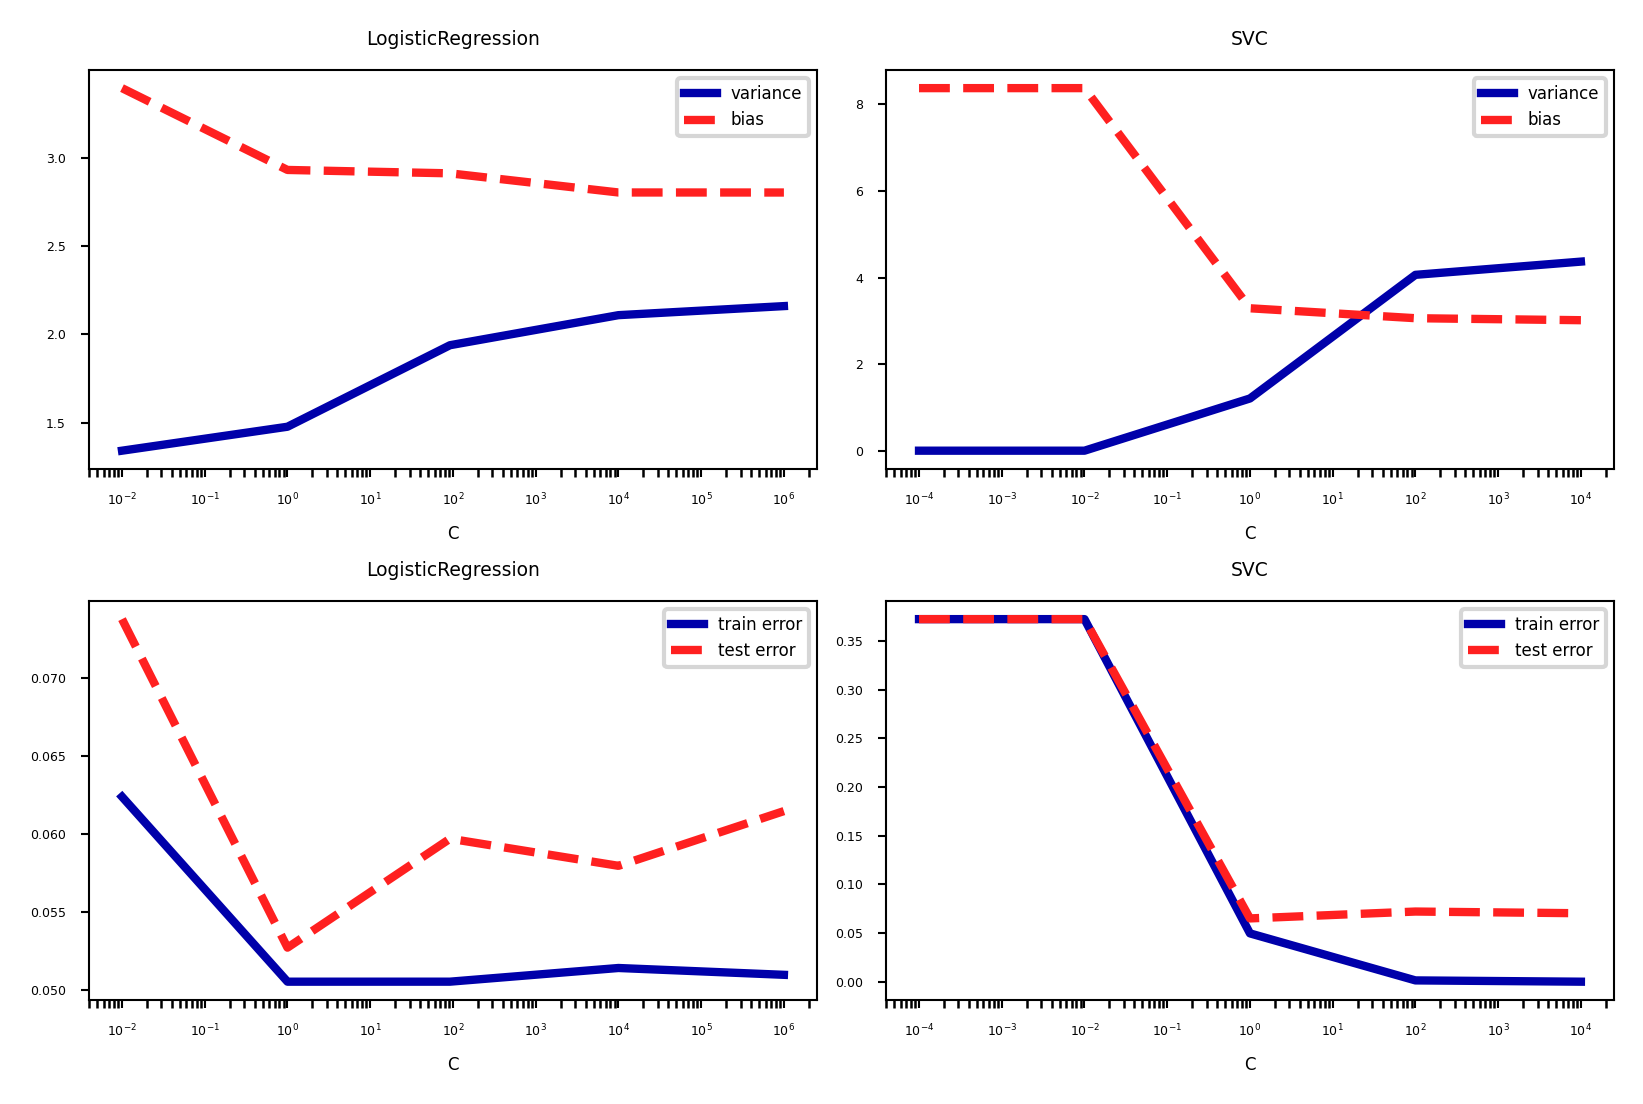

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
cancer = load_breast_cancer()

def plot_bias_variance(clf, param, X, y, ax):
    bias_scores = []
    var_scores = []
    err_scores = []
    name, vals = next(iter(param.items()))

    for i in vals:
        b,v,e = compute_bias_variance(clf.set_params(**{name:i}),X,y)
        bias_scores.append(b)
        var_scores.append(v)
        err_scores.append(e)

    ax.set_title(clf.__class__.__name__)
    ax.plot(vals, var_scores,label ="variance", lw=2 )
    ax.plot(vals, bias_scores,label ="bias", lw=2 )
    ax.set_xscale('log')
    ax.set_xlabel(name)
    ax.legend(loc="best")
    
def plot_train_test(clf, param, X, y, ax):
    gs = GridSearchCV(clf, param, cv=5, return_train_score=True).fit(X,y)
    name, vals = next(iter(param.items()))

    ax.set_title(clf.__class__.__name__)
    ax.plot(vals, (1-gs.cv_results_['mean_train_score']),label ="train error", lw=2 )
    ax.plot(vals, (1-gs.cv_results_['mean_test_score']),label ="test error", lw=2 )
    ax.set_xscale('log')
    ax.set_xlabel(name)
    ax.legend(loc="best")
    
fig, axes = plt.subplots(2, 2, figsize=(6*fig_scale, 4*fig_scale))
X, y = cancer.data, cancer.target
svm = SVC(gamma=2e-4, random_state=0)
param = {'C': [1e-4, 1e-2, 1, 1e2, 1e4]}# C  = inverse of regularization strength.

plot_bias_variance(svm, param, X, y, axes[0,1])
plot_train_test(svm, param, X, y, axes[1,1]) 

lr = LogisticRegression(random_state=0)
param = {'C': [1e-2, 1, 92, 1e4, 1e6]}
plot_bias_variance(lr, param, X, y, axes[0,0])
plot_train_test(lr, param, X, y, axes[1,0])
plt.tight_layout()

Summary Flowchart (by Andrew Ng)

<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/03_Bias-Variance-Flowchart.png" alt="ml" style="width: 50%"/>

## Hyperparameter tuning
- There exists a huge range of techniques to tune hyperparameters. The simplest:
    - Grid search: Choose a range of values for every hyperparameter, try every combination
        - Doesn't scale to many hyperparameters (combinatorial explosion)
    - Random search: Choose random values for all hyperparameters, iterate $n$ times
        - Better, especially when some hyperparameters are less important
- Many more advanced techniques exist, see lecture on Automated Machine Learning

<img src="https://raw.githubusercontent.com/fum-cs/machine-learning/main/notebooks/img/gridvsrandom.png" alt="ml" style="width: 50%"/>

* First, split the data in training and test sets (outer split)
* Split up the training data again (inner cross-validation)
    * Generate hyperparameter configurations (e.g. random/grid search)
    * Evaluate all configurations on all inner splits, select the best one (on average)
* Retrain best configurations on full training set, evaluate on held-out test data

In [62]:
import numpy as np, pandas as pd, time
from scipy.stats import loguniform
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Real data: breast cancer (569 patients, 30 features).
Xh, yh = load_breast_cancer(return_X_y=True)
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, yh, stratify=yh, random_state=0)

pipe = make_pipeline(StandardScaler(), SVC())
n_trials = 25                                       

# Grid search: 5 values of C x 5 values of gamma = 25 combinations
grid = GridSearchCV(pipe,
    param_grid={"svc__C":     np.logspace(-2, 2, 5),
                "svc__gamma": np.logspace(-4, 0, 5)},
    cv=5, n_jobs=-1)

# Random search: 25 random (C, gamma) pairs drawn from log-uniform ranges
rand = RandomizedSearchCV(pipe,
    param_distributions={"svc__C":     loguniform(1e-2, 1e2),
                         "svc__gamma": loguniform(1e-4, 1e0)},
    n_iter=n_trials, cv=5, random_state=0, n_jobs=-1)

for name, search in [("Grid search", grid), ("Random search", rand)]:
    t0 = time.time(); search.fit(Xh_tr, yh_tr)
    print(f"{name:14s} {len(search.cv_results_['params'])} combos | best CV acc = {search.best_score_:.3f} "
          f"| test acc = {search.score(Xh_te, yh_te):.3f} | {time.time()-t0:.1f}s")
    print(f"{'':14s} best params: { {k.split('__')[1]: round(float(v), 5) for k, v in search.best_params_.items()} }")

Grid search    25 combos | best CV acc = 0.988 | test acc = 0.958 | 0.2s
               best params: {'C': 100.0, 'gamma': 0.001}
Random search  25 combos | best CV acc = 0.986 | test acc = 0.958 | 0.2s
               best params: {'C': 2.80791, 'gamma': 0.02936}


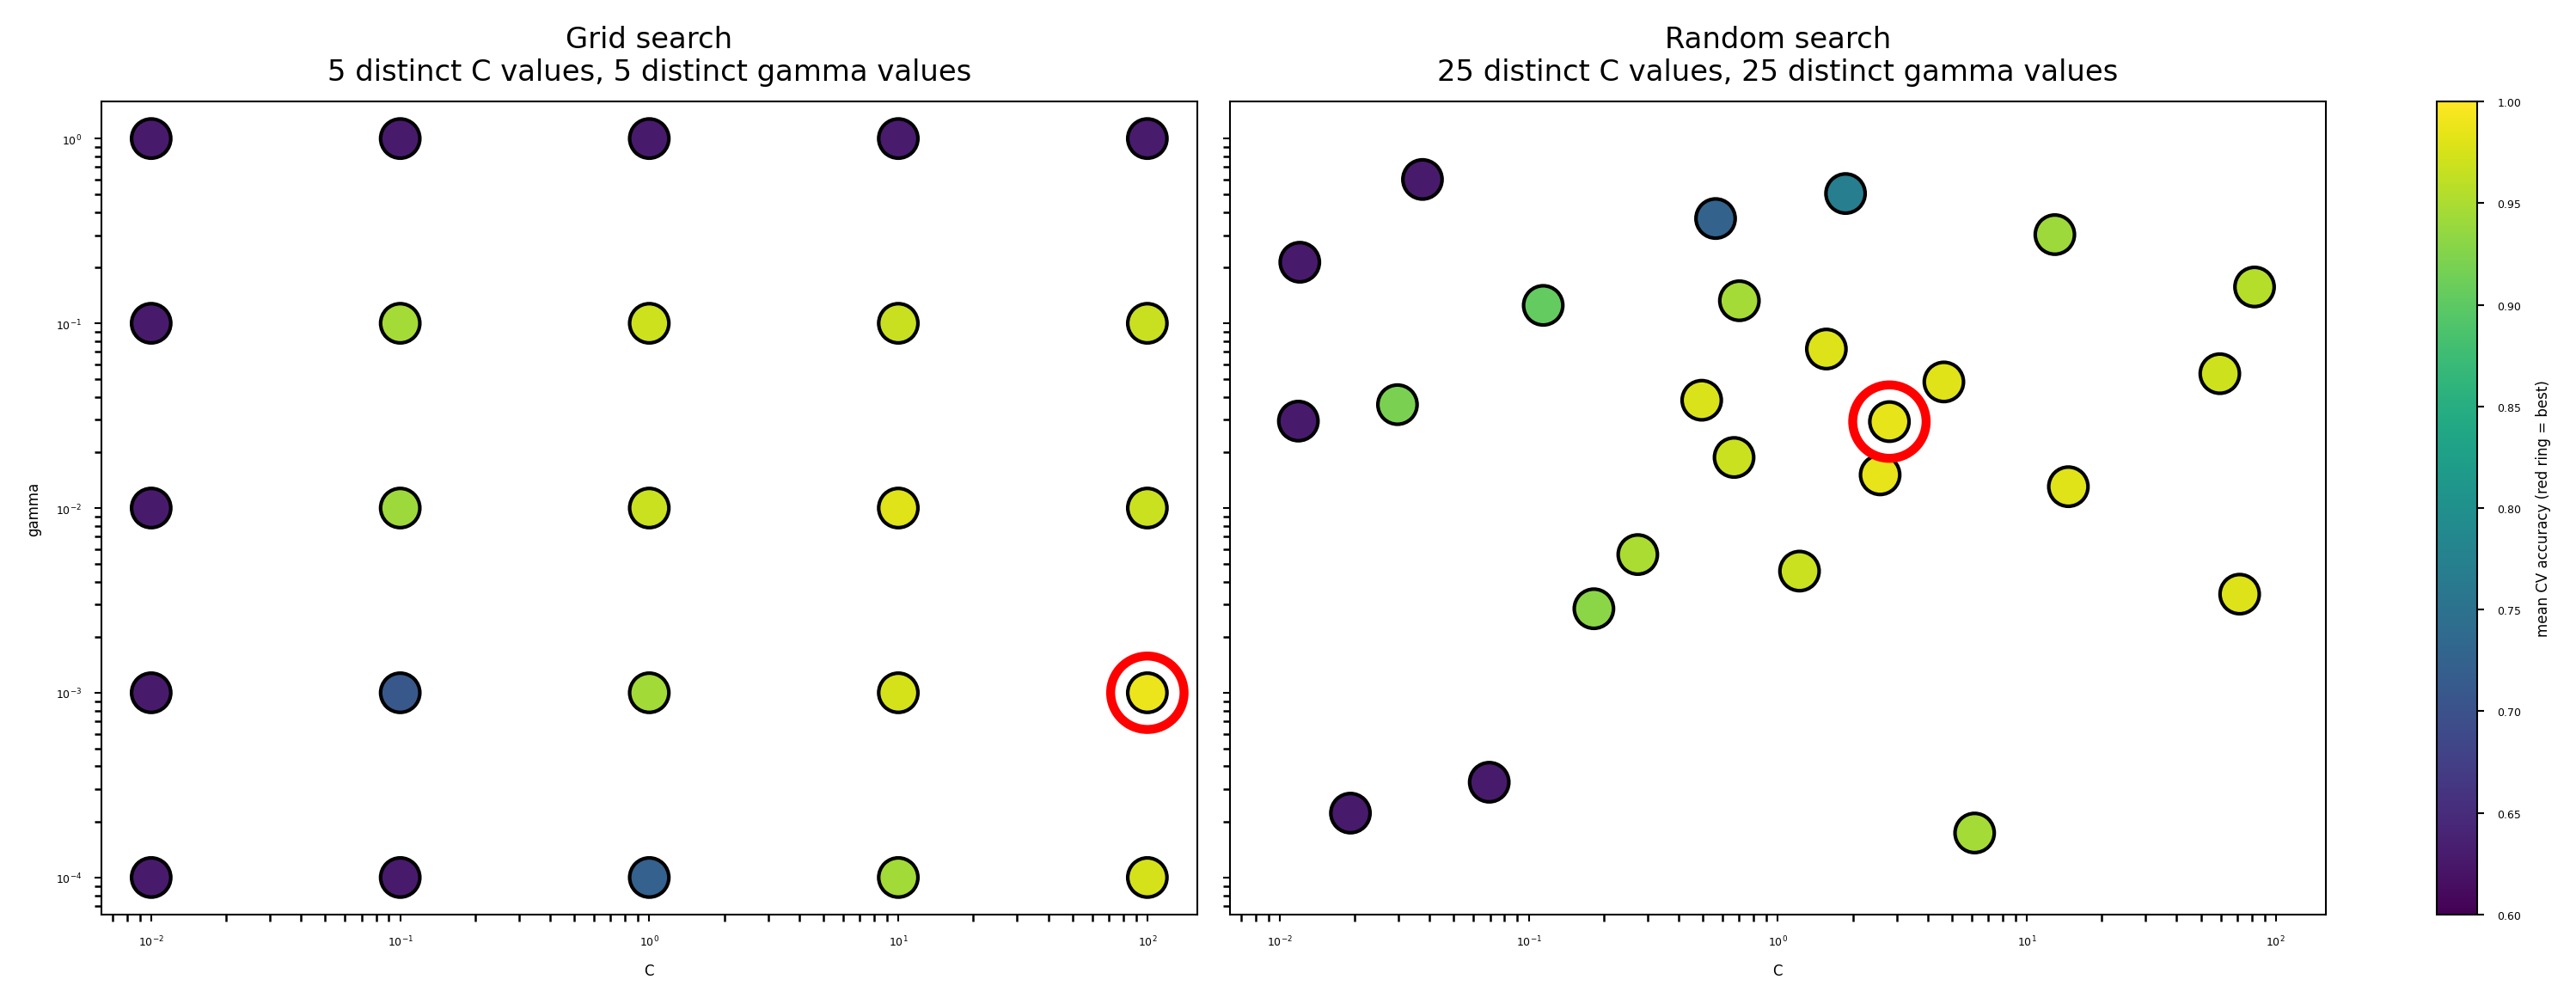

In [63]:
import matplotlib.pyplot as plt
fs = globals().get("fig_scale", 0.9)
fig, axes = plt.subplots(1, 2, figsize=(11*fs, 4.2*fs), sharex=True, sharey=True, constrained_layout=True)
for ax, (name, search) in zip(axes, [("Grid search", grid), ("Random search", rand)]):
    res = pd.DataFrame(search.cv_results_)
    C, g = res["param_svc__C"].astype(float), res["param_svc__gamma"].astype(float)
    sc = ax.scatter(C, g, c=res["mean_test_score"], cmap="viridis", s=120, edgecolor="k", vmin=0.6, vmax=1)
    b = search.best_params_
    ax.scatter(b["svc__C"], b["svc__gamma"], s=420, facecolors="none", edgecolors="red", lw=2.5)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("C"); ax.set_title(f"{name}\n{C.nunique()} distinct C values, {g.nunique()} distinct gamma values", fontsize=9*fs)
axes[0].set_ylabel("gamma")
fig.colorbar(sc, ax=axes, label="mean CV accuracy (red ring = best)")
plt.show()

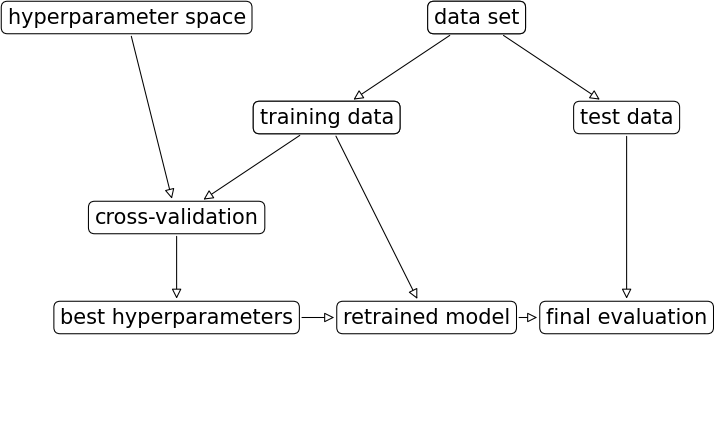

In [64]:
if interactive:
    plt.rcParams['figure.dpi'] = 75
mglearn.plots.plot_grid_search_overview()
plt.rcParams.update(print_config)

In [65]:
from scipy.stats.distributions import expon

### Nested cross-validation
- Simplest approach: single outer split and single inner split (shown below)
- Risk of over-tuning hyperparameters on specific train-test split
    - Only recommended for very large datasets
- Nested cross-validation:
    - Outer loop: split full dataset in $k_1$ training and test splits
    - Inner loop: split training data into $k_2$ train and validation sets
- This yields $k_1$ scores for $k_1$ possibly different hyperparameter settings
    - Average score is the expected performance of the tuned model
- To use the model in practice, retune on the **entire** dataset

``` python
hps = {'C': expon(scale=100), 'gamma': expon(scale=.1)}
scores = cross_val_score(RandomizedSearchCV(SVC(), hps, cv=3), X, y, cv=5)
```

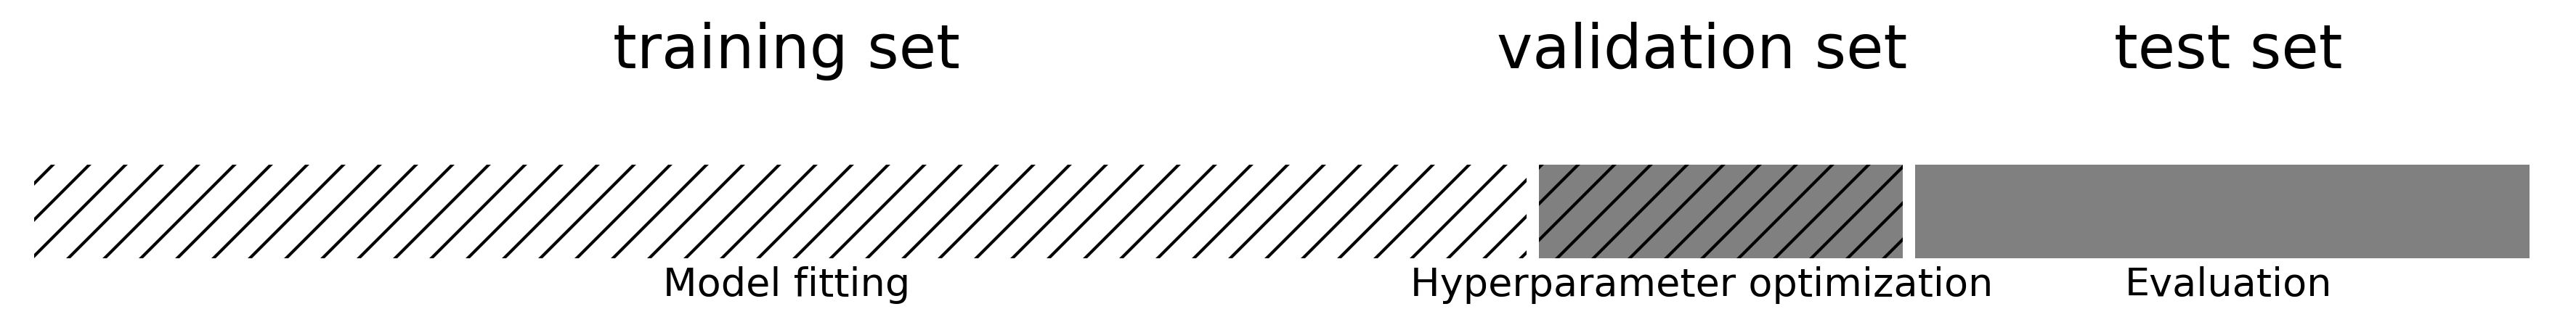

In [66]:
mglearn.plots.plot_threefold_split()

## Summary
* Split the data into training and test sets according to the application
    * Holdout only for large datasets, cross-validation for smaller ones
    * For classification, always use stratification
    * Grouped or ordered data requires special splitting
* Choose a metric that fits your application
    * E.g. precision to avoid false positives, recall to avoid false negatives
* Calibrate the decision threshold to fit your application
    * ROC curves or Precision-Recall curves can help to find a good tradeoff
* If possible, include the actual or relative costs of misclassifications
    * Class weighting, instance weighting, ROC isometrics can help
    * Be careful with imbalanced or unrepresentative datasets
* When using the predicted probabilities in applications, calibrate the models
* Always tune the most important hyperparameters
    * Manual tuning: Use insight and train-test scores for guidance
    * Hyperparameter optimization: be careful not to over-tune